In [33]:
library(targets)
library(dplyr)
library(sommer)
library(asreml)
library(AGHmatrix)
library(tidyr)
library(ggplot2)
library(glue)
library(stringr)
library(patchwork)
library(purrr)
library(statgenGxE)
library(factoextra)

Welcome to factoextra!
Want to learn more? See two factoextra-related books at https://www.datanovia.com/library/principal-component-methods


In [ ]:
name

focus on AL data
Run FA with sommer and asreml for yield 
2b. show how chill is absorbed by fa
Run the plots that shows late materials = higher yield (run for all too, not just the frost years)
run fa1 vs fa2 lrt
Show correlations and hc of fa2
Show agreement/disagreement of the two packages
run FA for bloom traits
Extract BLUPS and PEV, show stable genotypes

In [2]:
tar_load(al_yield_long_clean)

In [3]:

prep_dta = function(fa_dta){
  fa_dta = fa_dta %>% mutate(Genotype = factor(Genotype), Env = factor(Env), Block = factor(Block))

  env_stats = fa_dta %>% group_by(Env) %>%
    summarize(mean_env = mean(y, na.rm = TRUE), sd_env = sd(y, na.rm = TRUE))

  fa_dta_scaled = fa_dta %>% left_join(env_stats, by = 'Env') %>%
    mutate(y_scaled = (y - mean_env) / sd_env)
}

fit_fa_asreml <- function(fa_dta, Ainv, maxiter = 300) {
  # dta <- fa_dta %>% mutate(Genotype = factor(Genotype), Env = factor(Env), Block = factor(Block))
  dta = prep_dta(fa_dta)

  fit <- asreml(
    fixed    = y_scaled ~ Env,
    random   = ~fa(Env, k = 1):vm(Genotype, Ainv) + Env:Block,
    residual = ~dsum(~units | Env),
    data     = dta,
    maxit  = maxiter,
    ai.loadings = 5,   
    ai.penalty  = 15     
  )
  fit$call$maxit <- maxiter
  update.asreml(fit)
}

fit_fa2_asreml <- function(fa_dta, Ainv, maxiter = 300) {
  dta = prep_dta(fa_dta)

  fit <- asreml(
    fixed    = y_scaled ~ Env,
    random   = ~fa(Env, k = 2):vm(Genotype, Ainv) + Env:Block,
    residual = ~dsum(~units | Env),
    data     = dta,
    maxit  = maxiter,
    ai.loadings = 5,   
    ai.penalty  = 15     
  )
  fit$call$maxit <- maxiter
  update.asreml(fit)
  
}


fit_fa3_asreml <- function(fa_dta, Ainv, maxiter = 300) {
  dta = prep_dta(fa_dta)

  fit <- asreml(
    fixed    = y_scaled ~ Env,
    random   = ~fa(Env, k = 3):vm(Genotype, Ainv) + Env:Block,
    residual = ~dsum(~units | Env),
    data     = dta,
    maxit  = maxiter,
    ai.loadings = 5,   
    ai.penalty  = 15     
  )
  fit$call$maxit <- maxiter
  update.asreml(fit)
}

fit_cs_asreml = function(cs_dta, Ainv){

  dta = cs_dta %>% mutate(Genotype = factor(Genotype), Env = factor(Env), Block = factor(Block))

  fit = asreml(
    fixed = y ~ Env,
    # random = ~corh(Env):vm(Genotype, Ainv) + Env:Block,
    random = ~ vm(Genotype, Ainv) + idv(Env):vm(Genotype, Ainv) + Env:Block,
    residual = ~idv(units),
    data = dta
  )
}




extract_rg_matrix_asreml <- function(varcomp, env_levels, n_factors) {
  var_rows <- varcomp[grep("!var$", rownames(varcomp)), , drop = FALSE]
  if (nrow(var_rows) == 0) {
    stop(
      "extract_genetic_correlation_matrix_asreml(): no rows matching '!var' ",
      "found in the varcomp table -- asreml's varcomp naming may not match ",
      "what this function assumes (untested). Inspect rownames(varcomp) ",
      "directly before trusting this."
    )
  }
  R <- var_rows[, 1]

  loadings <- lapply(seq_len(n_factors), function(k) {
    rows <- varcomp[grep(paste0("!fa", k, "$"), rownames(varcomp)), , drop = FALSE]
    if (nrow(rows) == 0) {
      stop(
        "extract_genetic_correlation_matrix_asreml(): no rows matching '!fa",
        k, "' found -- asreml's varcomp naming may not match what this ",
        "function assumes (untested). Inspect rownames(varcomp) directly ",
        "before trusting this."
      )
    }
    rows[, 1]
  })
  L <- do.call(cbind, loadings)
  # rownames(L) <- env_levels 

  cov <- L %*% t(L) + diag(R)
  dimnames(cov) <- list(env_levels, env_levels)

  list(cov = cov, corr = stats::cov2cor(cov), loadings = L)
}

In [61]:

# 1. Ainv prep (42 x 42; dimnames must match the Genotype levels)
prep_ainv_sommer <- function(Ainv) {
  # stopifnot(!is.null(rownames(Ainv)), all(genotypes %in% rownames(Ainv)))
  Ainv <- as(as(as(Ainv, "dMatrix"), "generalMatrix"), "CsparseMatrix")
  attr(Ainv, "inverse") <- TRUE
  Ainv
}



# 2. Diagonal baseline (no H0 needed anymore)
fit_diag_sommer <- function(fa_dta, Ainv, nIters = 150) {
  dta <- prep_dta(fa_dta)
  mmes(
    y_scaled ~ Env,
    henderson = TRUE,   # your working setting; the vignette's fam example omits it
    random = ~ vsm(dsm(Env), ism(Genotype), Gu = Ainv) + vsm(ism(Env:Block)),
    rcov   = ~ vsm(dsm(Env), ism(units)),
    nIters = nIters, data = dta, verbose = FALSE,
    getPEV = TRUE
  )
}

# 3. FA model: ONE fam() term replaces the rrm + dsm pair
# fit_fa_sommer <- function(fa_dta, Ainv, n_factors, nIters = 150) {
#   dta <- prep_dta(fa_dta)
#   mmes(
#     y_scaled ~ Env,
#     henderson = FALSE,   # switched: direct inversion, needed for getPEV
#     # getPEV = TRUE,
#     random = ~ vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv) +
#                vsm(ism(Env:Block)),
#     rcov   = ~ vsm(dsm(Env), ism(units)),
#     nIters = nIters, data = dta, verbose = FALSE
#   )
# }


fit_fa_sommer <- function(fa_dta, Ainv, n_factors, nIters = 150) {
  dta <- prep_dta(fa_dta)
  mmes(
    y_scaled ~ Env,
    henderson = TRUE,
    random = ~ vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv) +
               vsm(ism(Env:Block)),
    rcov   = ~ vsm(dsm(Env), ism(units)),
    nIters = nIters, data = dta, verbose = FALSE,
    getPEV = TRUE, computeCi=2

  )
}


fit_fa_chill_sommer <- function(data, Ainv, n_factors, nIters = 150) {
  dta = prep_dta(data)
  mmes(
    y_scaled ~ Env,
    henderson = TRUE,
    random = ~ vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv) +  # unstructured GxE
               vsm(ism(Chill_c), ism(Genotype), Gu = Ainv) +             # chill-sensitivity slope
               vsm(ism(Env:Block)),
    rcov   = ~ vsm(dsm(Env), ism(units)),
    nIters = nIters, data = dta, verbose = FALSE,
    getPEV = TRUE
  )
}

# 4. Extraction: no theta indexing, no diagonal_fit, no env_levels to keep in sync
extract_rg_matrix_sommer <- function(fa_fit) {
  info  <- loadings_mmes(fa_fit)
  Sigma <- info$sigma2 * (info$loadings %*% t(info$loadings) + diag(info$specific))
  envs  <- rownames(info$loadings)
  dimnames(Sigma) <- list(envs, envs)
  list(cov = Sigma, corr = cov2cor(Sigma),
       loadings = info$loadings, specific = info$specific, sigma2 = info$sigma2)
}



In [12]:

aggregate_yield_for_qc = function(yield_dta){

  plant_totals = yield_dta %>%
    filter(HealthSummary > 0, Harvested == 'Yes') %>%
    group_by(season, location, BlockNo, SubplotNo, PlantID, Genotype) %>%
    summarise(plant_total_yield = sum(yield, na.rm = TRUE), .groups = 'drop')

  plant_totals %>%
    group_by(season, location, BlockNo, SubplotNo, Genotype) %>%
    summarise(TotalYield = mean(plant_total_yield, na.rm = TRUE), .groups = 'drop')
}



prepare_fa_dta = function(subplot_dta, trait_col, qc_pass_envts = NULL) {

  dta = subplot_dta

  if (!is.null(qc_pass_envts)) {
    data <- data %>%
      inner_join(
        qc_pass_envts %>% distinct(.data$season, .data$location),
        by = c("season", "location")
      )
  }

  dta %>% filter(!is.na(.data[[trait_col]])) %>%
    transmute(
      Genotype = as.character(Genotype),
      Env = paste(location, season),
      Block = as.character(BlockNo),
      y = .data[[trait_col]]
    )


}


targets::tar_load(al_yield_long_clean)

dta = aggregate_yield_for_qc(al_yield_long_clean)
prep_y = prepare_fa_dta(dta, 'TotalYield')
# prep_y = prep_y %>% filter(Genotype != 'FL11-51')



build_pedigree_a_matrix = function(ped_dta, ploidy = 4, w = 0){

  ped_dta = ped_dta %>% rename(Ind = NAME, Par1 = FEMALE, Par2 = MALE)
  Amatrix(data = as.data.frame(ped_dta), ploidy = ploidy)
}

build_A_inverse = function(mat, keep_genotypes){
  stopifnot(!is.null(rownames(mat)), all(keep_genotypes %in% rownames(mat)))
  keep_mat = mat[keep_genotypes, keep_genotypes]

  solve(keep_mat)
}

ped = readr::read_csv('data/processed/pedigree/SHB_Pedigree_ordered.csv')

# ped_mat = build_pedigree_a_matrix(ped)
# result <- ASRgenomics::G.inverse(G = ped_mat, message = FALSE)
# aia = result$Ginv

a_mat = build_pedigree_a_matrix(ped)
ai = build_A_inverse(a_mat, unique(prep_y$Genotype))

build_triplet_form <- function(A) {
  idx <- which(upper.tri(A, diag = TRUE), arr.ind = TRUE)  # row-major, one triangle since A is symmetric
  triplet <- data.frame(row = idx[, 1], column = idx[, 2], value = A[idx])
  attr(triplet, "rowNames") <- rownames(A)
  triplet
}

# ai3 = build_triplet_form(ai)
# prep_y$Genotype <- factor(prep_y$Genotype)
# genotypes_in_data <- levels(prep_y$Genotype)

# Subset and align A matrix / Ainverse matrix
ainv <- ai
Ainv_sm <- prep_ainv_sommer(ainv)

Rows: 344 Columns: 3
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): NAME, FEMALE, MALE

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Verifying conflicting data...
Organizing data...
Your data was chronologically organized with success.
Constructing matrix A using Kerr et al. (2012), ploidy = 4, w = 0.00
Completed! Time = 0 minutes


In [315]:
rownames(asr_cov)

[1] "BW 2023" "BW 2024" "BW 2025" "BW 2026" "EV 2023" "EV 2024" "EV 2025" "EV 2026"

In [317]:
diag(asr_cov)
d = tibble(Env = rownames(asr_cov), gen_var = diag(asr_cov))
d

# A tibble: 8 × 2
  Env     gen_var
  <chr>     <dbl>
1 BW 2023   0.821
2 BW 2024   0.993
3 BW 2025   0.848
4 BW 2026   0.389
5 EV 2023   0.212
6 EV 2024   1.19 
7 EV 2025   0.840
8 EV 2026   0.641

In [319]:
c = blup_asr %>% left_join(d, by='Env')

In [325]:

library(tidyr)

extract_blups_asreml <- function(fit) {
  pv <- predict(fit, classify = "Env:Genotype")$pvals
  env_fixed <- predict(fit, classify = "Env")$pvals
  pv %>%
    mutate(Env = as.character(Env), Genotype = as.character(Genotype)) %>%
    left_join(
      env_fixed %>% transmute(Env = as.character(Env), env_effect = predicted.value),
      by = "Env"
    ) %>%
    transmute(Genotype, Env, blup = predicted.value - env_effect, se = std.error)
}

extract_blups_sommer <- function(fit, dedupe = TRUE) {

  fa_name <- grep("fam\\(", names(fit$uList), value = TRUE)
  stopifnot(length(fa_name) == 1)
  U <- fit$uList[[fa_name]]                   

  pev_list <- fit$uPevList
  pev_name <- grep("fam\\(", names(pev_list), value = TRUE)
  stopifnot(length(pev_name) == 1)
  PEV <- pev_list[[pev_name]]
 

  stopifnot(identical(dim(U), dim(PEV)), identical(rownames(U), rownames(PEV)))

  U_df <- as.data.frame(U) %>%
    tibble::rownames_to_column("Genotype") %>%
    tidyr::pivot_longer(-Genotype, names_to = "Env", values_to = "blup")

  PEV_df <- as.data.frame(PEV) %>%
    tibble::rownames_to_column("Genotype") %>%
    tidyr::pivot_longer(-Genotype, names_to = "Env", values_to = "pev")

  dplyr::left_join(U_df, PEV_df, by = c("Genotype", "Env")) %>%
    dplyr::mutate(se = sqrt(pmax(pev, 0))) %>%
    dplyr::select(Genotype, Env, blup, se)
}



# Optional: approximate reliability = 1 - PEV / genetic variance of that env.
# Sigma = the env x env genetic covariance matrix you already extract
# (asreml: $covariance; sommer: $cov), dimnames = env names.
add_reliability <- function(blup_long, Sigma) {
  gv <- tibble(Env = rownames(Sigma), gen_var = diag(Sigma))
  blup_long %>%
    left_join(gv, by = "Env") %>%
    mutate(pev = se^2, reliability = pmax(0, 1 - pev / gen_var))
}

# Back-transform from the y_scaled scale to original units.
# env_stats: distinct(Env, mean_env, sd_env) from your scaled data.
# BLUPs and SEs are deviations -> multiply by sd_env only (no mean added).
back_transform_blups <- function(blup_long, env_stats) {
  blup_long %>%
    left_join(env_stats, by = "Env") %>%
    mutate(blup_original = blup * sd_env, se_original = se * sd_env)
}

# ============================================================
# 2. STABILITY (Smith & Cullis 2018 FAST: OP and RMSD)
# ============================================================
# loadings: env x k matrix, rownames = env (asreml: $L from your extraction
#   function; sommer: loadings_mmes(fit)$loadings). Rotated here to principal-
#   component form via SVD so factor 1 carries the most covariance.
# tested: tibble(Genotype, Env) of cells with real data. RMSD uses ONLY these:
#   an untested genotype-env BLUP is mostly extrapolation (specific deviations
#   shrink toward 0), which would make thinly-tested genotypes look falsely stable.
fa_stability <- function(blup_long, loadings, tested = NULL, cov) {
  U <- blup_long %>%
    dplyr::select(Genotype, Env, blup) %>%
    pivot_wider(names_from = Env, values_from = blup)
  geno <- U$Genotype
  U <- as.matrix(U[, -1]); rownames(U) <- geno

  stopifnot(setequal(colnames(U), rownames(loadings)))
  loadings <- loadings[colnames(U), , drop = FALSE]

  s <- svd(loadings)
  L1 <- s$u[, 1] * s$d[1]
  if (mean(L1) < 0) L1 <- -L1
  names(L1) <- colnames(U)
  var_expl <- s$d^2 / sum(s$d^2)

  tol <- 0.05 * max(abs(L1))
  if (any(L1 < -tol)) {
    warning("Rotated first-factor loadings are NOT all positive (",
            paste(names(L1)[L1 < -tol], collapse = ", "),
            "). Smith & Cullis' OP assumes they are; read OP with caution.")
  }

  mask <- matrix(TRUE, nrow(U), ncol(U), dimnames = dimnames(U))
  if (!is.null(tested)) {
    mask[] <- FALSE
    ij <- cbind(match(tested$Genotype, geno), match(tested$Env, colnames(U)))
    ij <- ij[complete.cases(ij), , drop = FALSE]
    mask[ij] <- TRUE
  }

  se_w <- blup_long %>% dplyr::select(Genotype, Env, se) %>%
    pivot_wider(names_from = Env, values_from = se)
  SE <- as.matrix(se_w[match(geno, se_w$Genotype), colnames(U)])

  f1 <- as.vector(U %*% L1) / sum(L1^2)          # latent-regression slope (factor-1 score)
  tab <- tibble(
    Genotype = geno,
    f1 = f1,
    OP = mean(L1) * f1,                           # value on the line at the mean loading
    n_tested = rowSums(mask),
    RMSD = sapply(seq_along(geno), function(i) {
      j <- mask[i, ]
      if (!any(j)) return(NA_real_)
      sqrt(mean((U[i, j] - L1[j] * f1[i])^2))
    }),
    mean_se_tested = sapply(seq_along(geno), function(i) mean(SE[i, mask[i, ]]))
  ) 

  # tab_r = add_reliability(tab, cov)

  op_cut <- mean(tab$OP)
  rmsd_cut <- mean(tab$RMSD, na.rm = TRUE)
  tab <- tab %>%
    mutate(group = case_when(
      OP >= op_cut & RMSD <= rmsd_cut ~ "Above average & stable",
      OP >= op_cut & RMSD > rmsd_cut ~ "Above average, unstable",
      OP < op_cut & RMSD <= rmsd_cut ~ "Below average, stable",
      TRUE ~ "Below average, unstable"
    )) %>%
    arrange(desc(OP))

  list(table = tab, pc1_loadings = L1, var_explained = var_expl,
       op_cut = op_cut, rmsd_cut = rmsd_cut)
}

# ============================================================
# 3. PLOTS
# ============================================================
group_cols <- c(
  "Above average & stable" = "#1b7837",
  "Above average, unstable" = "#e08214",
  "Below average, stable" = "#4393c3",
  "Below average, unstable" = "#b2182b"
)

# (a) the main selection plot: upper-left = high performing AND stable
plot_op_rmsd <- function(stab, label_n = 15, specs) {
  t <- stab$table
  grey_lab <- grep("^tested in", unique(t$group), value = TRUE)
  cols <- c(group_cols, setNames(rep("grey60", length(grey_lab)), grey_lab))
  lab <- t %>% slice_max(OP, n = label_n) %>%
    bind_rows(t %>% filter(group == "Above average & stable")) %>% distinct(Genotype, .keep_all = TRUE)

  p <- ggplot(t, aes(RMSD, OP, colour = group, size = n_tested)) +
    geom_hline(yintercept = stab$op_cut, linetype = 2, colour = "grey50") +
    geom_vline(xintercept = stab$rmsd_cut, linetype = 2, colour = "grey50") +
    geom_point(alpha = 0.85) +
    scale_colour_manual(values = cols, name = NULL) +
    scale_size_continuous(range = c(1.5, 5), name = "environments\ntested") +
    labs(x = "RMSD from factor-1 regression  (lower = more stable)",
         y = "Overall performance (higher = better; SD units)",
         title = glue("Overall performance vs. stability ({specs})"),
         subtitle = "Dashed lines = medians of genotypes tested in enough environments") +
    theme_minimal()
  if (requireNamespace("ggrepel", quietly = TRUE)) {
    p + ggrepel::geom_text_repel(data = lab, aes(label = Genotype), size = 3,
                                 show.legend = FALSE, max.overlaps = 30)
  } else {
    p + geom_text(data = lab, aes(label = Genotype), size = 3, vjust = -1,
                  check_overlap = TRUE, show.legend = FALSE)
  }
}

# (b) genotype x environment BLUP heatmap; dots mark cells with real data
plot_blup_heatmap <- function(blup_long, stab, tested, specs) {
  env_order <- names(sort(stab$pc1_loadings, decreasing = TRUE))
  # NOTE: factor() must come AFTER the join -- joining a factor to a character
  # column silently drops the levels and ggplot falls back to alphabetical order
  d <- blup_long %>%
    left_join(tested %>% mutate(tested = TRUE), by = c("Genotype", "Env")) %>%
    mutate(tested = !is.na(tested),
           Genotype = factor(Genotype, levels = rev(stab$table$Genotype)),  # best OP at top
           Env = factor(Env, levels = env_order))
  ggplot(d, aes(Env, Genotype, fill = blup)) +
    geom_tile() +
    geom_point(data = filter(d, tested), size = 0.6, colour = "black") +
    scale_fill_gradient2(low = "#b2182b", mid = "white", high = "#2166ac", midpoint = 0,
                         name = "BLUP\n(SD units)") +
    labs(x = NULL, y = NULL,
         title = glue("Genotype BLUPs by environment ({specs})"),
         subtitle = "Rows ordered by overall performance; columns by factor-1 loading; dot = actually tested") +
    theme_minimal() + theme(axis.text.x = element_text(angle = 45, hjust = 1))
}

# (c) reaction norms: flat lines = stable, steep = environment-responsive
plot_reaction_norms <- function(blup_long, stab, tested, specs, n_highlight = 6) {
  env_order <- names(sort(stab$pc1_loadings, decreasing = TRUE))
  top <- stab$table %>% filter(group == "High performing & stable") %>%
    slice_max(OP, n = n_highlight) %>% pull(Genotype)
  d <- blup_long %>%
    inner_join(tested, by = c("Genotype", "Env")) %>%      # tested cells only
    mutate(Env = factor(Env, levels = env_order),
           hl = ifelse(Genotype %in% top, Genotype, NA))
  ggplot(d, aes(Env, blup, group = Genotype)) +
    geom_line(data = filter(d, is.na(hl)), colour = "grey80") +
    geom_line(data = filter(d, !is.na(hl)), aes(colour = hl), linewidth = 1) +
    geom_point(data = filter(d, !is.na(hl)), aes(colour = hl)) +
    labs(x = "Environment (ordered by factor-1 loading)", y = "BLUP (SD units)",
         colour = "above av` & stable", title = glue("Reaction norms ({specs})")) +
    theme_minimal() + theme(axis.text.x = element_text(angle = 45, hjust = 1))
}

In [53]:


# ============================================================
# PC scores + loadings, same SVD rotation as fa_stability()
# ============================================================
# blup_long : Genotype, Env, blup  (SD-scale BLUPs -- NOT blup_original: the loadings
#             are on the model's scaled axis, so the BLUPs must be too)
# loadings  : env x k matrix, rownames = env (same object you pass to fa_stability())
# tested    : tibble(Genotype, Env) of cells with real data (only used for n_tested)
fa_pc_scores <- function(blup_long, loadings, tested = NULL, n_pc = 2, min_tested = 3) {
  U <- blup_long %>% dplyr::select(Genotype, Env, blup) %>%
    pivot_wider(names_from = Env, values_from = blup)
  geno <- U$Genotype
  U <- as.matrix(U[, -1]); rownames(U) <- geno
  stopifnot(setequal(colnames(U), rownames(loadings)), ncol(loadings) >= n_pc)
  loadings <- loadings[colnames(U), , drop = FALSE]

  s <- svd(loadings)
  Lpc <- (s$u %*% diag(s$d, nrow = length(s$d)))[, seq_len(n_pc), drop = FALSE]  # rotated loadings
  # Signs are arbitrary. PC1: mean loading positive. PC2+: largest-magnitude loading positive.
  # (flipping an axis changes nothing statistically -- flip it yourself if that reads better)
  sgn <- sapply(seq_len(n_pc), function(k)
    if (k == 1) sign(mean(Lpc[, 1])) else sign(Lpc[which.max(abs(Lpc[, k])), k]))
  sgn[sgn == 0] <- 1
  Lpc <- sweep(Lpc, 2, sgn, `*`)
  dimnames(Lpc) <- list(colnames(U), paste0("PC", seq_len(n_pc)))

  # PC loading columns are orthogonal, so each genotype score is a simple projection:
  # score_k = sum_j(loading_jk * BLUP_ij) / sum_j(loading_jk^2)
  scores <- U %*% Lpc %*% diag(1 / colSums(Lpc^2), nrow = n_pc)
  colnames(scores) <- colnames(Lpc)

  n_t <- if (is.null(tested)) rep(ncol(U), nrow(U)) else {
    cnt <- tested %>% filter(Env %in% colnames(U)) %>% count(Genotype)
    ifelse(is.na(cnt$n[match(geno, cnt$Genotype)]), 0L, cnt$n[match(geno, cnt$Genotype)])
  }
  list(scores = as_tibble(scores) %>% mutate(Genotype = geno, n_tested = n_t, reliable = n_t >= min_tested,
                                             .before = 1),
       loadings = Lpc,
       var_explained = (s$d^2 / sum(s$d^2))[seq_len(n_pc)])   # share of the COMMON (factor) variance
}

# ============================================================
# Biplot: genotypes = points, environments = arrows
# Reading it: project a genotype's point onto an environment's arrow -> that is its
# predicted performance there (farther along the arrow = better; behind the origin = worse).
# Arrow LENGTH = how well that environment is represented by these two PCs; a short arrow means
# the environment lives mostly on a different PC (e.g. PC3) -- don't read it from this plane.
# ============================================================
plot_fa_biplot <- function(pc, specs, pcs = c(1, 2), label = c("extreme", "all", "none"), n_label = 20,
                           arrow_scale = NULL) {
  label <- match.arg(label)
  xs <- paste0("PC", pcs[1]); ys <- paste0("PC", pcs[2])
  stopifnot(all(c(xs, ys) %in% colnames(pc$loadings)))
  sc <- pc$scores %>% mutate(x = .data[[xs]], y = .data[[ys]])
  ld <- tibble(Env = rownames(pc$loadings), x = pc$loadings[, xs], y = pc$loadings[, ys])
  if (is.null(arrow_scale))        # display-only constant so arrows and points share one picture
    arrow_scale <- 0.8 * max(abs(c(sc$x, sc$y))) / max(abs(c(ld$x, ld$y)))
  ld <- ld %>% mutate(xe = x * arrow_scale, ye = y * arrow_scale)
  pct <- round(100 * pc$var_explained[pcs])

  lab <- switch(label,
    extreme = sc %>% mutate(d = sqrt(x^2 + y^2)) %>% slice_max(d, n = n_label),
    all = sc, none = sc[0, ])
  rep_ok <- requireNamespace("ggrepel", quietly = TRUE)
  txt <- function(data, ...) if (rep_ok) ggrepel::geom_text_repel(data = data, max.overlaps = 40, ...) else
    geom_text(data = data, vjust = -0.8, check_overlap = TRUE, ...)

  ggplot() +
    geom_hline(yintercept = 0, colour = "grey85") + geom_vline(xintercept = 0, colour = "grey85") +
    geom_point(data = sc, aes(x, y, size = n_tested, colour = reliable), alpha = 0.85) +
    scale_colour_manual(values = c("TRUE" = "#2166ac", "FALSE" = "grey60"),
                        labels = c("TRUE" = "tested in enough envs", "FALSE" = "tested in few envs"), name = NULL) +
    scale_size_continuous(range = c(1.5, 5), name = "environments\ntested") +
    geom_segment(data = ld, aes(x = 0, y = 0, xend = xe, yend = ye), colour = "#b2182b",
                 arrow = arrow(length = unit(0.2, "cm"))) +
    txt(ld, aes(xe, ye, label = Env), colour = "#b2182b", fontface = "bold", size = 3.5) +
    txt(lab, aes(x, y, label = Genotype), size = 3, colour = "grey20") +
    coord_fixed() +
    labs(x = paste0(xs, " genotype score  (", pct[1], "% of common variance)"),
         y = paste0(ys, " genotype score  (", pct[2], "% of common variance)"),
         title = paste0("Genotype-environment biplot: ", xs, " vs ", ys),
         subtitle = glue("Points = genotypes, red arrows = environments.\n{specs}")) +
    theme_minimal()
}

# ============================================================
# OPTIONAL companion that needs no assumption about what the PCs mean:
# each genotype's mean BLUP in two environment groups you define yourself, tested cells only.
# env_groups = list(normal = c("BW 2024", ...), frost = c("BW 2023", ...))
# ============================================================
plot_group_means <- function(blup_long, env_groups, specs, tested = NULL, label_n = 15) {
  stopifnot(length(env_groups) >= 2)
  nm <- names(env_groups)[1:2]
  d <- blup_long %>% dplyr::select(Genotype, Env, blup)
  if (!is.null(tested)) d <- semi_join(d, tested, by = c("Genotype", "Env"))   # real data only
  gm <- lapply(nm, function(g) d %>% filter(Env %in% env_groups[[g]]) %>% group_by(Genotype) %>%
                 summarise(m = mean(blup), n = n(), .groups = "drop") %>% rename(!!g := m, !!paste0("n_", g) := n))
  w <- full_join(gm[[1]], gm[[2]], by = "Genotype")
  miss <- w %>% filter(is.na(.data[[nm[1]]]) | is.na(.data[[nm[2]]]))
  if (nrow(miss) > 0) message(nrow(miss), " genotype(s) dropped: no tested environment in one of the groups")
  w <- w %>% filter(!is.na(.data[[nm[1]]]), !is.na(.data[[nm[2]]])) %>%
    mutate(x = .data[[nm[1]]], y = .data[[nm[2]]], n_total = .data[[paste0("n_", nm[1])]] + .data[[paste0("n_", nm[2])]])
  lab <- w %>% mutate(d = sqrt(x^2 + y^2)) %>% slice_max(d, n = label_n)
  p <- ggplot(w, aes(x, y)) +
    geom_abline(slope = 1, intercept = 0, linetype = 2, colour = "grey60") +
    geom_hline(yintercept = 0, colour = "grey85") + geom_vline(xintercept = 0, colour = "grey85") +
    geom_point(aes(size = n_total), colour = "#2166ac", alpha = 0.8) +
    scale_size_continuous(range = c(1.5, 5), name = "tested cells\n(both groups)") +
    labs(x = paste0("mean BLUP in '", nm[1], "' environments (SD units)"),
         y = paste0("mean BLUP in '", nm[2], "' environments (SD units)"),
         title = paste0("Performance: ", nm[1], " vs ", nm[2], " environments"),
         subtitle = glue("Dashed line = equal in both; above it = relatively better in the second group\n{specs}")) +
    theme_minimal()
  if (requireNamespace("ggrepel", quietly = TRUE)) p + ggrepel::geom_text_repel(data = lab, aes(label = Genotype), size = 3, max.overlaps = 40)
  else p + geom_text(data = lab, aes(label = Genotype), size = 3, vjust = -0.8, check_overlap = TRUE)
}

In [295]:
ALL_ENVS <- c("BW 2023", "BW 2024", "BW 2025", "BW 2026",
              "EV 2023", "EV 2024", "EV 2025", "EV 2026")
TRIO     <- c("BW 2023", "EV 2023", "EV 2026")
WATCH_GENOTYPES <- c("NC5289", "MS2162", "SanJoaquin")

loeo_specs <- function(trio = TRIO, all_envs = ALL_ENVS) {
  specs <- c(
    list(baseline = all_envs),
    setNames(lapply(trio, function(e) setdiff(all_envs, e)),
              paste0("drop_", gsub(" ", "", trio))),
    list(drop_trio = setdiff(all_envs, trio))
  )
  specs
}



fit_loeo_sommer <- function(dta, ai, envs, orders = 2:3) {
  dta_envs <- dta %>% dplyr::filter(Env %in% envs)
  AINV <- prep_ainv_sommer(ai)
  # diag_fit <- fit_diag_sommer(dta_envs, AINV)

  fa_fits <- set_names(orders) %>% map(function(k) {
    f <- fit_fa_sommer(dta_envs, AINV, k)
    list(
      fit      = f,
      cor      = extract_rg_matrix_sommer(f)$corr,
      loadings = extract_rg_matrix_sommer(f)$loadings,   # see next bug
      blups    = extract_blups_sommer(f)
    )
  })
  list(engine = "sommer", envs = envs, fa = fa_fits)
}


fit_loeo_asreml = function(dta, ai, envs, orders = 2:3){
  dta_envs <- dta %>%
    dplyr::filter(Env %in% envs) %>%
    dplyr::mutate(Env = droplevels(factor(Env)))   # <-- explicit, unconditional

  env_levels <- levels(dta_envs$Env)

  fa_fits = set_names(orders) %>% map(function(k){
    if (k == 2) f = fit_fa2_asreml(dta_envs, ai)
    if (k == 3) f = fit_fa3_asreml(dta_envs, ai)

    vc <- summary(f)$varcomp
    rg_info <- extract_rg_matrix_asreml(varcomp = vc, env_levels = env_levels, n_factors = k)
    blup_df <- extract_blups_asreml(f)
    loadings = rg_info$loadings
    rownames(loadings) = env_levels

    list(
      fit      = f,
      cor      = rg_info$corr,
      loadings = loadings,   # see next bug
      blups    = blup_df
    )
  })
  list(engine = "asreml", envs = envs, fa = fa_fits)
}

run_loeo <- function(dta, ai, engine = c("asreml", "sommer"),
                      specs = loeo_specs(), orders = 2:3) {
  engine <- match.arg(engine)
  fit_fn <- if (engine == "asreml") fit_loeo_asreml else fit_loeo_sommer
  imap(specs, function(envs, config_name) {
    message(engine, " :: ", config_name, " (", length(envs), " envs)")
    fit_fn(dta, ai, envs = envs, orders = orders)  
  })
}


trio_pair_for_config <- function(config_name, trio = TRIO) {
dropped <- gsub("drop_", "", config_name)
dropped <- gsub("([A-Z]{2})(\\d{4})", "\\1 \\2", dropped)   # "BW2023" -> "BW 2023"
if (!dropped %in% trio) return(NULL)
setdiff(trio, dropped)
}

summarize_trio_pairs <- function(loeo_results, trio = TRIO) {
  baseline <- loeo_results[["baseline"]]
  map_dfr(names(loeo_results), function(cfg) {
    pair <- trio_pair_for_config(cfg, trio)
    if (is.null(pair)) return(NULL)
    res <- loeo_results[[cfg]]
    map_dfr(names(res$fa), function(ord) {
      cor_loeo <- res$fa[[ord]]$cor[pair[1], pair[2]]
      cor_base <- baseline$fa[[ord]]$cor[pair[1], pair[2]]
      tibble(config = cfg, dropped_env = setdiff(trio, pair), order = paste0("FA", ord),
             pair = paste(pair, collapse = " vs "),
             cor_baseline_with_all3 = cor_base, cor_with_third_dropped = cor_loeo,
             delta = cor_loeo - cor_base)
    })
  })
}

track_watch_genotypes <- function(loeo_results, tested_full, order = "2",
                                   genotypes = WATCH_GENOTYPES) {
  map_dfr(names(loeo_results), function(cfg) {
    
    res <- loeo_results[[cfg]]
    if (!order %in% names(res$fa)) return(NULL)
    envs_here <- res$envs
    tested_here <- tested_full %>% filter(Env %in% envs_here)
    
    loadings <- res$fa[[order]]$loadings   # NOTE: pass the actual loadings matrix your
                                       # fit object stores, not the correlation matrix --
                                       # placeholder until you confirm its field name
                                       # (asreml: $L off the FA fit; sommer: loadings_mmes())

    U_envs <- unique(res$fa[[order]]$blups$Env)
    cat("in loadings, not in blups:", setdiff(rownames(loadings), U_envs), "\n")
    cat("in blups, not in loadings:", setdiff(U_envs, rownames(loadings)), "\n")
    cat("n loadings rows:", nrow(loadings), " n blup envs:", length(U_envs), "\n")                                   
    stab <- fa_stability(res$fa[[order]]$blups, loadings, tested = tested_here)
    stab$table %>% filter(Genotype %in% genotypes) %>%
      mutate(config = cfg, order = paste0("FA", order),
             rank_OP = rank(-stab$table$OP)[match(Genotype, stab$table$Genotype)],
             rank_RMSD = rank(stab$table$RMSD)[match(Genotype, stab$table$Genotype)]) %>%
      dplyr::select(config, order, Genotype, OP, RMSD, n_tested, rank_OP, rank_RMSD)
  })
}

plot_trio_pair_survival <- function(pair_summary) {
  d <- pair_summary %>%
    pivot_longer(c(cor_baseline_with_all3, cor_with_third_dropped),
                 names_to = "which", values_to = "r") %>%
    mutate(which = recode(which, cor_baseline_with_all3 = "all 3 in fit",
                           cor_with_third_dropped = "3rd dropped"))
  ggplot(d, aes(which, r, group = interaction(pair, order), colour = pair)) +
    geom_hline(yintercept = 0, colour = "grey80") +
    geom_line() + geom_point(size = 2) +
    facet_wrap(~order) +
    labs(x = NULL, y = "genetic correlation of the remaining pair",
         title = "Does the trio's correlation survive dropping the third member?",
         subtitle = "Flat/high on the right = real pairwise signal. Drop toward 0 = artifact of fitting all 3 together.") +
    theme_minimal()
}

plot_watch_genotype_tracking <- function(watch_summary) {
  ggplot(watch_summary, aes(config, OP, colour = Genotype, group = Genotype)) +
    geom_line() + geom_point(aes(size = n_tested)) +
    facet_wrap(~order) +
    theme_minimal() + theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
    labs(title = "NC5289 / MS2162 / SanJoaquin: OP across LOEO configs",
         subtitle = "A flat line = this genotype's ranking doesn't depend on the trio question.",
         x = NULL)
}

In [276]:
U <- loeo_asr$baseline$fa$'2'$blups %>%
  dplyr::select(Genotype, Env, blup) %>%
  pivot_wider(names_from = Env, values_from = blup)
geno <- U$Genotype
U <- as.matrix(U[, -1]); rownames(U) <- geno
colnames(U)

[1] "BW 2023" "BW 2024" "BW 2025" "BW 2026" "EV 2023" "EV 2024" "EV 2025" "EV 2026"

In [282]:
rownames(loeo_asr$baseline$fa$'2'$loadings) = colnames(U)

In [8]:


# ============================================================
# Stage 8 — FW / AMMI / GGE, as a secondary interpretability layer on top
# of Model 1's FA-GBLUP output. Per DESIGN.md: these run on the FA model's
# mixed-model-adjusted means (BLUPs), not raw plot-level data -- that's
# the two-stage pattern (Bakare et al. 2022) already decided on, and it's
# also what makes this tractable: your raw AL data is badly unbalanced
# (11-40 shared genotypes depending on the environment pair), but the FA
# model's blup_long already has a value for every genotype in every
# environment (tested or extrapolated), so the genotype x environment
# table AMMI/GGE need is already complete by construction -- no missing
# cells to drop or impute.
#
# CAVEAT worth carrying forward from fa_stability(): untested cells in
# blup_long are shrunk/extrapolated predictions, not independent new
# information. A thinly-tested genotype's AMMI/GGE "stability" read will
# look smoother than it should, for the same reason OP does. Consider
# passing `tested`-masked data (NA out the untested cells) if you want a
# stricter cross-check that only uses real observations -- statgenGxE's
# AMMI can handle missing cells via its own imputation, which is a more
# honest way to flag thinly-tested genotypes than feeding it a seamless
# fully-shrunk table. Both versions are worth running and comparing.
#
# NAMES/ARGUMENTS BELOW ARE FROM statgenGxE's CRAN documentation, NOT
# confirmed against a live install -- this package isn't installable in
# the sandbox this was written in (same CRAN-blocked situation DESIGN.md
# already notes for AGHmatrix/sommer/chillR). Run `?createTD`, `?gxeFw`,
# `?gxeAmmi` once you have it installed and adjust argument names if
# anything below doesn't match.
# ============================================================

# ------------------------------------------------------------
# 1. Build the TD (trial data) object statgenGxE expects.
#    Env = "BW 2023" style strings -> split back into loc/year so
#    mega-environment delineation can group trials by location across
#    years, not just treat each Env as an unrelated level.
# ------------------------------------------------------------
prepare_td <- function(blup_long, use_col = "trait", tested = NULL) {
  d <- blup_long %>%
    tidyr::separate(Env, into = c("loc", "year"), sep = " ", remove = FALSE) %>%
    mutate(year = as.integer(year))

  if (!is.null(tested)) {
    d <- d %>%
      left_join(tested %>% mutate(.tested = TRUE), by = c("Genotype", "Env")) %>%
      mutate(trait = ifelse(is.na(.tested), NA_real_, .data[[use_col]])) %>%
      dplyr::select(-.tested)
  } else {
    d <- d %>% mutate(trait = .data[[use_col]])
  }

  statgenSTA::createTD(
    data      = as.data.frame(d),
    genotype  = "Genotype",
    trial     = "Env",
    loc       = "loc",
    year      = "year"
  )
}

# ------------------------------------------------------------
# 2. Finlay-Wilkinson regression.
#    One slope (b_i) + one intercept (BLUP-of-mean, g_i) per genotype.
#    Per last turn's discussion: this collapses whatever multi-dimensional
#    structure your FA model found (BW2023/EV2023/EV2026 as a distinct
#    3rd factor) into a single responsiveness number -- treat this as the
#    familiar, stakeholder-facing cross-check, not a replacement read.
# ------------------------------------------------------------
run_fw <- function(td, trait = "trait") {
  fit <- gxeFw(td, trait = trait)
  list(
    fit   = fit,
    table = fit$estimates,   # genotype, intercept (b0), slope (b1), MSdeviation
    plot_scatter = function() plot(fit, plotType = "scatter"),
    plot_line    = function() plot(fit, plotType = "line")
  )
}

# ------------------------------------------------------------
# 3. Classic AMMI: additive main effects (G + E) estimated by ANOVA,
#    then SVD on the G x E interaction residual only.
# ------------------------------------------------------------
run_ammi <- function(td, trait = "trait", n_pc = 3) {
  fit <- gxeAmmi(td, trait = trait, nPC = n_pc)
  list(
    fit = fit,
    plot_ammi1 = function() plot(fit, plotType = "AMMI1"),   # mean vs PC1
    plot_ammi2 = function() plot(fit, plotType = "AMMI2")    # PC1 vs PC2 biplot
  )
}

# ------------------------------------------------------------
# 4. GGE: centers by environment mean only (keeps G + GE together), then
#    SVD on that combined matrix. This is the one that gives you the
#    familiar "which-won-where" / mega-environment biplot.
# ------------------------------------------------------------
run_gge <- function(td, trait = "trait") {
  fit <- gxeGGE(td, trait = trait)
  list(
    fit = fit,
    plot_biplot    = function() plot(fit, plotType = "AMMI2"),
    plot_which_won = function() plot(fit, plotType = "AMMI2", primePlot = TRUE)
    # NOTE: confirm the exact argument statgenGxE uses for the polygon /
    # which-won-where overlay on a GGE biplot -- recalled, not verified.
    # If this doesn't produce the polygon view, check the plot.AMMI help
    # page directly; the sector/polygon overlay is what delineates mega-
    # environments visually, not a separately-named function.
  )
}


run_mega <- function(td, trait = "trait") {
  fit <- gxeMegaEnv(td, trait = trait)
  list(
    fit = fit,
    plot_mega = function() plot(fit)
    # plot_which_won = function() plot(fit, plotType = "AMMI2", primePlot = TRUE)
    # NOTE: confirm the exact argument statgenGxE uses for the polygon /
    # which-won-where overlay on a GGE biplot -- recalled, not verified.
    # If this doesn't produce the polygon view, check the plot.AMMI help
    # page directly; the sector/polygon overlay is what delineates mega-
    # environments visually, not a separately-named function.
  )
}


run_stability <- function(td, trait = "trait") {
  fit <- gxeStability(td, trait = trait)
  list(
    fit = fit,
    summary = summary(fit, pctGeno = 2),
    plot_stab    = function() plot(fit)
    # plot_which_won = function() plot(fit, plotType = "AMMI2", primePlot = TRUE)
    # NOTE: confirm the exact argument statgenGxE uses for the polygon /
    # which-won-where overlay on a GGE biplot -- recalled, not verified.
    # If this doesn't produce the polygon view, check the plot.AMMI help
    # page directly; the sector/polygon overlay is what delineates mega-
    # environments visually, not a separately-named function.
  )
}

# ------------------------------------------------------------
# 5. Cross-check against the FA model: do AMMI/GGE's genotype scores
#    agree with fa_stability()'s f1/OP on who the outliers are? This is
#    the actual payoff from last turn's discussion -- triangulation from
#    a completely different estimation framework (fixed-effects SVD vs.
#    your mixed FA-GBLUP model).
# ------------------------------------------------------------
cross_check_vs_fa <- function(ammi_fit, stab_table) {
  ammi_scores <- as.data.frame(ammi_fit$fit$genoScores) %>%
    tibble::rownames_to_column("Genotype")

  merged <- stab_table %>%
    dplyr::select(Genotype, f1, OP, RMSD) %>%
    left_join(ammi_scores, by = "Genotype")

  list(
    table = merged,
    cor_f1_pc1   = suppressWarnings(cor(merged$f1,   merged$PC1, method = "spearman")),
    cor_rmsd_pc2 = suppressWarnings(cor(merged$RMSD, abs(merged$PC2), method = "spearman"))
  )
}
# High cor_f1_pc1 = AMMI's PC1 (usually the dominant "overall performance"
# axis) agrees with the FA model's f1/OP on genotype ranking -- expected,
# both are trying to capture the same main signal.
# cor_rmsd_pc2 is the more interesting one: AMMI's interaction-only PC2
# captures instability in a completely different way than RMSD does
# (fixed-effects residual SVD vs. deviation-from-factor-1-regression).
# If NC5289/MS2162/SanJoaquin show up as extreme on both, that's the
# triangulation worth reporting. If they diverge, that's worth
# understanding before trusting either one alone.

# ============================================================
# USAGE
# ============================================================
# blup_long <- res$fa[["2"]]$blups          # from your LOEO/baseline FA fit
# tested    <- prep_y %>% distinct(Genotype, Env)
#
# td   <- prepare_td(blup_long)
# fw   <- run_fw(td)
# ammi <- run_ammi(td)
# gge  <- run_gge(td)
#
# fw$plot_line()
# ammi$plot_ammi2()
# gge$plot_which_won()
#
# check <- cross_check_vs_fa(ammi, stab$table)   # stab from fa_stability()
# check$cor_f1_pc1; check$cor_rmsd_pc2

sommer :: baseline (8 envs)
Solver selected: cholmod
Solver selected: cholmod
sommer :: drop_BW2023 (7 envs)
Solver selected: cholmod
Solver selected: cholmod
sommer :: drop_EV2023 (7 envs)
Solver selected: cholmod
Solver selected: cholmod
sommer :: drop_EV2026 (7 envs)
Solver selected: cholmod
Solver selected: cholmod
sommer :: drop_trio (5 envs)
Solver selected: cholmod
Solver selected: cholmod


In [143]:
fit_fa2_sm$blups

NULL

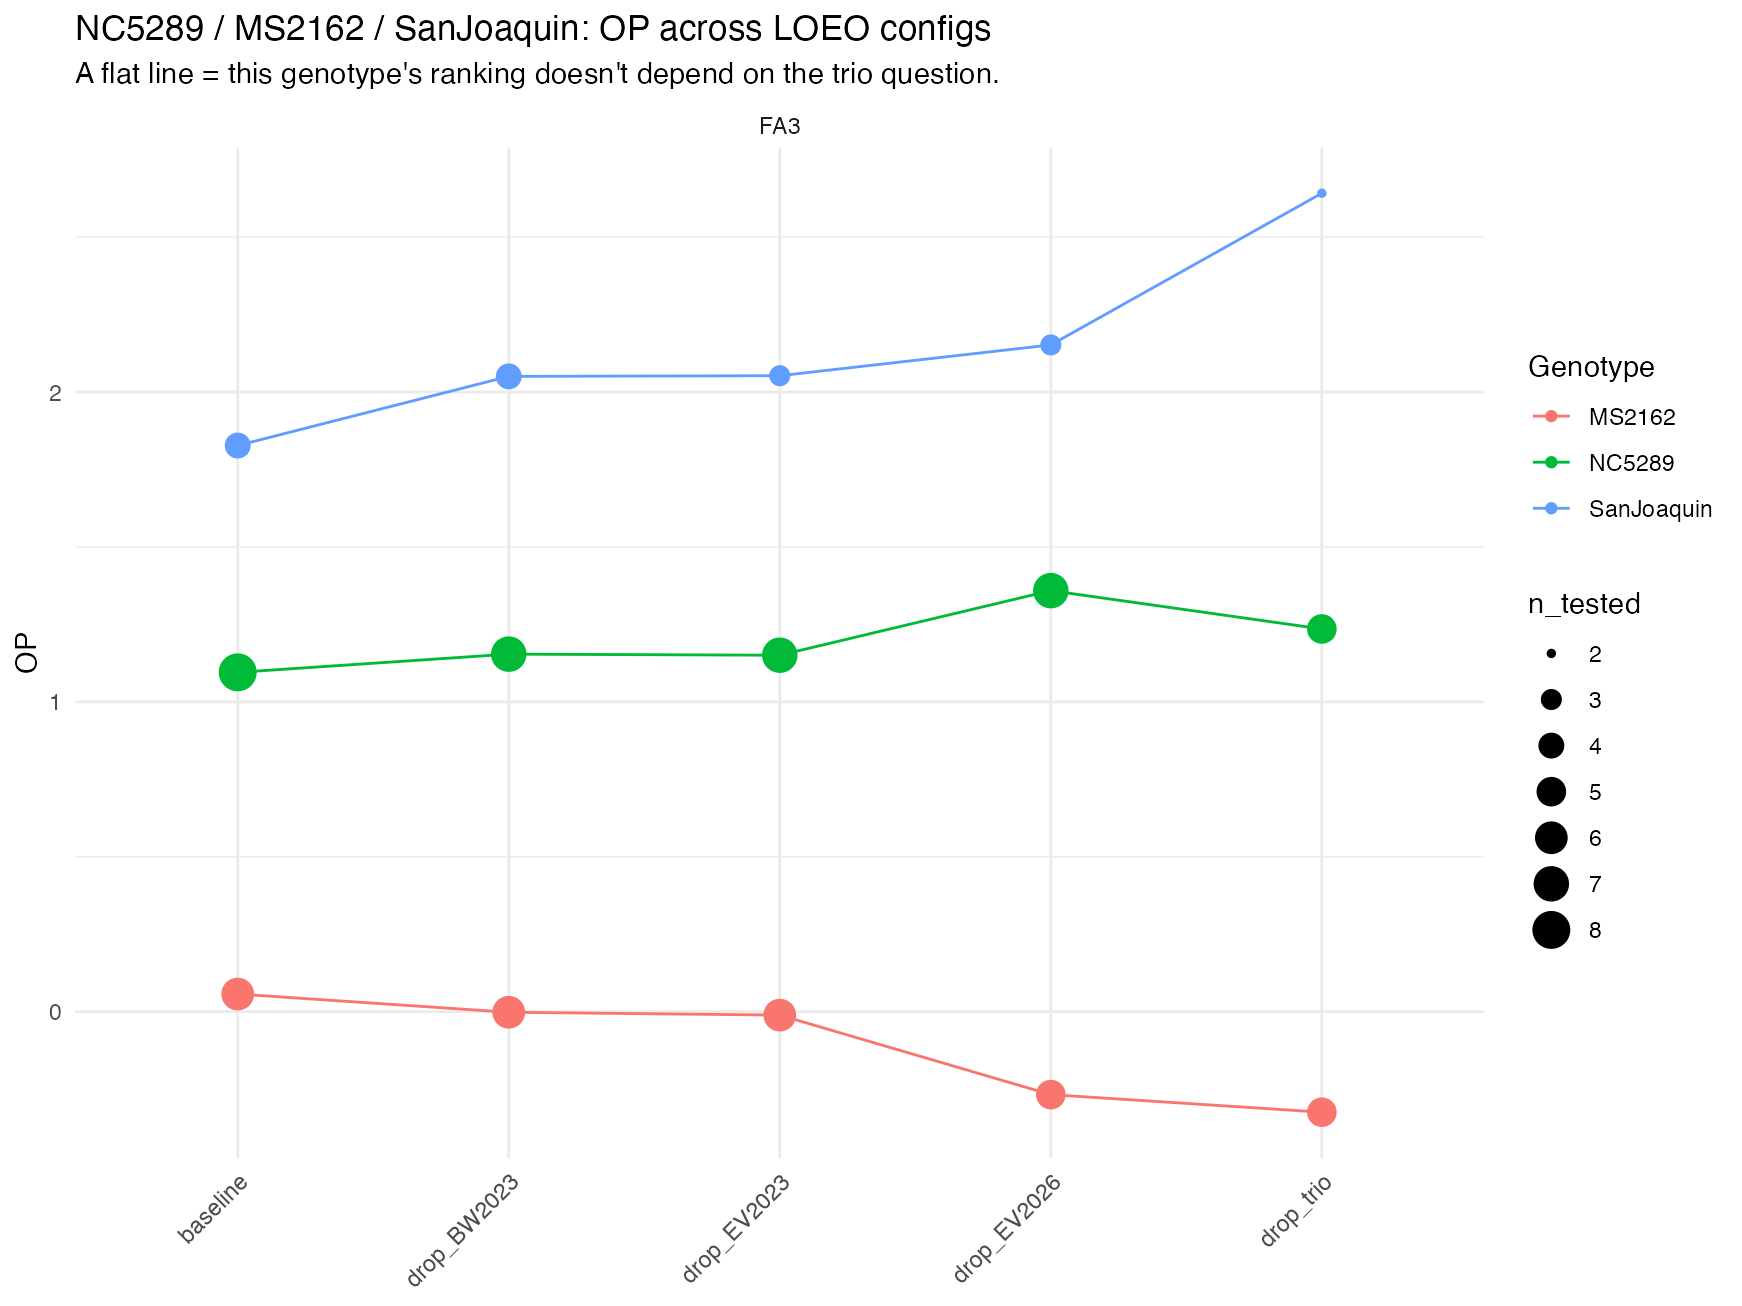

In [156]:
plot_watch_genotype_tracking(res_wa3)

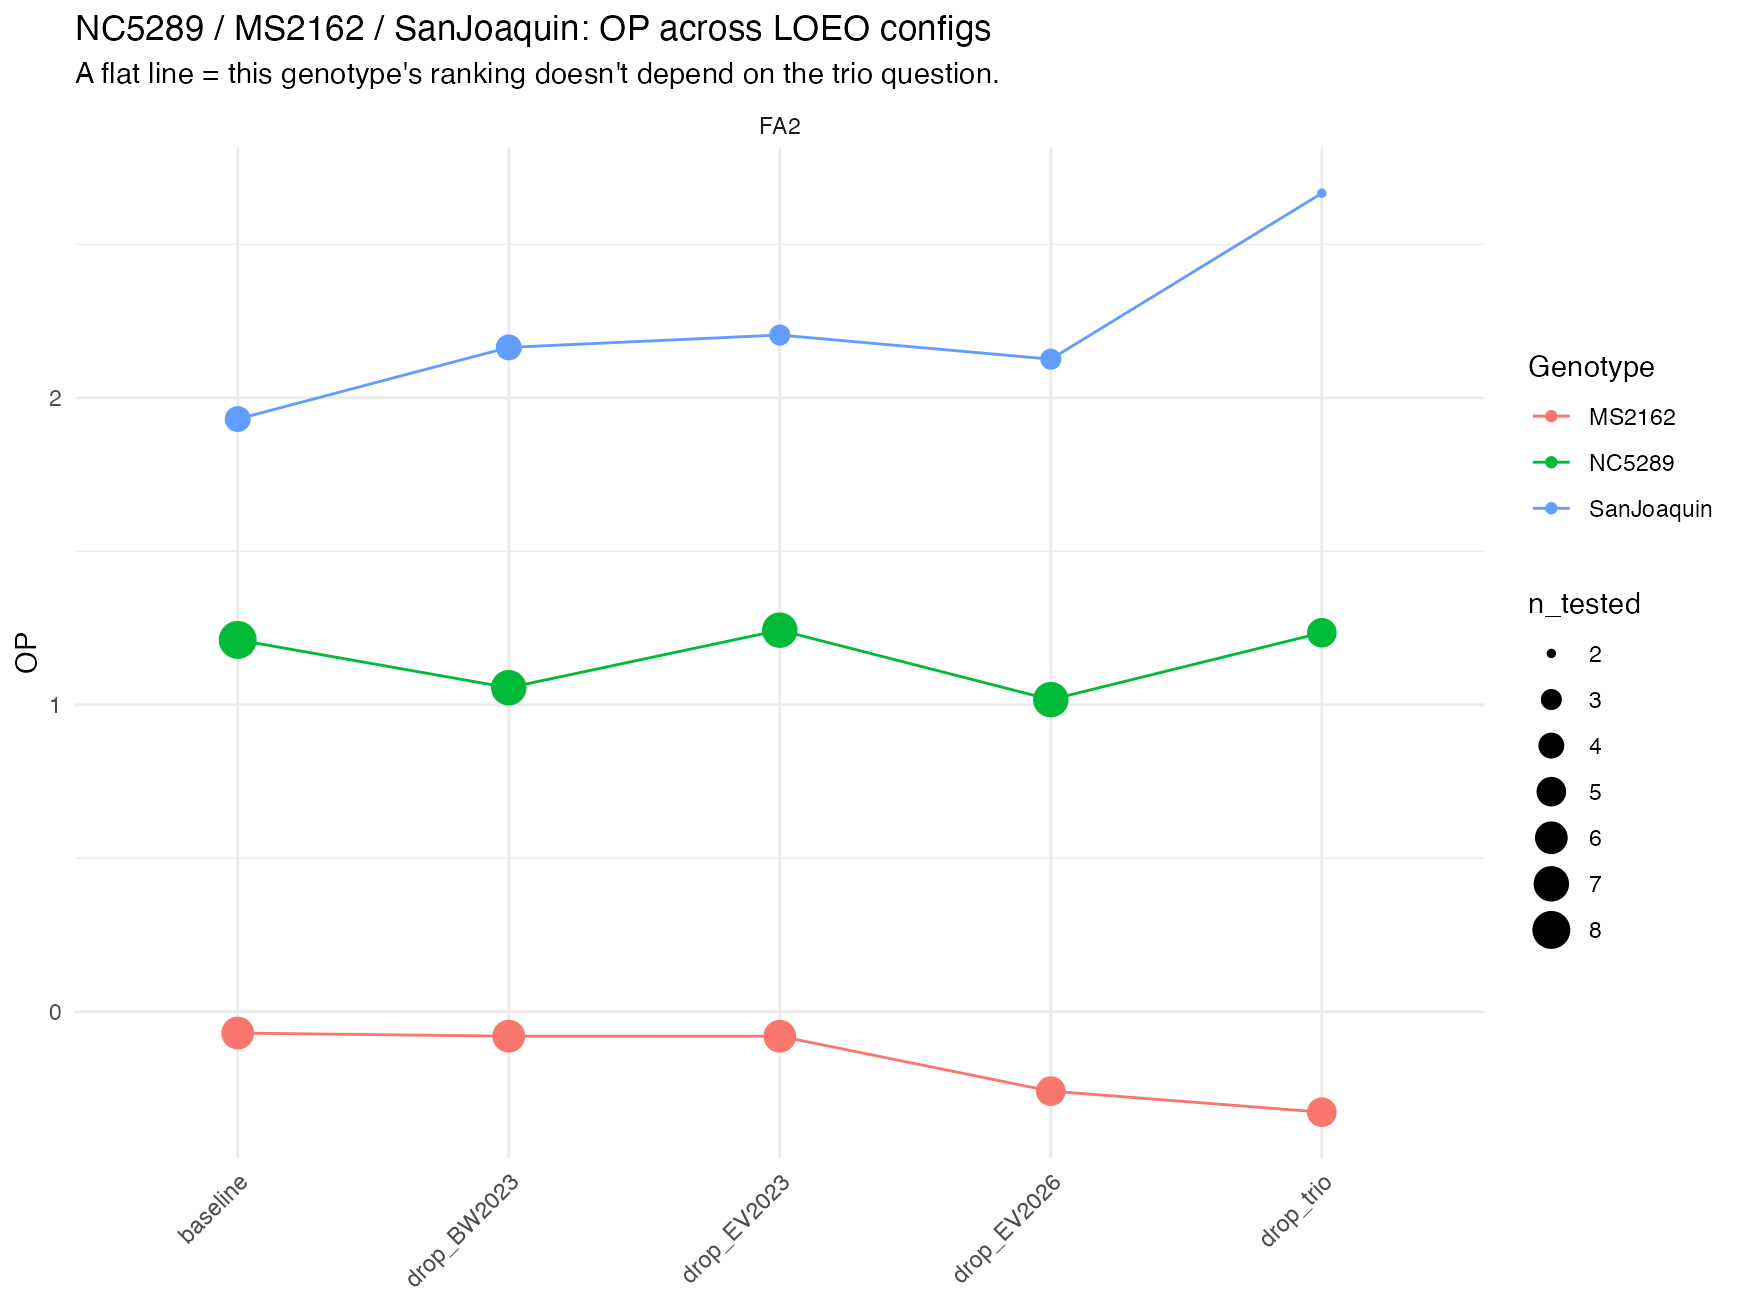

In [155]:
plot_watch_genotype_tracking(res_wa2)

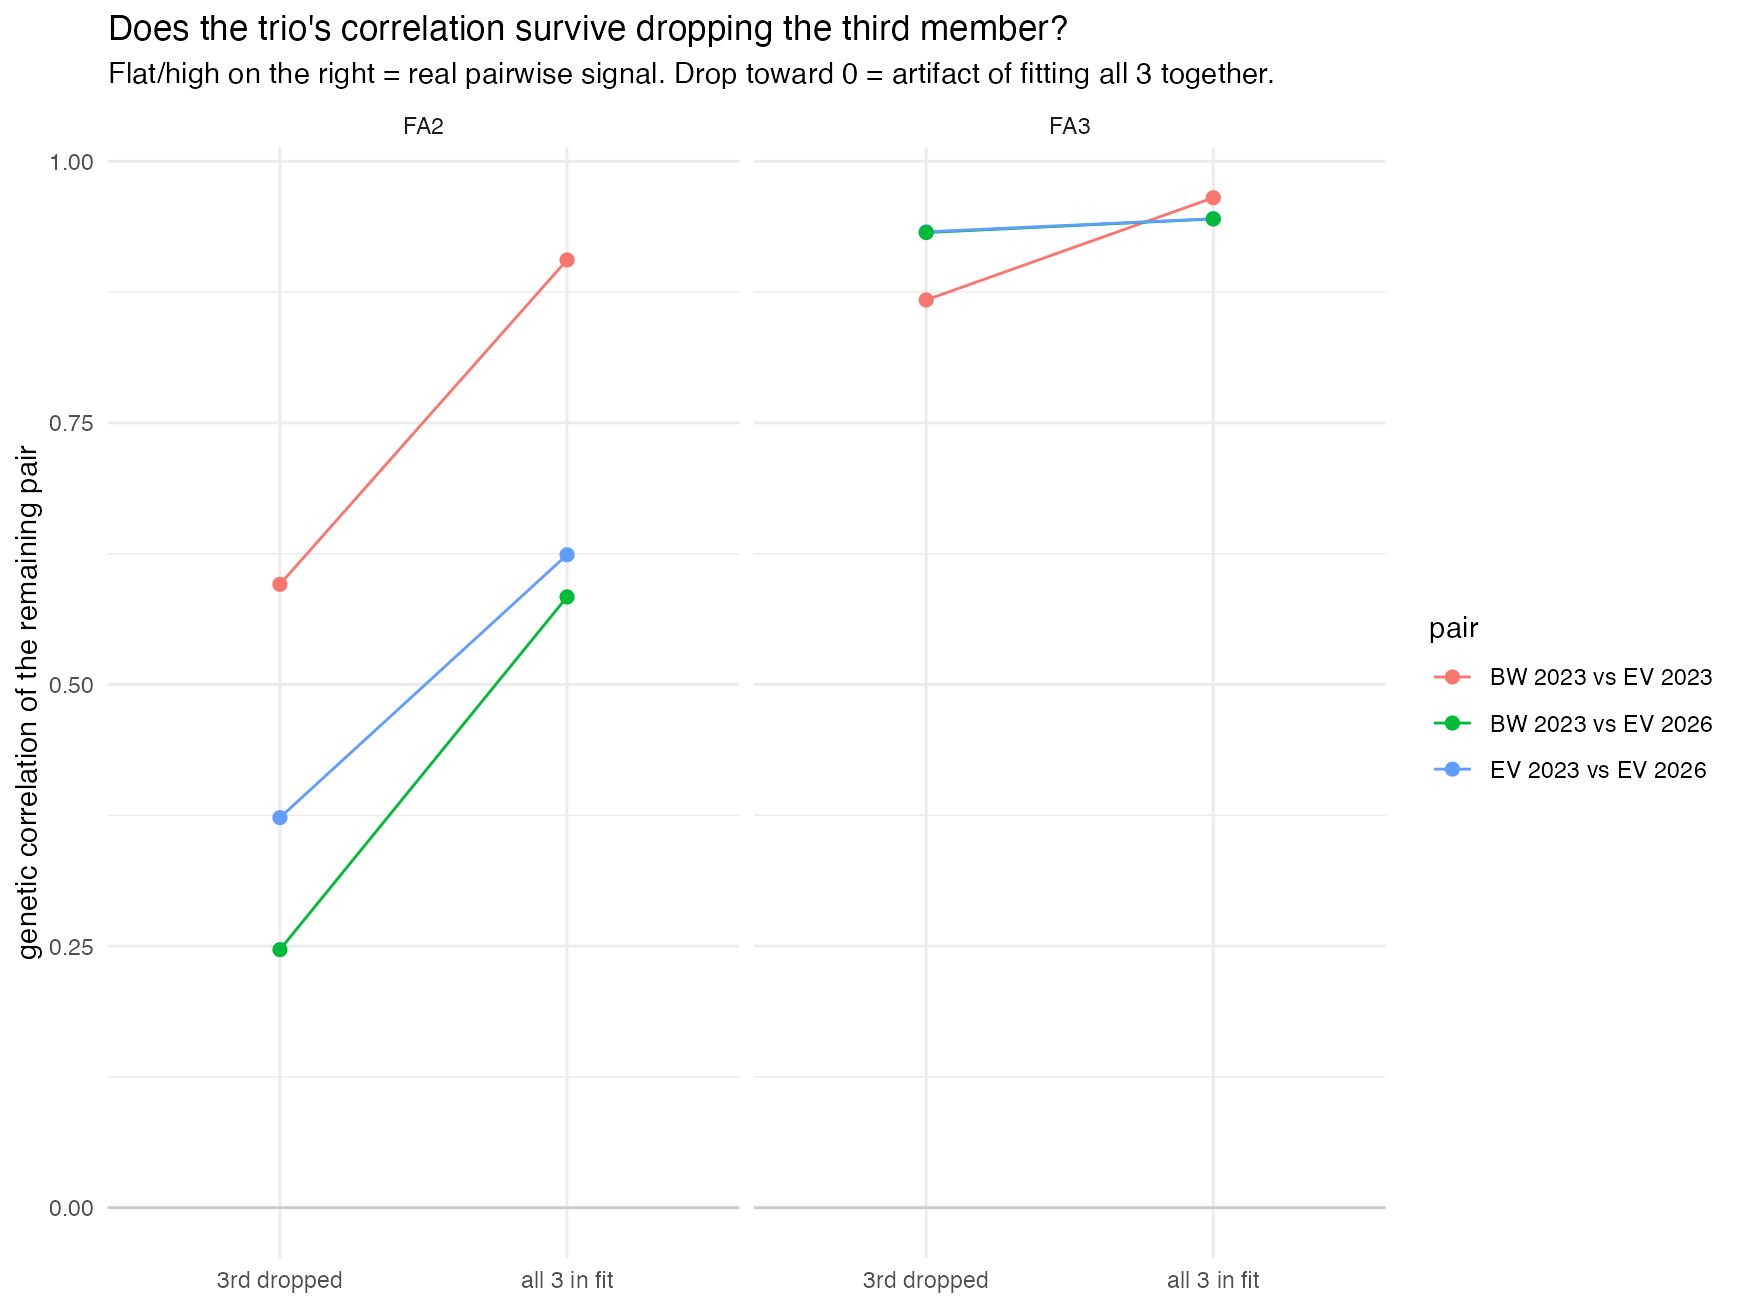

In [157]:
plot_trio_pair_survival(res_sum)

In [ ]:
library(dplyr)
library(tidyr)
library(tibble)
library(ggplot2)
library(purrr)

# Reuses extract_blups_asreml/extract_blups_sommer and fa_stability() from
# fa_stability.R -- source that first.
#
# ============================================================
# ASSUMPTIONS FLAGGED EXPLICITLY (confirm against your actual R/R/ signatures --
# these names/arg shapes are taken from DESIGN.md's prose description of Stage 7,
# not from reading the function bodies, so treat them the same way the rest of
# this project treats untested-end-to-end code: right shape, not confirmed):
#   - prepare_model1_data(data, qc_pass_environments = <char vector>, trait = "yield")
#   - fit_model1_diagonal(prepared)              -> sommer diag fit, gives H0 table
#   - fit_model1_fa(prepared, order = k, H = H0) -> sommer rrm() fit at order k
#   - prepare_asreml_ginverse(relationship_matrix)
#   - fit_model1_diagonal_asreml(prepared, ginv)
#   - fit_model1_fa_asreml(prepared, ginv, order = k)
#   - continue_asreml_fit(fit)                   -> wraps the unconditional
#     update.asreml() call already established as mandatory in this project
#   - extract_genetic_correlation_matrix(fa_fit, diagonal_fit)         [sommer]
#   - extract_genetic_correlation_matrix_asreml(fa_fit)                [asreml]
#   - normalize_asreml_fit_stats(fit) -> tibble(order, logL, n_params, AIC, BIC)
# Adjust the four fit_loeo_one_* internals if any of these differ.
# ============================================================

ALL_ENVS <- c("BW 2023", "BW 2024", "BW 2025", "BW 2026",
              "EV 2023", "EV 2024", "EV 2025", "EV 2026")
TRIO     <- c("BW 2023", "EV 2023", "EV 2026")
WATCH_GENOTYPES <- c("NC5289", "MS2162", "SanJoaquin")

# ------------------------------------------------------------
# 1. Config list: baseline (all 8) + drop each trio member + drop all 3.
#    Dropping all 3 isn't strictly LOEO but is the direct test of whether the
#    remaining 5-env "clean" set gets a cleaner FA2-vs-FA3 AIC/BIC verdict,
#    per last turn's hypothesis.
# ------------------------------------------------------------
loeo_specs <- function(trio = TRIO, all_envs = ALL_ENVS) {
  specs <- c(
    list(baseline = all_envs),
    setNames(lapply(trio, function(e) setdiff(all_envs, e)),
              paste0("drop_", gsub(" ", "", trio))),
    list(drop_trio = setdiff(all_envs, trio))
  )
  specs
}

# ------------------------------------------------------------
# 2. Fit one config, one engine. Fits FA2 and FA3 only (not FA1 again --
#    already settled FA1 isn't competitive at baseline; re-add order = 1:3
#    for `baseline` and `drop_BW2023` specifically if you want the AIC/BIC
#    verdict re-checked there, since that's the config most likely to move it).
# ------------------------------------------------------------
fit_loeo_one_asreml <- function(dta, ai,
                                 orders = 2:3) {
  # prepared <- prepare_model1_data(data, qc_pass_environments = qc_pass_environments,
  #                                  trait = "yield")
  # ginv <- prepare_asreml_ginverse(relationship_matrix)
  # diag_fit <- fit_model1_diagonal_asreml(prepared, ginv) %>% continue_asreml_fit()

  diag_fit = fit_diag_asreml(dta, ai)

  fa_fits <- set_names(orders) %>% map(function(k) {
    f <- fit_model1_fa_asreml(prepared, ginv, order = k) %>% continue_asreml_fit()
    list(
      fit   = f,
      stats = normalize_asreml_fit_stats(f),
      cor   = extract_genetic_correlation_matrix_asreml(f),
      blups = extract_blups_asreml(f)
    )
  })
  list(engine = "asreml", fa = fa_fits, diag_fit = diag_fit)
}

fit_loeo_one_sommer <- function(dta, relationship_matrix,
                                 orders = 2:3) {
  # prepared <- prepare_model1_data(dta, qc_pass_environments = qc_pass_environments,
  #                                  trait = "yield")
  diag_fit <- fit_diag_sommer(dta, ai)

  fa_fits <- set_names(orders) %>% map(function(k) {
    f <- fit_fa_sommer(dta, ai, k)
    list(
      fit   = f,
      cor   = extract_genetic_correlation_matrix(f),
      blups = extract_blups_sommer(f)
    )
  })
  list(engine = "sommer", fa = fa_fits, diag_fit = diag_fit)
}

# ------------------------------------------------------------
# 3. Run all configs for one engine. Sequential and loud on purpose --
#    ASReml fits in this project have needed unconditional update.asreml()
#    and generous maxiter before; don't silently swallow a convergence
#    warning here, since a LOEO config disagreeing BECAUSE it didn't converge
#    is a different (and misleading) result from one that disagrees because
#    the trio's correlation structure genuinely depends on all 3 members.
# ------------------------------------------------------------
run_loeo <- function(data, relationship_matrix, engine = c("asreml", "sommer"),
                      specs = loeo_specs(), orders = 2:3) {
  engine <- match.arg(engine)
  fit_fn <- if (engine == "asreml") fit_loeo_one_asreml else fit_loeo_one_sommer
  imap(specs, function(envs, config_name) {
    message(engine, " :: ", config_name, " (", length(envs), " envs)")
    fit_fn(data, relationship_matrix, qc_pass_environments = envs, orders = orders)
  })
}

# ------------------------------------------------------------
# 4. THE KEY DIAGNOSTIC: does the remaining trio pair's correlation survive
#    dropping the third member, or collapse toward the FA2-baseline near-zero
#    value? Only defined for the three single-drop configs (each leaves
#    exactly 2 of the 3 trio members in the fit).
# ------------------------------------------------------------
trio_pair_for_config <- function(config_name, trio = TRIO) {
  dropped <- gsub("drop_", "", config_name)
  dropped <- gsub("([A-Z]{2})(\\d{4})", "\\1 \\2", dropped)   # "BW2023" -> "BW 2023"
  if (!dropped %in% trio) return(NULL)
  setdiff(trio, dropped)
}

summarize_trio_pairs <- function(loeo_results, trio = TRIO) {
  baseline <- loeo_results[["baseline"]]
  map_dfr(names(loeo_results), function(cfg) {
    pair <- trio_pair_for_config(cfg, trio)
    if (is.null(pair)) return(NULL)
    res <- loeo_results[[cfg]]
    map_dfr(names(res$fa), function(ord) {
      cor_loeo <- res$fa[[ord]]$cor[pair[1], pair[2]]
      cor_base <- baseline$fa[[ord]]$cor[pair[1], pair[2]]
      tibble(config = cfg, dropped_env = setdiff(trio, pair), order = paste0("FA", ord),
             pair = paste(pair, collapse = " vs "),
             cor_baseline_with_all3 = cor_base, cor_with_third_dropped = cor_loeo,
             delta = cor_loeo - cor_base)
    })
  })
}

# Read this table as: if delta is small (pair stays ~0.9), the pair's
# correlation doesn't depend on the third environment -- consistent with a
# real, pairwise-robust signal. If cor_with_third_dropped collapses toward
# the FA2 baseline's near-zero values, that pair's apparent correlation was
# an artifact of fitting all three simultaneously.

# ------------------------------------------------------------
# 5. Track NC5289 / MS2162 / SanJoaquin's OP and RMSD rank across configs.
#    Uses fa_stability() as-is -- requires `tested` (Genotype, Env) for the
#    CURRENT config's environment set; filter your full `tested` tibble to
#    cfg's envs before calling, since a dropped environment obviously has no
#    tested cells anymore.
# ------------------------------------------------------------
track_watch_genotypes <- function(loeo_results, tested_full, order = "2",
                                   genotypes = WATCH_GENOTYPES) {
  map_dfr(names(loeo_results), function(cfg) {
    res <- loeo_results[[cfg]]
    if (!order %in% names(res$fa)) return(NULL)
    envs_here <- res$envs
    tested_here <- tested_full %>% filter(Env %in% envs_here)
    loadings <- res$fa[[order]]$cor   # NOTE: pass the actual loadings matrix your
                                       # fit object stores, not the correlation matrix --
                                       # placeholder until you confirm its field name
                                       # (asreml: $L off the FA fit; sommer: loadings_mmes())
    stab <- fa_stability(res$fa[[order]]$blups, loadings, tested = tested_here)
    stab$table %>% filter(Genotype %in% genotypes) %>%
      mutate(config = cfg, order = paste0("FA", order),
             rank_OP = rank(-stab$table$OP)[match(Genotype, stab$table$Genotype)],
             rank_RMSD = rank(stab$table$RMSD)[match(Genotype, stab$table$Genotype)]) %>%
      select(config, order, Genotype, OP, RMSD, n_tested, rank_OP, rank_RMSD)
  })
}

# ------------------------------------------------------------
# 6. Plots
# ------------------------------------------------------------
plot_trio_pair_survival <- function(pair_summary) {
  d <- pair_summary %>%
    pivot_longer(c(cor_baseline_with_all3, cor_with_third_dropped),
                 names_to = "which", values_to = "r") %>%
    mutate(which = recode(which, cor_baseline_with_all3 = "all 3 in fit",
                           cor_with_third_dropped = "3rd dropped"))
  ggplot(d, aes(which, r, group = interaction(pair, order), colour = pair)) +
    geom_hline(yintercept = 0, colour = "grey80") +
    geom_line() + geom_point(size = 2) +
    facet_wrap(~order) +
    labs(x = NULL, y = "genetic correlation of the remaining pair",
         title = "Does the trio's correlation survive dropping the third member?",
         subtitle = "Flat/high on the right = real pairwise signal. Drop toward 0 = artifact of fitting all 3 together.") +
    theme_minimal()
}

plot_watch_genotype_tracking <- function(watch_summary) {
  ggplot(watch_summary, aes(config, OP, colour = Genotype, group = Genotype)) +
    geom_line() + geom_point(aes(size = n_tested)) +
    facet_wrap(~order) +
    theme_minimal() + theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
    labs(title = "NC5289 / MS2162 / SanJoaquin: OP across LOEO configs",
         subtitle = "A flat line = this genotype's ranking doesn't depend on the trio question.",
         x = NULL)
}

### Fit Sommer

In [109]:
fit_dg_sm  <- fit_diag_sommer(prep_y, Ainv_sm)

Solver selected: cholmod


In [32]:
fit_fa1_sm <- fit_fa_sommer(prep_y, Ainv_sm, 1)

Solver selected: cholmod


In [33]:
fit_fa2_sm <- fit_fa_sommer(prep_y, Ainv_sm, 2)

Solver selected: cholmod


In [34]:
fit_fa3_sm <- fit_fa_sommer(prep_y, Ainv_sm, 3)

Solver selected: cholmod


In [35]:
c(DG = fit_dg_sm$AIC, FA1 = fit_fa1_sm$AIC, FA2 = fit_fa2_sm$AIC, FA3 = fit_fa3_sm$AIC) 

      DG      FA1      FA2      FA3 
430.1133 319.5792 289.5244 269.2483 

diag vs fa1

In [36]:
anova.mmes(fit_dg_sm, fit_fa1_sm) 

Likelihood ratio test for mixed models
     Df      AIC      BIC     loLik     Chisq ChiDf                  PrChisq
mod2 33 319.5792 355.9993 -151.7896                                         
mod1 25 430.1133 466.5334 -207.0566 110.53405     8 2.95707556588466e-20 ***
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1


     Df      AIC      BIC     loLik     Chisq ChiDf                  PrChisq
mod2 33 319.5792 355.9993 -151.7896                                         
mod1 25 430.1133 466.5334 -207.0566 110.53405     8 2.95707556588466e-20 ***

fa1 vs fa2

In [149]:
anova.mmes(fit_fa1_sm, fit_fa2_sm) 

Likelihood ratio test for mixed models
     Df      AIC      BIC     loLik    Chisq ChiDf   PrChisq
mod2 40 289.5244 325.9444 -136.7622                         
mod1 33 319.5792 355.9993 -151.7896 30.05489     7 9e-05 ***
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1


     Df      AIC      BIC     loLik    Chisq ChiDf   PrChisq
mod2 40 289.5244 325.9444 -136.7622                         
mod1 33 319.5792 355.9993 -151.7896 30.05489     7 9e-05 ***

fa2 vs fa3

In [37]:
anova.mmes(fit_fa2_sm, fit_fa3_sm) 

Likelihood ratio test for mixed models
     Df      AIC      BIC     loLik    Chisq ChiDf    PrChisq
mod2 46 269.2483 305.6684 -126.6242                          
mod1 40 289.5244 325.9444 -136.7622 20.27603     6 0.00247 **
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1


     Df      AIC      BIC     loLik    Chisq ChiDf    PrChisq
mod2 46 269.2483 305.6684 -126.6242                          
mod1 40 289.5244 325.9444 -136.7622 20.27603     6 0.00247 **

In [16]:
summary(fit_fa3_sm)$varcomp

                                                     term factor                  parameter      estimate     StdError     Zratio
1  vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv)     fa        loading[BW 2023,F1]  9.961340e-01 1.127182e-01  8.8373819
2  vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv)     fa        loading[BW 2024,F1]  1.737753e-01 1.281091e-01  1.3564641
3  vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv)     fa        loading[BW 2025,F1] -1.275557e-01 1.286552e-01 -0.9914539
4  vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv)     fa        loading[BW 2026,F1] -8.632216e-02 1.292873e-01 -0.6676771
5  vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv)     fa        loading[EV 2023,F1]  5.738216e-01 1.419688e-01  4.0418864
6  vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv)     fa        loading[EV 2024,F1]  2.299007e-01 1.422134e-01  1.6165896
7  vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv)     fa        loading[EV 2025,F1

In [38]:
rg_sm = round(extract_rg_matrix_sommer(fit_fa3_sm)$corr, 2)
rg_sm

        BW 2023 BW 2024 BW 2025 BW 2026 EV 2023 EV 2024 EV 2025 EV 2026
BW 2023    1.00    0.17   -0.14   -0.11    0.97    0.20   -0.04    0.94
BW 2024    0.17    1.00    0.79    0.23    0.12    1.00    0.93    0.31
BW 2025   -0.14    0.79    1.00    0.74   -0.23    0.73    0.83    0.07
BW 2026   -0.11    0.23    0.74    1.00   -0.22    0.14    0.32    0.09
EV 2023    0.97    0.12   -0.23   -0.22    1.00    0.16   -0.10    0.95
EV 2024    0.20    1.00    0.73    0.14    0.16    1.00    0.91    0.32
EV 2025   -0.04    0.93    0.83    0.32   -0.10    0.91    1.00    0.10
EV 2026    0.94    0.31    0.07    0.09    0.95    0.32    0.10    1.00

In [39]:
rg_sm2 = round(extract_rg_matrix_sommer(fit_fa2_sm)$corr, 2)
rg_sm2

        BW 2023 BW 2024 BW 2025 BW 2026 EV 2023 EV 2024 EV 2025 EV 2026
BW 2023    1.00    0.42    0.00   -0.25    0.91    0.45    0.10    0.58
BW 2024    0.42    1.00    0.74    0.26    0.31    1.00    0.93    0.31
BW 2025    0.00    0.74    1.00    0.36   -0.13    0.73    0.83    0.02
BW 2026   -0.25    0.26    0.36    1.00   -0.34    0.24    0.40   -0.17
EV 2023    0.91    0.31   -0.13   -0.34    1.00    0.34   -0.06    0.62
EV 2024    0.45    1.00    0.73    0.24    0.34    1.00    0.92    0.33
EV 2025    0.10    0.93    0.83    0.40   -0.06    0.92    1.00    0.09
EV 2026    0.58    0.31    0.02   -0.17    0.62    0.33    0.09    1.00

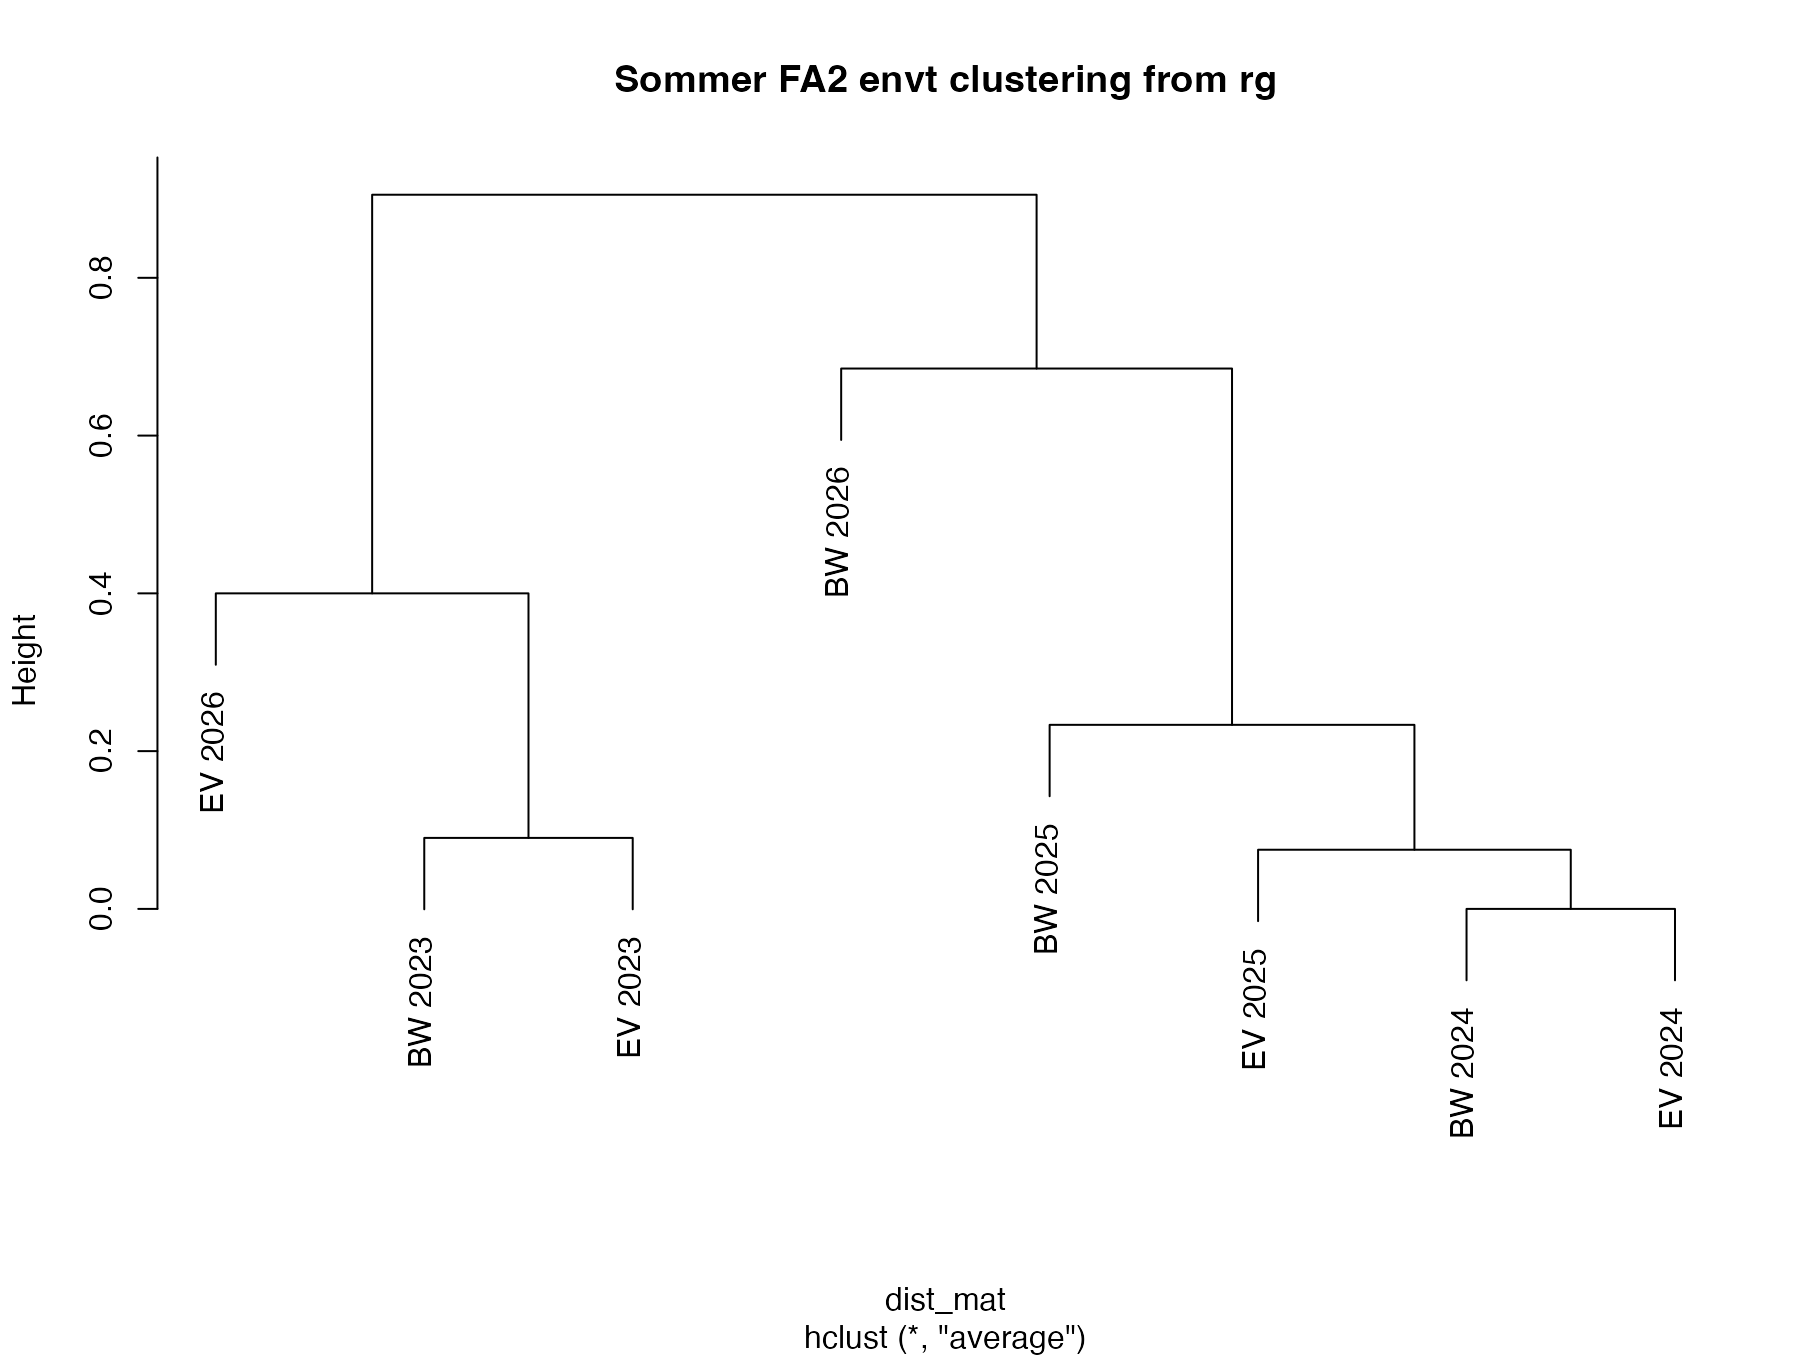

In [85]:
dist_mat <- as.dist(1 - rg_sm2)
hc <- hclust(dist_mat, method = "average")
plot(hc, main = "Sommer FA2 envt clustering from rg")

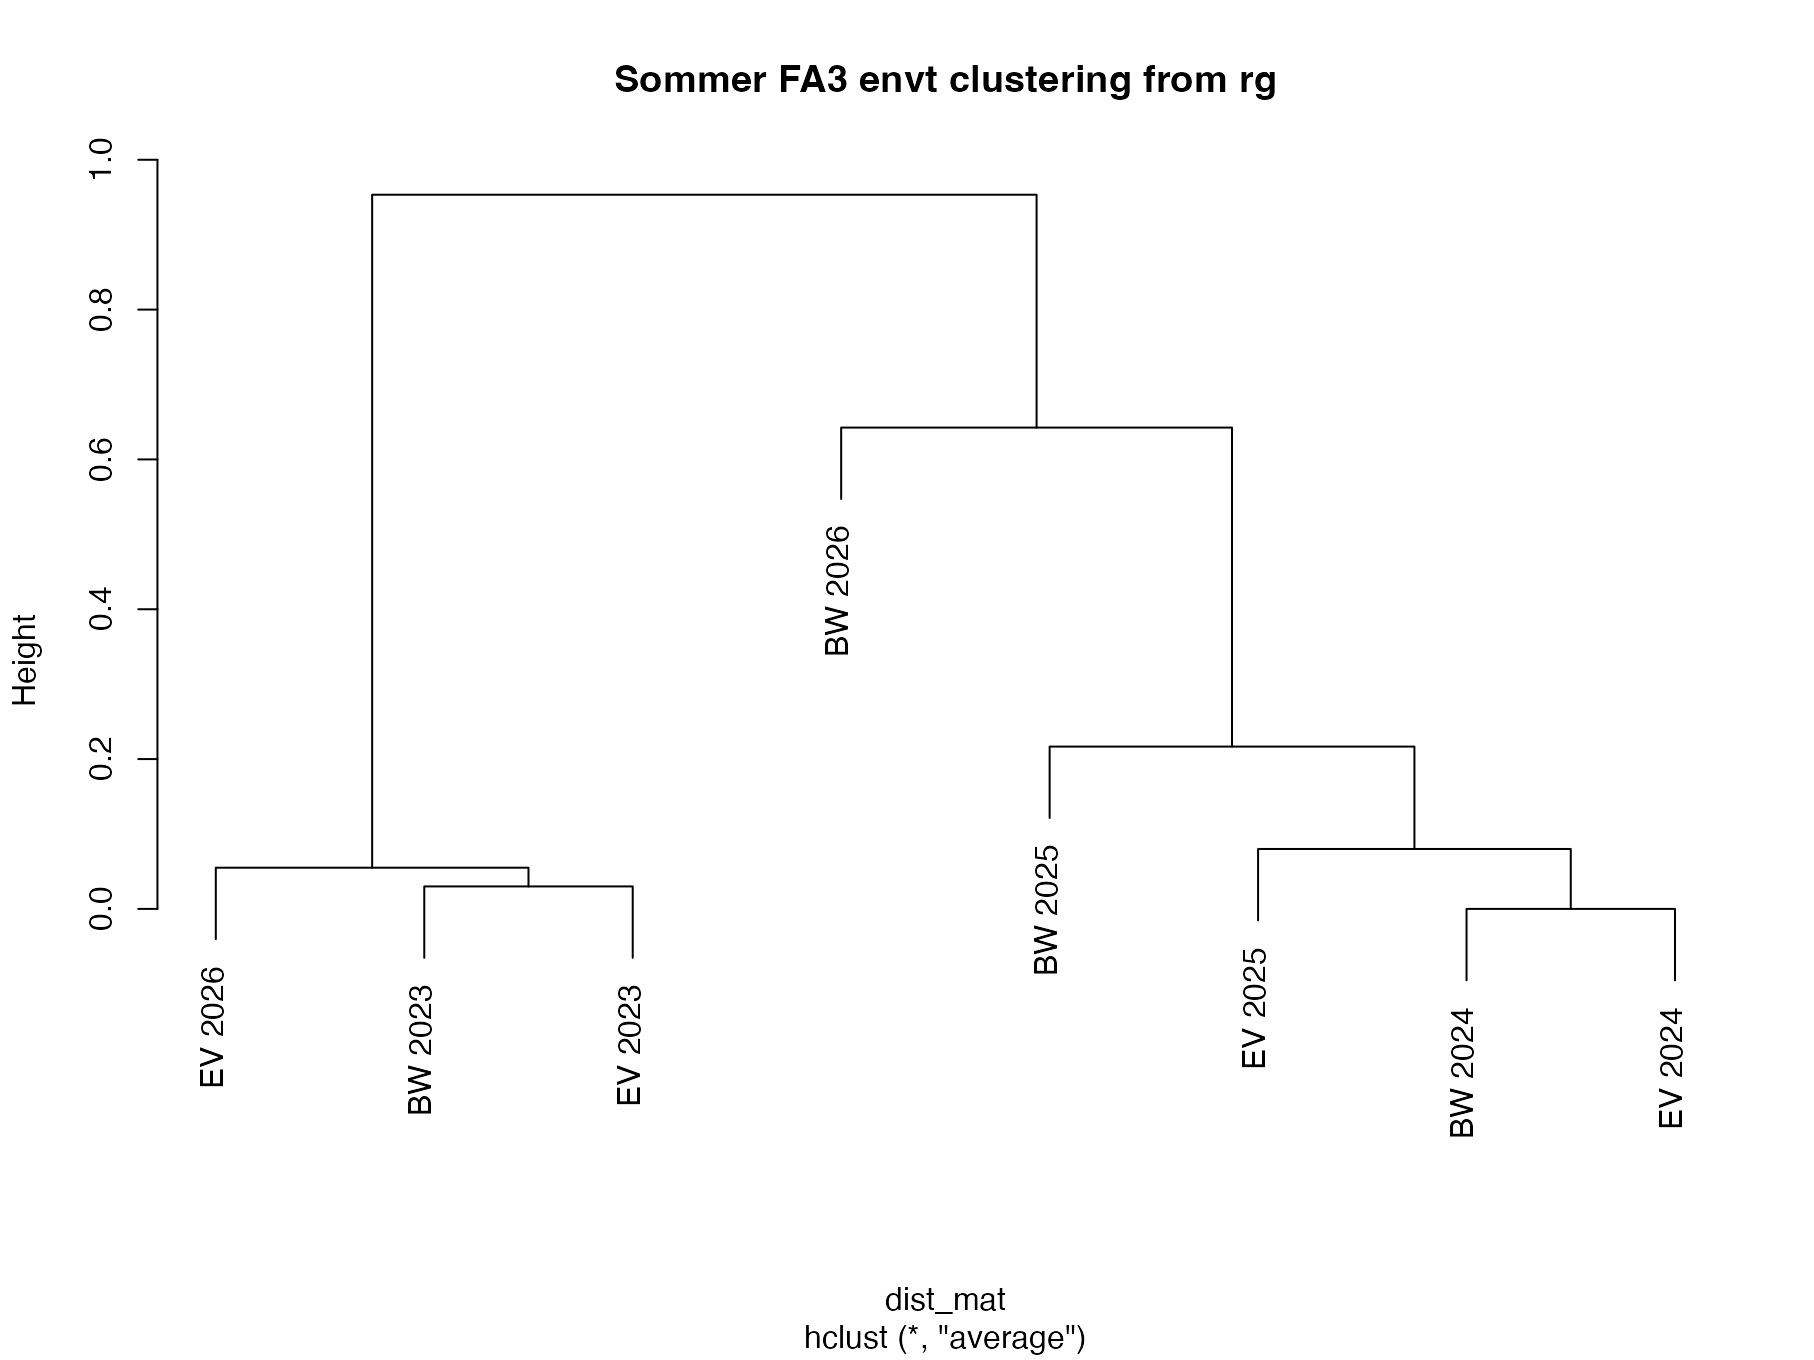

In [86]:
dist_mat <- as.dist(1 - rg_sm)
hc <- hclust(dist_mat, method = "average")
plot(hc, main = "Sommer FA3 envt clustering from rg")

### Fit Asreml

In [72]:
fit_fa1_asr = fit_fa_asreml(prep_y, ainv)

ASReml Version 4.2 06/10/2026 11:42:02
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -313.4984           1.0    693   11:42:02
  2     -266.8990           1.0    693   11:42:02
  3     -227.6624           1.0    693   11:42:02  (  1 restrained)
  4     -201.3174           1.0    693   11:42:02  (  1 restrained)
  5     -183.9117           1.0    693   11:42:02  (  2 restrained)
  6     -170.7068           1.0    693   11:42:02  (  2 restrained)
  7     -163.7877           1.0    693   11:42:02  (  1 restrained)
  8     -161.2358           1.0    693   11:42:02  (  1 restrained)
  9     -160.2100           1.0    693   11:42:02
 10     -159.9092           1.0    693   11:42:02
 11     -159.8319           1.0    693   11:42:02
 12     -159.8059           1.0    693   11:42:02
 13     -159.7955           1.0    693   11:42:02
ASReml Version 4.2 06/10/2026 11:42:02
Multi-section model using the sigma parameterization.
         

Warning messages:
1: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 1):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration
2: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 1):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


In [73]:
fit_fa2_asr = fit_fa2_asreml(prep_y, ainv)

ASReml Version 4.2 06/10/2026 11:42:05
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -243.6759           1.0    693   11:42:05
  2     -190.1145           1.0    693   11:42:05  (  3 restrained)
  3     -163.2319           1.0    693   11:42:05  (  3 restrained)
  4     -153.5291           1.0    693   11:42:05  (  3 restrained)
  5     -150.2075           1.0    693   11:42:05  (  1 restrained)
  6     -148.6959           1.0    693   11:42:05  (  1 restrained)
  7     -148.2523           1.0    693   11:42:05  (  1 restrained)
  8     -148.1517           1.0    693   11:42:05
  9     -148.0158           1.0    693   11:42:05  (  1 restrained)
 10     -147.9784           1.0    693   11:42:05
 11     -147.9401           1.0    693   11:42:05
 12     -147.8864           1.0    693   11:42:05
 13     -147.8148           1.0    693   11:42:05  (  1 restrained)
 14     -147.7996           1.0    693   11:42:05
 15     -147.775

Warning messages:
1: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 2):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration
2: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 2):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


In [74]:
fit_fa3_asr = fit_fa3_asreml(prep_y, ainv)

ASReml Version 4.2 06/10/2026 11:42:09
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -230.0736           1.0    693   11:42:09  (  3 restrained)
  2     -172.5993           1.0    693   11:42:09  (  3 restrained)
  3     -156.5085           1.0    693   11:42:09  (  4 restrained)
  4     -149.4782           1.0    693   11:42:09  (  3 restrained)
  5     -145.9142           1.0    693   11:42:09  (  3 restrained)
  6     -143.6237           1.0    693   11:42:09  (  4 restrained)
  7     -142.5511           1.0    693   11:42:09  (  1 restrained)
  8     -141.7846           1.0    693   11:42:09  (  1 restrained)
  9     -141.2359           1.0    693   11:42:09  (  1 restrained)
 10     -140.6709           1.0    693   11:42:09  (  1 restrained)
 11     -140.1989           1.0    693   11:42:09  (  1 restrained)
 12     -139.5746           1.0    693   11:42:09  (  1 restrained)
 13     -138.5996           1.0    693   11:

Warning messages:
1: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration
2: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


In [24]:
summary(fit_fa1_asr)$varcomp

                                               component   std.error   z.ratio bound %ch
Env:Block                                     0.01429035 0.009068391 1.5758422     P 0.0
fa(Env, k = 1):vm(Genotype, Ainv)!BW 2023!var 0.39762402 0.166351691 2.3902614     P 0.0
fa(Env, k = 1):vm(Genotype, Ainv)!BW 2024!var 0.00000000          NA        NA     F  NA
fa(Env, k = 1):vm(Genotype, Ainv)!BW 2025!var 0.13047248 0.048555067 2.6871033     P 0.0
fa(Env, k = 1):vm(Genotype, Ainv)!BW 2026!var 0.19340213 0.069793065 2.7710794     P 0.0
fa(Env, k = 1):vm(Genotype, Ainv)!EV 2023!var 0.09758845 0.093071347 1.0485338     P 0.0
fa(Env, k = 1):vm(Genotype, Ainv)!EV 2024!var 0.00000000          NA        NA     F  NA
fa(Env, k = 1):vm(Genotype, Ainv)!EV 2025!var 0.05586715 0.032935644 1.6962519     P 0.2
fa(Env, k = 1):vm(Genotype, Ainv)!EV 2026!var 0.40684031 0.121873542 3.3382168     P 0.0
fa(Env, k = 1):vm(Genotype, Ainv)!BW 2023!fa1 0.15246022 0.214763779 0.7098973     P 0.9
fa(Env, k = 1):vm(Gen

In [25]:
summary(fit_fa2_asr)$varcomp

                                                component   std.error    z.ratio bound %ch
Env:Block                                      0.01389034 0.008933394  1.5548779     P 0.0
fa(Env, k = 2):vm(Genotype, Ainv)!BW 2023!var  0.26400290 0.129598047  2.0370901     P 0.0
fa(Env, k = 2):vm(Genotype, Ainv)!BW 2024!var  0.00000000          NA         NA     F  NA
fa(Env, k = 2):vm(Genotype, Ainv)!BW 2025!var  0.00000000          NA         NA     F  NA
fa(Env, k = 2):vm(Genotype, Ainv)!BW 2026!var  0.05434113 0.052112647  1.0427628     P 0.0
fa(Env, k = 2):vm(Genotype, Ainv)!EV 2023!var  0.04010812 0.065990024  0.6077906     P 0.1
fa(Env, k = 2):vm(Genotype, Ainv)!EV 2024!var  0.00000000          NA         NA     F  NA
fa(Env, k = 2):vm(Genotype, Ainv)!EV 2025!var  0.02638056 0.027747544  0.9507351     P 0.0
fa(Env, k = 2):vm(Genotype, Ainv)!EV 2026!var  0.40081530 0.121358019  3.3027509     P 0.0
fa(Env, k = 2):vm(Genotype, Ainv)!BW 2023!fa1  0.33247275 0.162895064  2.0410241     P 0.1

In [26]:
summary(fit_fa3_asr)$varcomp

                                                component   std.error     z.ratio bound %ch
Env:Block                                      0.01335915 0.008742146  1.52813114     P 0.0
fa(Env, k = 3):vm(Genotype, Ainv)!BW 2023!var  0.00000000          NA          NA     F  NA
fa(Env, k = 3):vm(Genotype, Ainv)!BW 2024!var  0.00000000          NA          NA     F  NA
fa(Env, k = 3):vm(Genotype, Ainv)!BW 2025!var  0.02621482 0.033268764  0.78797098     P 0.0
fa(Env, k = 3):vm(Genotype, Ainv)!BW 2026!var  0.00000000          NA          NA     F  NA
fa(Env, k = 3):vm(Genotype, Ainv)!EV 2023!var  0.01559218 0.045126375  0.34552245     P 0.1
fa(Env, k = 3):vm(Genotype, Ainv)!EV 2024!var  0.00000000          NA          NA     F  NA
fa(Env, k = 3):vm(Genotype, Ainv)!EV 2025!var  0.00000000          NA          NA     F  NA
fa(Env, k = 3):vm(Genotype, Ainv)!EV 2026!var  0.00000000          NA          NA     F  NA
fa(Env, k = 3):vm(Genotype, Ainv)!BW 2023!fa1  0.71134817 0.113022120  6.2938845

In [90]:
c(FA1 = summary(fit_fa1_asr)$aic, FA2 = summary(fit_fa2_asr)$aic, FA3 = summary(fit_fa3_asr)$aic)

     FA1      FA2      FA3 
365.5811 352.3828 328.7636 

In [75]:

models <- list(
  FA1 = fit_fa1_asr,
  FA2 = fit_fa2_asr,
  FA3 = fit_fa3_asr
)

model_comp <- data.frame(
  Model    = names(models),
  LogL     = sapply(models, function(m) m$loglik),
  N_params = sapply(models, function(m) (m$nwv)),
  AIC      = sapply(models, function(m) summary(m)$aic),
  BIC      = sapply(models, function(m) summary(m)$bic)
)
model_comp

    Model      LogL N_params      AIC      BIC
FA1   FA1 -159.7905       25 365.5811 470.0247
FA2   FA2 -147.1914       33 352.3828 484.0727
FA3   FA3 -133.3818       41 328.7636 469.5355

In [332]:

extract_rg_matrix_asreml2 <- function(varcomp, env_levels, n_factors) {
  var_rows <- varcomp[grep("!var$", rownames(varcomp)), , drop = FALSE]
  if (nrow(var_rows) == 0) {
    stop(
      "extract_rg_matrix_asreml(): no rows matching '!var' "
    )
  }
  R <- var_rows[, 1]

  print('here1')

  loadings <- lapply(seq_len(n_factors), function(k) {
    rows <- varcomp[grep(paste0("!fa", k, "$"), rownames(varcomp)), , drop = FALSE]
    if (nrow(rows) == 0) {
      stop(
        "extract_rg_matrix_asreml(): no rows matching '!fa", k, "'",   
      )
    }
    rows[, 1]
  })

  print('here2')
  L <- do.call(cbind, loadings)
  # rownames(L) <- env_levels 
  print('here3')
  cov <- L %*% t(L) + diag(R)
  dimnames(cov) <- list(env_levels, env_levels)

  list(cov = cov, corr = stats::cov2cor(cov), loadings = L)
}

In [333]:
env_levels = levels(factor(prep_y$Env))
asreml_result2 <- extract_rg_matrix_asreml2(
  varcomp     = summary(fit_fa2_asr)$varcomp,  
  env_levels  = env_levels,            
  n_factors   = 2
)
rg_asr2 = round(asreml_result2$corr, 2)
rg_asr2

[1] "here1"
[1] "here2"
[1] "here3"


        BW 2023 BW 2024 BW 2025 BW 2026 EV 2023 EV 2024 EV 2025 EV 2026
BW 2023    1.00   -0.34   -0.54   -0.55    0.28   -0.30   -0.41   -0.06
BW 2024   -0.34    1.00    0.89    0.54    0.24    1.00    0.95    0.27
BW 2025   -0.54    0.89    1.00    0.80   -0.11    0.85    0.92    0.21
BW 2026   -0.55    0.54    0.80    1.00   -0.37    0.48    0.63    0.10
EV 2023    0.28    0.24   -0.11   -0.37    1.00    0.29    0.11    0.11
EV 2024   -0.30    1.00    0.85    0.48    0.29    1.00    0.94    0.28
EV 2025   -0.41    0.95    0.92    0.63    0.11    0.94    1.00    0.25
EV 2026   -0.06    0.27    0.21    0.10    0.11    0.28    0.25    1.00

In [77]:
asreml_result3 <- extract_rg_matrix_asreml(
  varcomp     = summary(fit_fa3_asr)$varcomp,  
  env_levels  = env_levels,            
  n_factors   = 3
)
rg_asr3 = round(asreml_result3$correlation, 2)
rg_asr3

        BW 2023 BW 2024 BW 2025 BW 2026 EV 2023 EV 2024 EV 2025 EV 2026
BW 2023    1.00   -0.03   -0.10    0.10    0.99   -0.04   -0.24    0.96
BW 2024   -0.03    1.00    0.89    0.49    0.03    1.00    0.98    0.23
BW 2025   -0.10    0.89    1.00    0.78   -0.09    0.85    0.91    0.19
BW 2026    0.10    0.49    0.78    1.00    0.03    0.41    0.51    0.34
EV 2023    0.99    0.03   -0.09    0.03    1.00    0.04   -0.18    0.95
EV 2024   -0.04    1.00    0.85    0.41    0.04    1.00    0.97    0.21
EV 2025   -0.24    0.98    0.91    0.51   -0.18    0.97    1.00    0.03
EV 2026    0.96    0.23    0.19    0.34    0.95    0.21    0.03    1.00

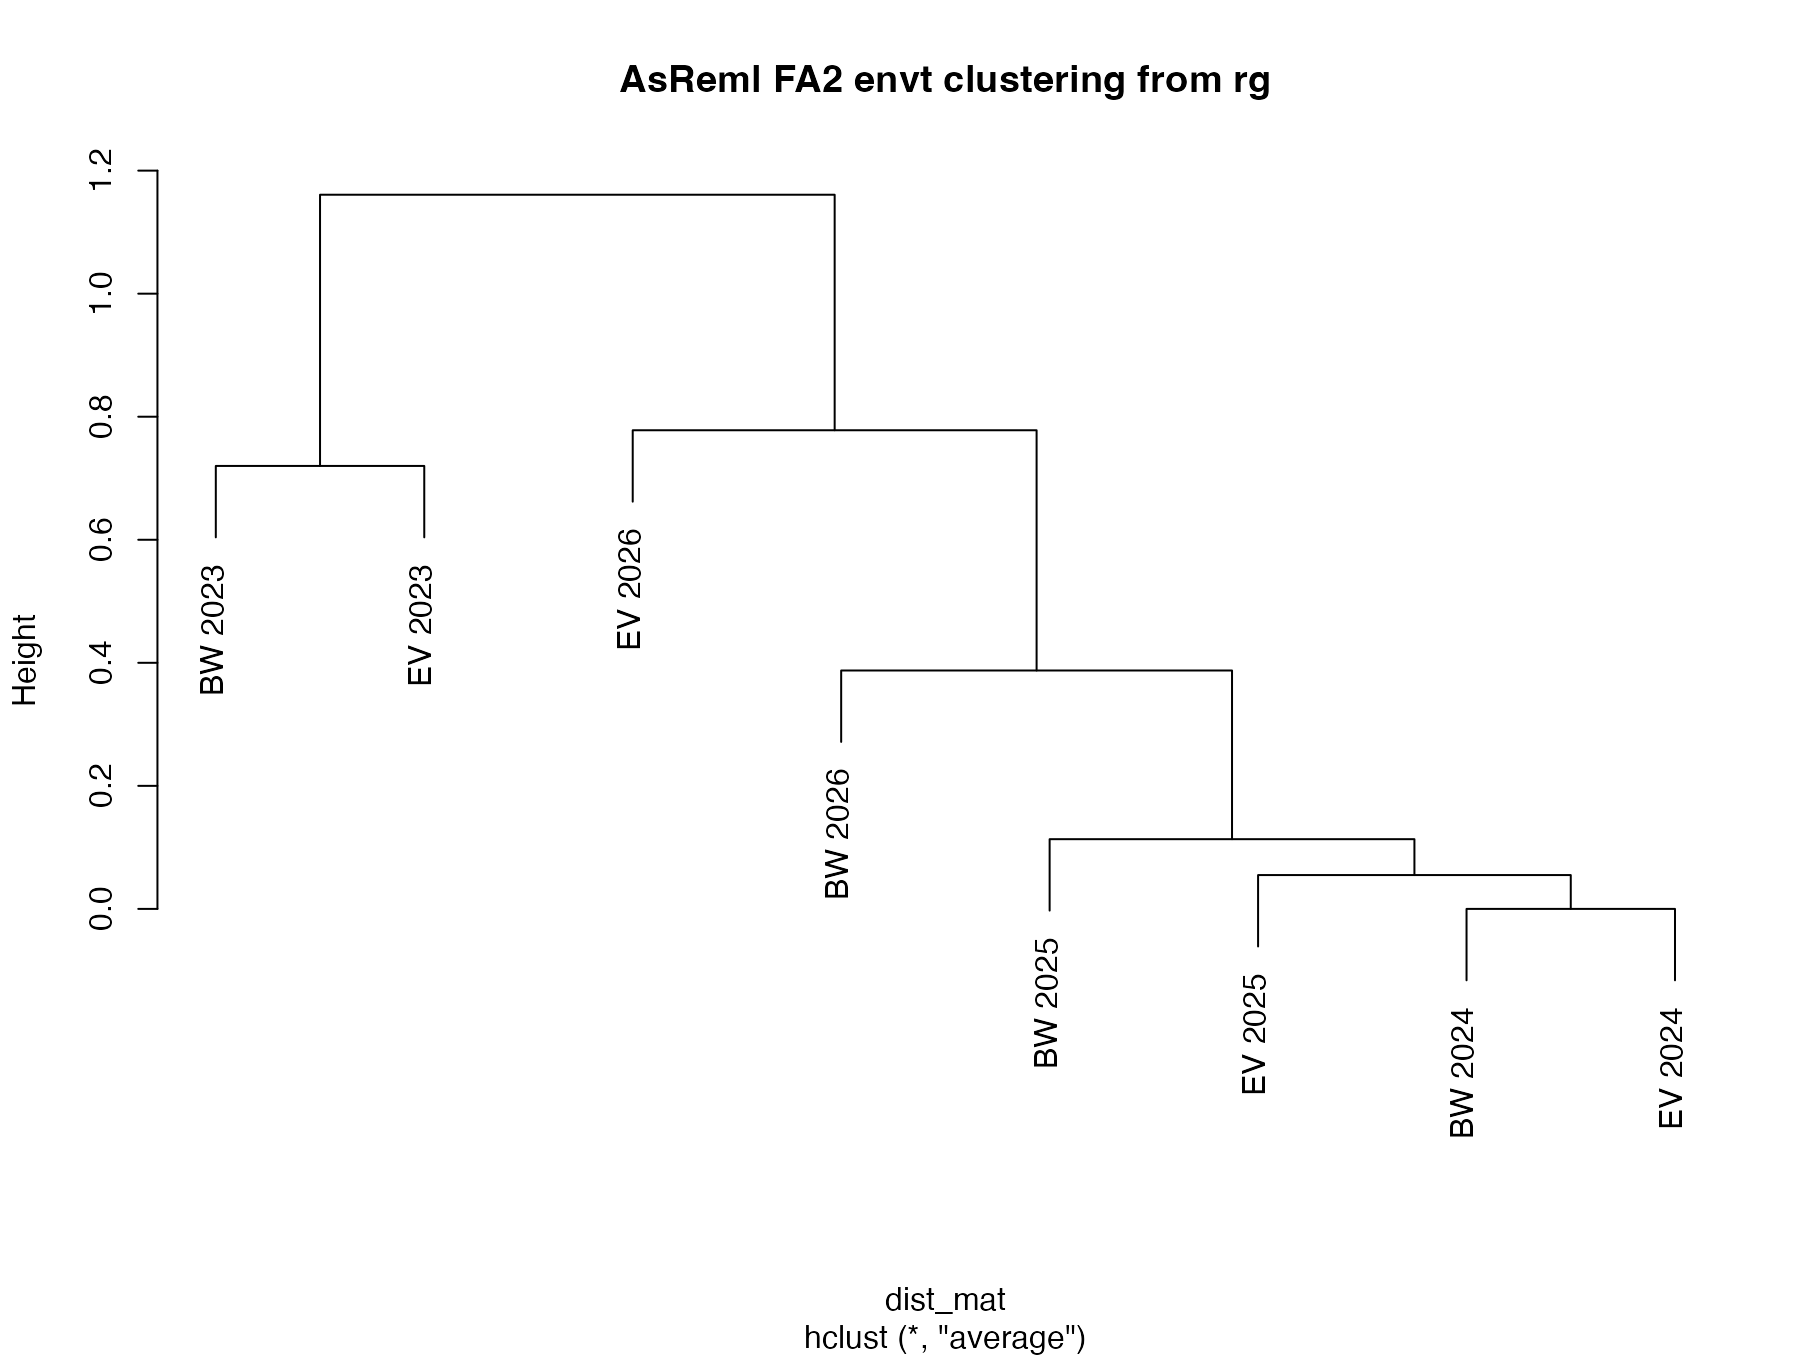

In [94]:
dist_mat <- as.dist(1 - rg_asr2)
hc <- hclust(dist_mat, method = "average")
plot(hc, main = "AsReml FA2 envt clustering from rg")

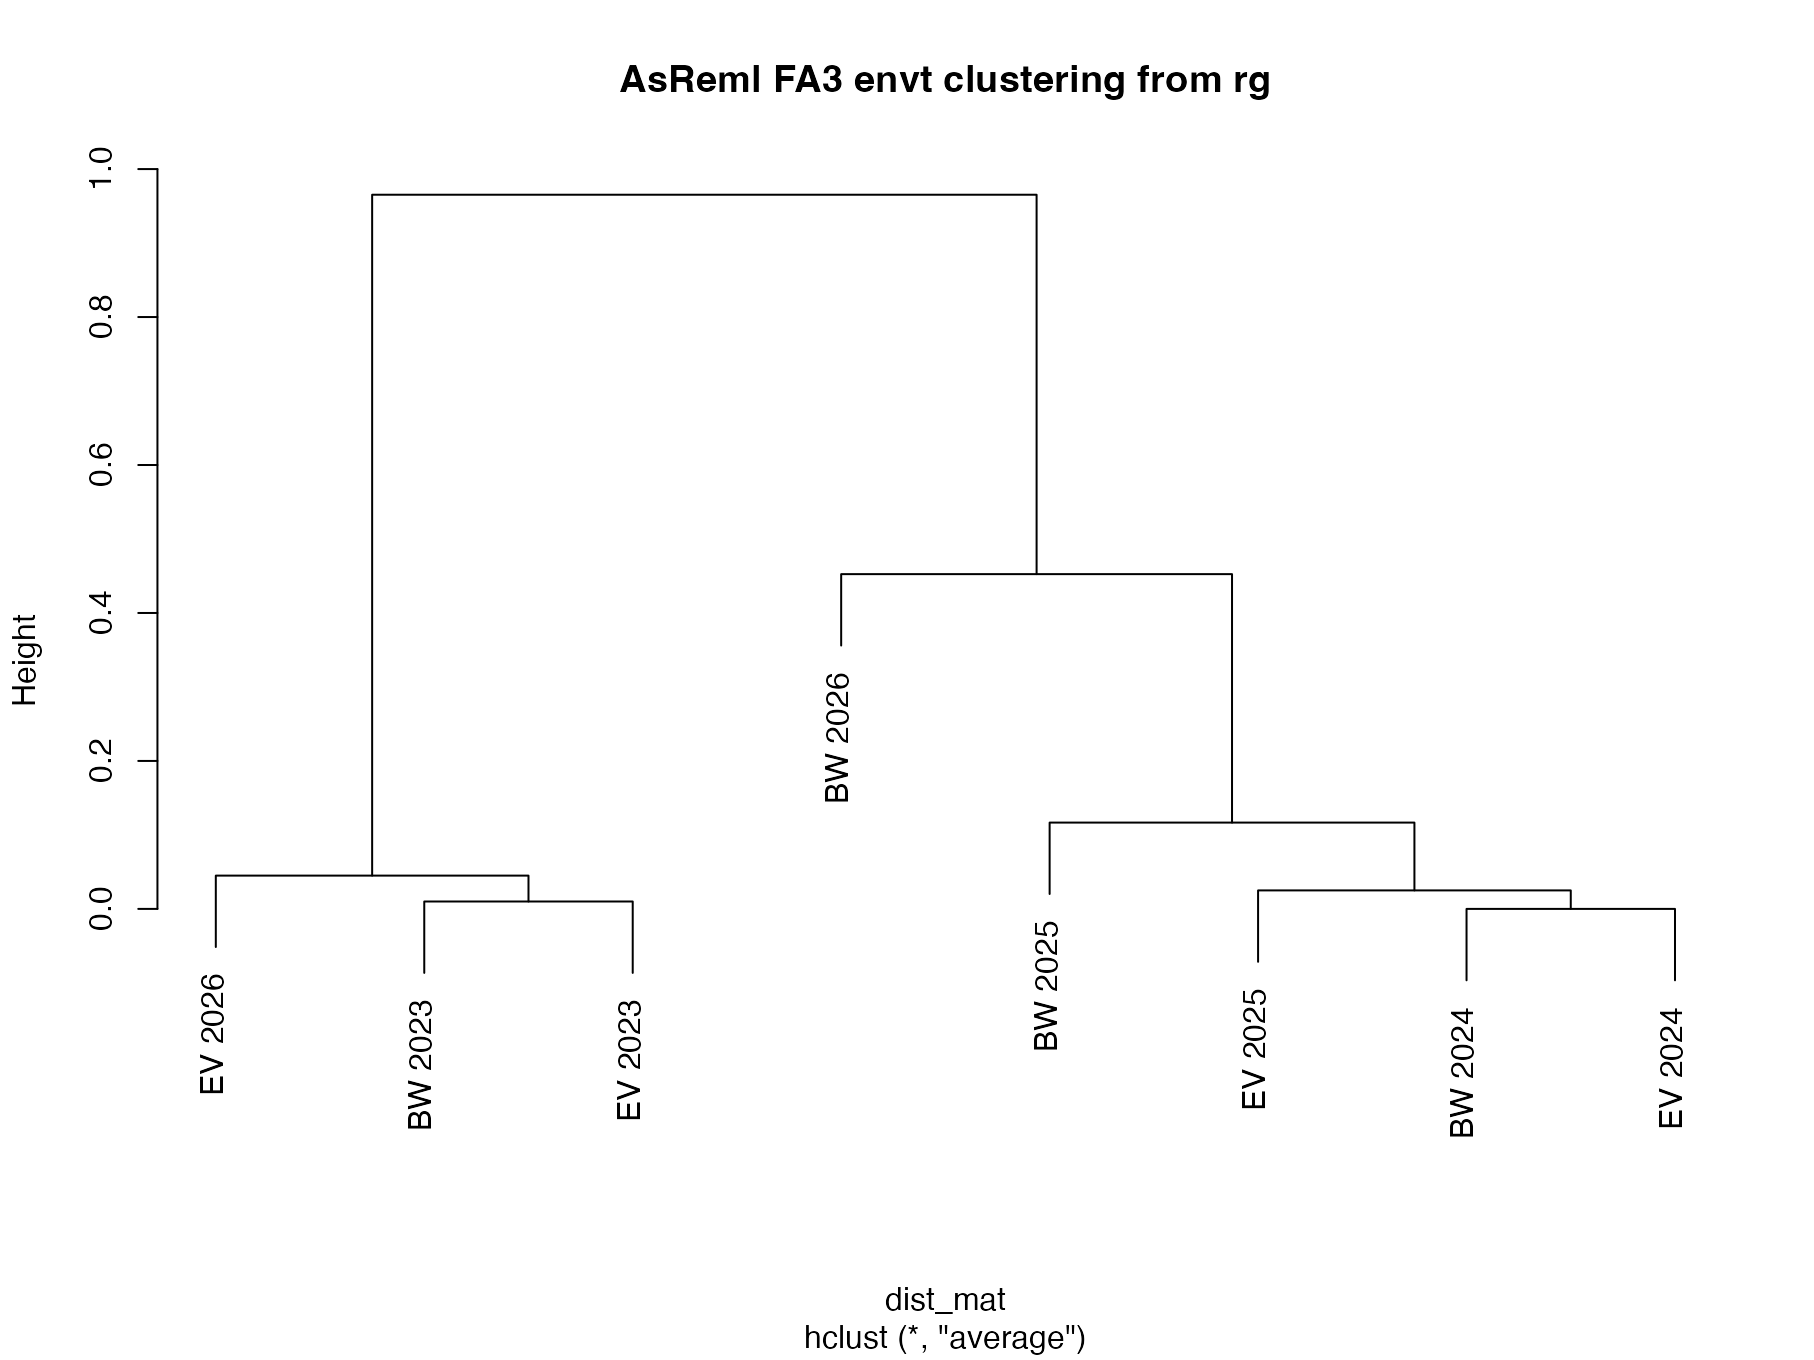

In [95]:
dist_mat <- as.dist(1 - rg_asr3)
hc <- hclust(dist_mat, method = "average")
plot(hc, main = "AsReml FA3 envt clustering from rg")

### Stability metrics

In [79]:
Ainv = ainv

In [334]:
dta = prep_dta(prep_y)
tested <- prep_y %>% distinct(Genotype, Env)
env_dta = dta %>%dplyr::select(Env, mean_env, sd_env) %>% distinct()

In [335]:

asr_cov <- extract_rg_matrix_asreml(
  varcomp     = summary(fit_fa3_asr)$varcomp,  
  env_levels  = env_levels,            
  n_factors   = 3
)$cov

blup_asr <- extract_blups_asreml(fit_fa3_asr)
# blups_org = back_transform_blups(blup_asr, env_dta)
L <- asreml_result3$L; rownames(L) <- env_levels   # your extract_rg_matrix_asreml() returns L unnamed
stab_asr <- fa_stability(blup_asr, loadings = L, tested = tested)

ASReml Version 4.2 08/10/2026 16:03:18
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -133.3817           1.0    693   16:03:18
  2     -133.3817           1.0    693   16:03:18
 3     -133.3816           1.0    693   16:03:18
ASReml Version 4.2 08/10/2026 16:03:18
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -133.3817           1.0    693   16:03:18
  2     -133.3817           1.0    693   16:03:18
 3     -133.3816           1.0    693   16:03:18


Warning messages:
1: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration
2: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration
Warning message:
In fa_stability(blup_asr, loadings = L, tested = tested) :
  Rotated first-factor loadings are NOT all positive (BW 2023). Smith & Cullis' OP assumes they are; read OP with caution.


In [322]:
stab_asr$var_explained  

[1] 0.64937035 0.28376189 0.06686776

In [323]:
stab_asr$pc1_loadings 

     BW 2023      BW 2024      BW 2025      BW 2026      EV 2023      EV 2024      EV 2025      EV 2026 
-0.057020925  0.988054585  0.860039689  0.369879669 -0.007330496  1.063987797  0.900418595  0.170016689 

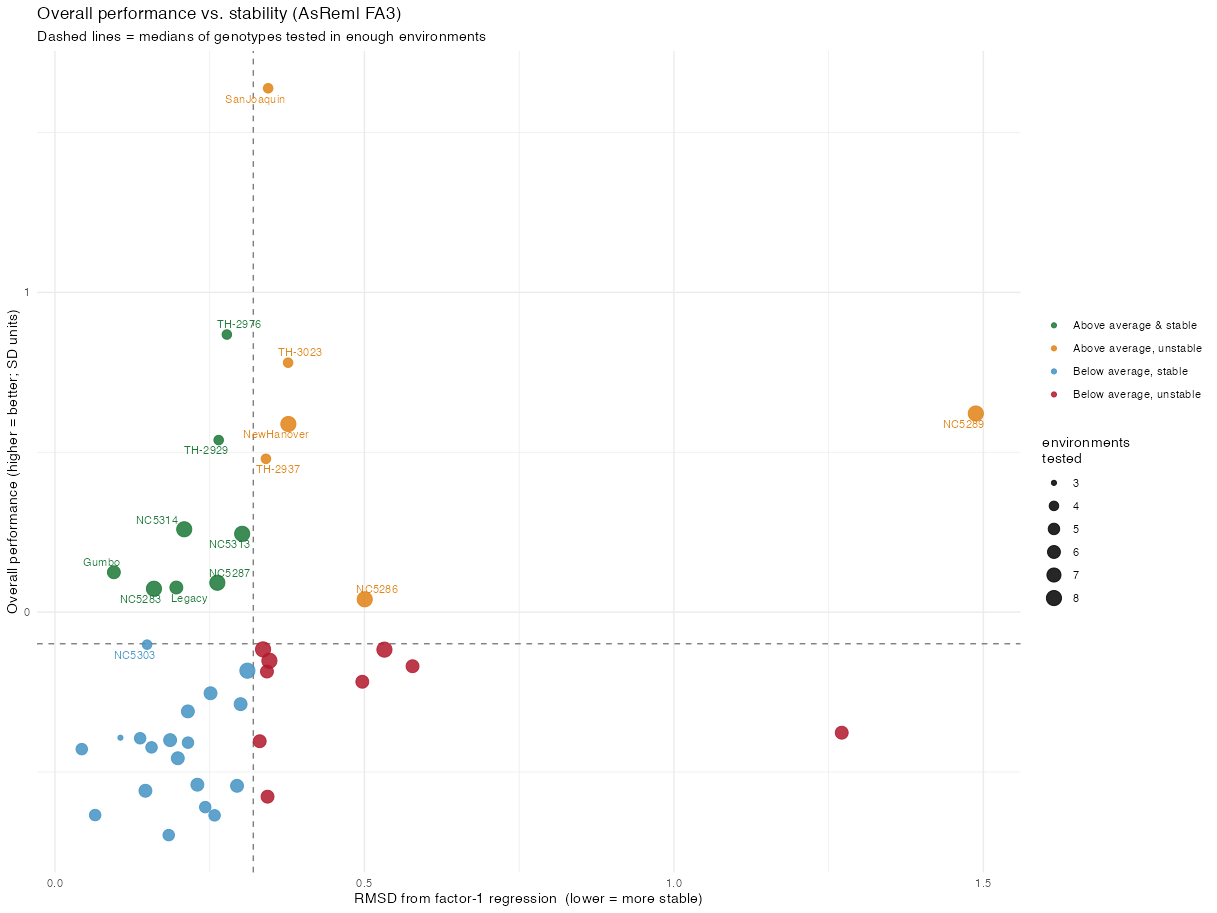

In [327]:
p31 = plot_op_rmsd(stab_asr, specs = 'AsReml FA3')
p31

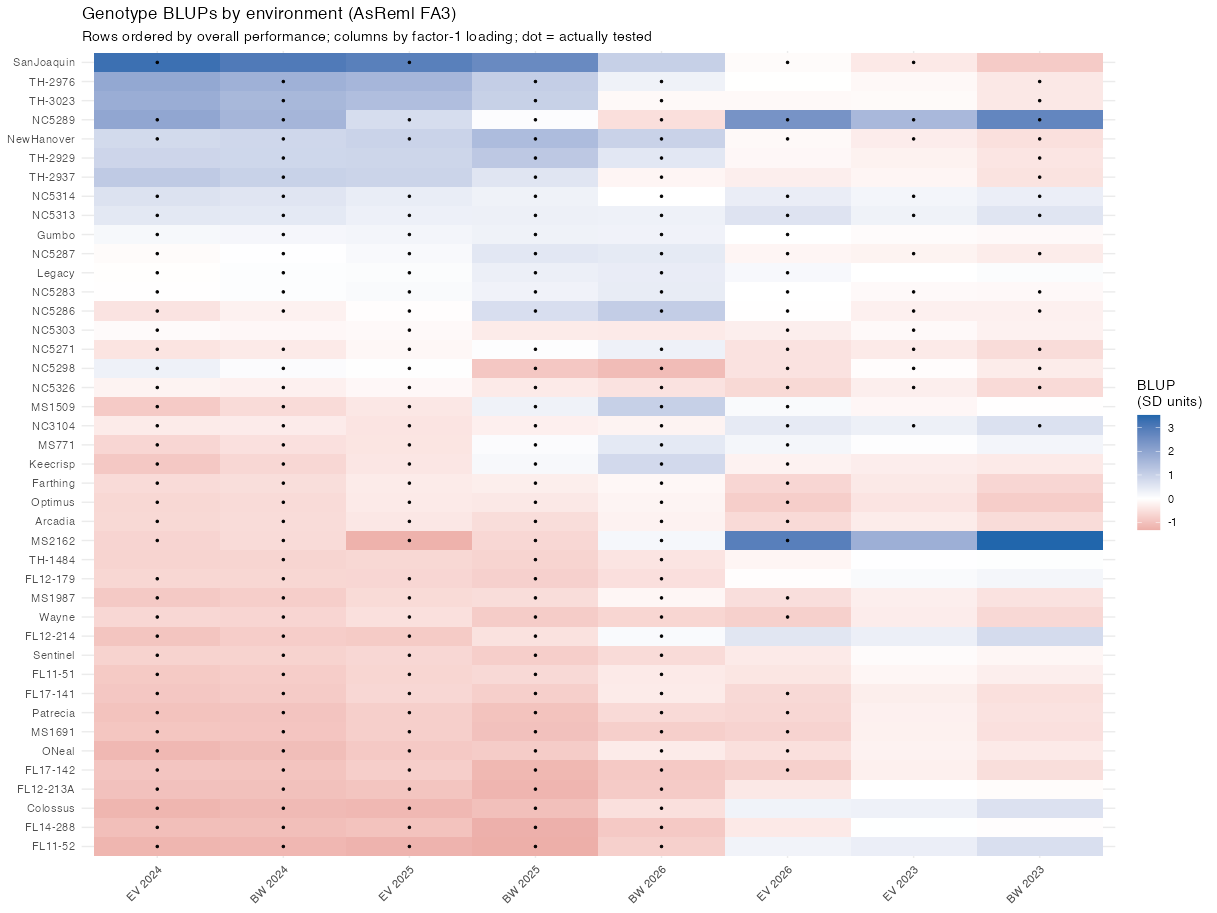

In [328]:
p32 = plot_blup_heatmap(blup_asr, stab_asr, tested, specs = 'AsReml FA3')
p32

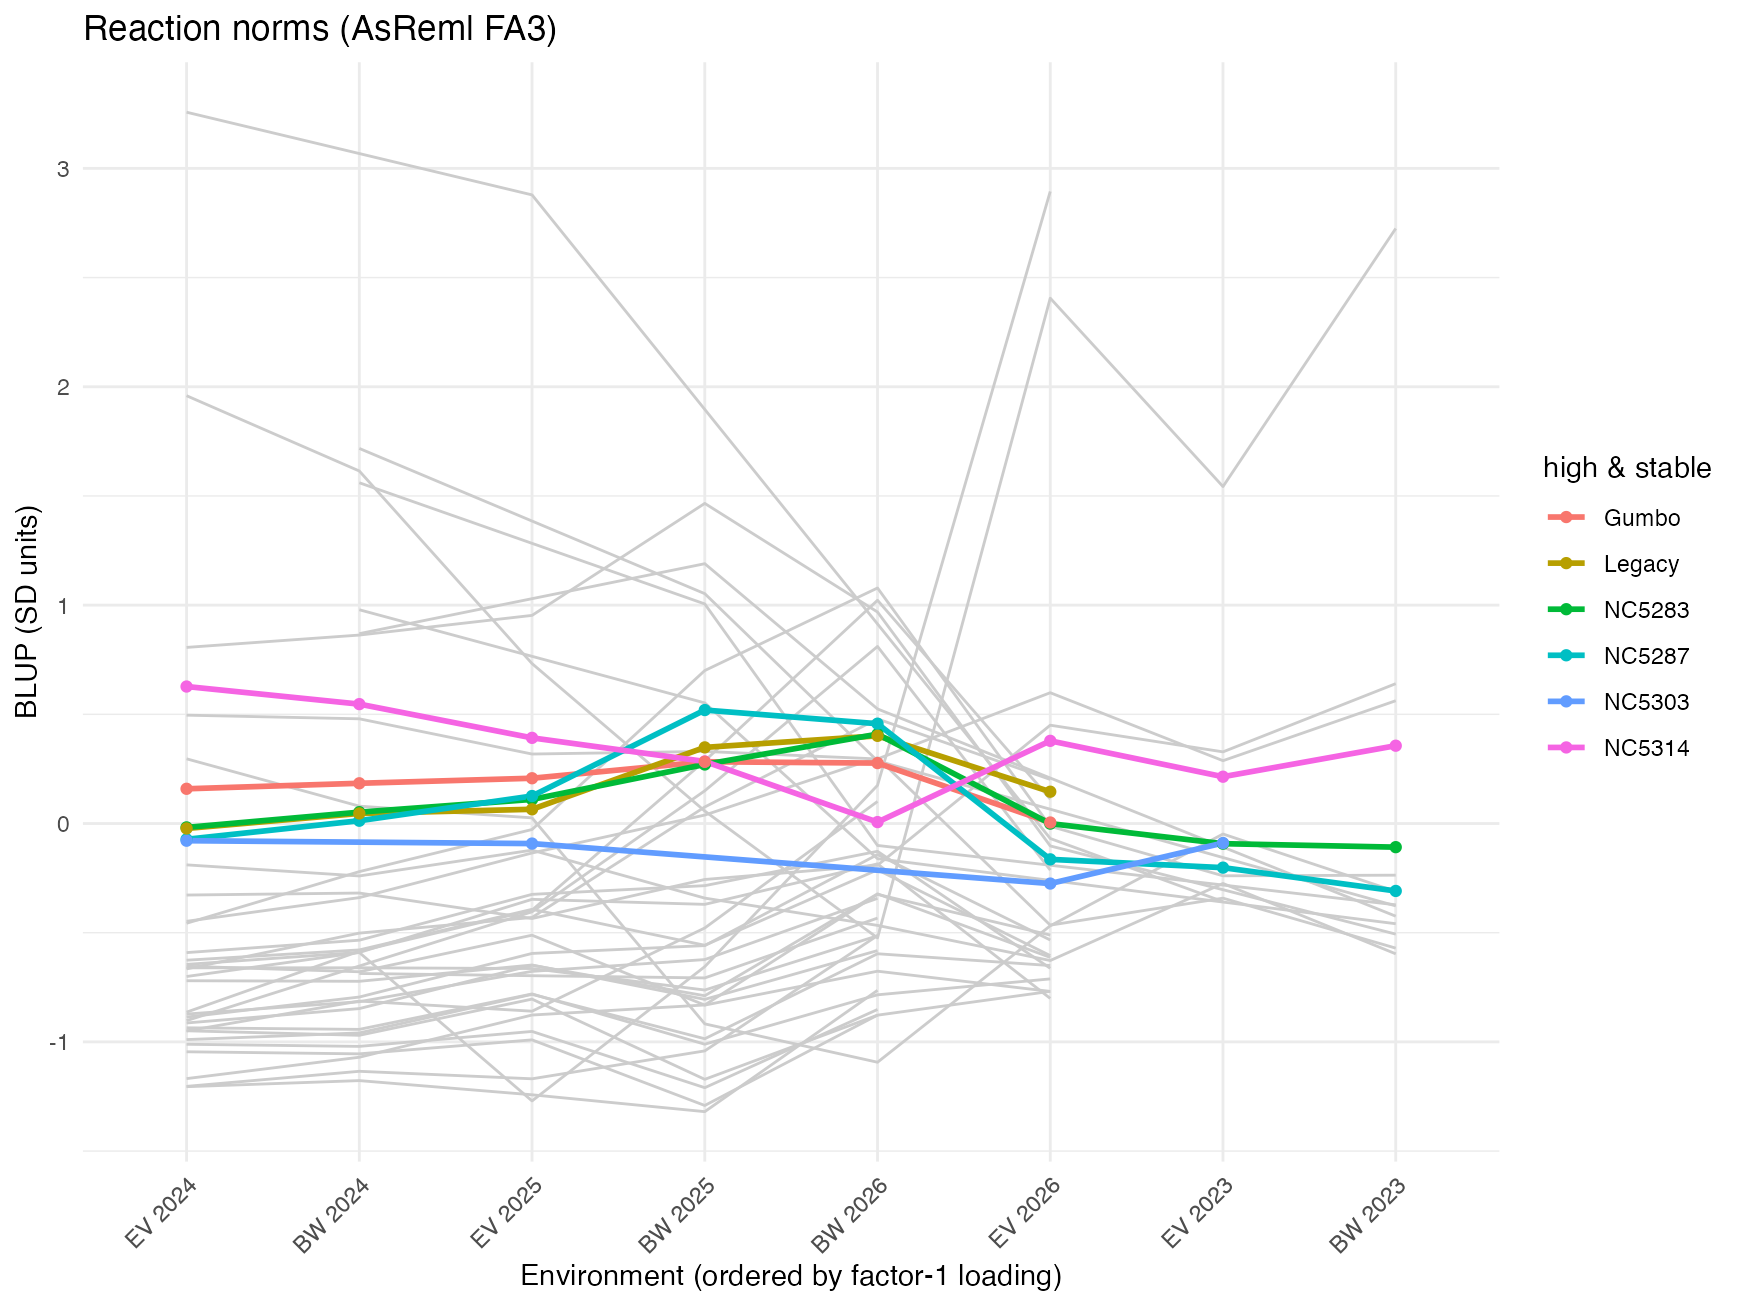

In [85]:
p33 = plot_reaction_norms(blup_asr, stab_asr, tested, specs = 'AsReml FA3')
p33

In [86]:
pc <- fa_pc_scores(blup_asr, loadings = L, tested = tested, n_pc = 3)   # n_pc = number of factors you fitted

In [87]:
round(pc$loadings, 2)    # which environments define each PC

          PC1   PC2   PC3
BW 2023 -0.06  0.90 -0.05
BW 2024  0.99  0.03 -0.13
BW 2025  0.86 -0.02  0.27
BW 2026  0.37  0.11  0.49
EV 2023 -0.01  0.45 -0.08
EV 2024  1.06  0.01 -0.24
EV 2025  0.90 -0.16 -0.05
EV 2026  0.17  0.78  0.04

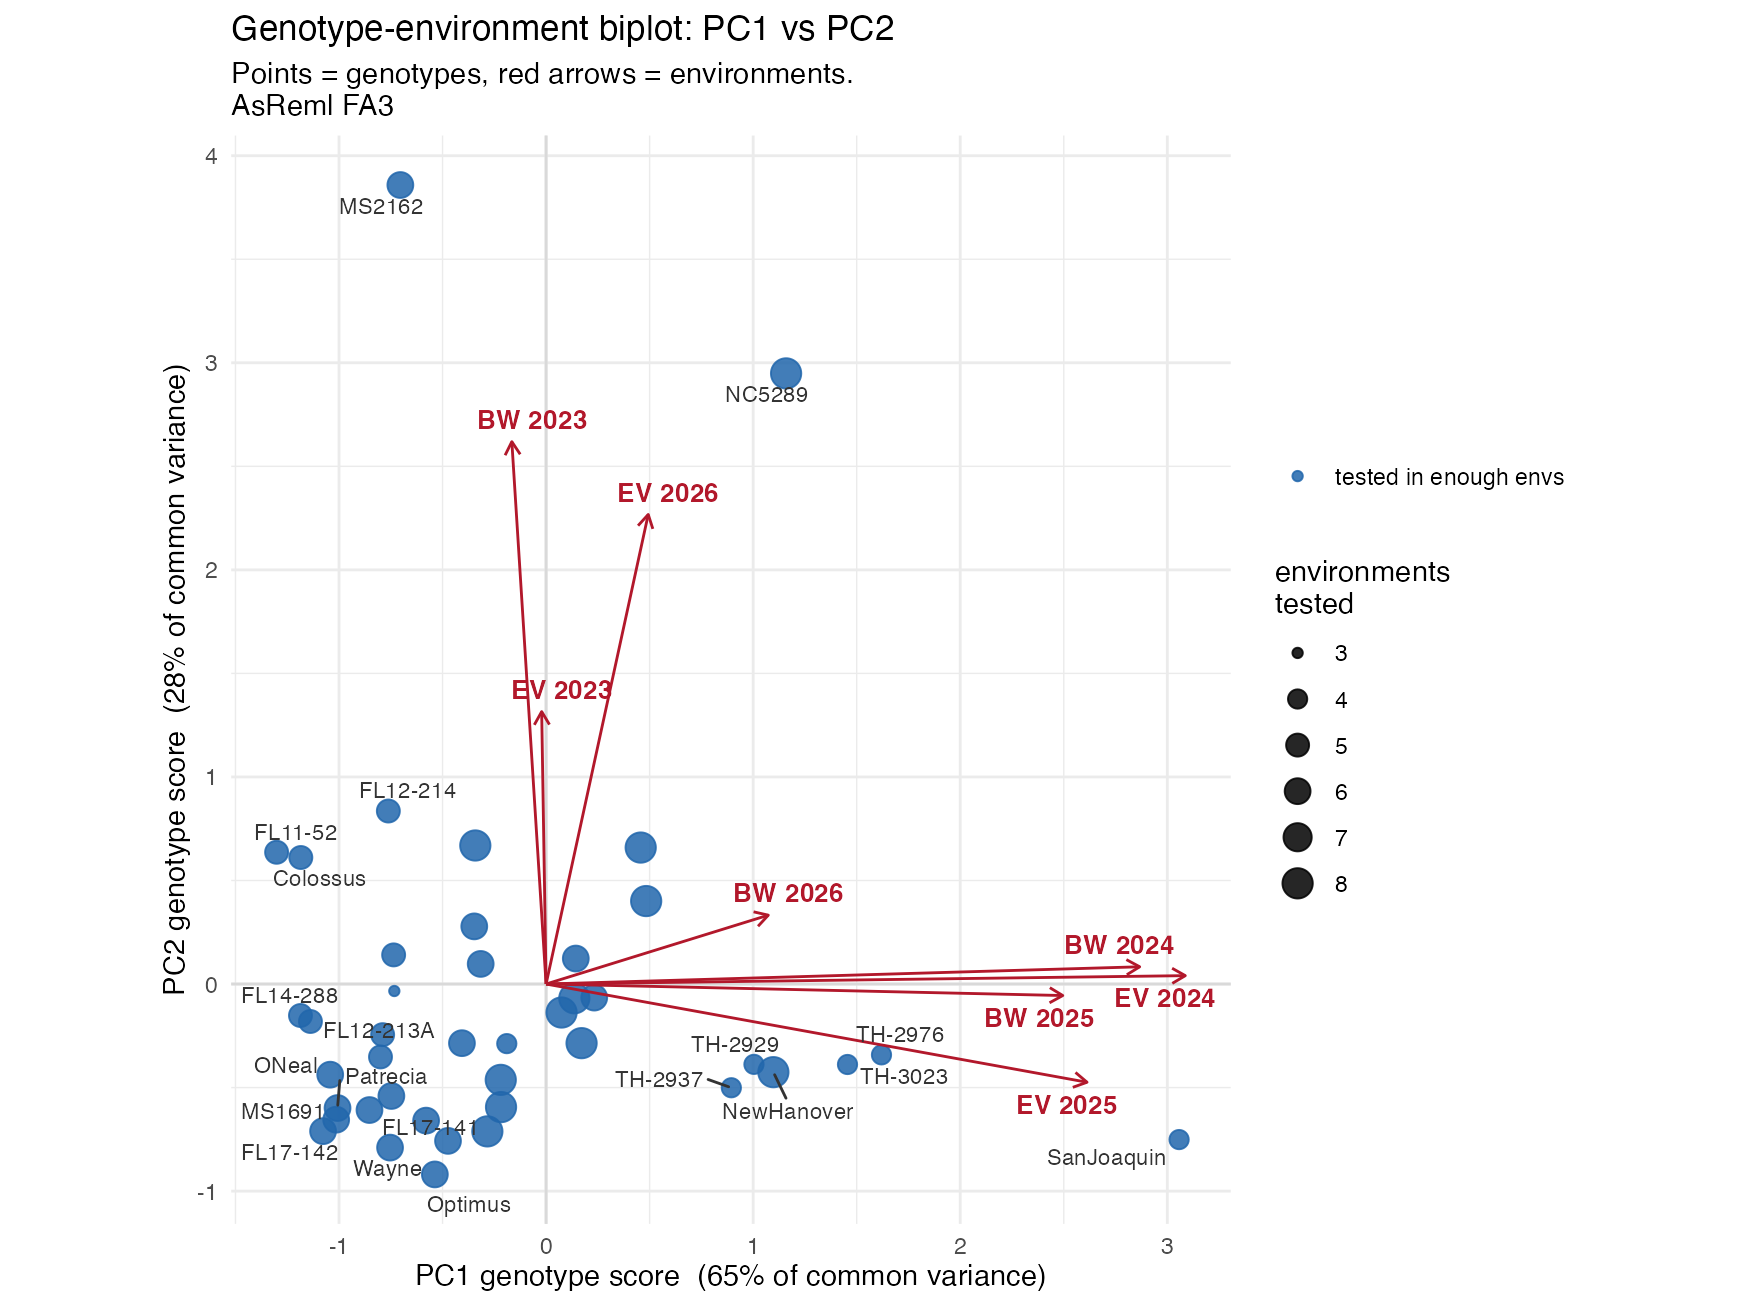

In [88]:
p34 = plot_fa_biplot(pc, pcs = c(1, 2), specs = 'AsReml FA3') 
p34

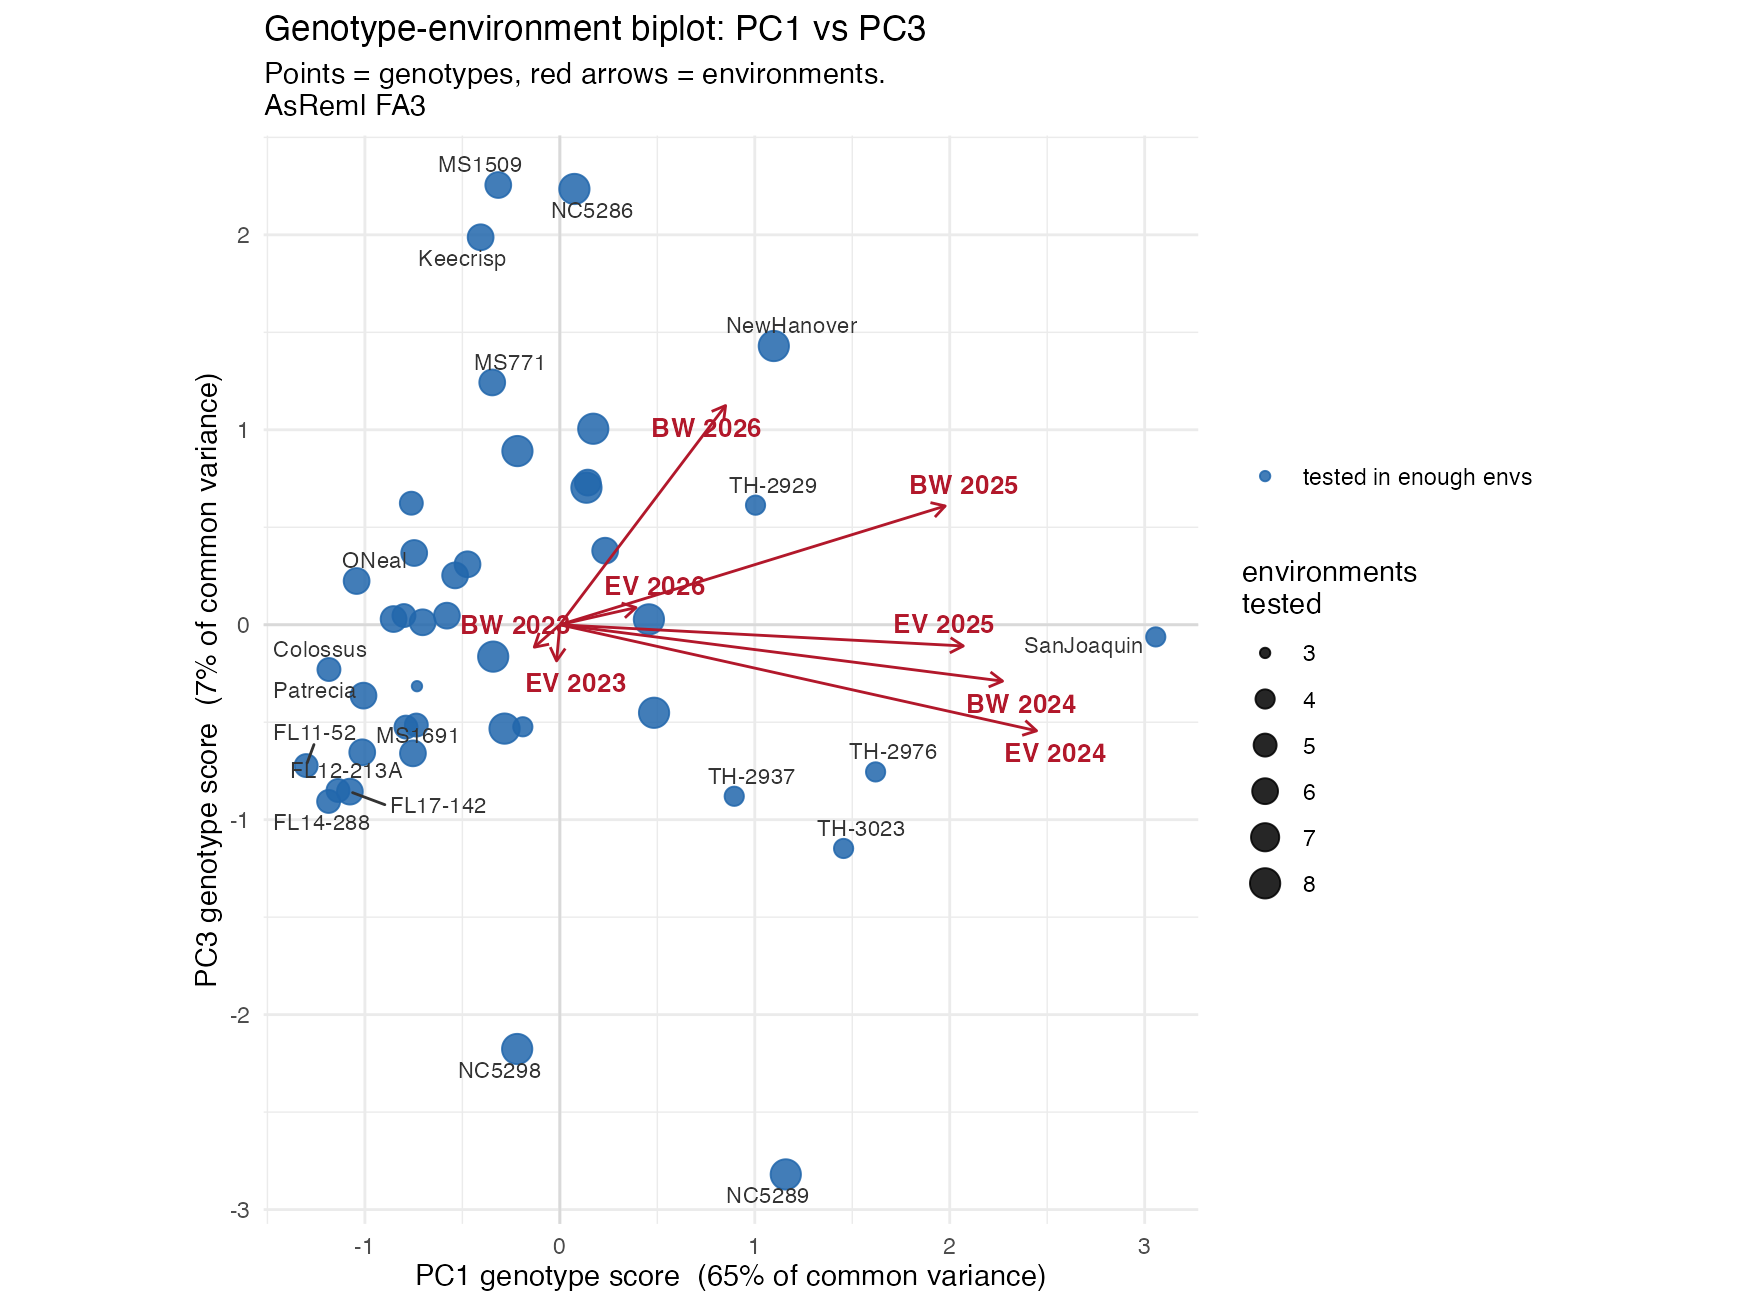

In [89]:
p35 = plot_fa_biplot(pc, pcs = c(1, 3), specs = 'AsReml FA3') 
p35

9 genotype(s) dropped: no tested environment in one of the groups


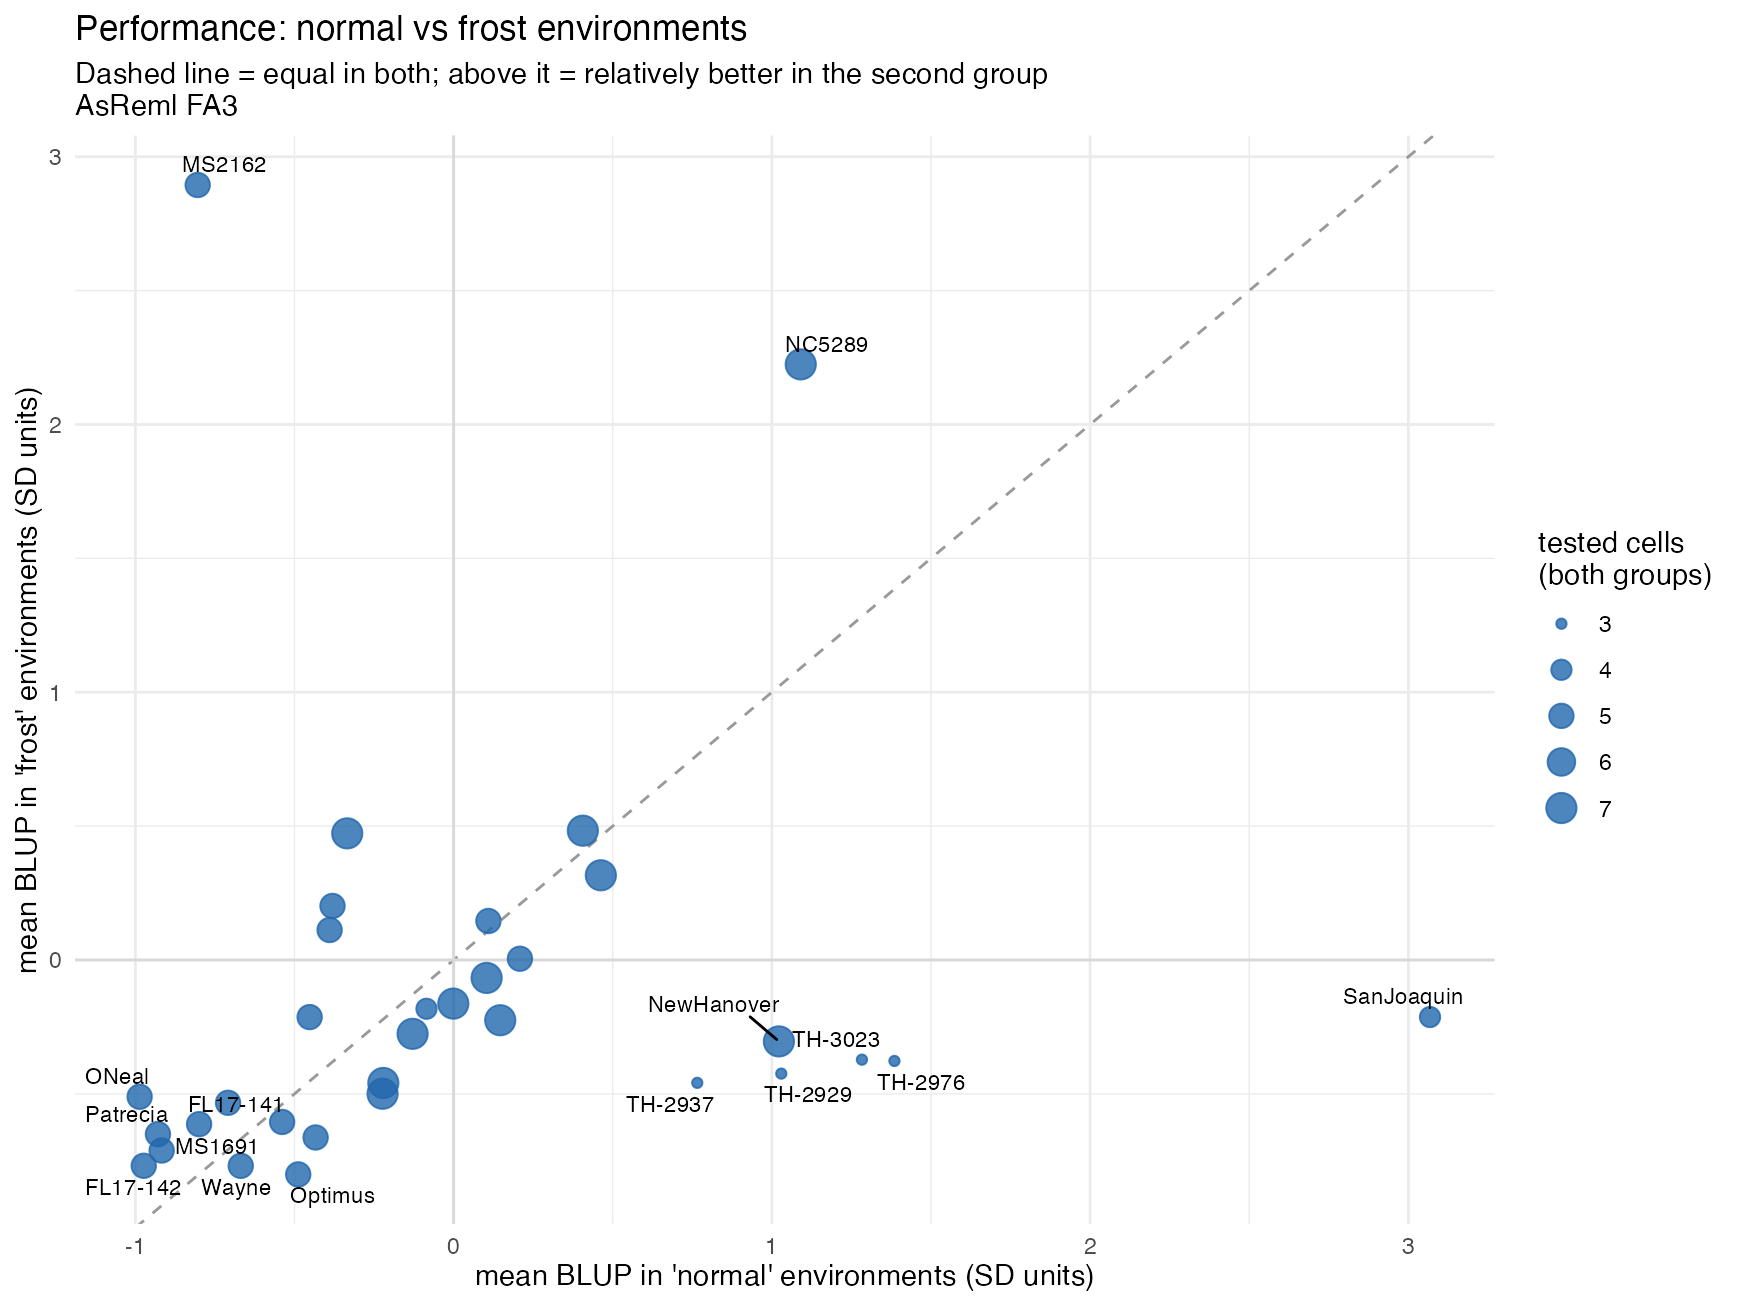

In [90]:
p36 = plot_group_means(blup_asr,
                 list(normal = c("BW 2024", "BW 2025", "EV 2024", "EV 2025"),
                      frost  = c("BW 2023", "EV 2023", "EV 2026")),
                 tested = tested, specs = 'AsReml FA3')
p36

In [337]:
rm(dta)

In [338]:
blup_asr2 <- extract_blups_asreml(fit_fa2_asr)
# blups_org2 = back_transform_blups(blup_asr2, env_dta)
L2 <- asreml_result2$L; rownames(L2) <- env_levels   # your extract_rg_matrix_asreml() returns L unnamed
stab_asr2 <- fa_stability(blup_asr2, loadings = L2, tested = tested)

: [1m[33mError[39m:[22m
[33m![39m object 'dta' not found

In [92]:
stab_asr2$var_explained  

[1] 0.8830102 0.1169898

In [93]:
stab_asr2$pc1_loadings 

    BW 2023     BW 2024     BW 2025     BW 2026     EV 2023     EV 2024     EV 2025     EV 2026 
-0.34072671  0.98924189  0.91637839  0.41685873  0.03719086  1.04125657  0.86110693  0.21555839 

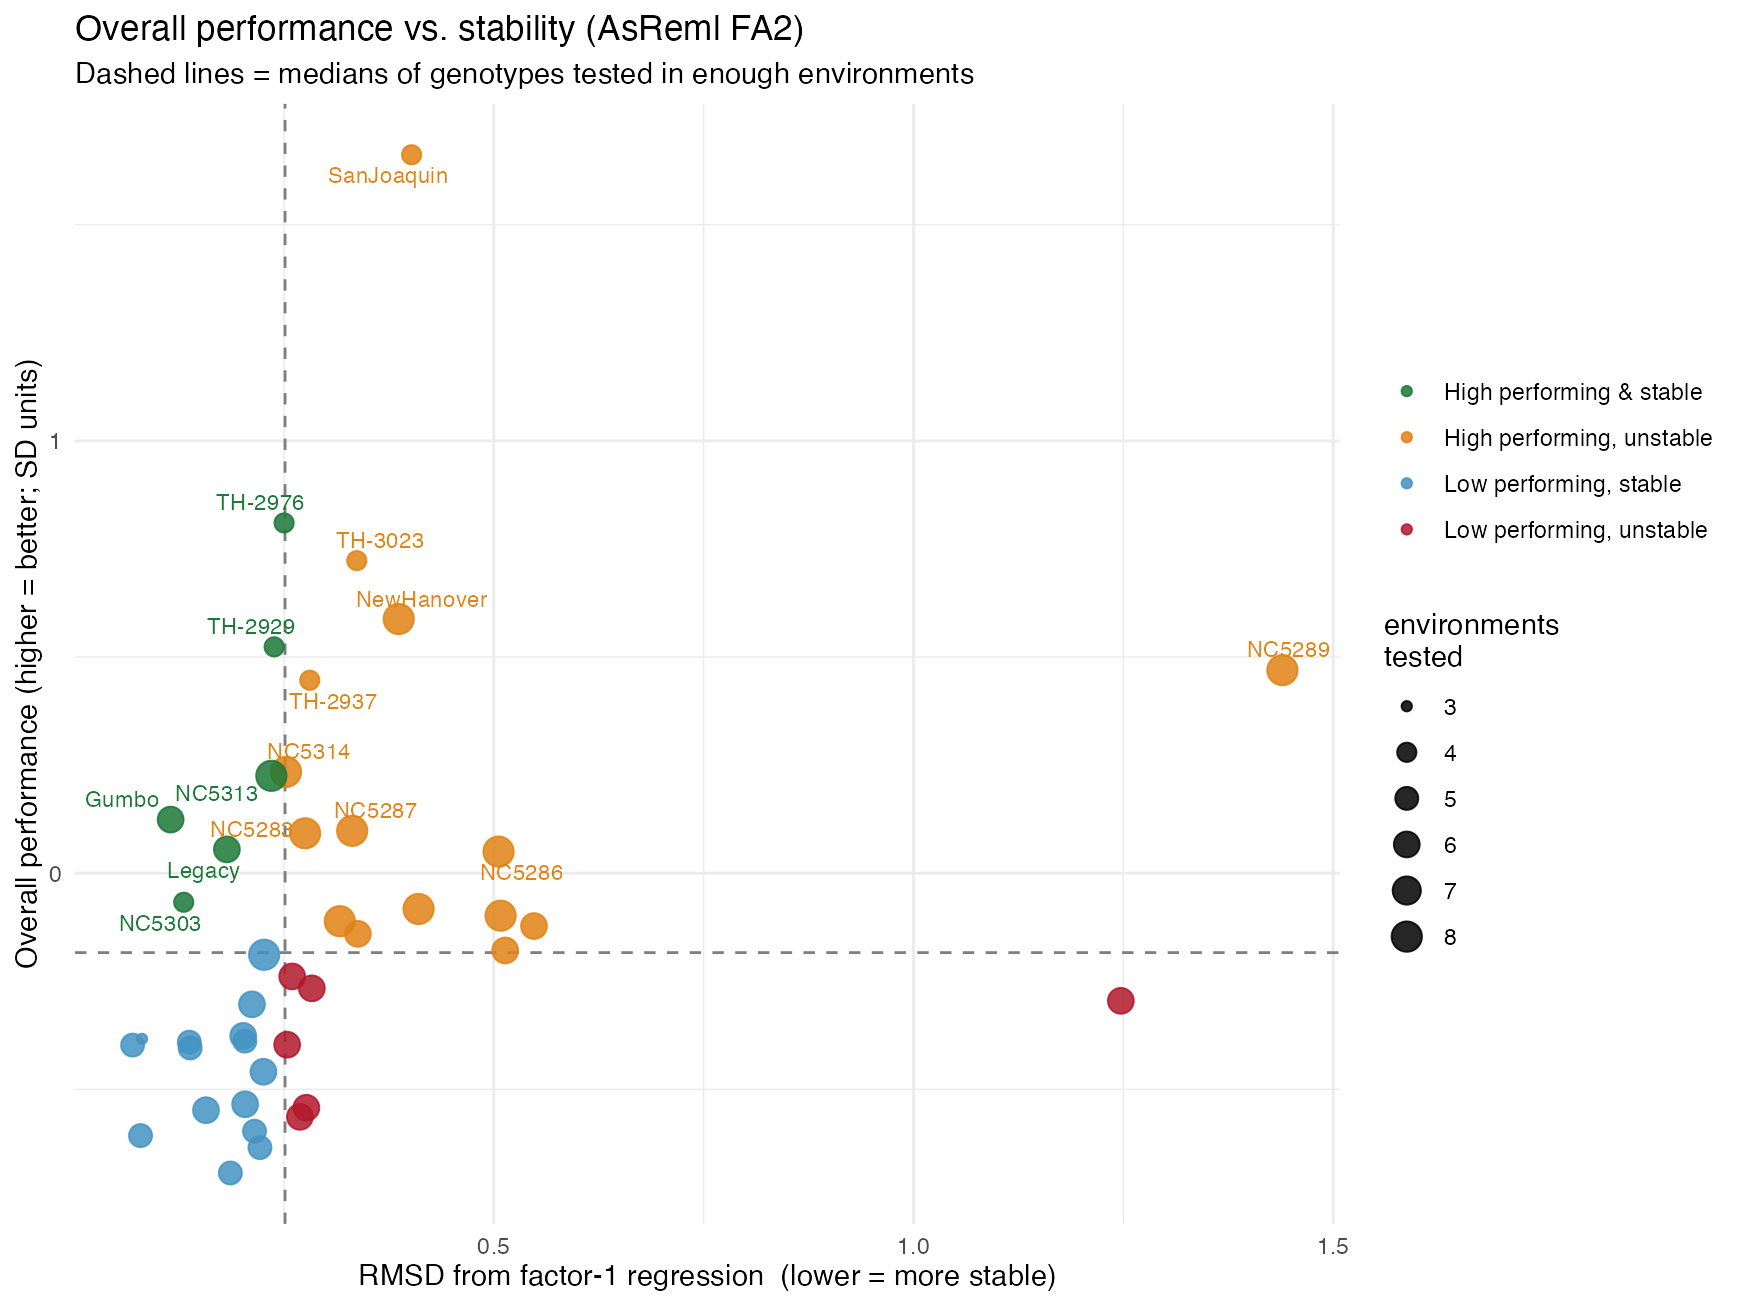

In [94]:
p21 = plot_op_rmsd(stab_asr2, spec = 'AsReml FA2')
p21

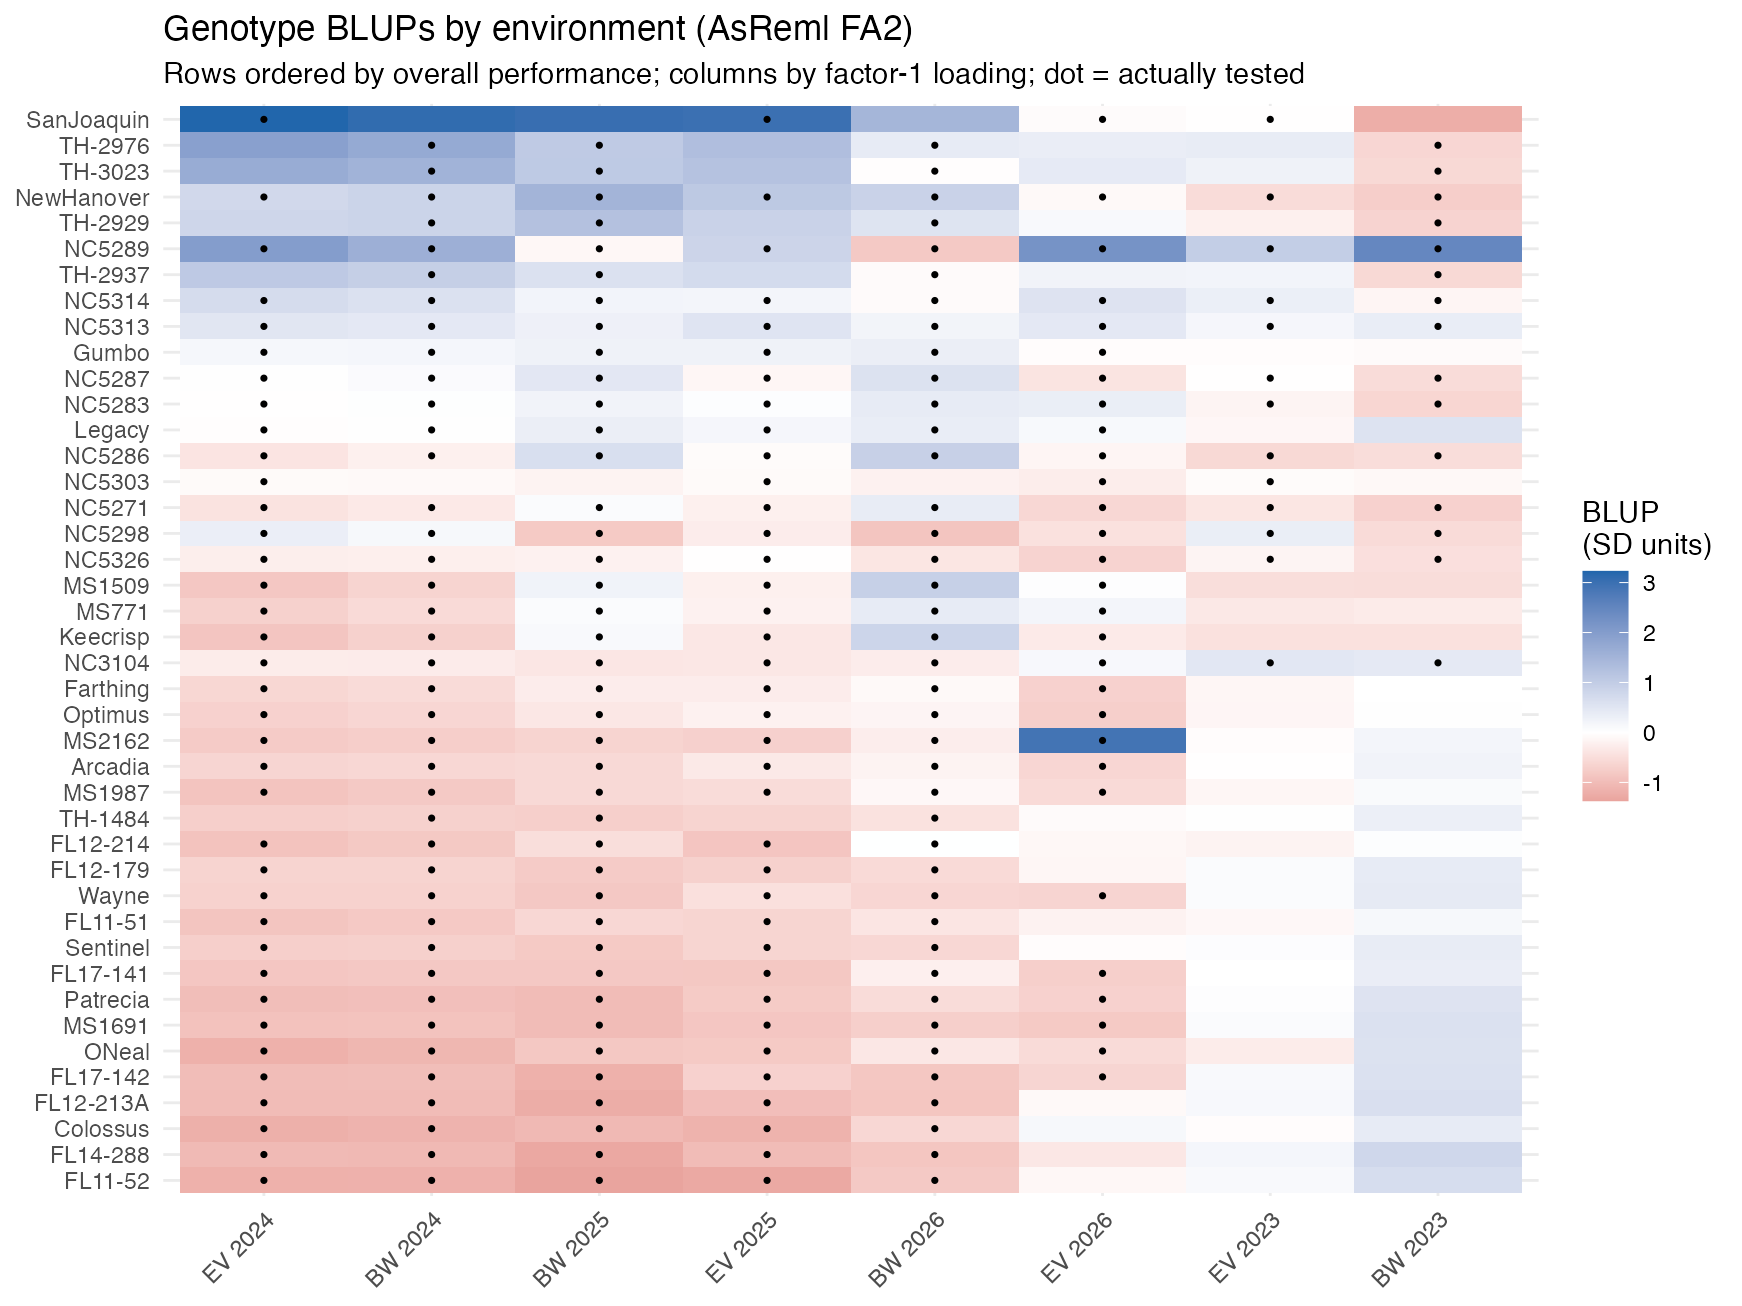

In [95]:
p22 = plot_blup_heatmap(blup_asr2, stab_asr2, tested, specs = 'AsReml FA2')
p22

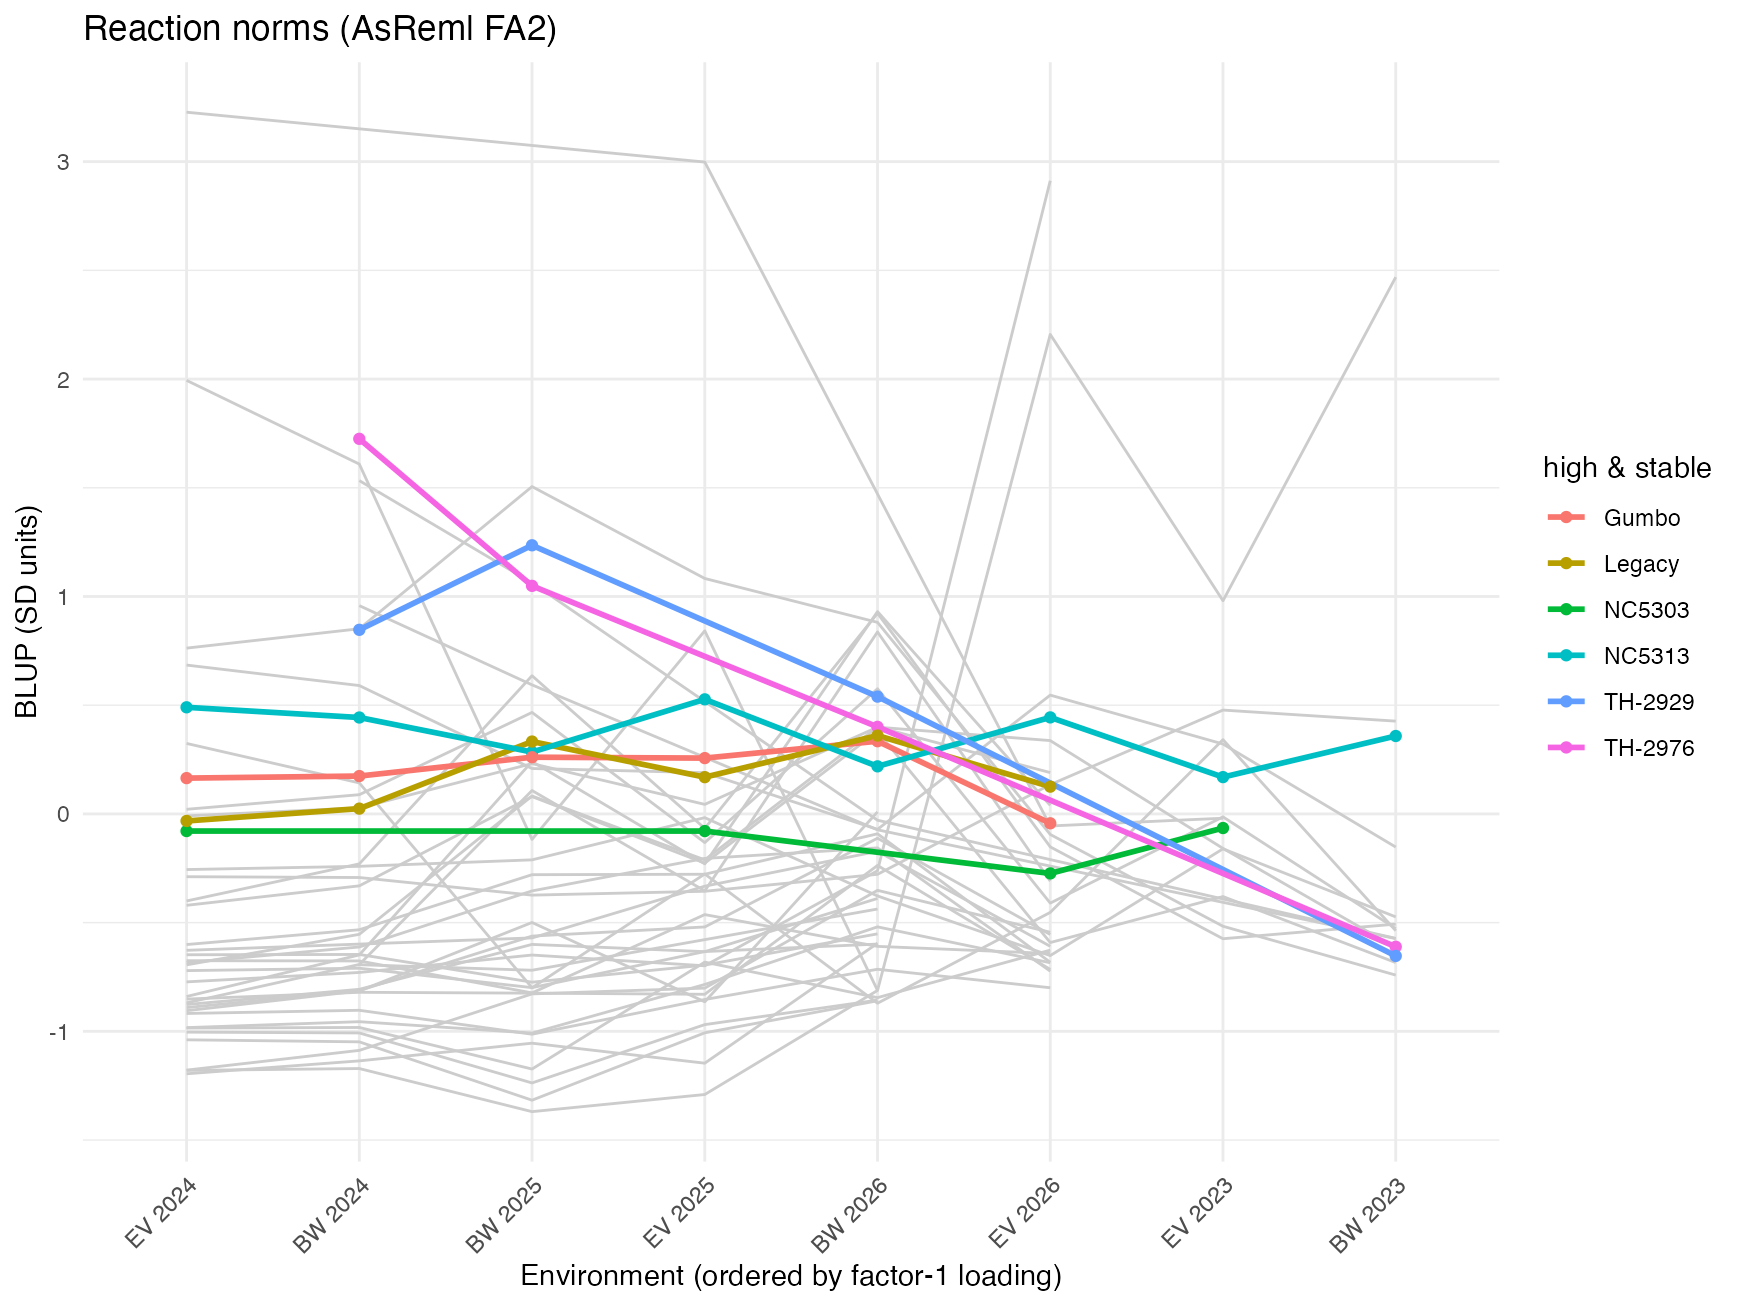

In [96]:
p23 = plot_reaction_norms(blup_asr2, stab_asr2, tested, specs = 'AsReml FA2')
p23

In [339]:
pc_asr2 <- fa_pc_scores(blup_asr2, loadings = L2, tested = tested, n_pc = 2)   # n_pc = number of factors you fitted


In [98]:
round(pc_asr2$loadings, 2)

          PC1   PC2
BW 2023 -0.34 -0.35
BW 2024  0.99 -0.19
BW 2025  0.92  0.27
BW 2026  0.42  0.37
EV 2023  0.04 -0.26
EV 2024  1.04 -0.28
EV 2025  0.86 -0.01
EV 2026  0.22 -0.09

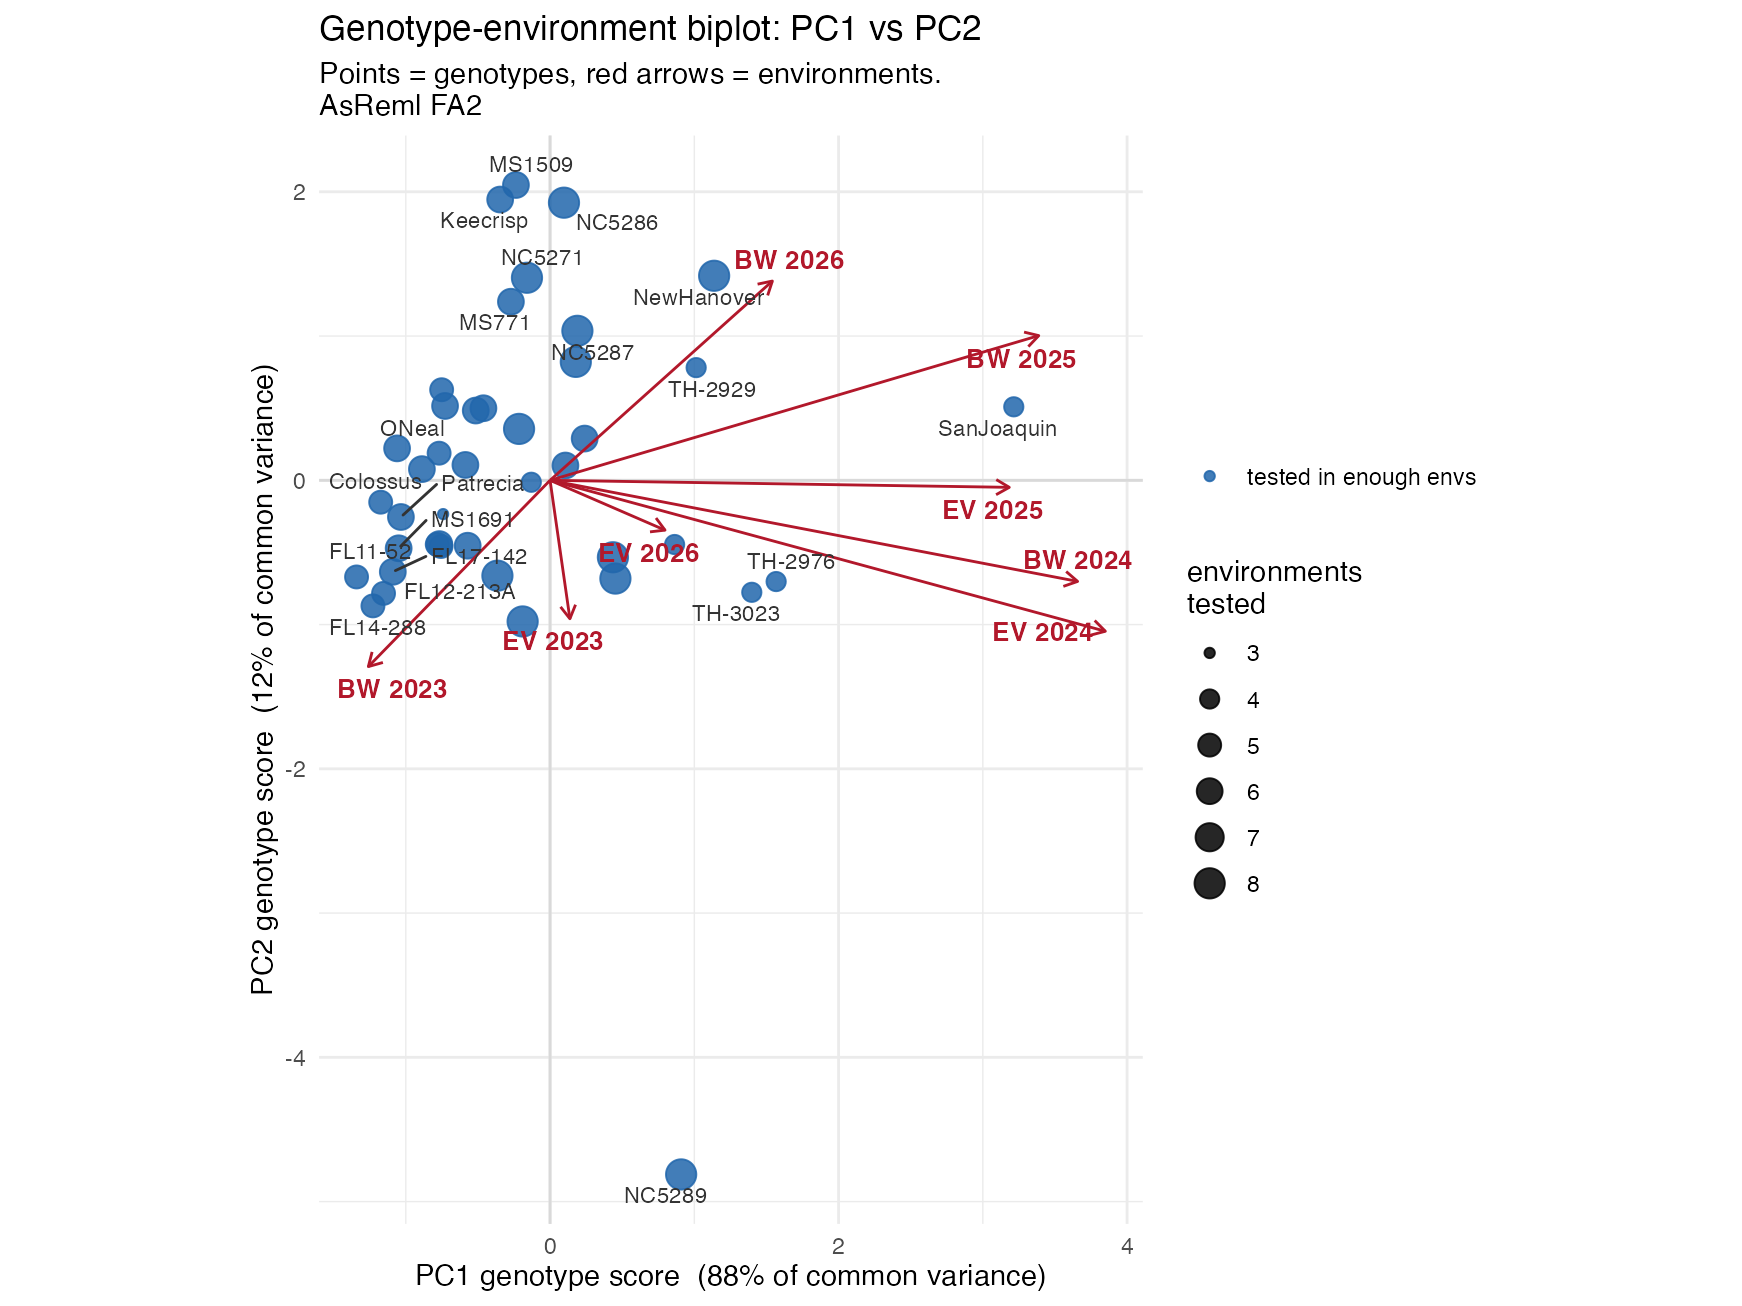

In [99]:
p24 = plot_fa_biplot(pc_asr2, pcs = c(1, 2), specs = 'AsReml FA2') 
p24

9 genotype(s) dropped: no tested environment in one of the groups


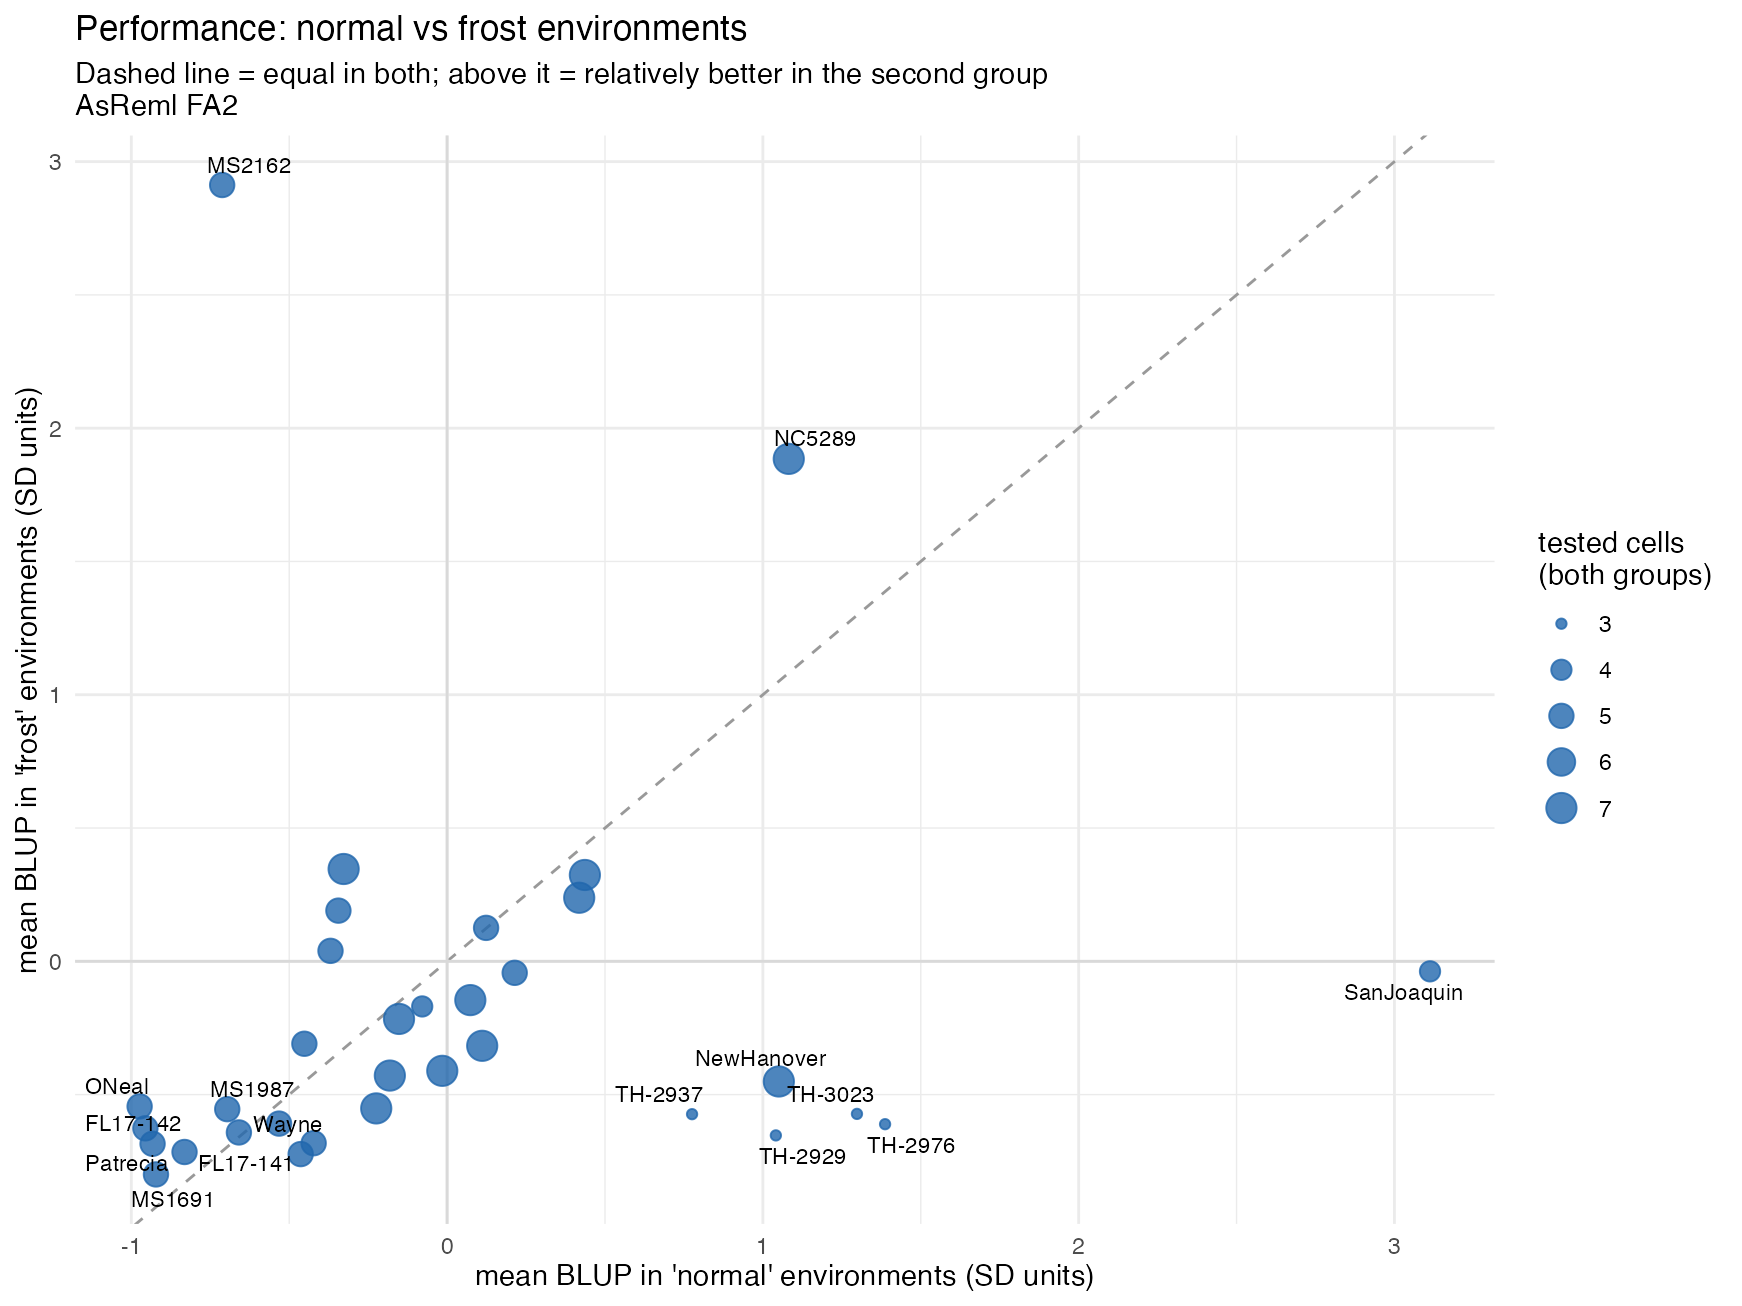

In [100]:
p25 = plot_group_means(blup_asr2,
                 list(normal = c("BW 2024", "BW 2025", "EV 2024", "EV 2025"),
                      frost  = c("BW 2023", "EV 2023", "EV 2026")),
                 tested = tested, specs = 'AsReml FA2')
p25

In [56]:
# quartz(width = 12, height = 8)

In [60]:
# (p21| p22 | p23 )/ (p24 | p25)

In [62]:
# (p31 | p32 | p33 )/ (p34 | p35| p36)

In [101]:
cor.test(stab_asr$table$OP, stab_asr2$table$OP, method = 'spearman')


	Spearman's rank correlation rho

data:  stab_asr$table$OP and stab_asr2$table$OP
S = 0, p-value < 2.2e-16
alternative hypothesis: true rho is not equal to 0
sample estimates:
rho 
  1 


In [102]:
cor.test(stab_asr$table$RMSD, stab_asr2$table$RMSD, method = 'spearman')


	Spearman's rank correlation rho

data:  stab_asr$table$RMSD and stab_asr2$table$RMSD
S = 3920, p-value = 1.486e-06
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
0.6823596 


### Sommer

In [336]:
blup_sm2 <- extract_blups_sommer(fit_fa2_sm)
# blups_orig_sm2 = back_transform_blups(blup_sm2, env_dta)
stab_sm2 <- fa_stability(blup_sm2, loadings = loadings_mmes(fit_fa2_sm)$loadings, tested = tested)

In [47]:
stab_sm2$var_explained  

[1] 0.723295 0.276705

In [48]:
stab_sm2$pc1_loadings 

  BW 2023   BW 2024   BW 2025   BW 2026   EV 2023   EV 2024   EV 2025   EV 2026 
0.3683769 1.0135125 0.6953567 0.2048349 0.1542628 1.1048522 0.9565130 0.2858511 

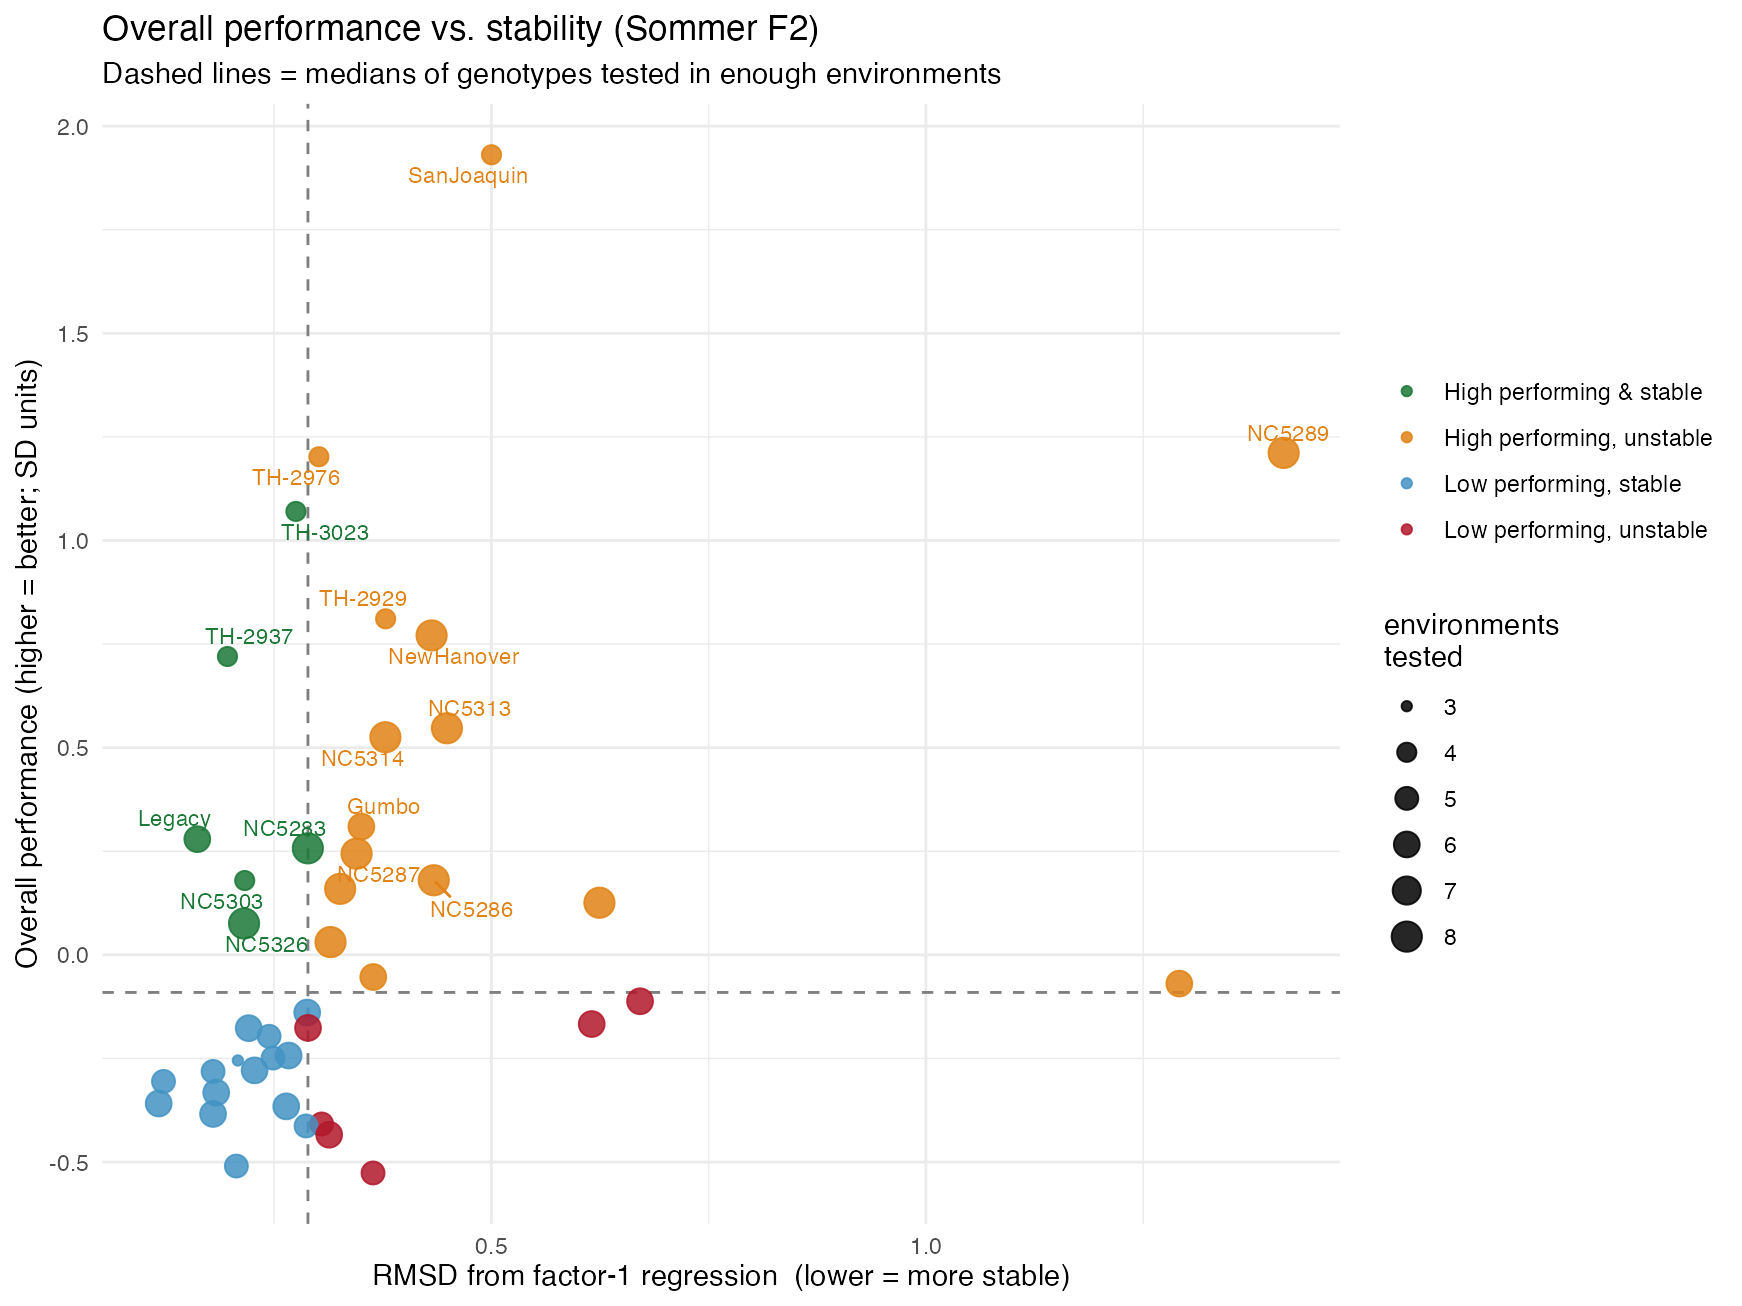

In [49]:
s21 = plot_op_rmsd(stab_sm2, specs = 'Sommer F2')
s21

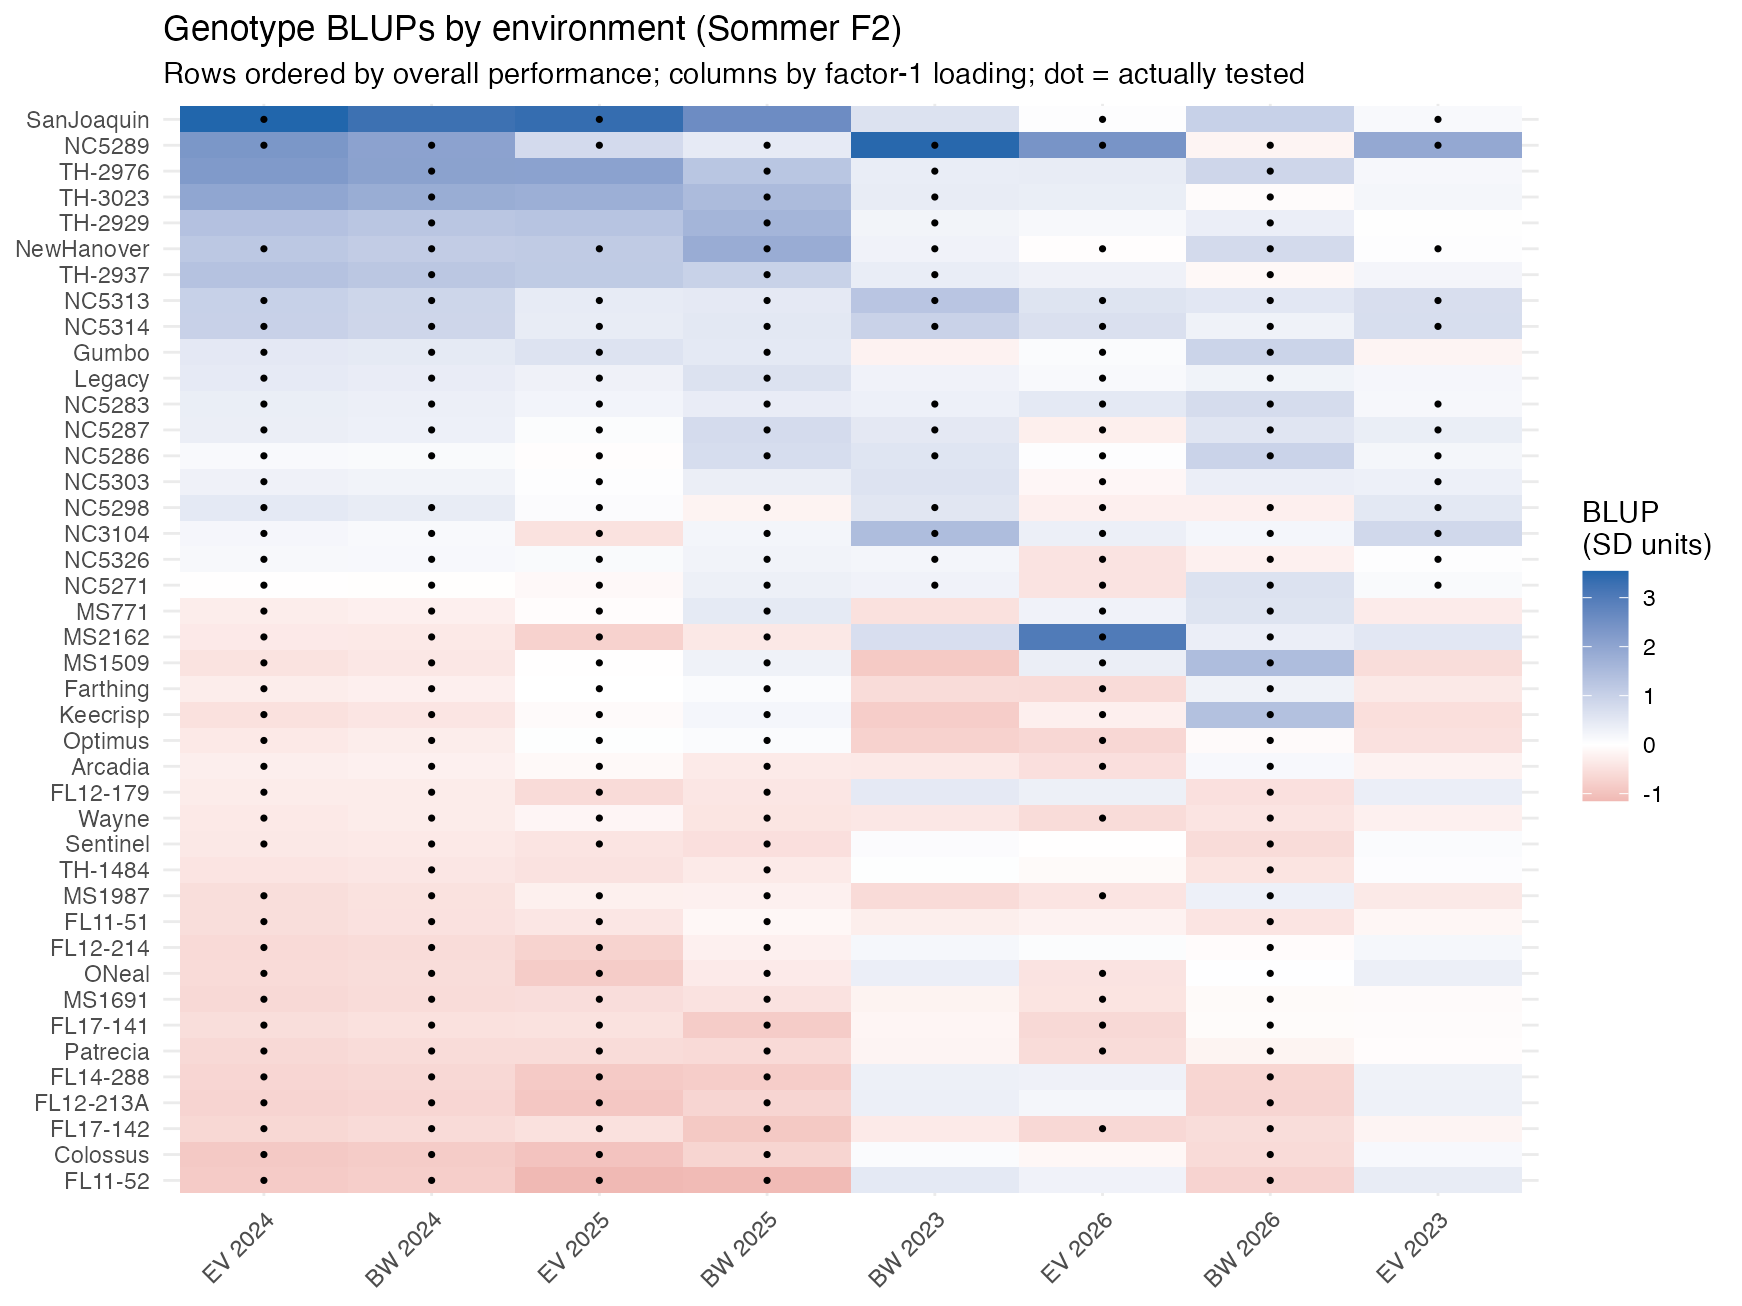

In [50]:
s22 = plot_blup_heatmap(blup_sm2, stab_sm2, tested, specs = 'Sommer F2')
s22

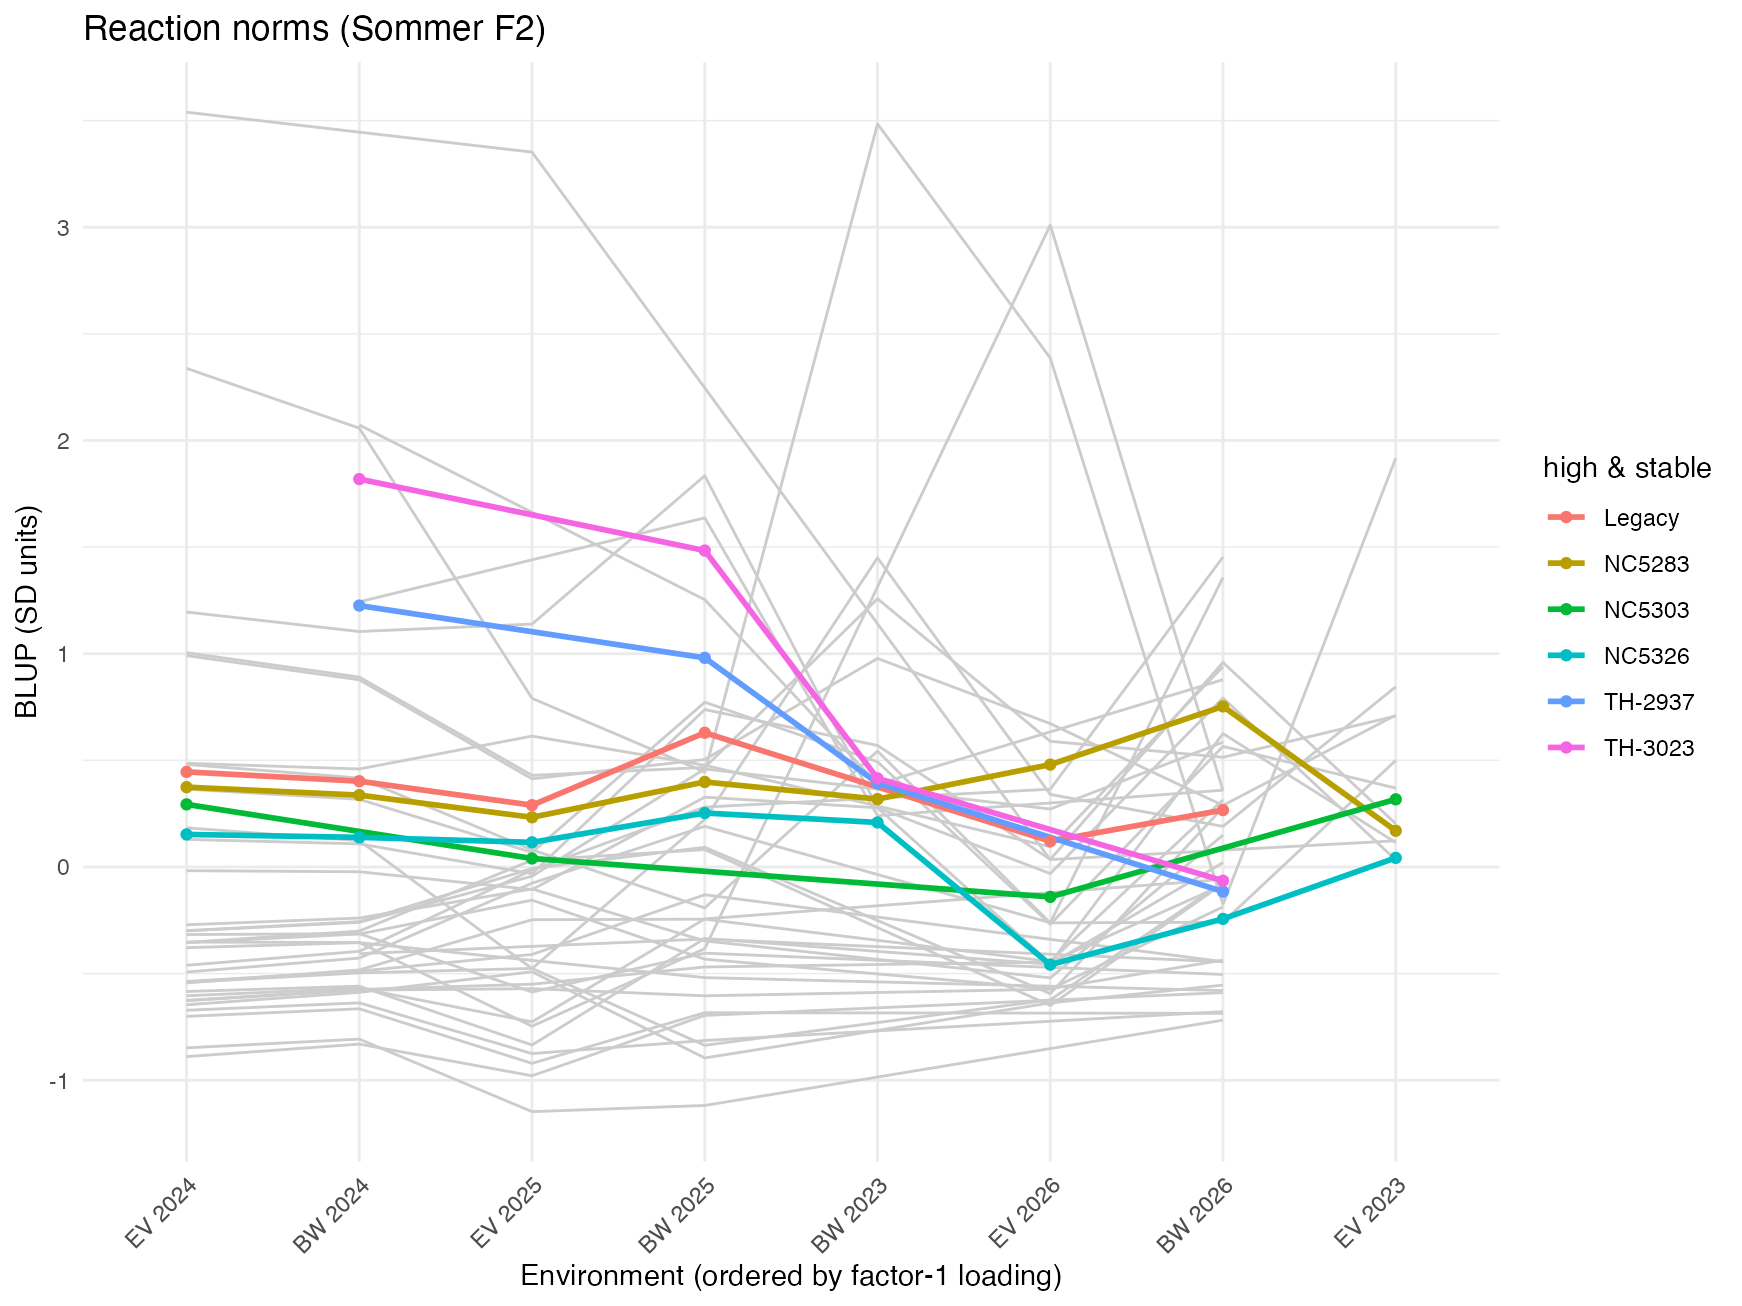

In [51]:
s23 = plot_reaction_norms(blup_sm2, stab_sm2, tested, specs = 'Sommer F2')
s23

In [54]:
pc_sm2 <- fa_pc_scores(blup_sm2, loadings = loadings_mmes(fit_fa2_sm)$loadings, tested = tested, n_pc = 2)   # n_pc = number of factors you fitted


In [55]:
round(pc_sm2$loadings, 2)

         PC1   PC2
BW 2023 0.37  0.76
BW 2024 1.01  0.03
BW 2025 0.70 -0.33
BW 2026 0.20 -0.33
EV 2023 0.15  0.53
EV 2024 1.10  0.07
EV 2025 0.96 -0.34
EV 2026 0.29  0.55

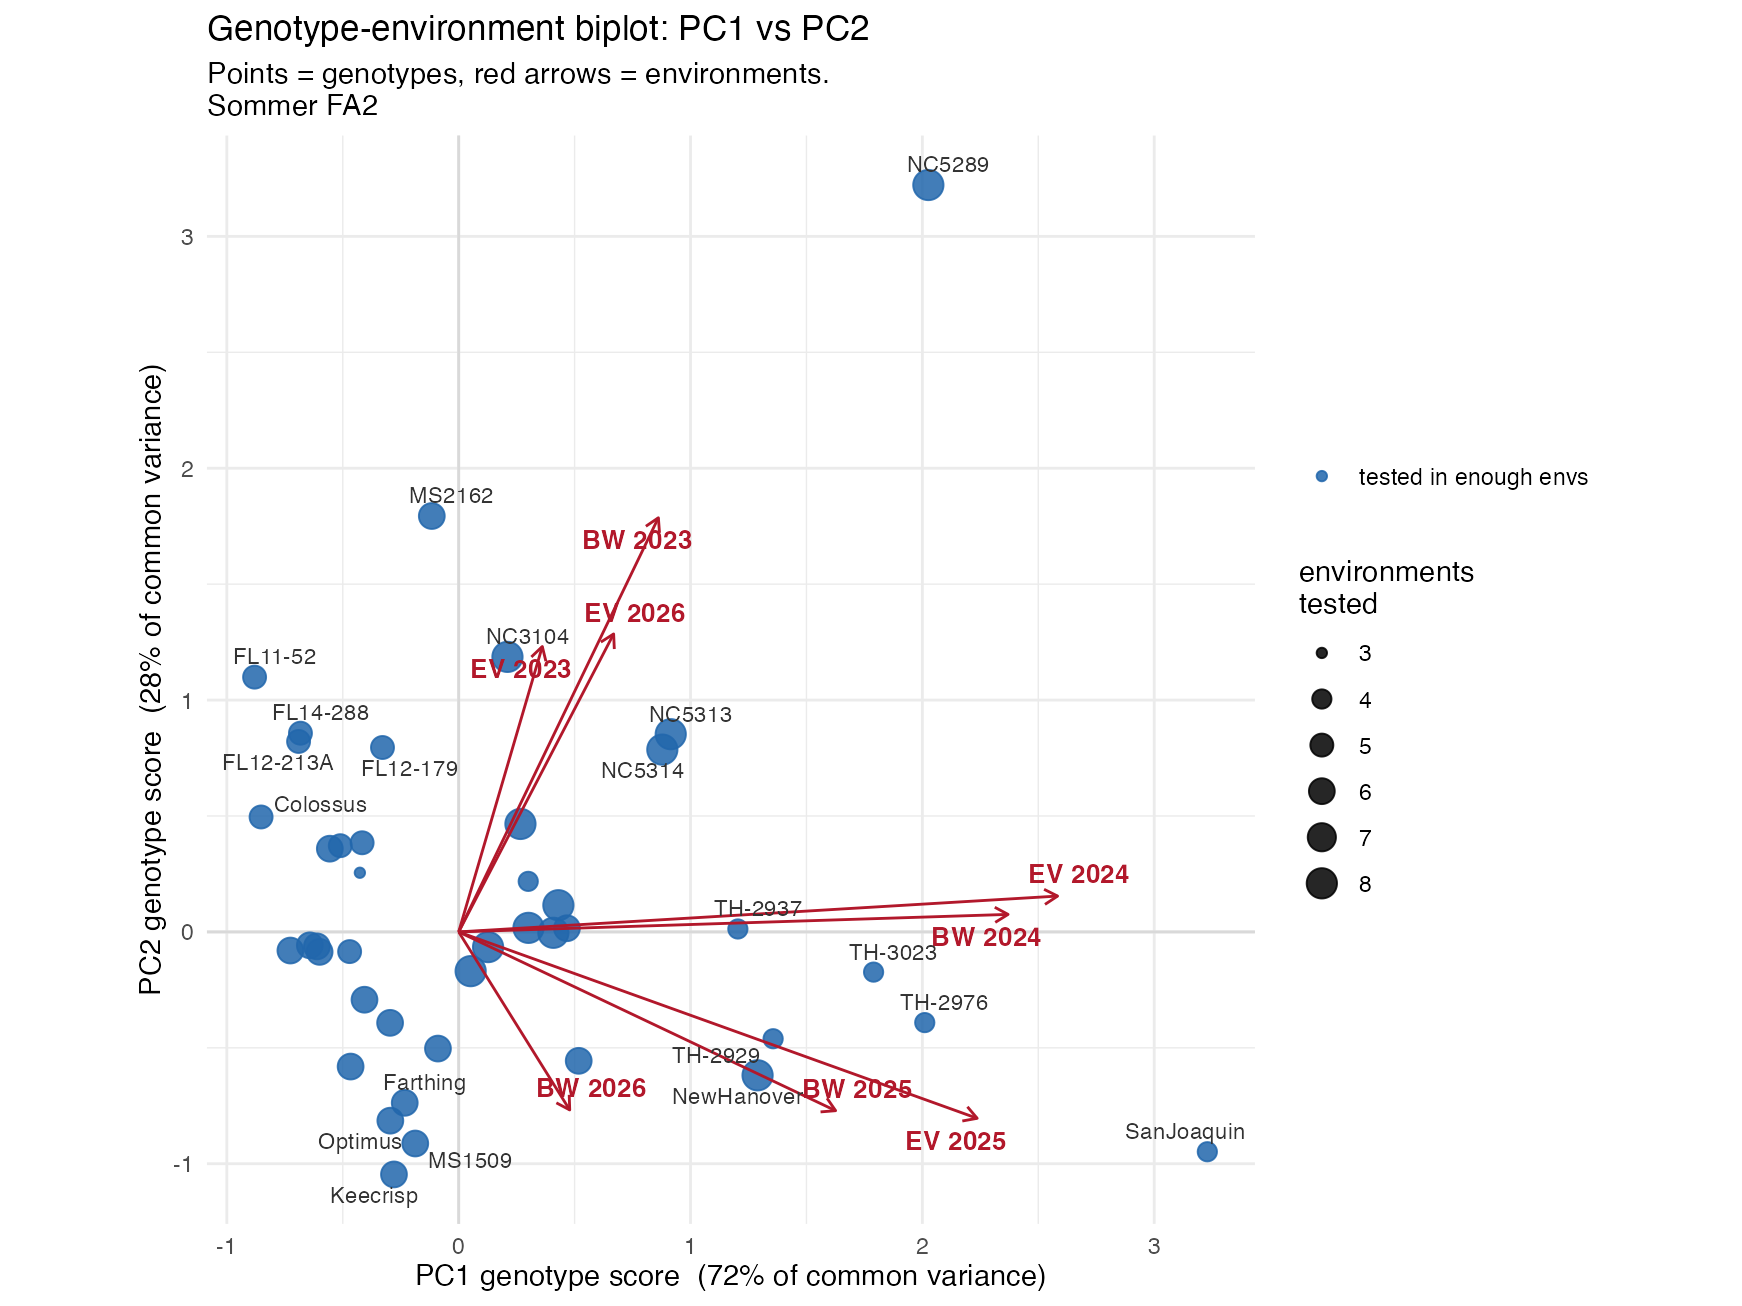

In [56]:
s24 = plot_fa_biplot(pc_sm2, pcs = c(1, 2), specs = 'Sommer FA2') 
s24

9 genotype(s) dropped: no tested environment in one of the groups


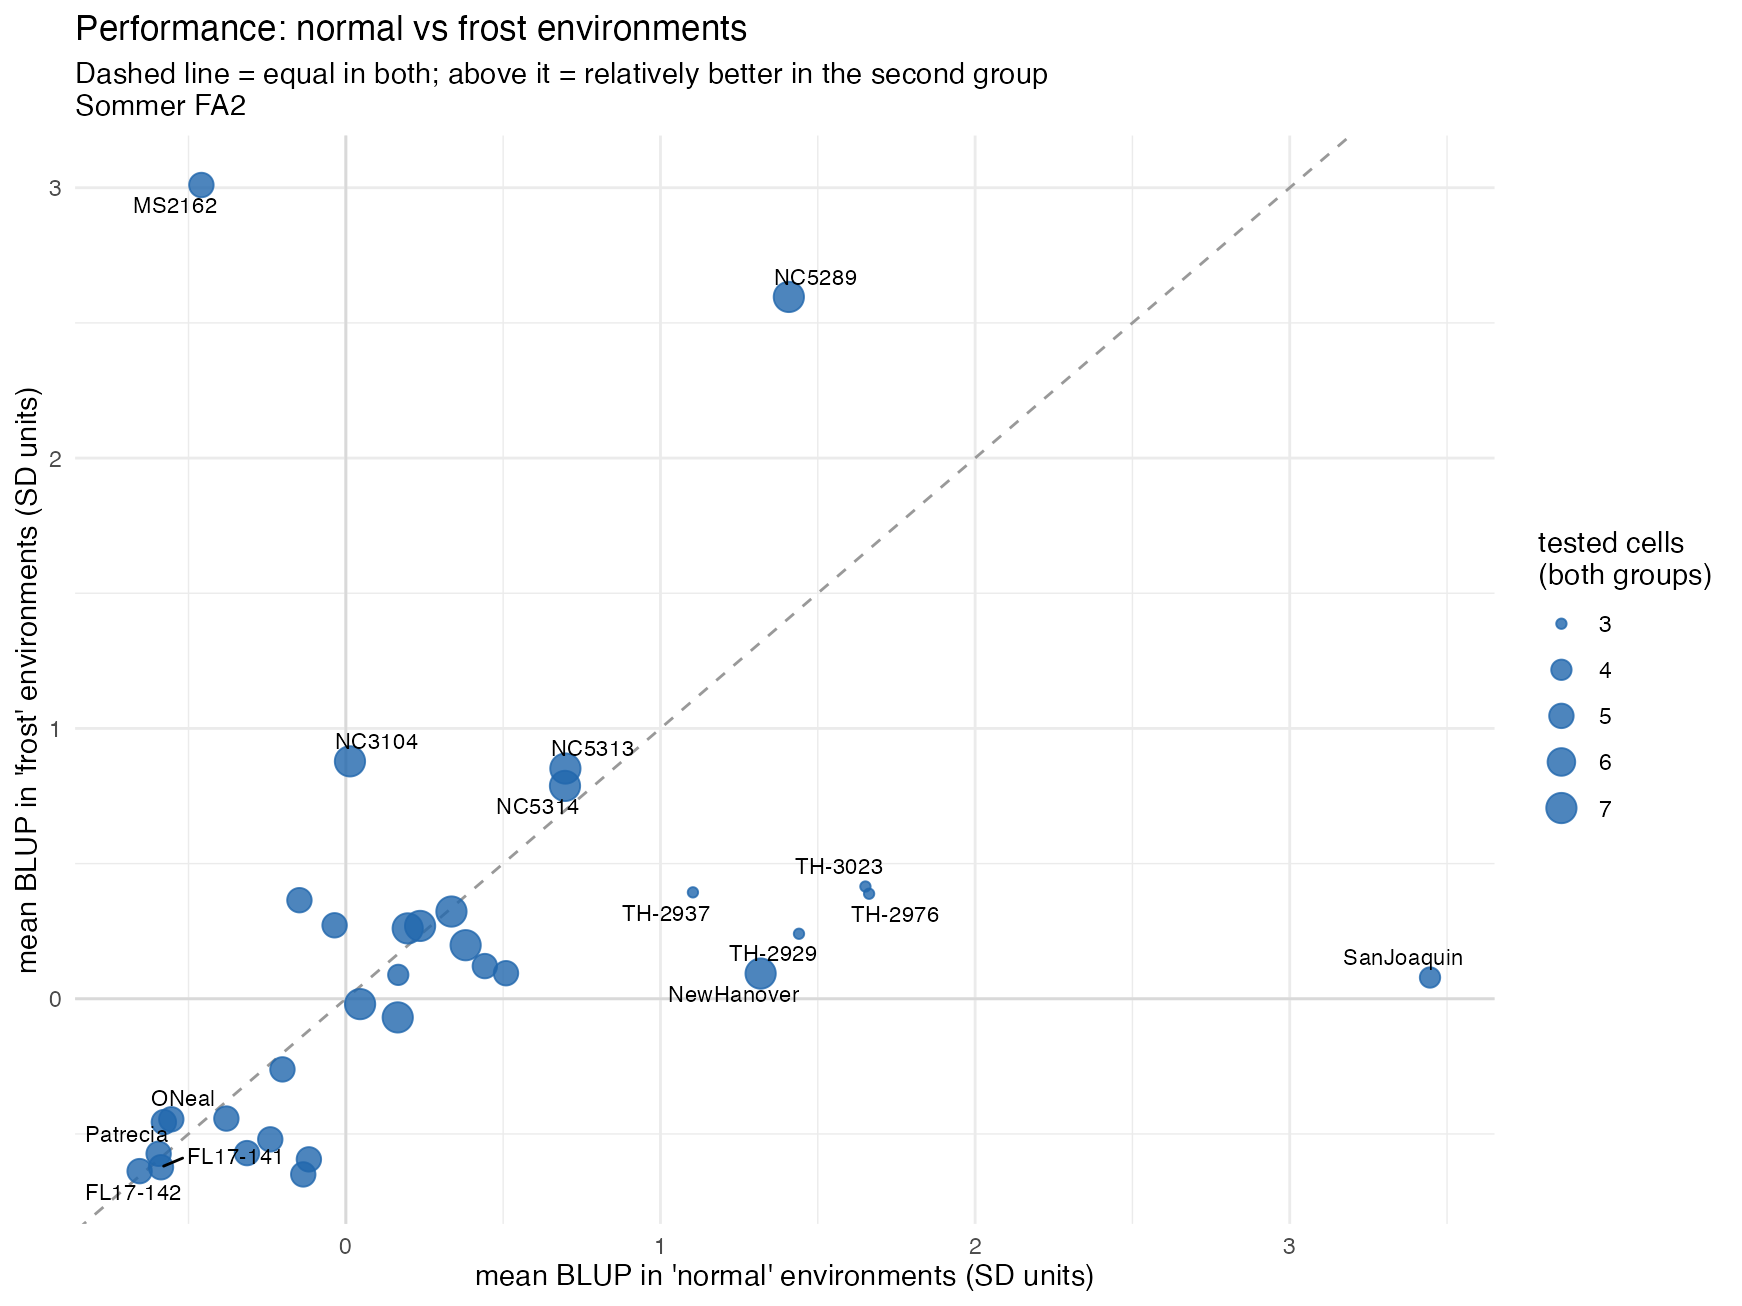

In [57]:
s25 = plot_group_means(blup_sm2,
                 list(normal = c("BW 2024", "BW 2025", "EV 2024", "EV 2025"),
                      frost  = c("BW 2023", "EV 2023", "EV 2026")),
                 tested = tested, specs = 'Sommer FA2')
s25

In [346]:
adig = diag(a_mat)[geno]
length(adig)

[1] 42

In [351]:
setNames(diag(a_mat), rownames(a_mat))[geno]

   TH-3023     NC5283     NC5314     NC5289     NC5286     NC3104 NewHanover     NC5298     NC5313    TH-2976     NC5287     NC5271    TH-2929     NC5326 
  1.026033   1.156877   1.144666   1.145074   1.145074   1.111100   1.111100   1.111100   1.144666   1.094225   1.111100   1.061561   1.106285   1.110267 
   TH-2937 SanJoaquin     NC5303    FL11-51    FL11-52   FL17-141   Sentinel      Gumbo   FL14-288   Farthing     MS1987      MS771     MS1509      ONeal 
  1.123616   1.004960   1.061561   1.000000   1.000000   1.000004   1.000000   1.035722   1.097627   1.005460   1.025623   1.143680   1.020936   1.178542 
  Keecrisp  FL12-213A    Arcadia    TH-1484   Patrecia   FL12-179     MS2162     MS1691   FL17-142      Wayne   Colossus   FL12-214     Legacy    Optimus 
  1.000910   1.000000   1.009111   1.125827   1.040975   1.000000   1.027347   1.111312   1.000004   1.000000   1.000152   1.000000   1.078631   1.003786 

In [348]:
reliability_op_asreml <- function(fit, G, a_diag = NULL) {
  pr <- predict(fit, classify = "Env:Genotype", vcov = TRUE)
  pv <- pr$pvals %>% dplyr::mutate(Env = as.character(Env), Genotype = as.character(Genotype))
  V  <- pr$vcov                                    
  envs <- rownames(G)
  one  <- rep(1, length(envs)) / length(envs)

  var_op_unit <- as.numeric(t(one) %*% G %*% one)  

  genos <- unique(pv$Genotype)
  purrr::map_dfr(genos, function(g) {
    idx <- which(pv$Genotype == g)
    ord <- match(envs, pv$Env[idx])
    idx <- idx[ord]                                 
    Pi  <- V[idx, idx, drop = FALSE]                
    pev_op <- as.numeric(t(one) %*% Pi %*% one)

    a_ii <- if (is.null(a_diag)) 1 else a_diag[[g]]
    var_op <- a_ii * var_op_unit

    tibble::tibble(Genotype = g, pev_op = pev_op, var_op = var_op,
                    reliability_op = pmax(0, pmin(1, 1 - pev_op / var_op)))
  })
}


In [349]:
rel = reliability_op_asreml(fit_fa3_asr, a_diag = adig)

: [1m[33mError[39m:[22m
[33m![39m object 'dta' not found

In [58]:
blup_sm3 <- extract_blups_sommer(fit_fa3_sm)
# blups_orig_sm3 = back_transform_blups(blup_sm3, env_dta)
stab_sm3 <- fa_stability(blup_sm3, loadings = loadings_mmes(fit_fa3_sm)$loadings, tested = tested)

In [59]:
stab_sm3$var_explained  

[1] 0.5768812 0.3193191 0.1037997

In [60]:
stab_sm3$pc1_loadings 

   BW 2023    BW 2024    BW 2025    BW 2026    EV 2023    EV 2024    EV 2025    EV 2026 
0.21031807 0.98077211 0.75783152 0.26316364 0.08537941 1.11045107 0.94340233 0.33815501 

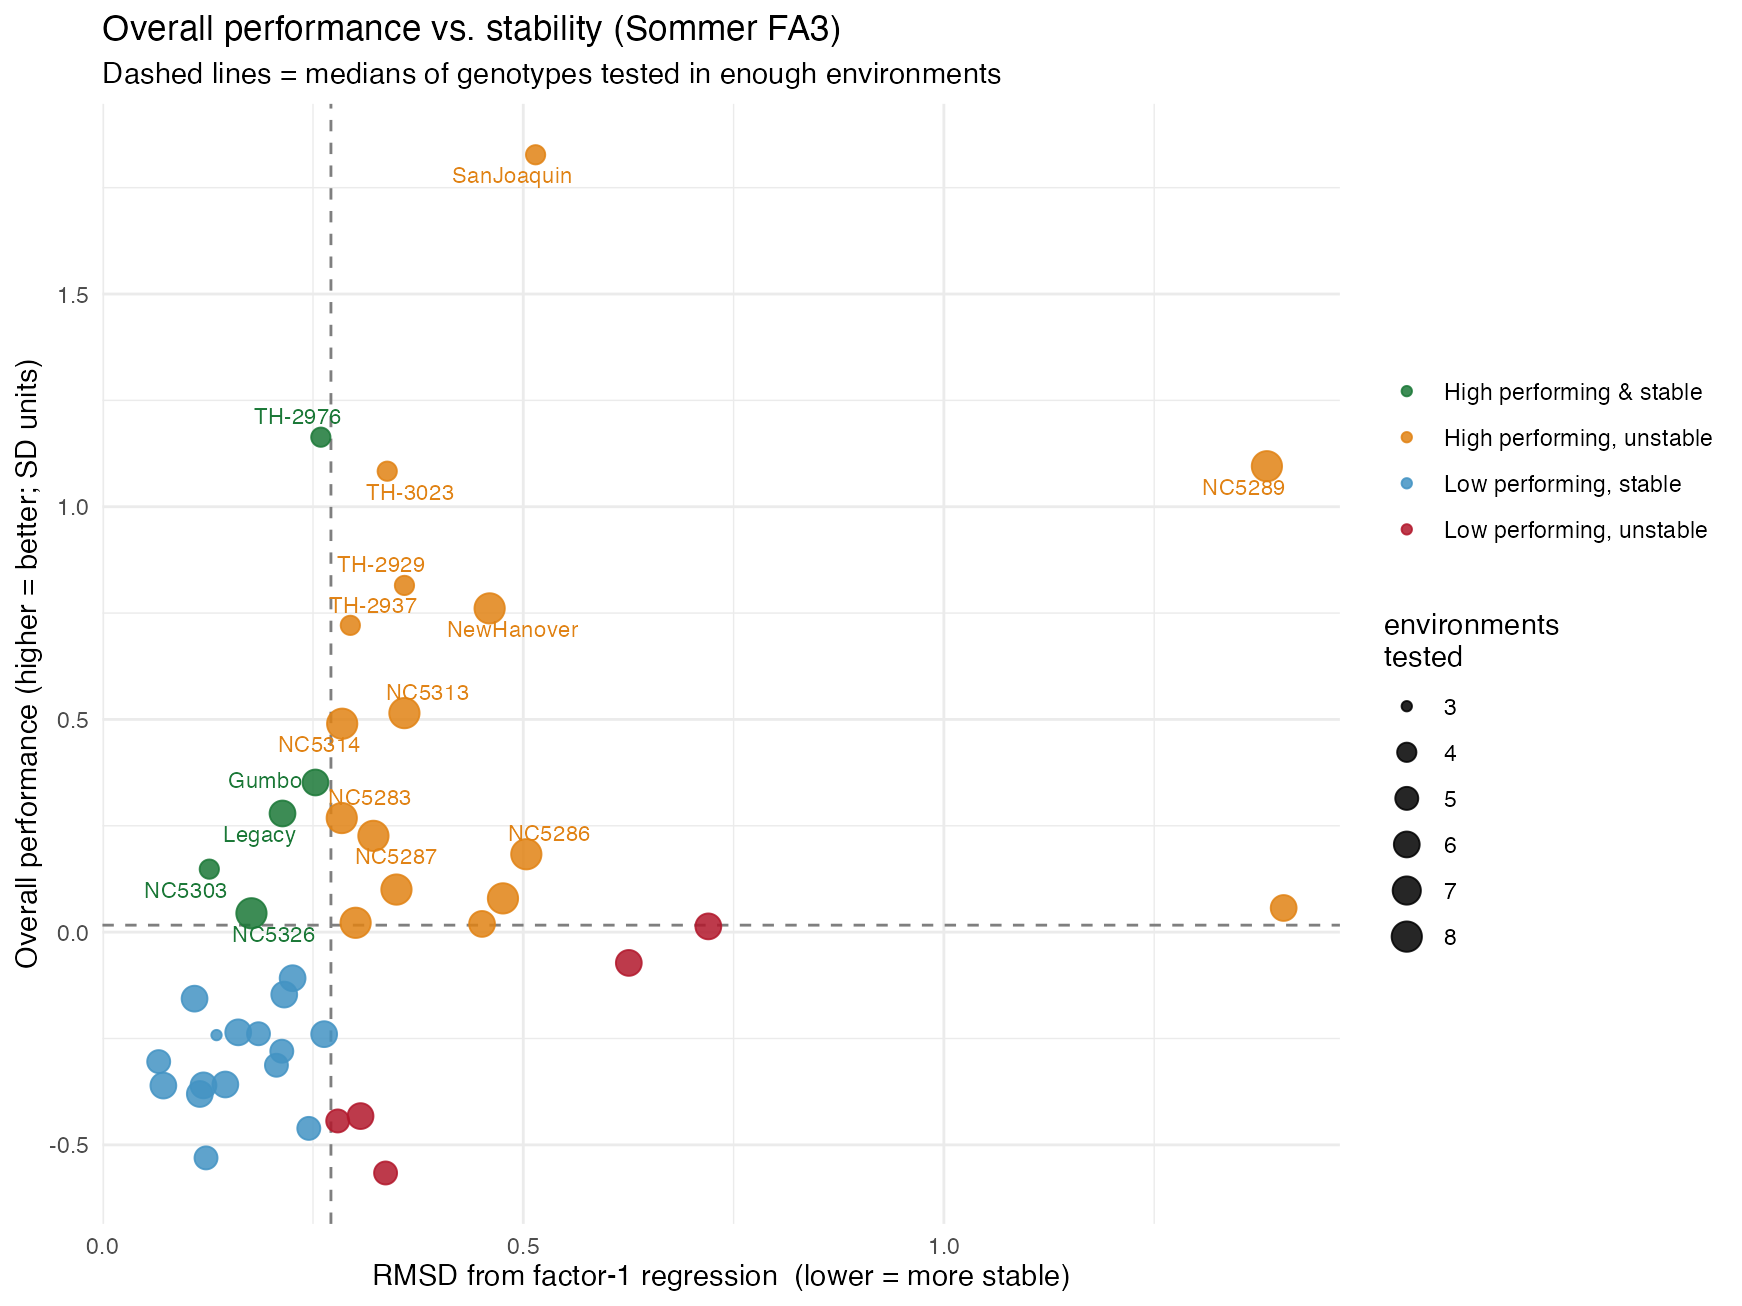

In [61]:
s31 = plot_op_rmsd(stab_sm3, specs = 'Sommer FA3')
s31

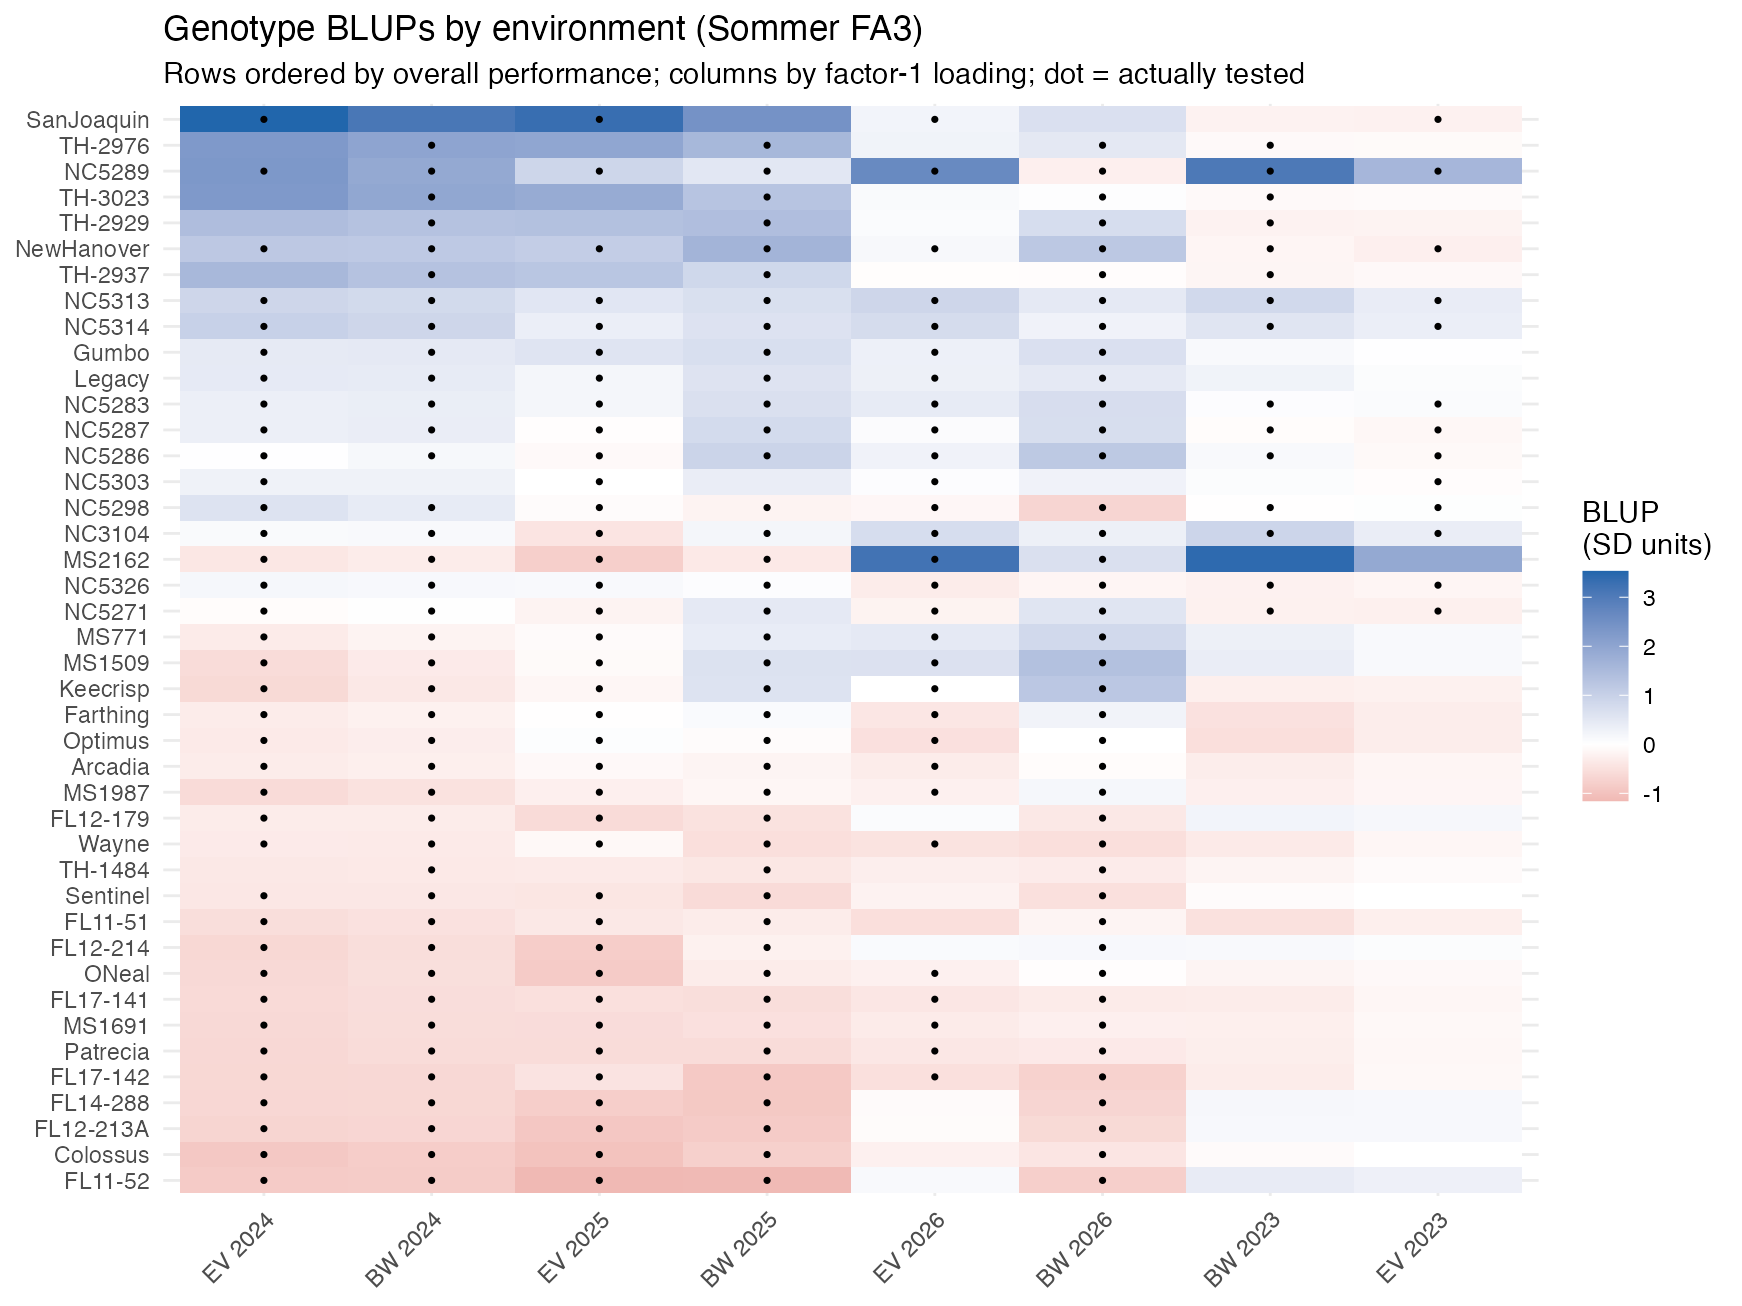

In [62]:
s32 = plot_blup_heatmap(blup_sm3, stab_sm3, tested, specs = 'Sommer FA3')
s32

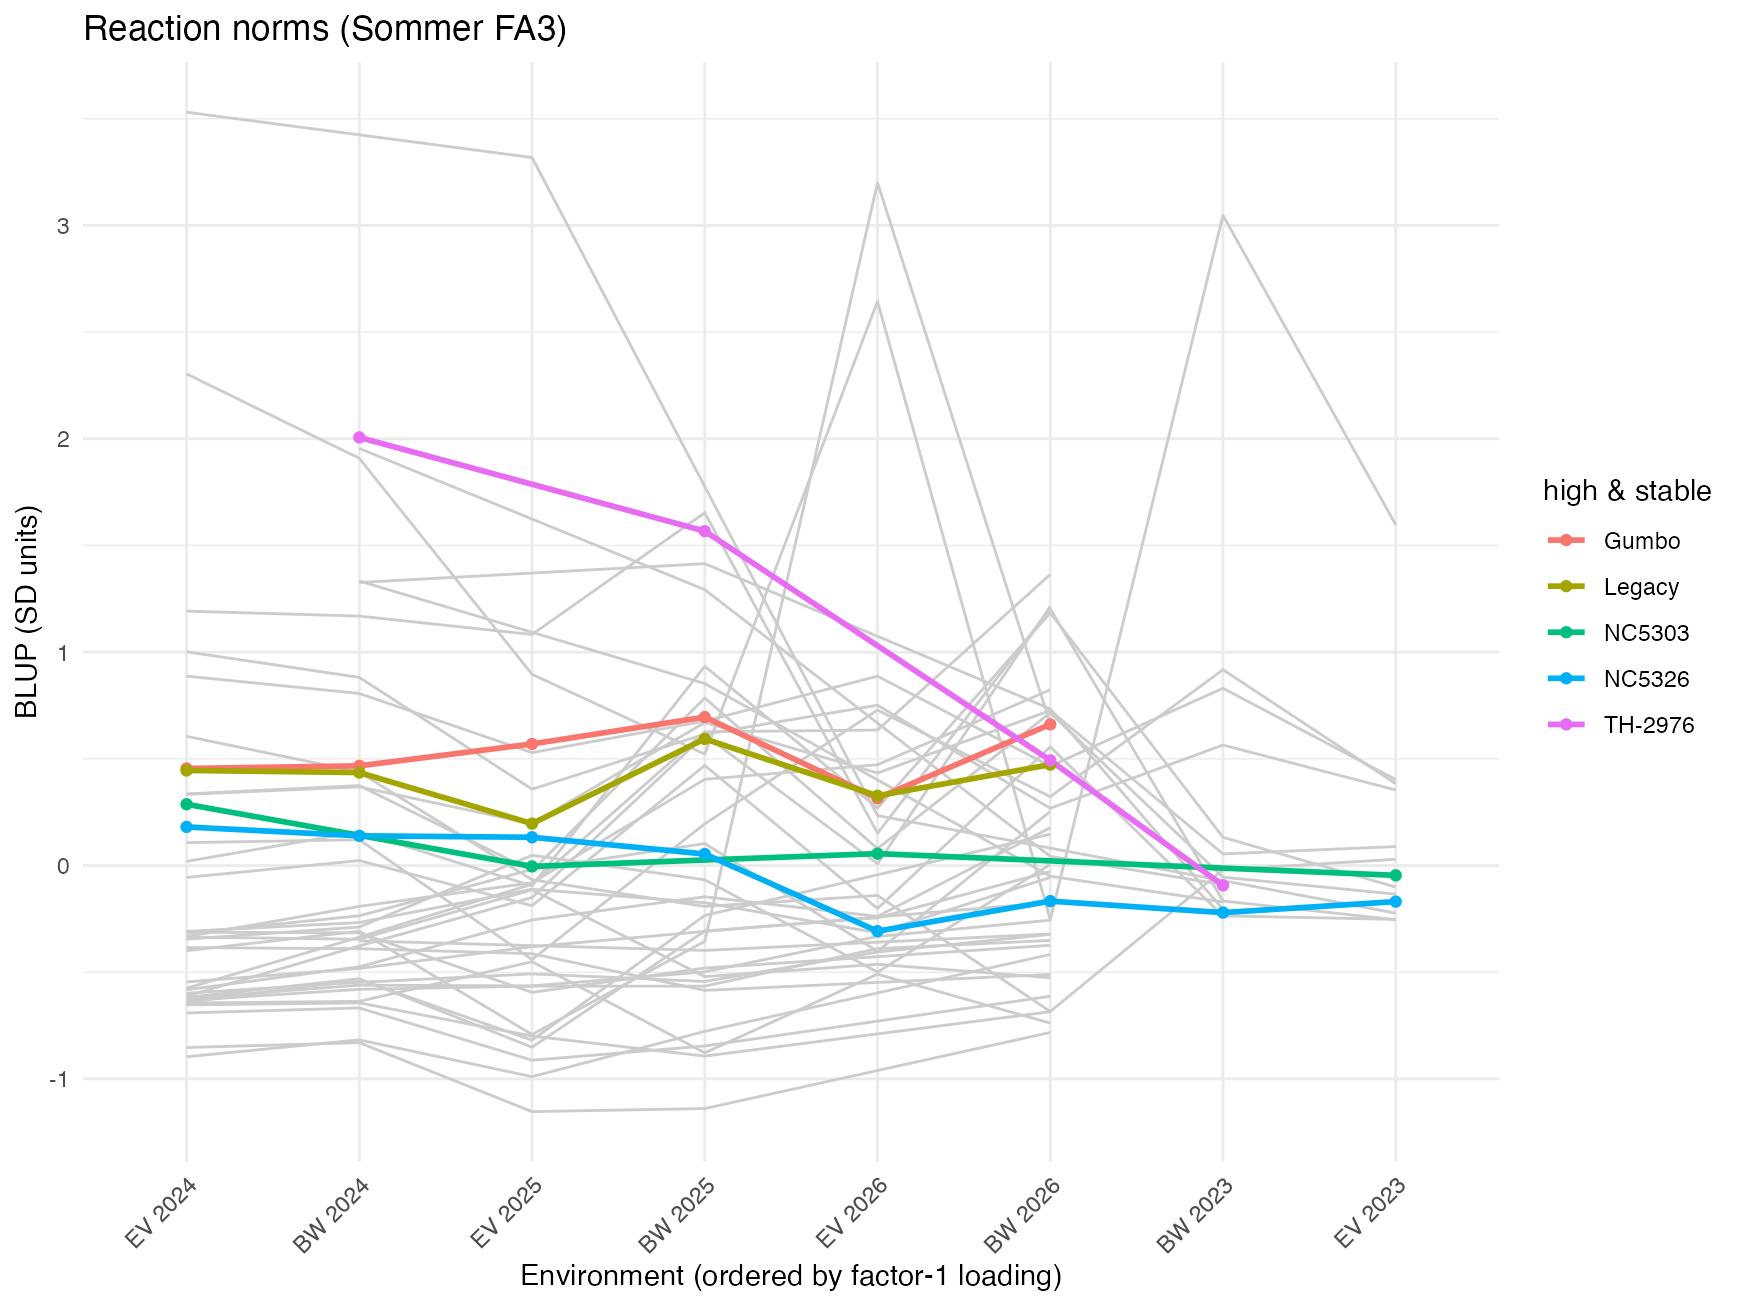

In [63]:
s33 = plot_reaction_norms(blup_sm3, stab_sm3, tested, specs = 'Sommer FA3')
s33

In [64]:
pc_sm3 <- fa_pc_scores(blup_sm3, loadings = loadings_mmes(fit_fa3_sm)$loadings, tested = tested, n_pc = 3)   # n_pc = number of factors you fitted


In [65]:
round(pc_sm3$loadings, 2)

         PC1   PC2   PC3
BW 2023 0.21  0.97  0.06
BW 2024 0.98 -0.02 -0.15
BW 2025 0.76 -0.32  0.35
BW 2026 0.26 -0.19  0.66
EV 2023 0.09  0.57 -0.01
EV 2024 1.11  0.01 -0.26
EV 2025 0.94 -0.25 -0.08
EV 2026 0.34  0.83  0.19

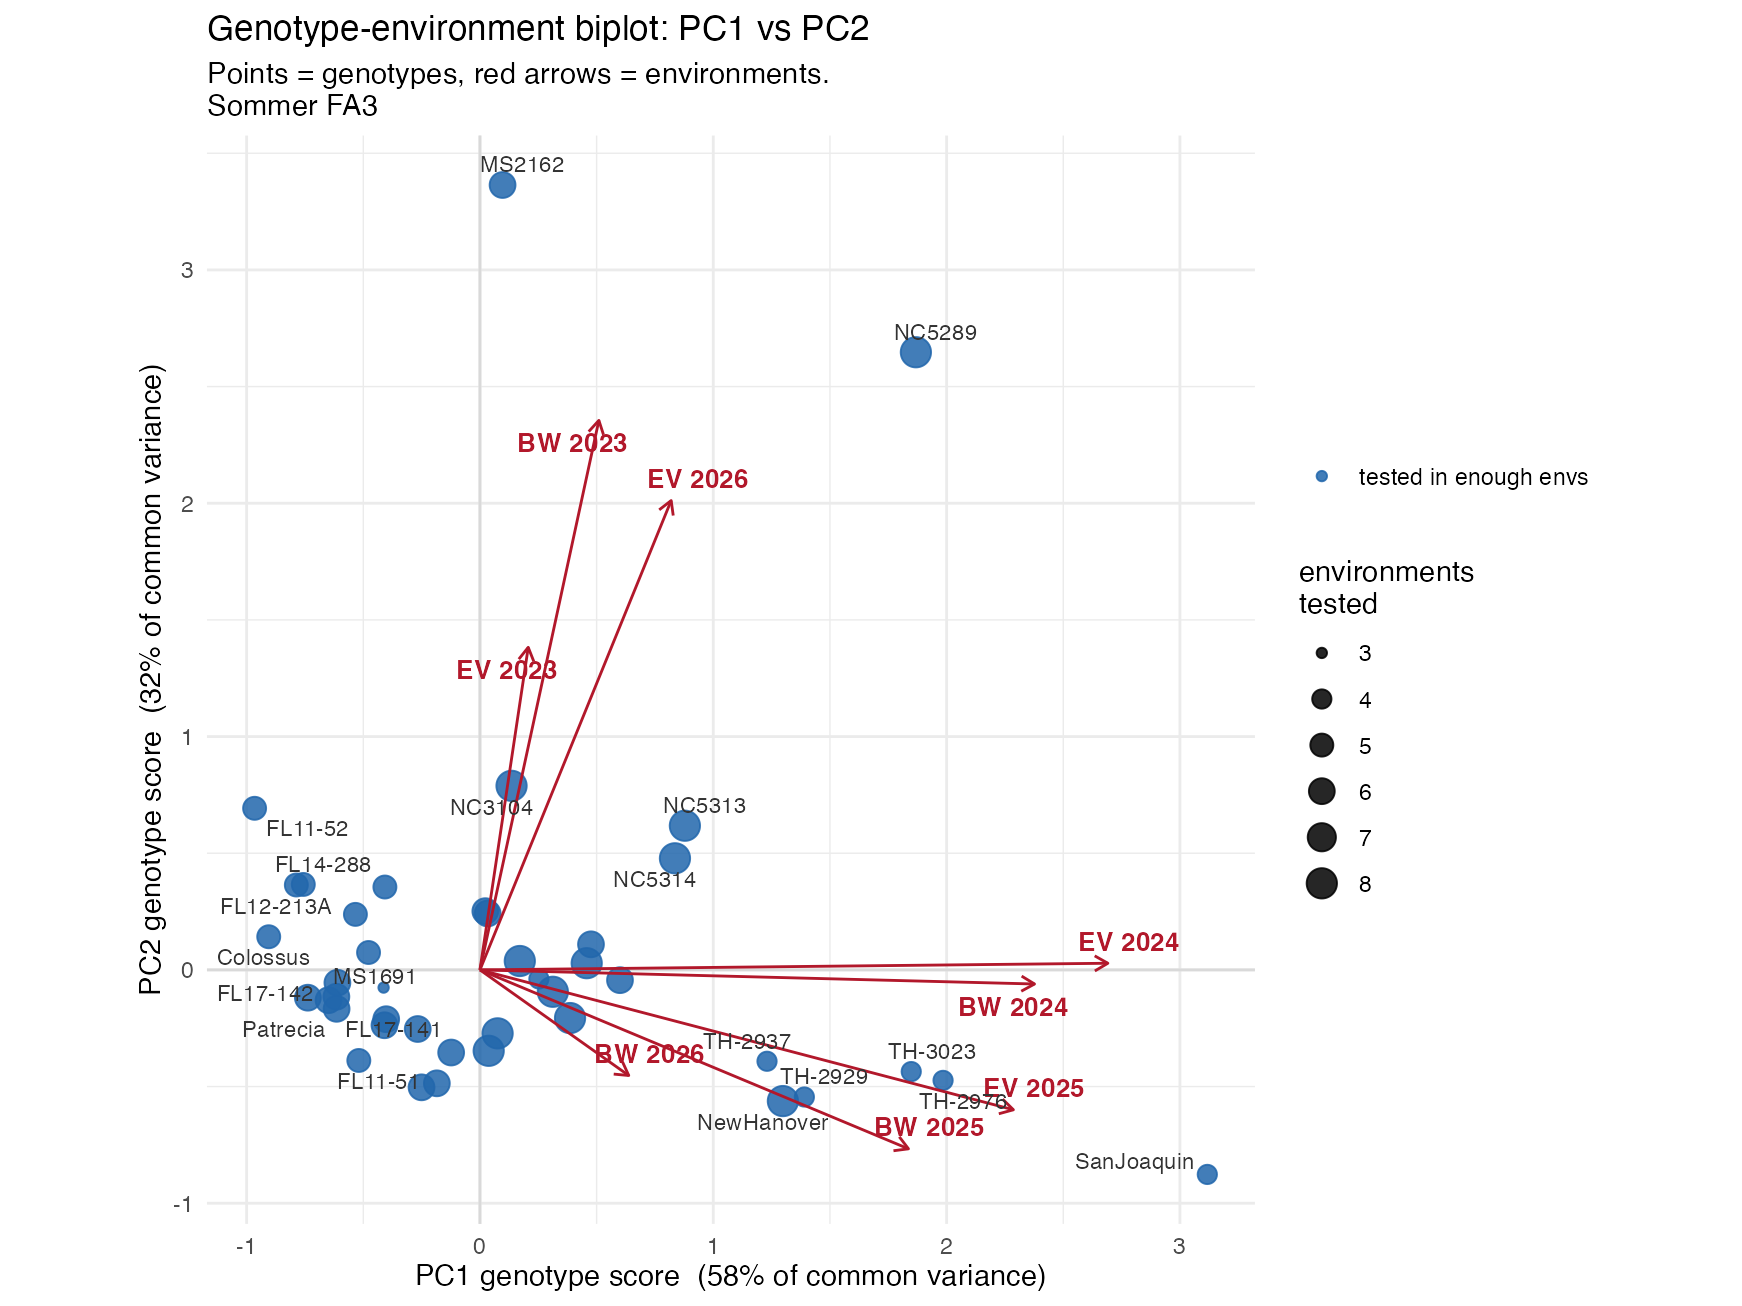

In [66]:
s34 = plot_fa_biplot(pc_sm3, pcs = c(1, 2), specs = 'Sommer FA3') 
s34

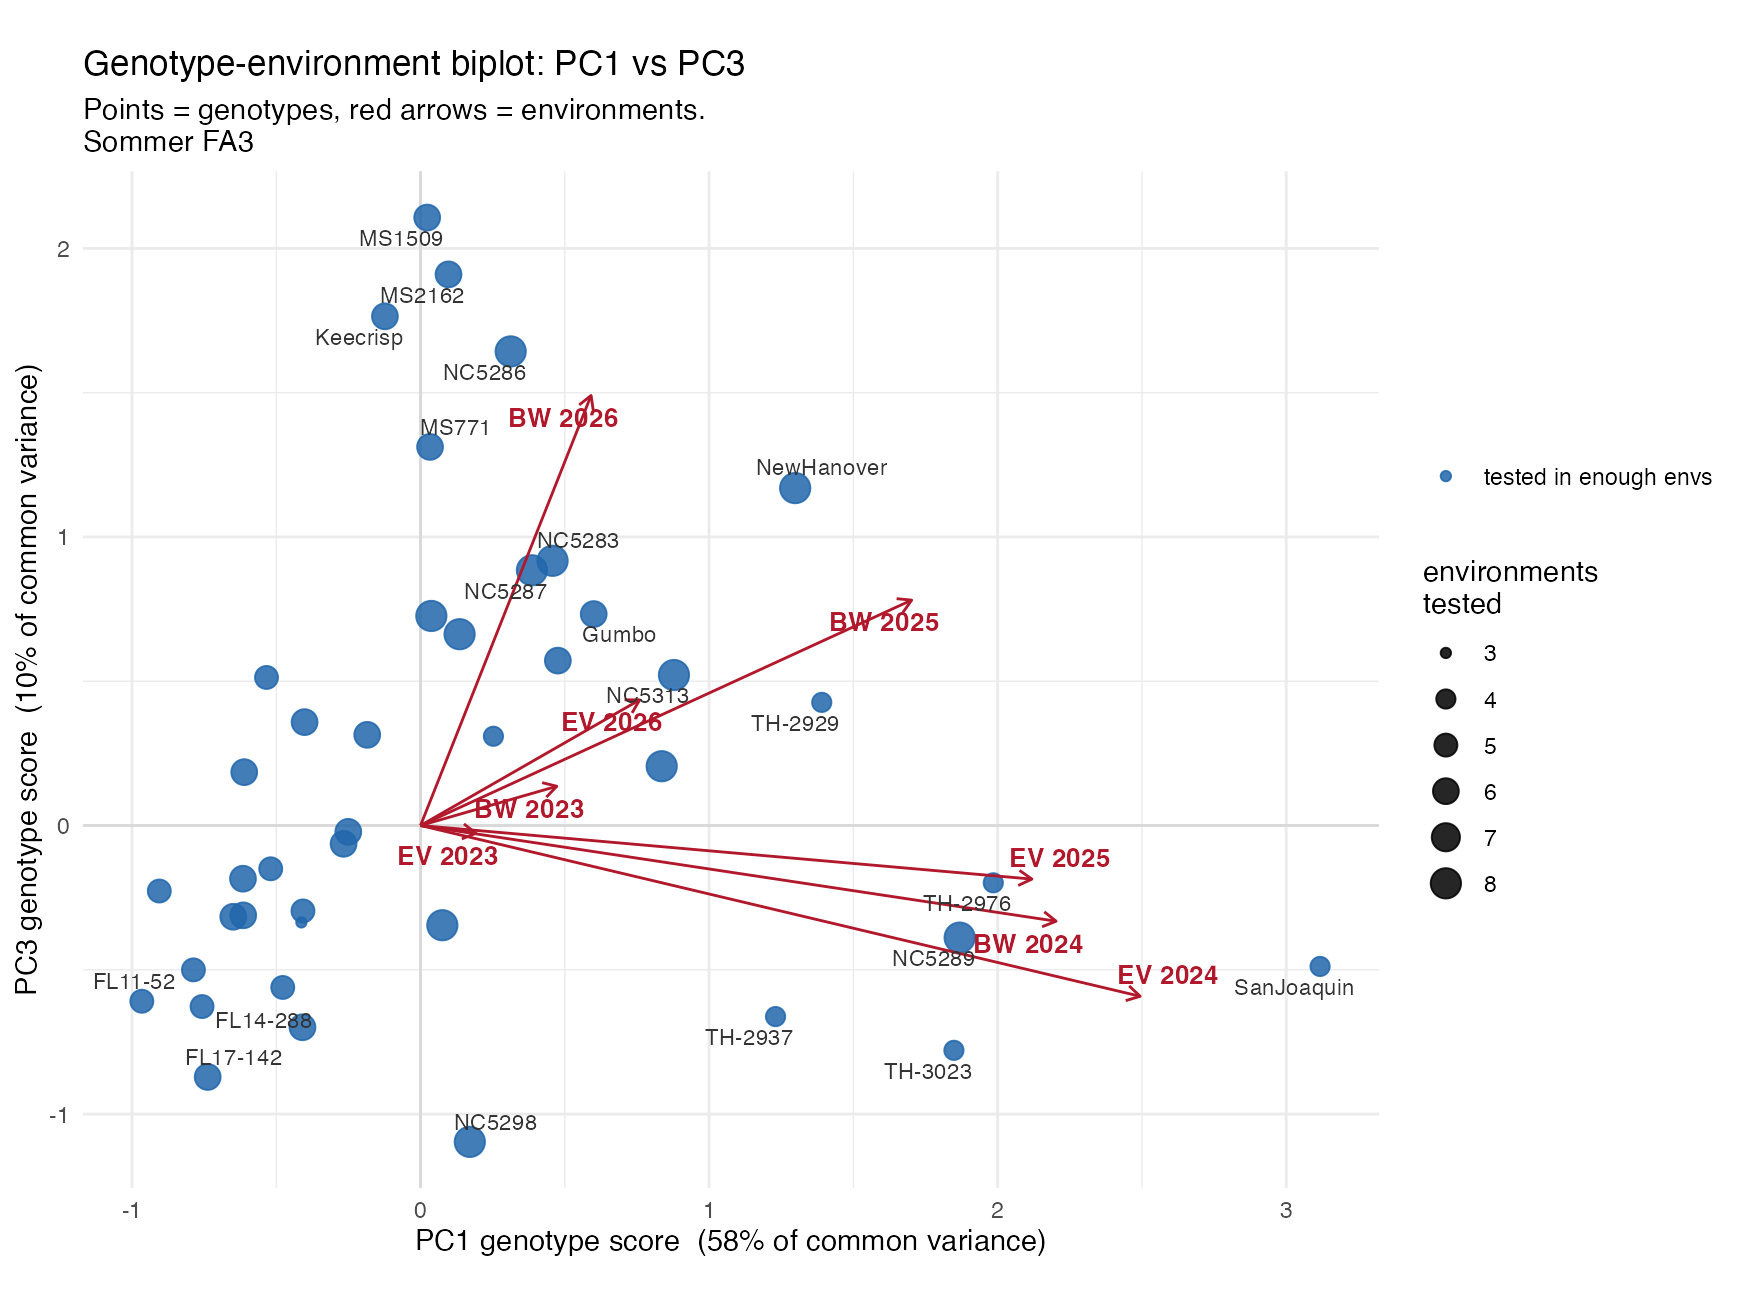

In [67]:
s35 = plot_fa_biplot(pc_sm3, pcs = c(1, 3), specs = 'Sommer FA3') 
s35

9 genotype(s) dropped: no tested environment in one of the groups


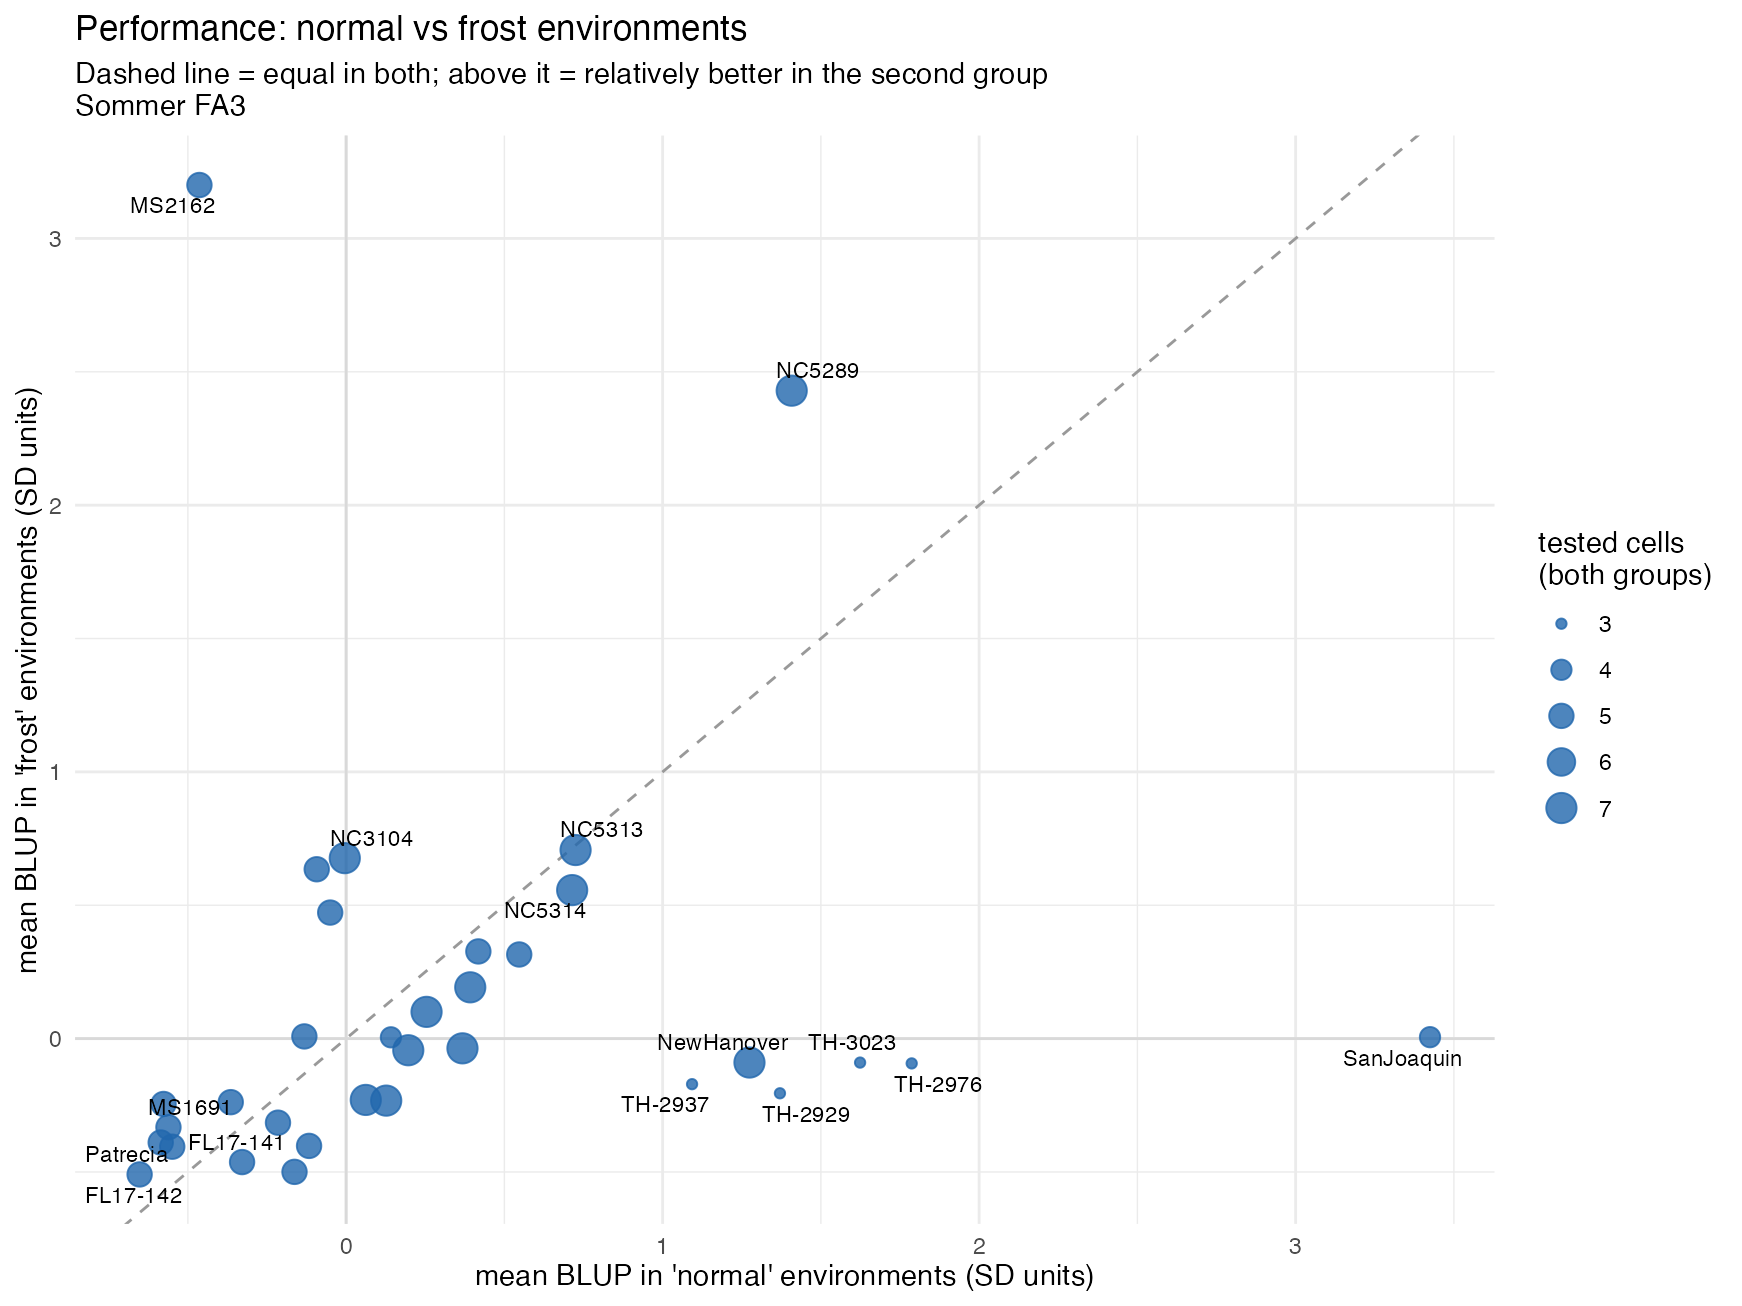

In [68]:
s36 = plot_group_means(blup_sm3,
                 list(normal = c("BW 2024", "BW 2025", "EV 2024", "EV 2025"),
                      frost  = c("BW 2023", "EV 2023", "EV 2026")),
                 tested = tested, specs = 'Sommer FA3')
s36

In [86]:
# quartz(width = 12, height = 8)

In [88]:
# (s21 | s22 | s23)/ (s24 | s25)

In [89]:
# (s31 | s32 | s33) / (s34 | s35 | s36)

In [103]:
cor.test(stab_sm2$table$RMSD, stab_sm3$table$RMSD, method = 'spearman')


	Spearman's rank correlation rho

data:  stab_sm2$table$RMSD and stab_sm3$table$RMSD
S = 4402, p-value = 7.383e-06
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
0.6433028 


In [70]:
cor.test(stab_sm2$table$OP, stab_sm3$table$OP, method = 'spearman')


	Spearman's rank correlation rho

data:  stab_sm2$table$OP and stab_sm3$table$OP
S = 0, p-value < 2.2e-16
alternative hypothesis: true rho is not equal to 0
sample estimates:
rho 
  1 


In [105]:
cor.test(stab_asr$table$RMSD, stab_sm3$table$RMSD, method = 'spearman')


	Spearman's rank correlation rho

data:  stab_asr$table$RMSD and stab_sm3$table$RMSD
S = 6650, p-value = 0.002342
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
0.4611458 


In [296]:
loeo_setup = loeo_specs()
loeo_asr = run_loeo(prep_y, ai, engine = 'asreml')

asreml :: baseline (8 envs)
ASReml Version 4.2 07/10/2026 13:25:51
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -243.6759           1.0    693   13:25:51
  2     -190.1145           1.0    693   13:25:51  (  3 restrained)
  3     -163.2319           1.0    693   13:25:51  (  3 restrained)
  4     -153.5291           1.0    693   13:25:51  (  3 restrained)
  5     -150.2075           1.0    693   13:25:51  (  1 restrained)
  6     -148.6959           1.0    693   13:25:51  (  1 restrained)
  7     -148.2523           1.0    693   13:25:51  (  1 restrained)
  8     -148.1517           1.0    693   13:25:51
  9     -148.0158           1.0    693   13:25:51  (  1 restrained)
 10     -147.9784           1.0    693   13:25:51
 11     -147.9401           1.0    693   13:25:51
 12     -147.8864           1.0    693   13:25:51
 13     -147.8148           1.0    693   13:25:51  (  1 restrained)
 14     -147.7996           1.0    693

There were 35 warnings (use warnings() to see them)


In [297]:
res_sum_asr = summarize_trio_pairs(loeo_asr)
# res_wa2_asr = track_watch_genotypes(loeo_asr, tested)
# 

In [299]:
res_wa3_asr = track_watch_genotypes(loeo_asr, tested, order = '3')

in loadings, not in blups:  
in blups, not in loadings:  
n loadings rows: 8  n blup envs: 8 
in loadings, not in blups:  
in blups, not in loadings: BW 2023 
n loadings rows: 7  n blup envs: 8 


Warning message:
In fa_stability(res$fa[[order]]$blups, loadings, tested = tested_here) :
  Rotated first-factor loadings are NOT all positive (BW 2023). Smith & Cullis' OP assumes they are; read OP with caution.


: [1m[33mError[39m in `map()`:[22m
[1m[22m[36mℹ[39m In index: 2.
[1mCaused by error in `fa_stability()` at ]8;line = 116:col = 5;file://file:///var/folders/_v/qzwwcnmn743btzqw76jjq7j80000gn/T/ark-debug-43688/2354182197.rT/ark-debug-43688/2354182197.r:116:5]8;;:[22m
[33m![39m setequal(colnames(U), rownames(loadings)) is not TRUE

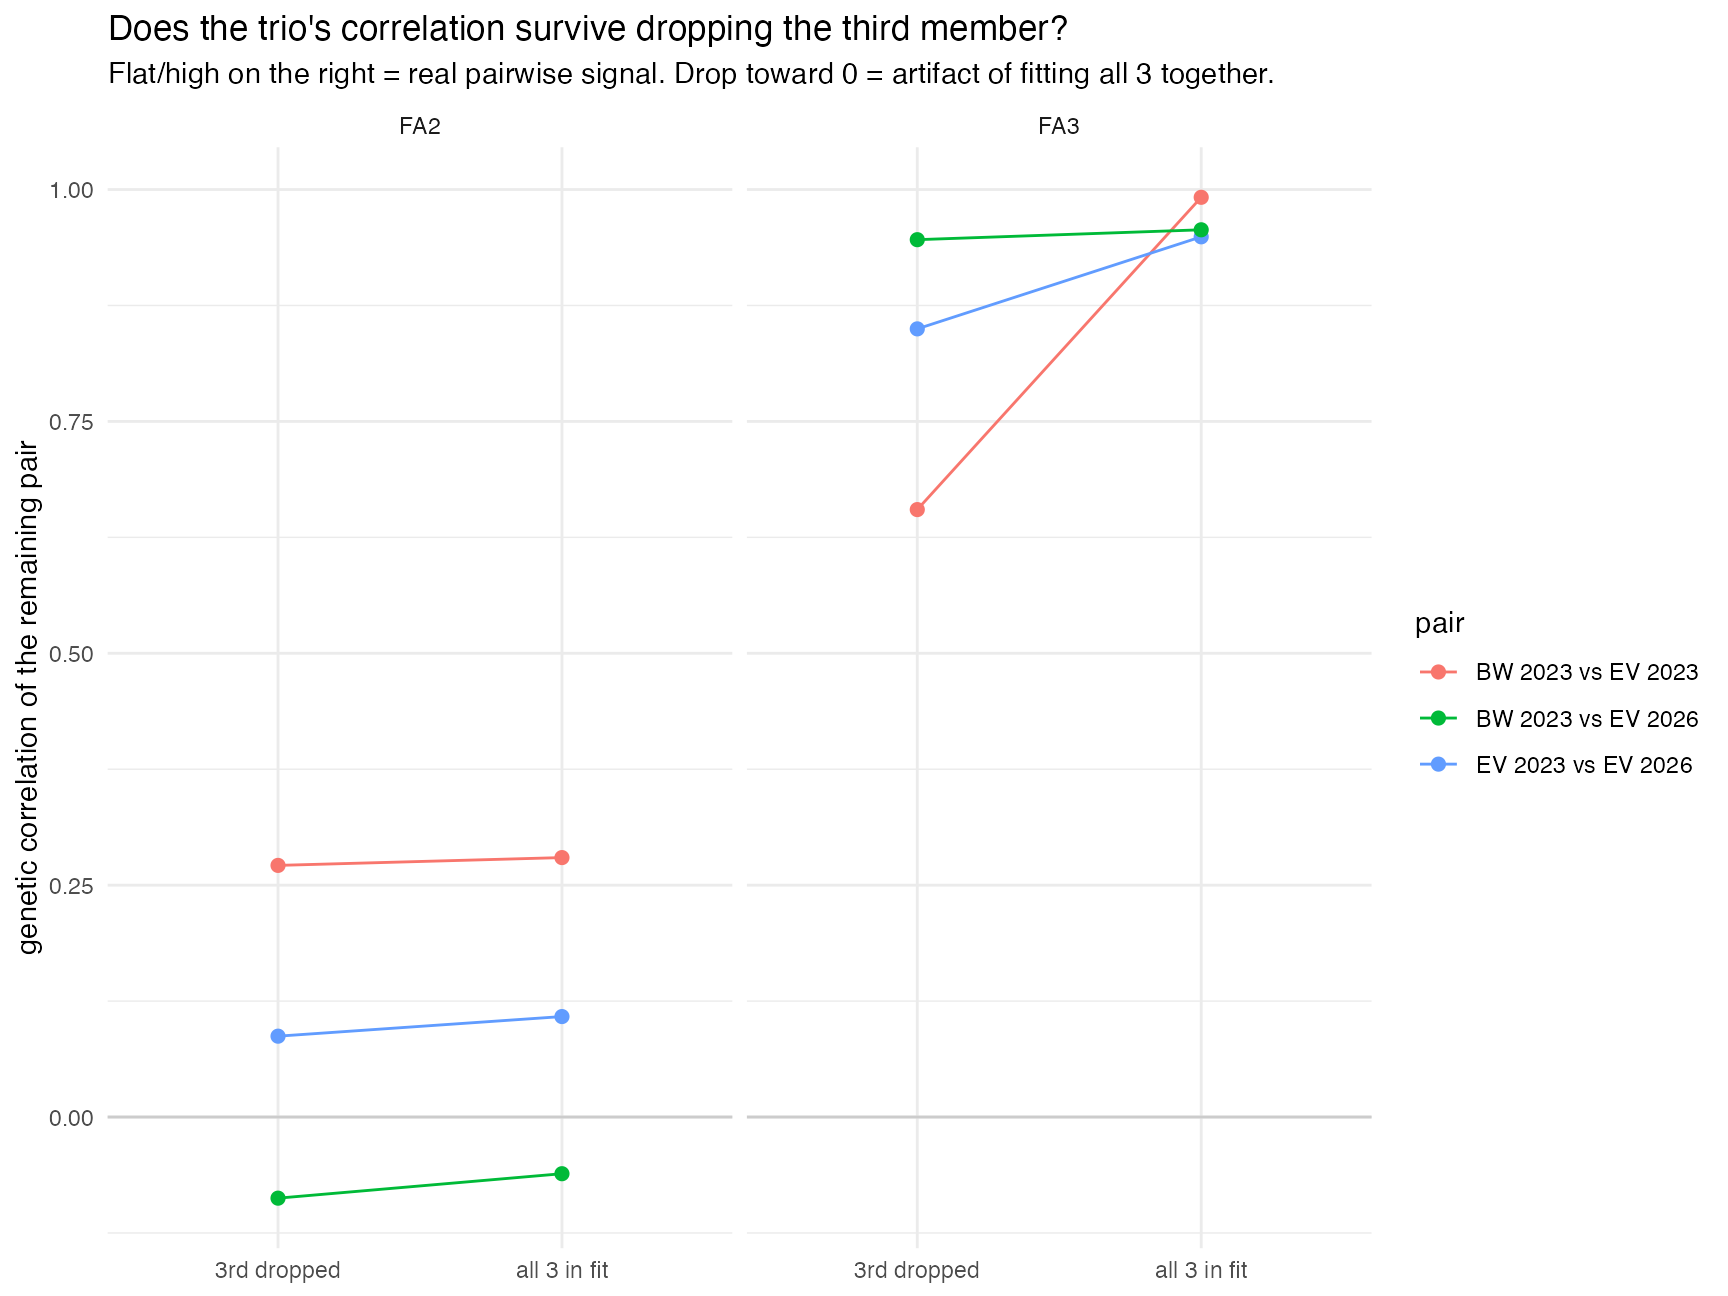

In [298]:
plot_trio_pair_survival(res_sum_asr)

In [340]:
loeo_setup = loeo_specs()
# fit_sm = fit_loeo_one_sommer(prep_y, ai)
loeo_sm = run_loeo(prep_y, Ainv_sm, engine = 'sommer')

res_sum = summarize_trio_pairs(loeo_sm)
res_wa2 = track_watch_genotypes(loeo_sm, tested)
res_wa3 = track_watch_genotypes(loeo_sm, tested, order = '3')

sommer :: baseline (8 envs)
Solver selected: cholmod
Solver selected: cholmod
sommer :: drop_BW2023 (7 envs)
Solver selected: cholmod
Solver selected: cholmod
sommer :: drop_EV2023 (7 envs)
Solver selected: cholmod
Solver selected: cholmod
sommer :: drop_EV2026 (7 envs)
Solver selected: cholmod
Solver selected: cholmod
sommer :: drop_trio (5 envs)
Solver selected: cholmod
Solver selected: cholmod
in loadings, not in blups:  
in blups, not in loadings:  
n loadings rows: 8  n blup envs: 8 
in loadings, not in blups:  
in blups, not in loadings:  
n loadings rows: 7  n blup envs: 7 
in loadings, not in blups:  
in blups, not in loadings:  
n loadings rows: 7  n blup envs: 7 
in loadings, not in blups:  
in blups, not in loadings:  
n loadings rows: 7  n blup envs: 7 
in loadings, not in blups:  
in blups, not in loadings:  
n loadings rows: 5  n blup envs: 5 
in loadings, not in blups:  
in blups, not in loadings:  
n loadings rows: 8  n blup envs: 8 
in loadings, not in blups:  
in blup

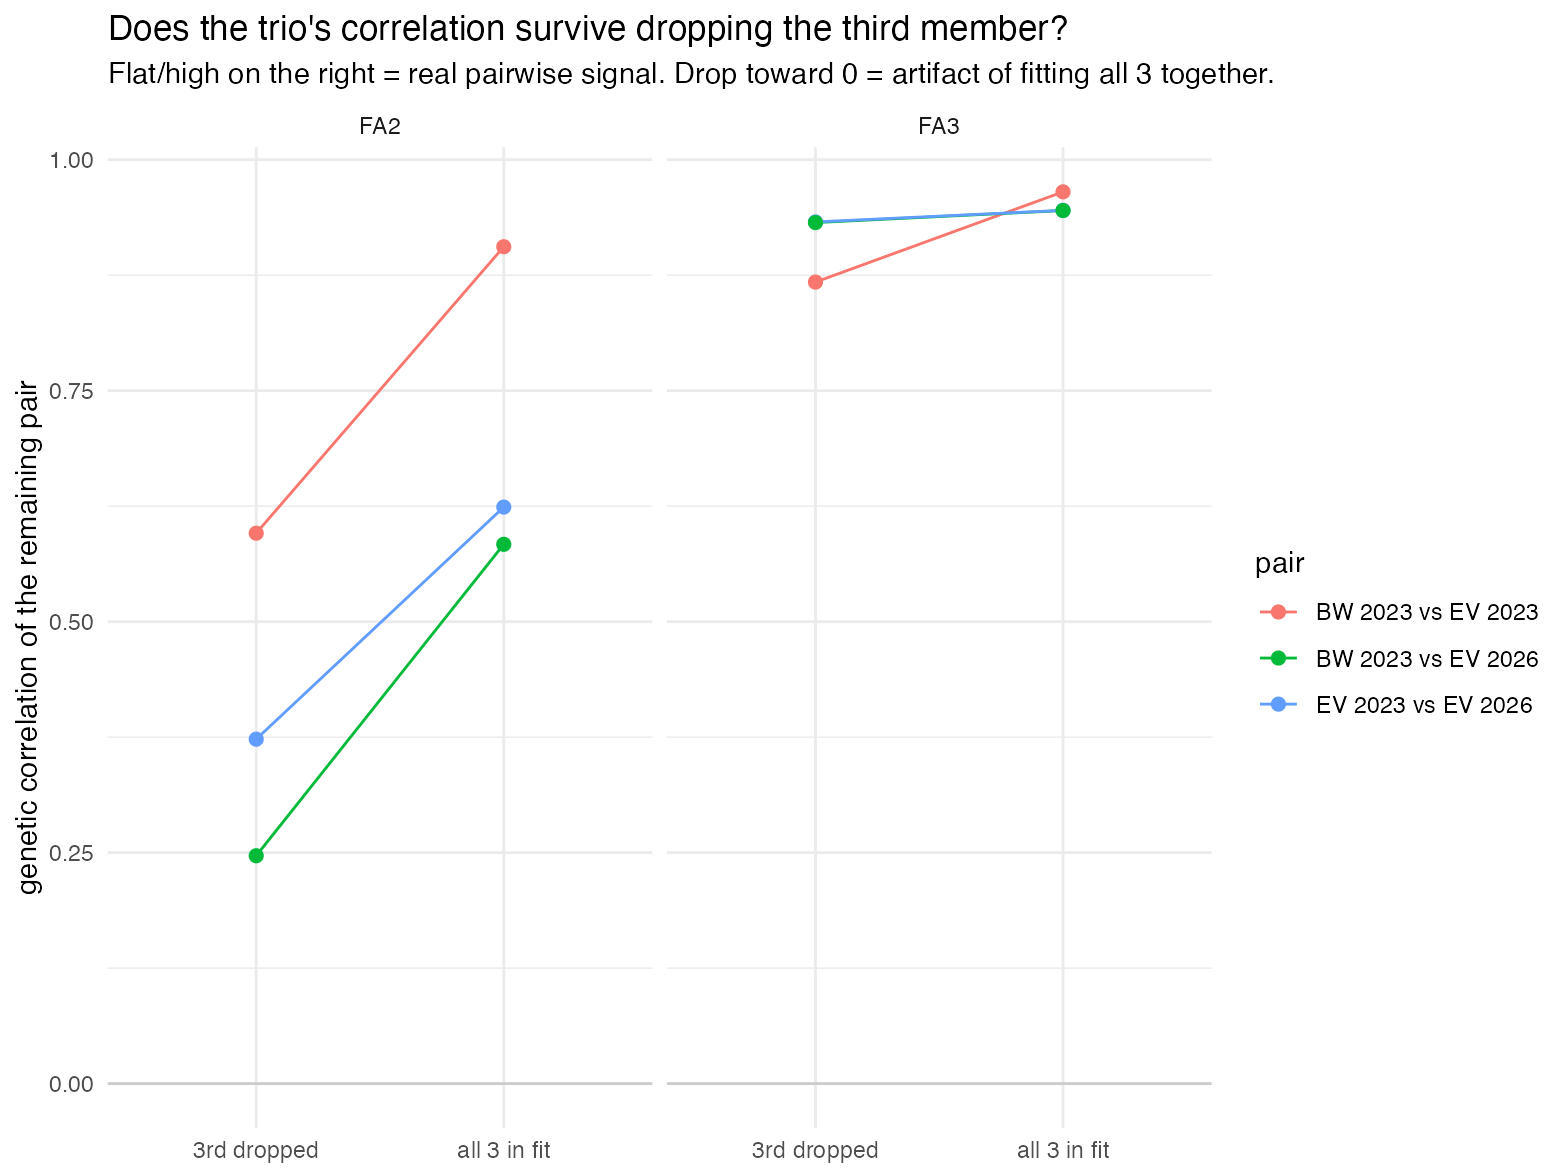

In [341]:
plot_trio_pair_survival(res_sum)

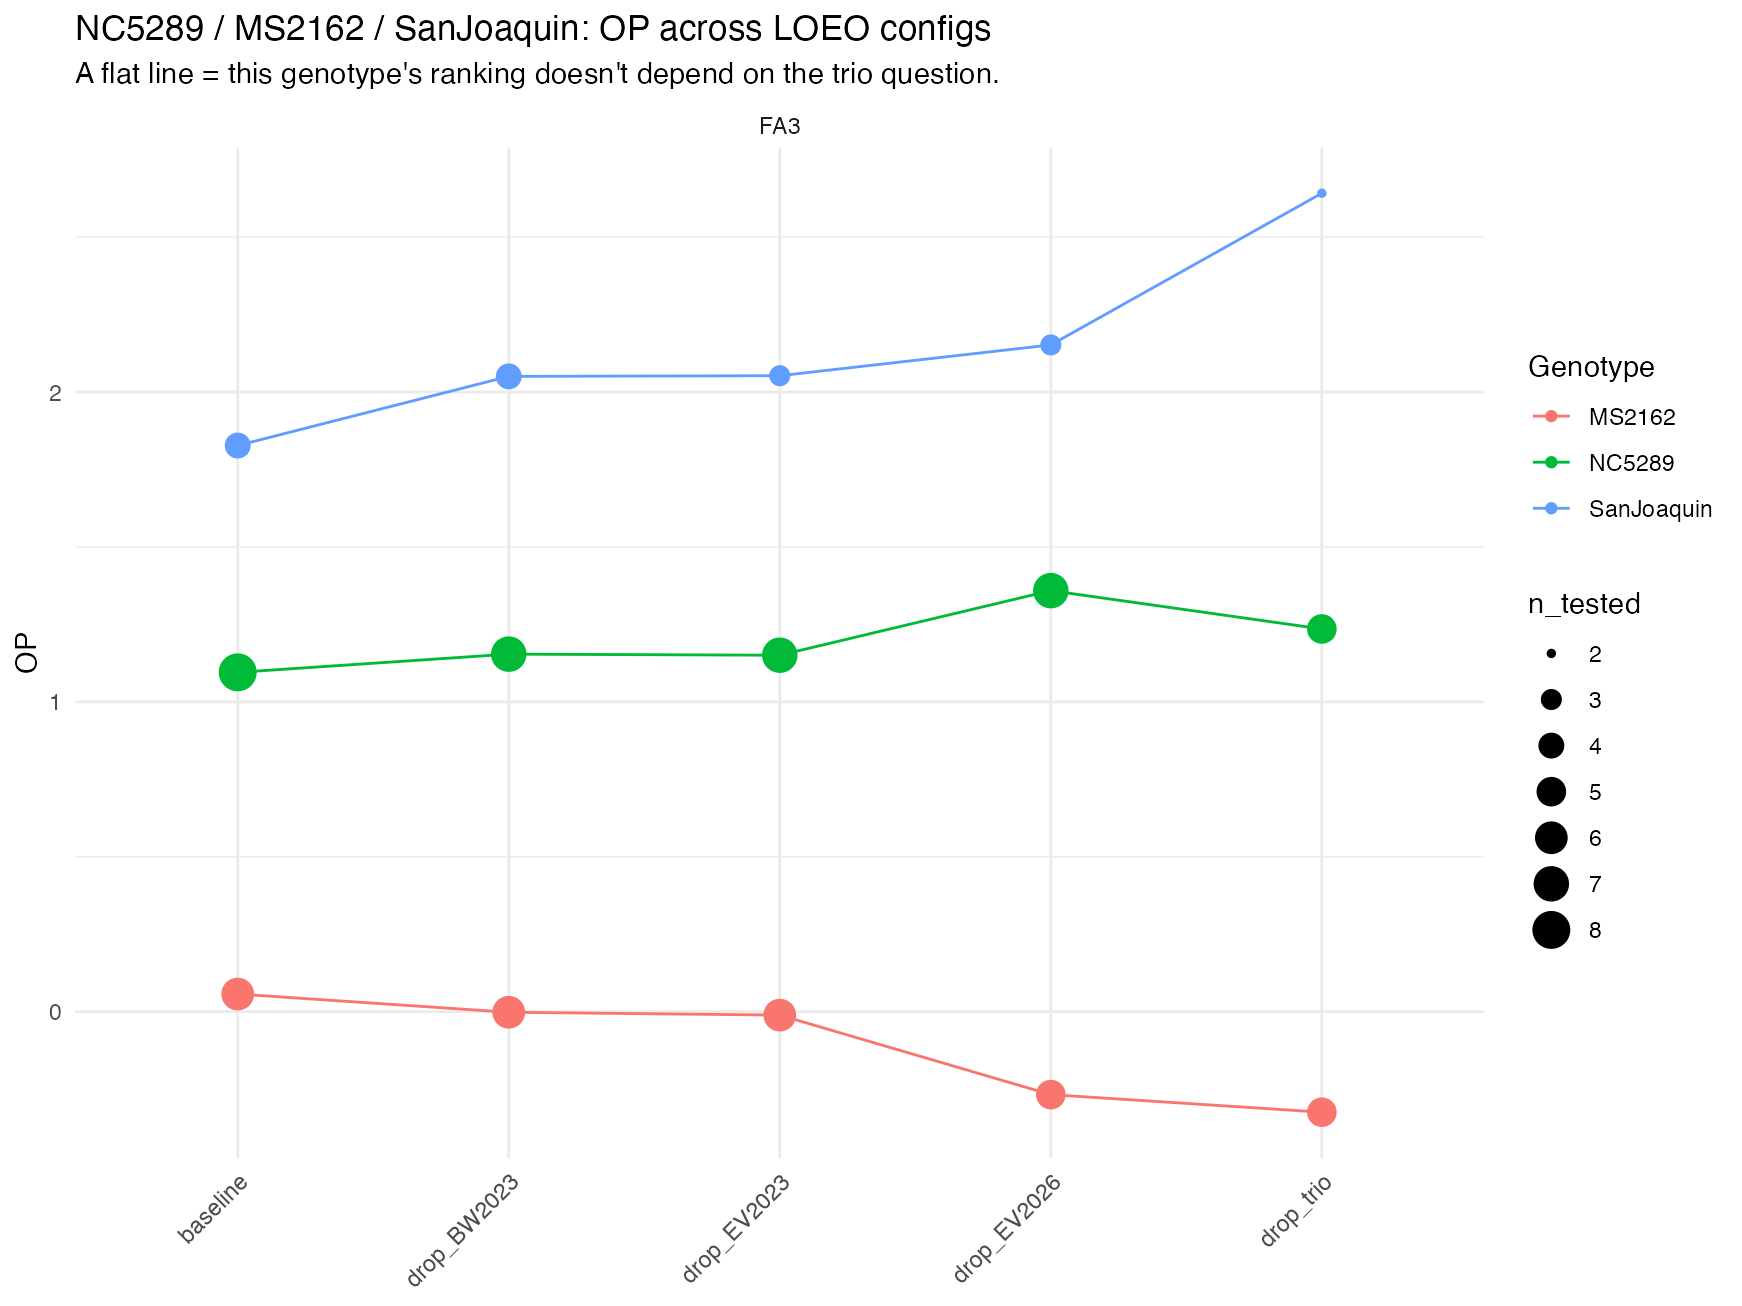

In [257]:
plot_watch_genotype_tracking(res_wa3)

### FW, AMMI, & GGE

In [ ]:
library(statgen)

In [5]:
source('R/R/prepare_fa_dta.R')
tar_load(prep_yield)
tar_load(blup_fa2_asr)

In [6]:
reconstruct_adjusted_means <- function(blup_long, env_stats) {
  blup_long %>%
    left_join(env_stats, by = "Env") %>%
    mutate(trait = mean_env + blup * sd_env)  
}                                                

# env_stats comes straight from the same prep step that fit the model:
env_stats <- prep_and_scale_dta(prep_yield) %>% distinct(Env, mean_env, sd_env)

In [35]:
tar_load(prep_bloom_bloom5)
tar_load(blup_fa2_asr_bloom_bloom5)
bloom_stats <- prep_and_scale_dta(prep_bloom_bloom5) %>% distinct(Env, mean_env, sd_env)
blm <- reconstruct_adjusted_means(blup_fa2_asr_bloom_bloom5, bloom_stats)
td_b  <- prepare_td(blm)
fwb  <- run_fw(td_b)

Warning message:
In anova.lm(modelA) :
  ANOVA F-tests on an essentially perfect fit are unreliable


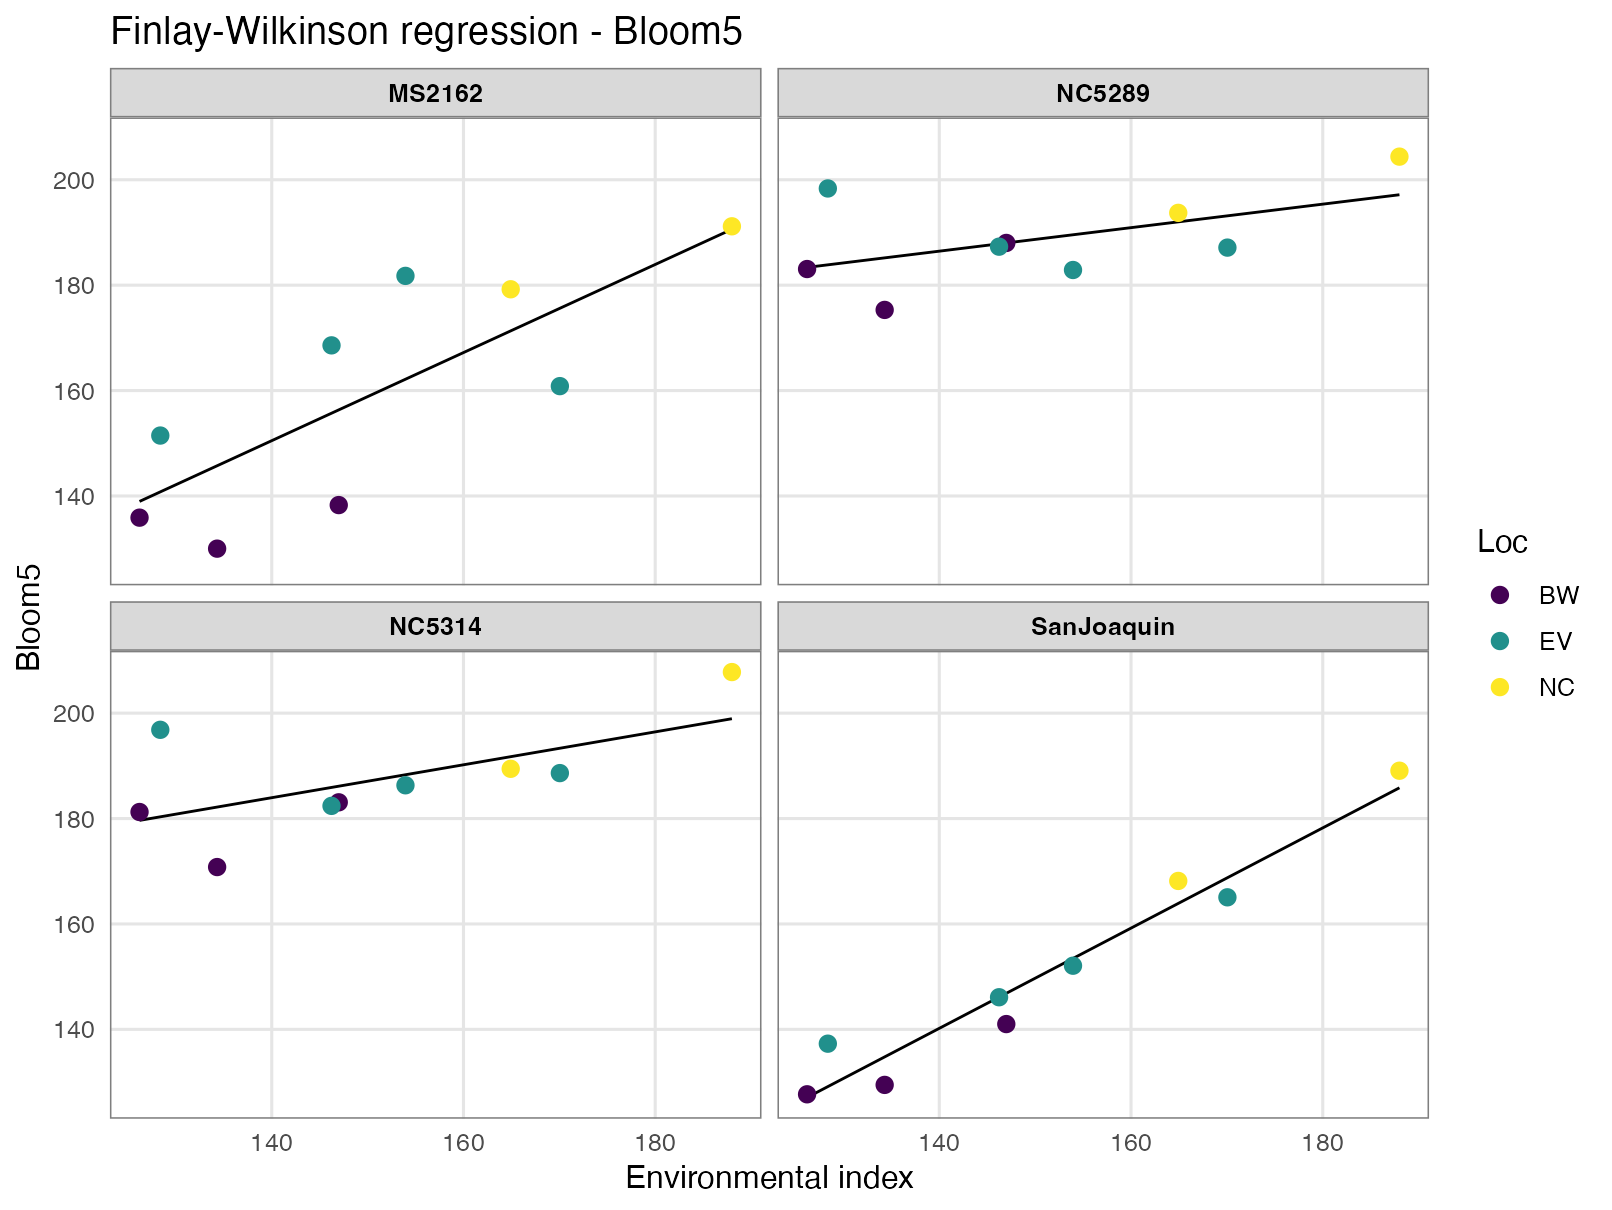

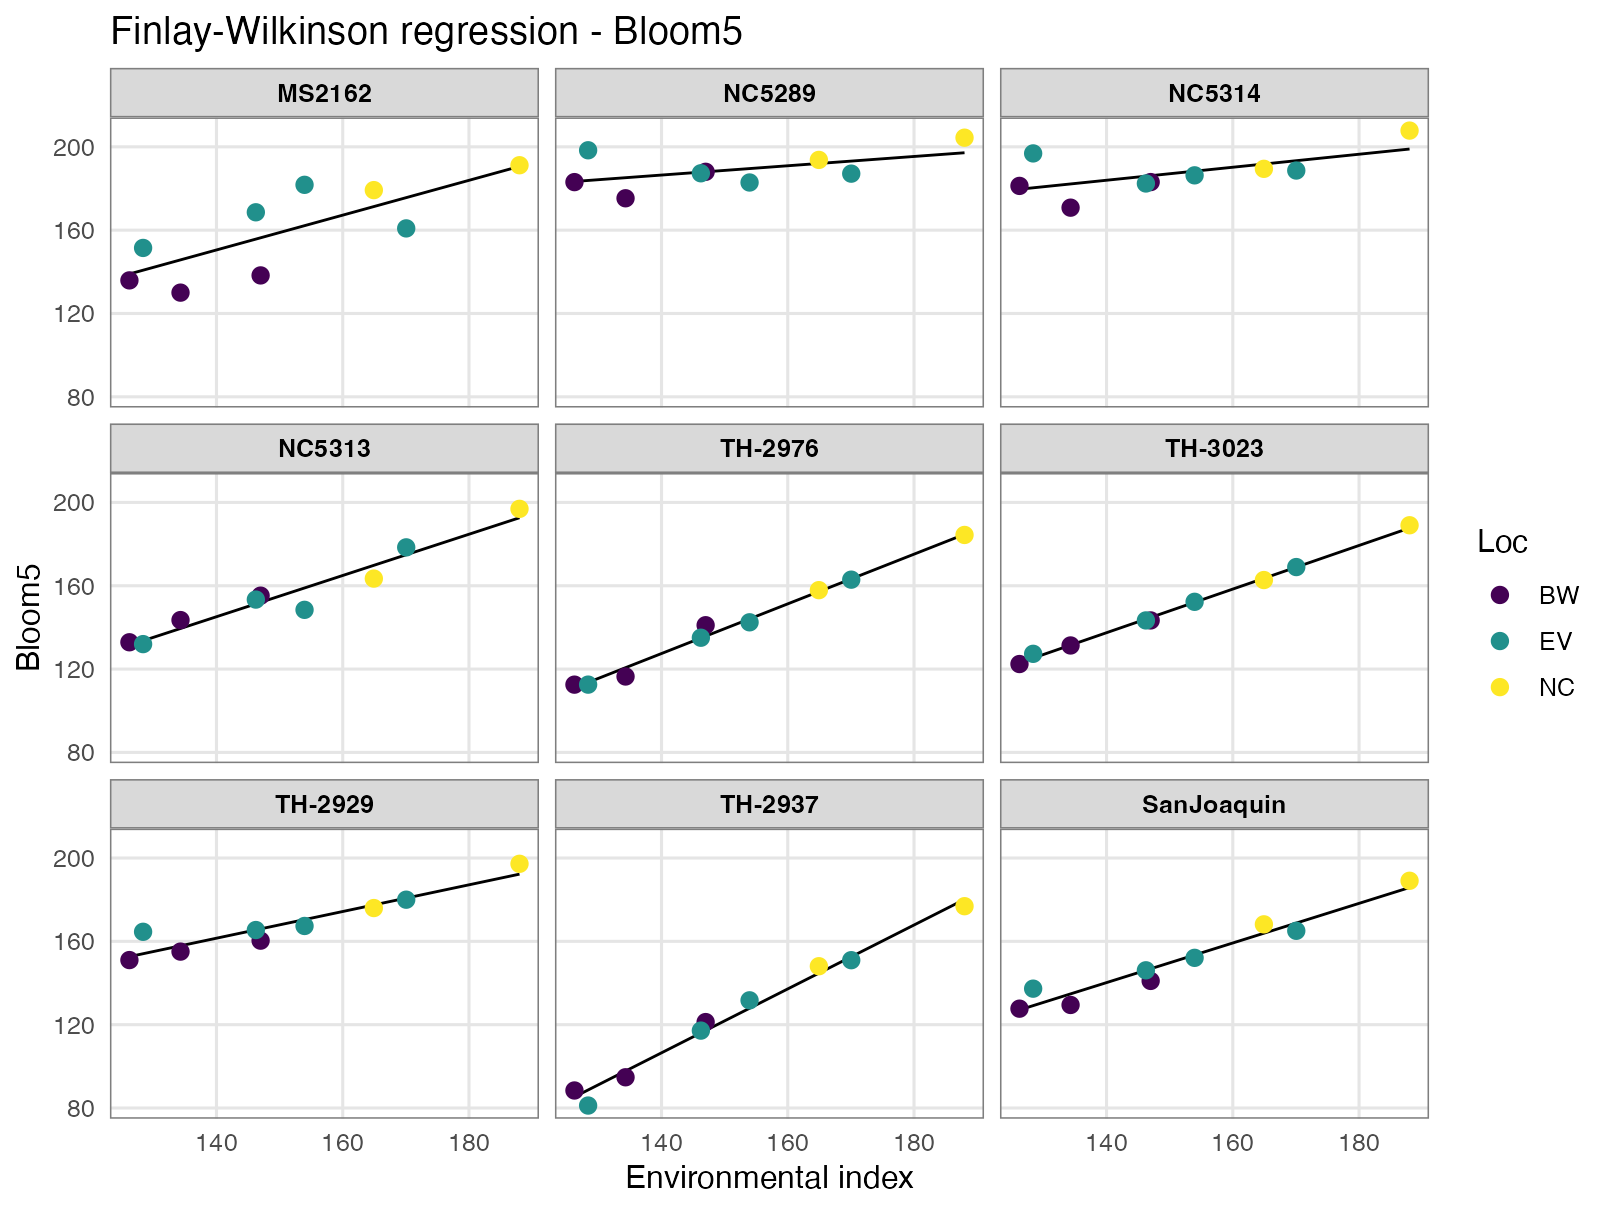

In [64]:
plot_fw_trellis(
  fwb$fit,
  genotypes = c("MS2162", "NC5289", "NC5314", "SanJoaquin"),
  trait_label = "Bloom5",
  color_by = "loc"
)

plot_fw_trellis(
  fwb$fit,
  genotypes = c("MS2162", "NC5289", "NC5314", 'NC5313', "TH-2976", "TH-3023", "TH-2929", "TH-2937", "SanJoaquin"),
  trait_label = "Bloom5",
  color_by = "loc"
)

Warning message:
In anova.lm(modelA) :
  ANOVA F-tests on an essentially perfect fit are unreliable


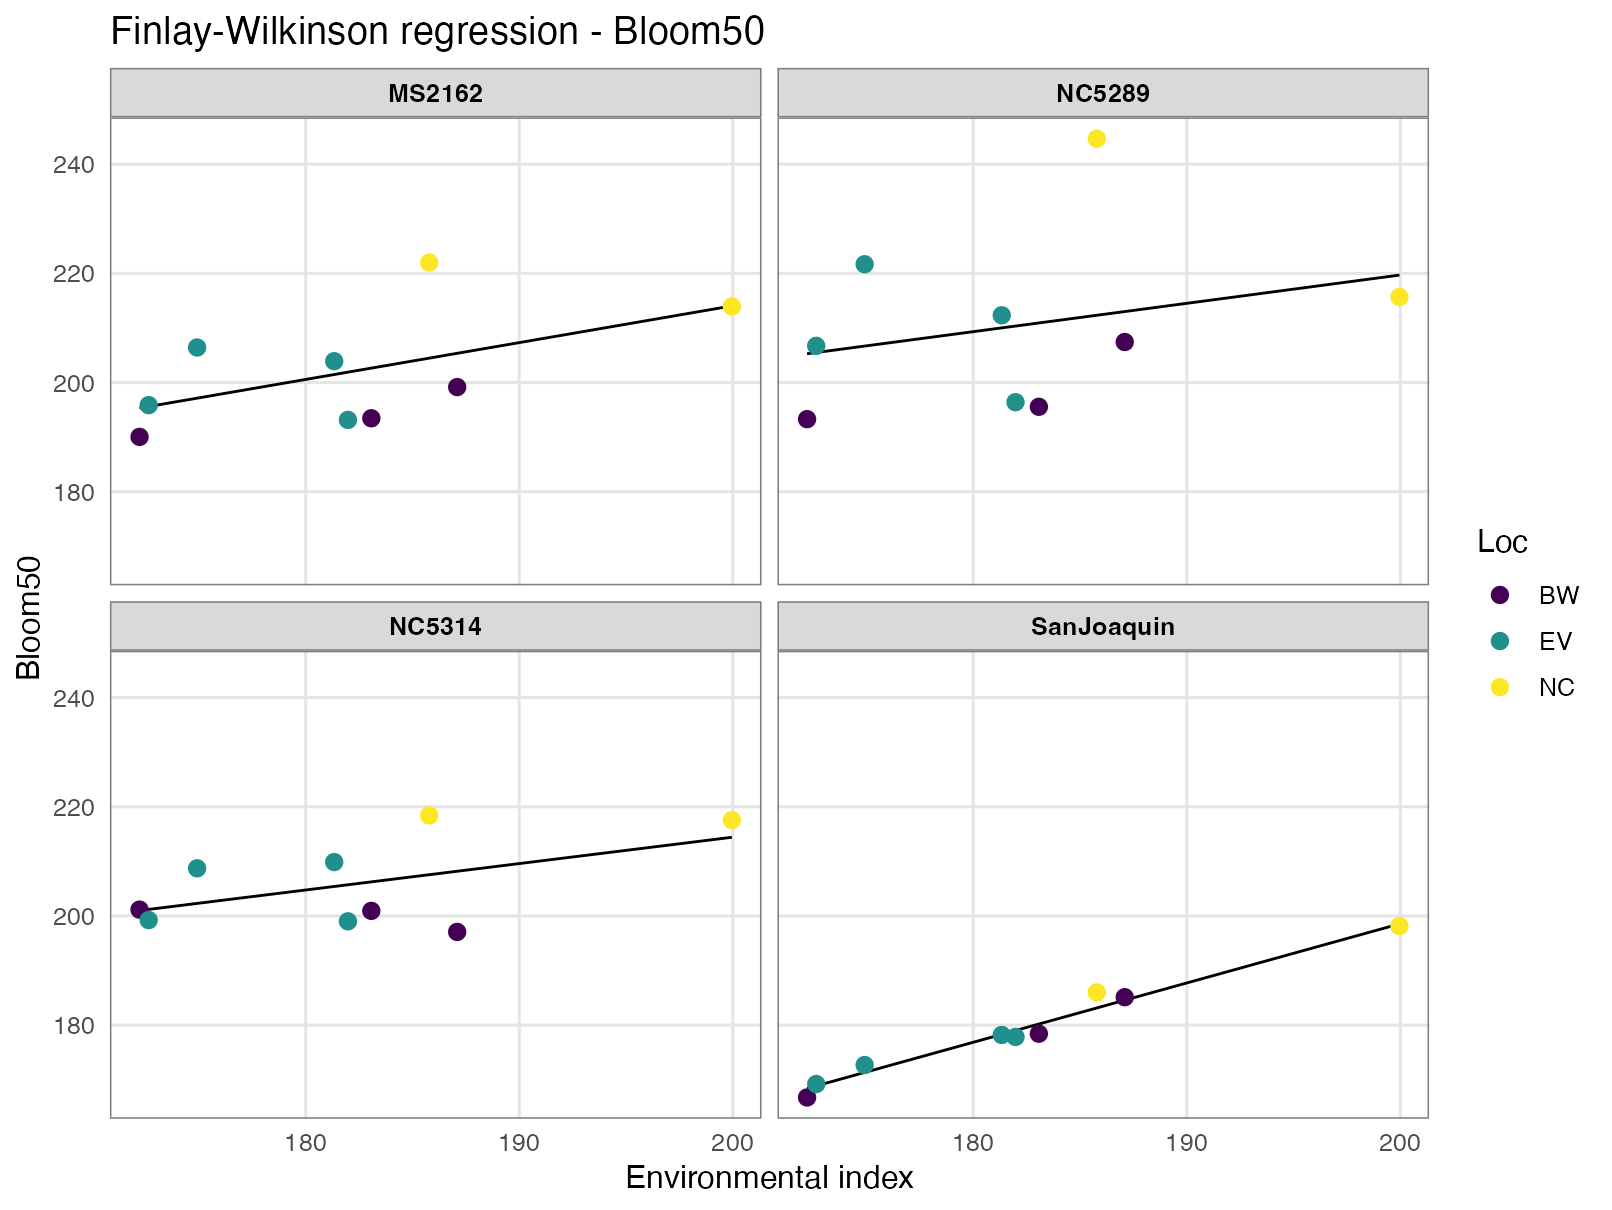

In [43]:
tar_load(prep_bloom_bloom50)
tar_load(blup_fa2_asr_bloom_bloom50)
bloom_stats <- prep_and_scale_dta(prep_bloom_bloom50) %>% distinct(Env, mean_env, sd_env)
blm50 <- reconstruct_adjusted_means(blup_fa2_asr_bloom_bloom50, bloom_stats)
td_b50  <- prepare_td(blm50)
fwb50  <- run_fw(td_b50)
plot_fw_trellis(
  fwb50$fit,
  genotypes = c("MS2162", "NC5289", "NC5314", "SanJoaquin"),
  trait_label = "Bloom50",
  color_by = "loc"
)

Warning message:
In anova.lm(modelA) :
  ANOVA F-tests on an essentially perfect fit are unreliable


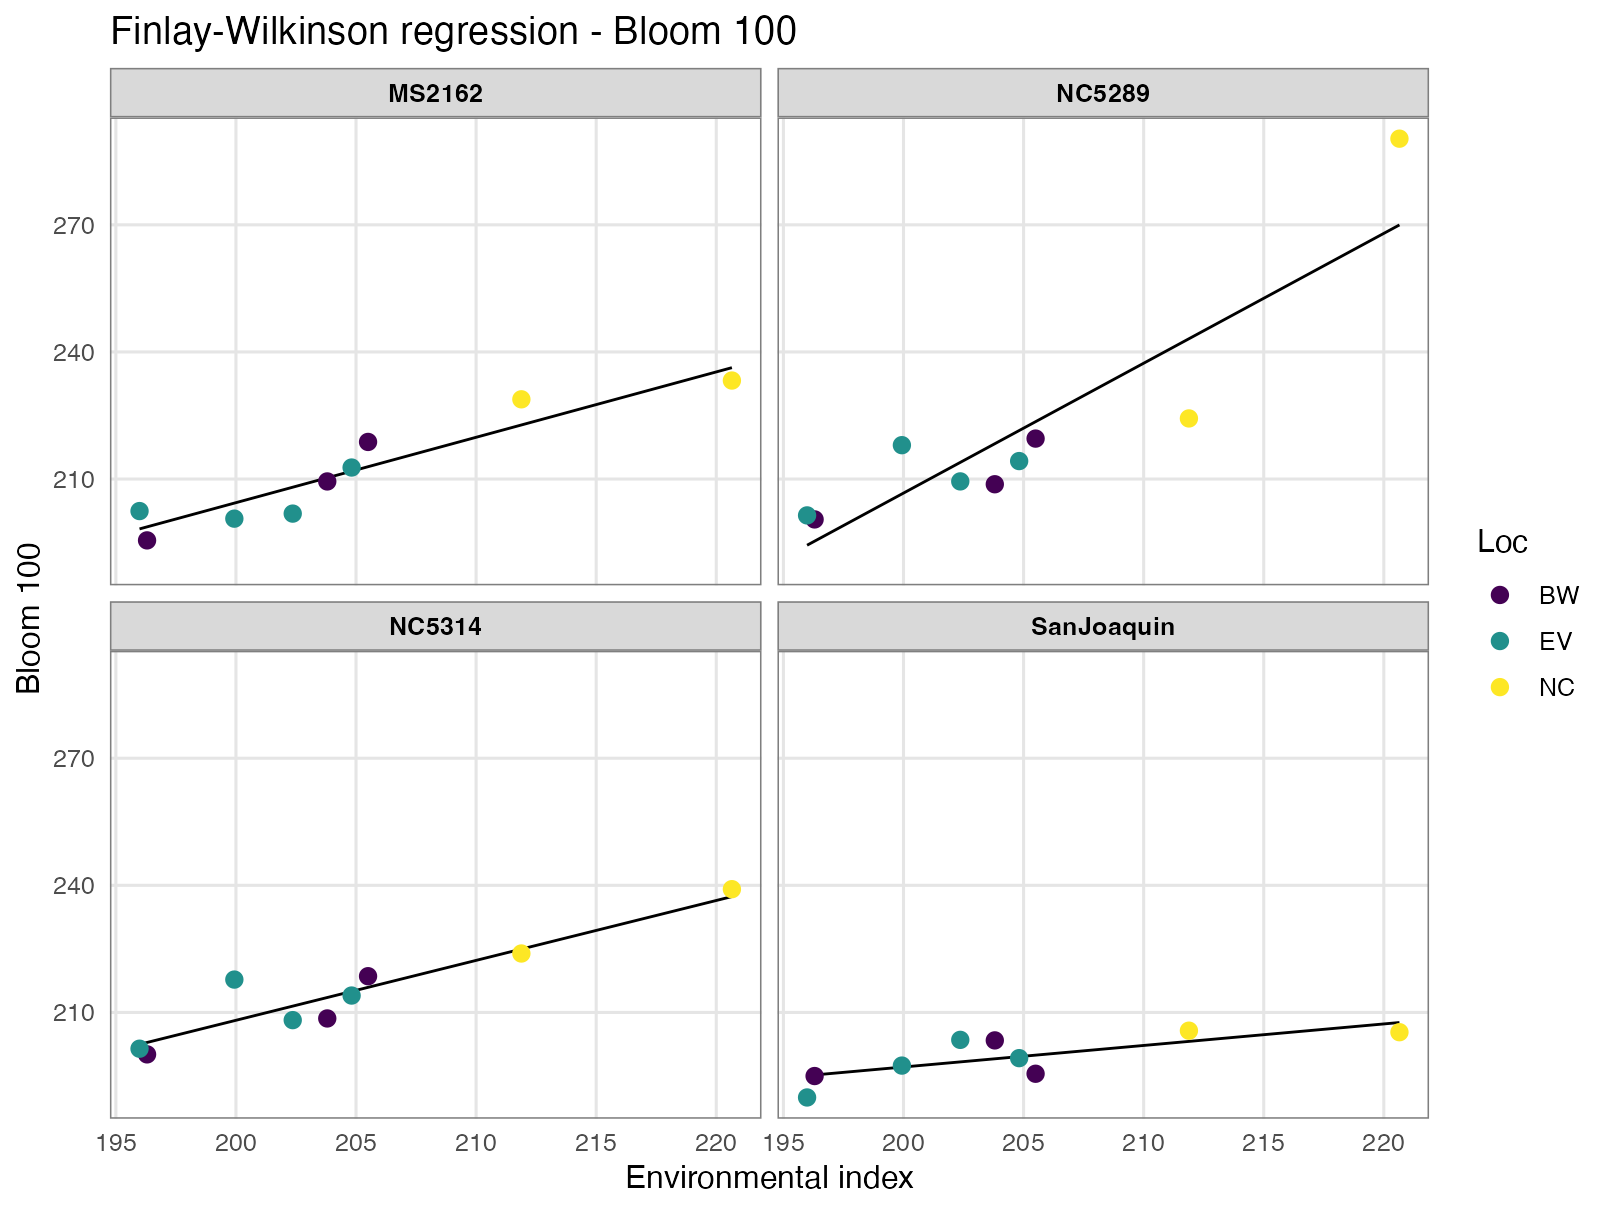

In [44]:
tar_load(prep_bloom_bloom100)
tar_load(blup_fa2_asr_bloom_bloom100)
bloom_stats <- prep_and_scale_dta(prep_bloom_bloom100) %>% distinct(Env, mean_env, sd_env)
blm50 <- reconstruct_adjusted_means(blup_fa2_asr_bloom_bloom100, bloom_stats)
td_b50  <- prepare_td(blm50)
fwb50  <- run_fw(td_b50)
plot_fw_trellis(
  fwb50$fit,
  genotypes = c("MS2162", "NC5289", "NC5314", "SanJoaquin"),
  trait_label = "Bloom 100",
  color_by = "loc"
)

Warning message:
In anova.lm(modelA) :
  ANOVA F-tests on an essentially perfect fit are unreliable


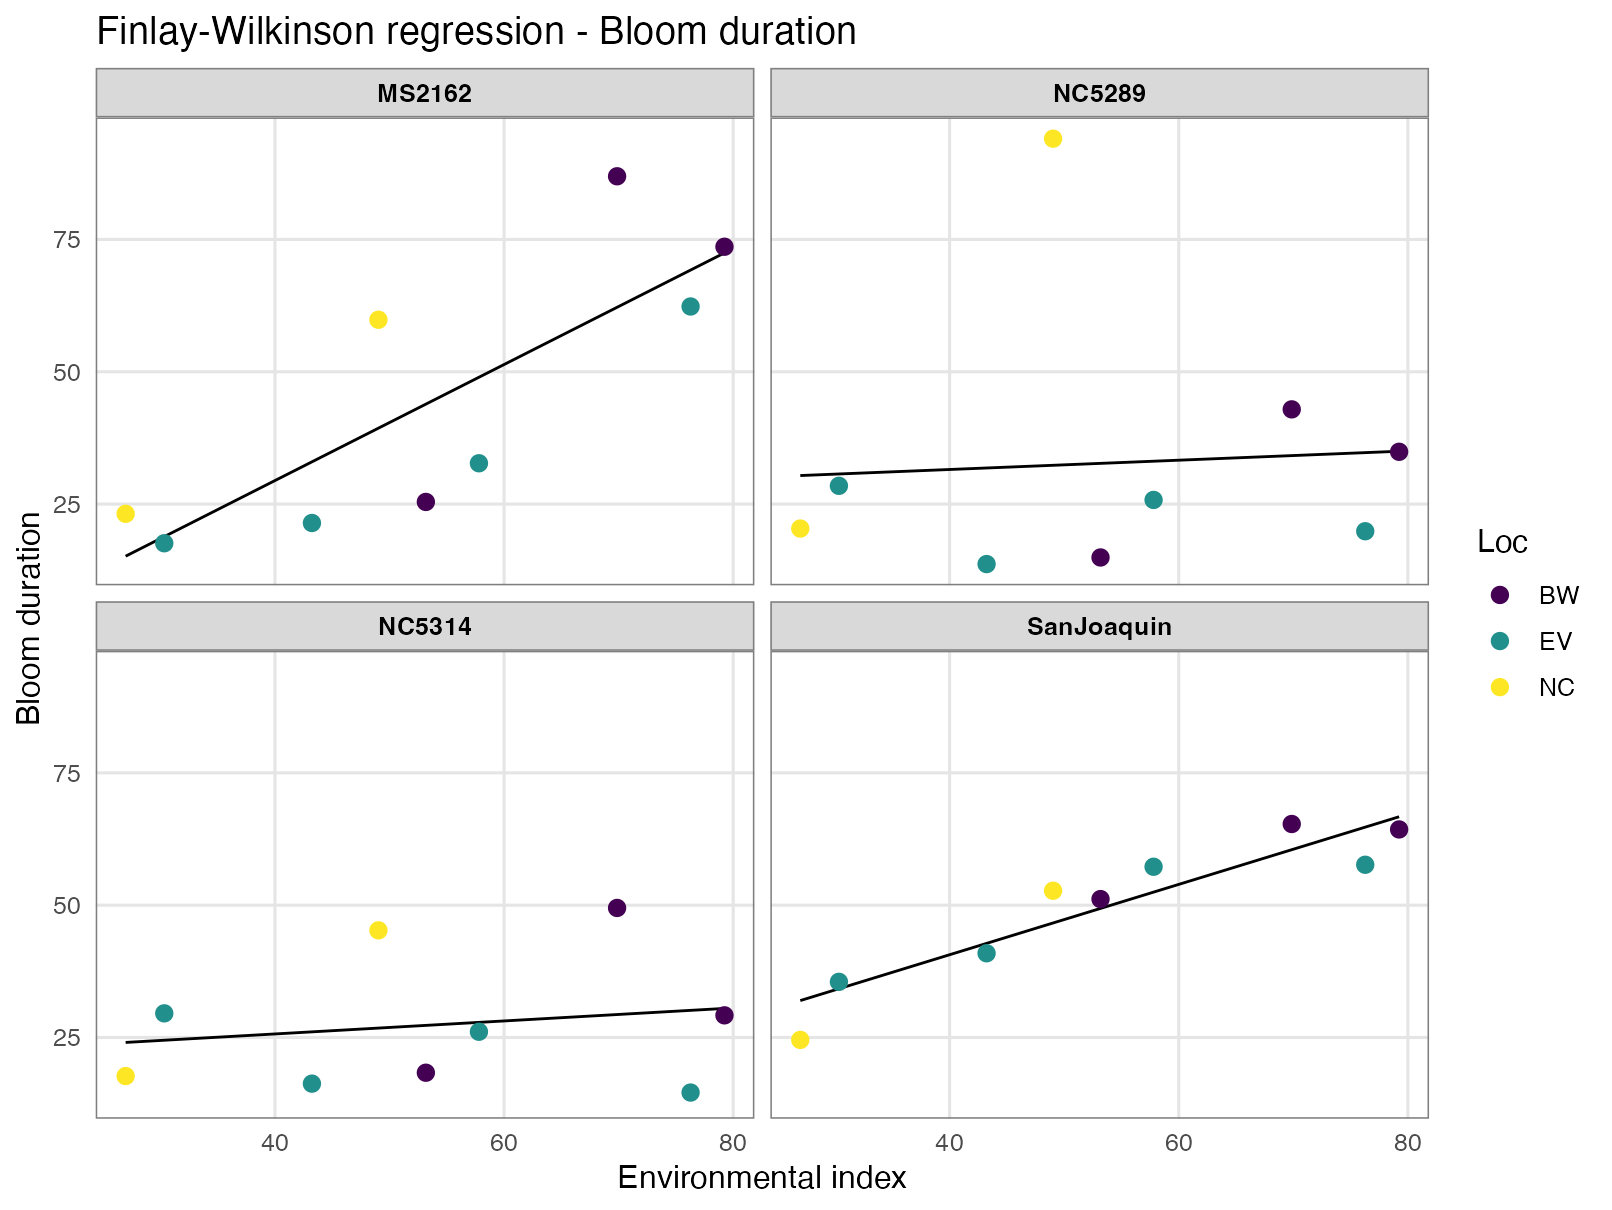

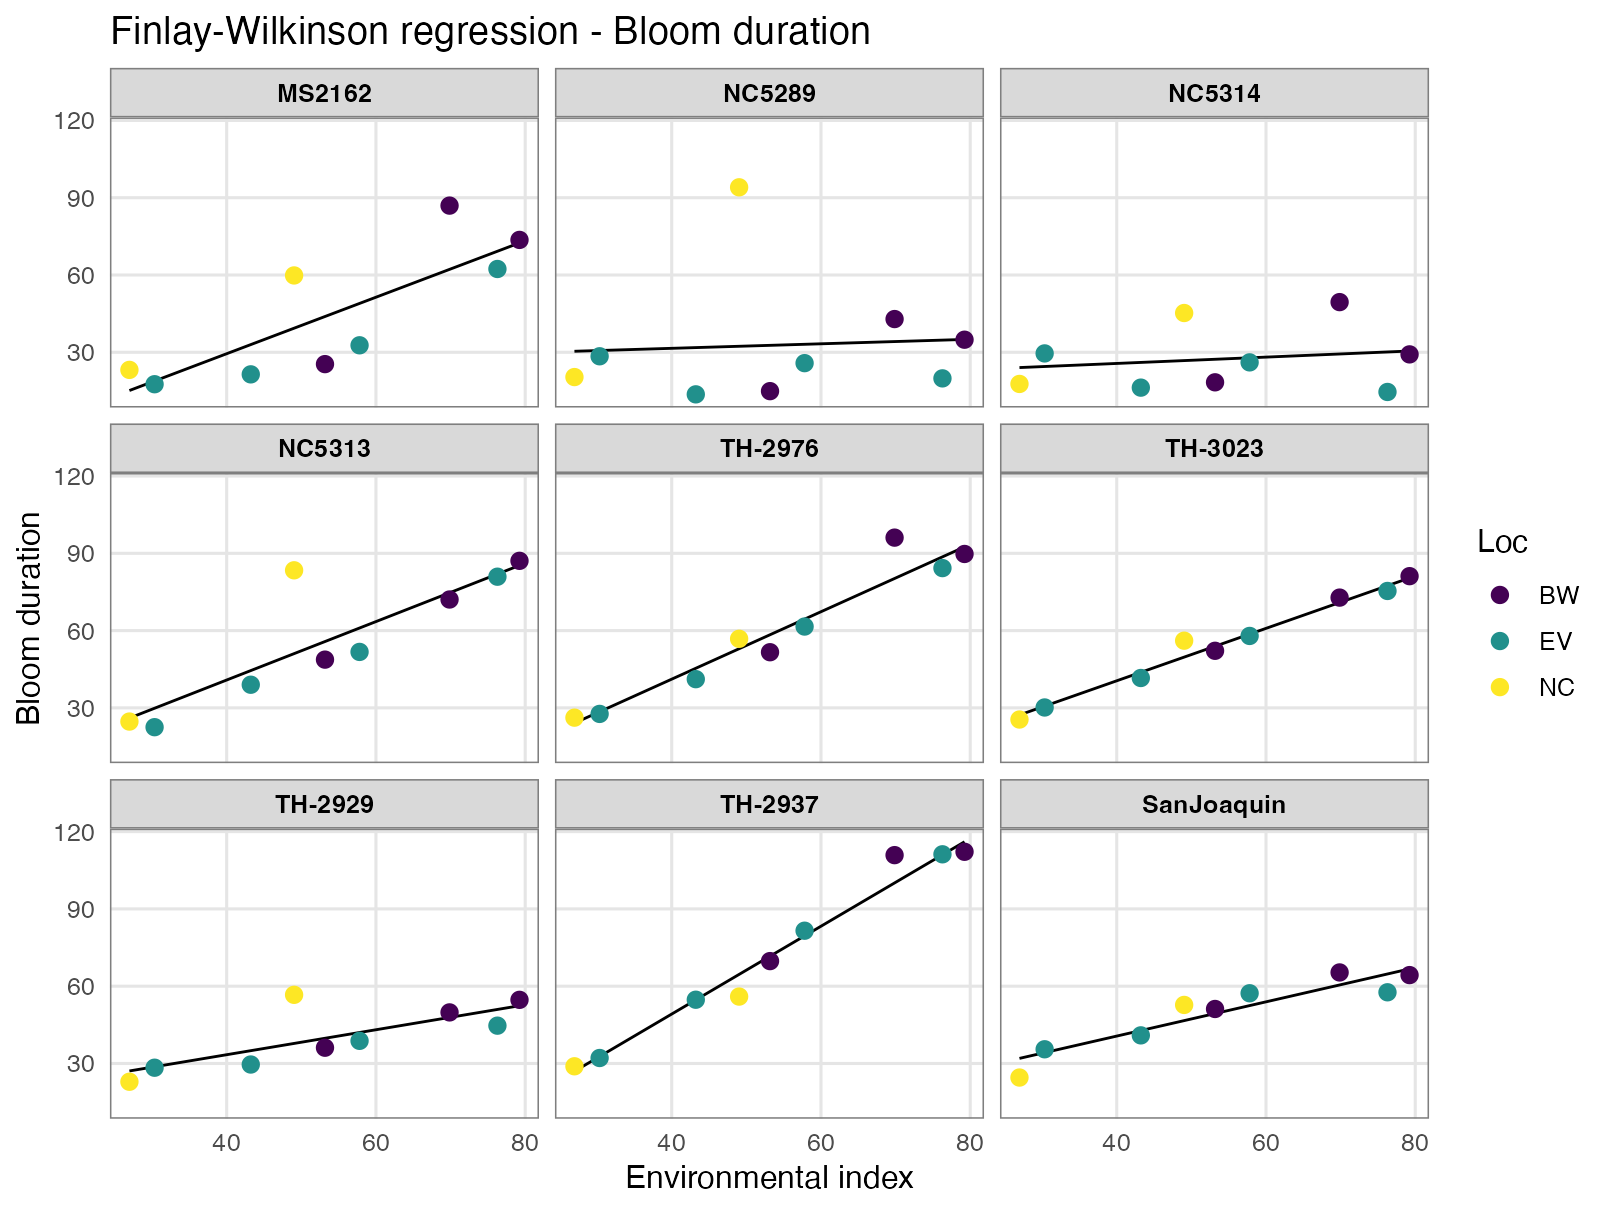

In [65]:
tar_load(prep_bloom_bloom_duration)
tar_load(blup_fa2_asr_bloom_bloom_duration)
bloom_stats <- prep_and_scale_dta(prep_bloom_bloom_duration) %>% distinct(Env, mean_env, sd_env)
blm50 <- reconstruct_adjusted_means(blup_fa2_asr_bloom_bloom_duration, bloom_stats)
td_b50  <- prepare_td(blm50)
fwb50  <- run_fw(td_b50)
plot_fw_trellis(
  fwb50$fit,
  genotypes = c("MS2162", "NC5289", "NC5314", "SanJoaquin"),
  trait_label = "Bloom duration",
  color_by = "loc"
)

plot_fw_trellis(
  fwb50$fit,
  genotypes = c("MS2162", "NC5289", "NC5314", 'NC5313', "TH-2976", "TH-3023", "TH-2929", "TH-2937", "SanJoaquin"),
  trait_label = "Bloom duration",
  color_by = "loc"
)

Warning message:
In anova.lm(modelA) :
  ANOVA F-tests on an essentially perfect fit are unreliable


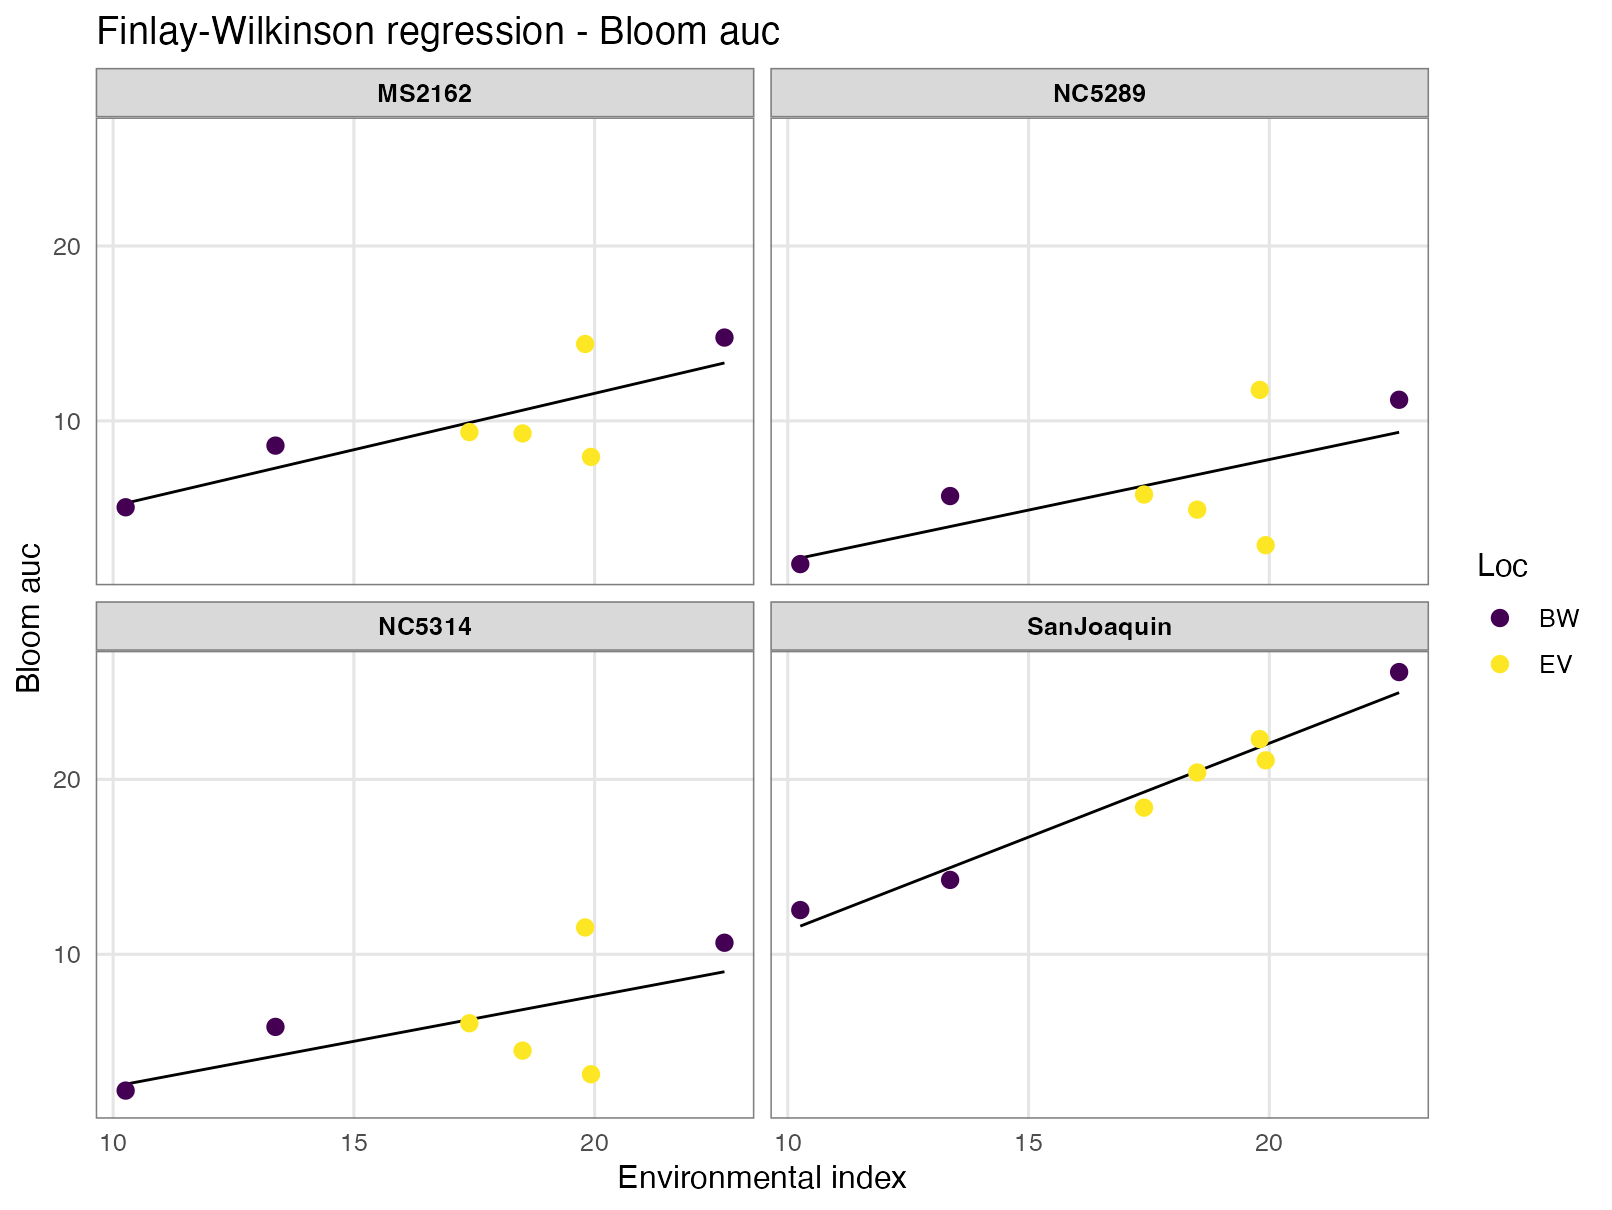

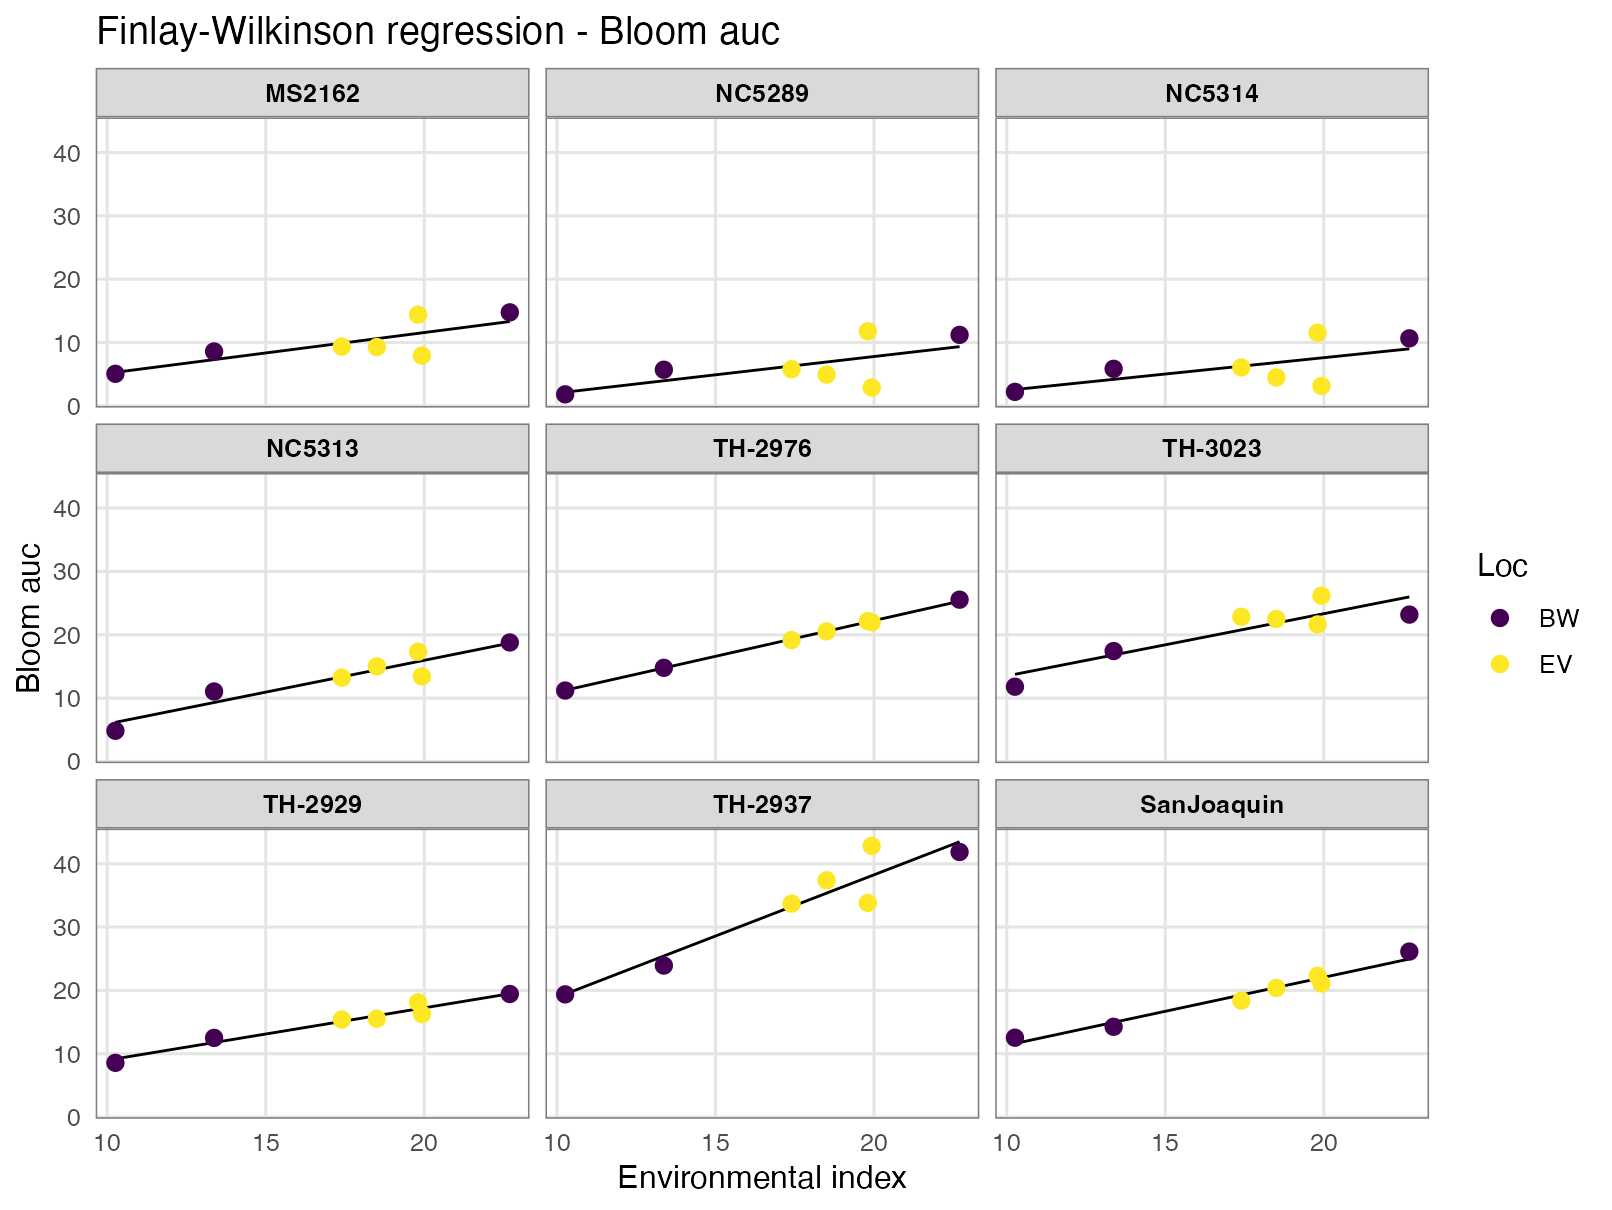

In [63]:
tar_load(prep_auc)
tar_load(blup_fa2_asr_auc)
bloom_stats <- prep_and_scale_dta(prep_auc) %>% distinct(Env, mean_env, sd_env)
blm50 <- reconstruct_adjusted_means(blup_fa2_asr_auc, bloom_stats)
td_b50  <- prepare_td(blm50)
fwb50  <- run_fw(td_b50)
plot_fw_trellis(
  fwb50$fit,
  genotypes = c("MS2162", "NC5289", "NC5314", "SanJoaquin"),
  trait_label = "Bloom auc",
  color_by = "loc"
)

plot_fw_trellis(
  fwb50$fit,
  genotypes = c("MS2162", "NC5289", "NC5314", 'NC5313', "TH-2976", "TH-3023", "TH-2929", "TH-2937", "SanJoaquin"),
  trait_label = "Bloom auc",
  color_by = "loc"
)

In [90]:
bl <- reconstruct_adjusted_means(blup_fa3_asr, env_stats)
td   <- prepare_td(bl)

In [91]:
fw   <- run_fw(td)

Warning message:
In anova.lm(modelA) :
  ANOVA F-tests on an essentially perfect fit are unreliable


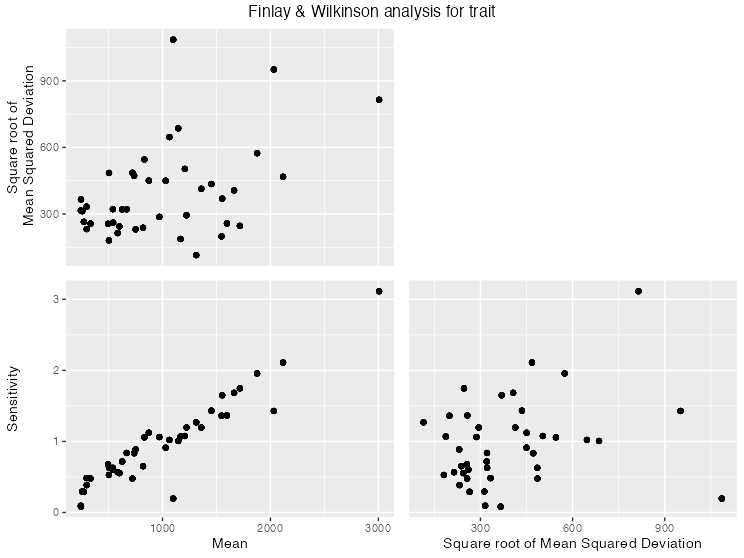

In [92]:
fw$plot_scatter()

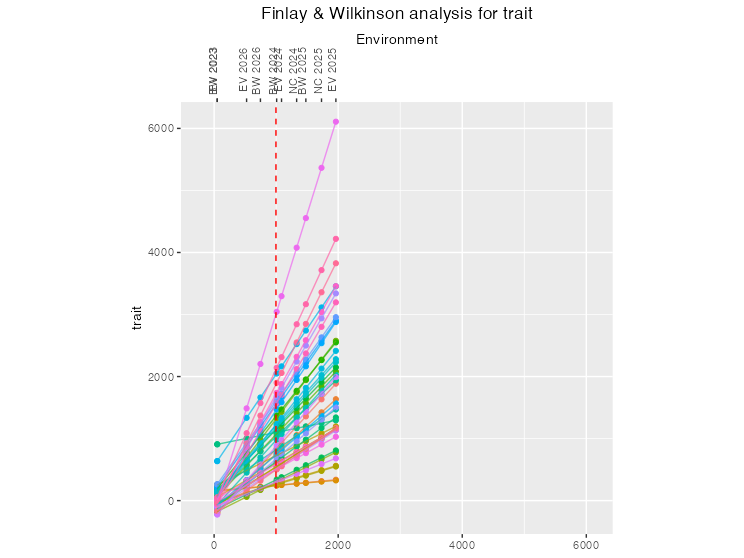

In [93]:
fw$plot_line()

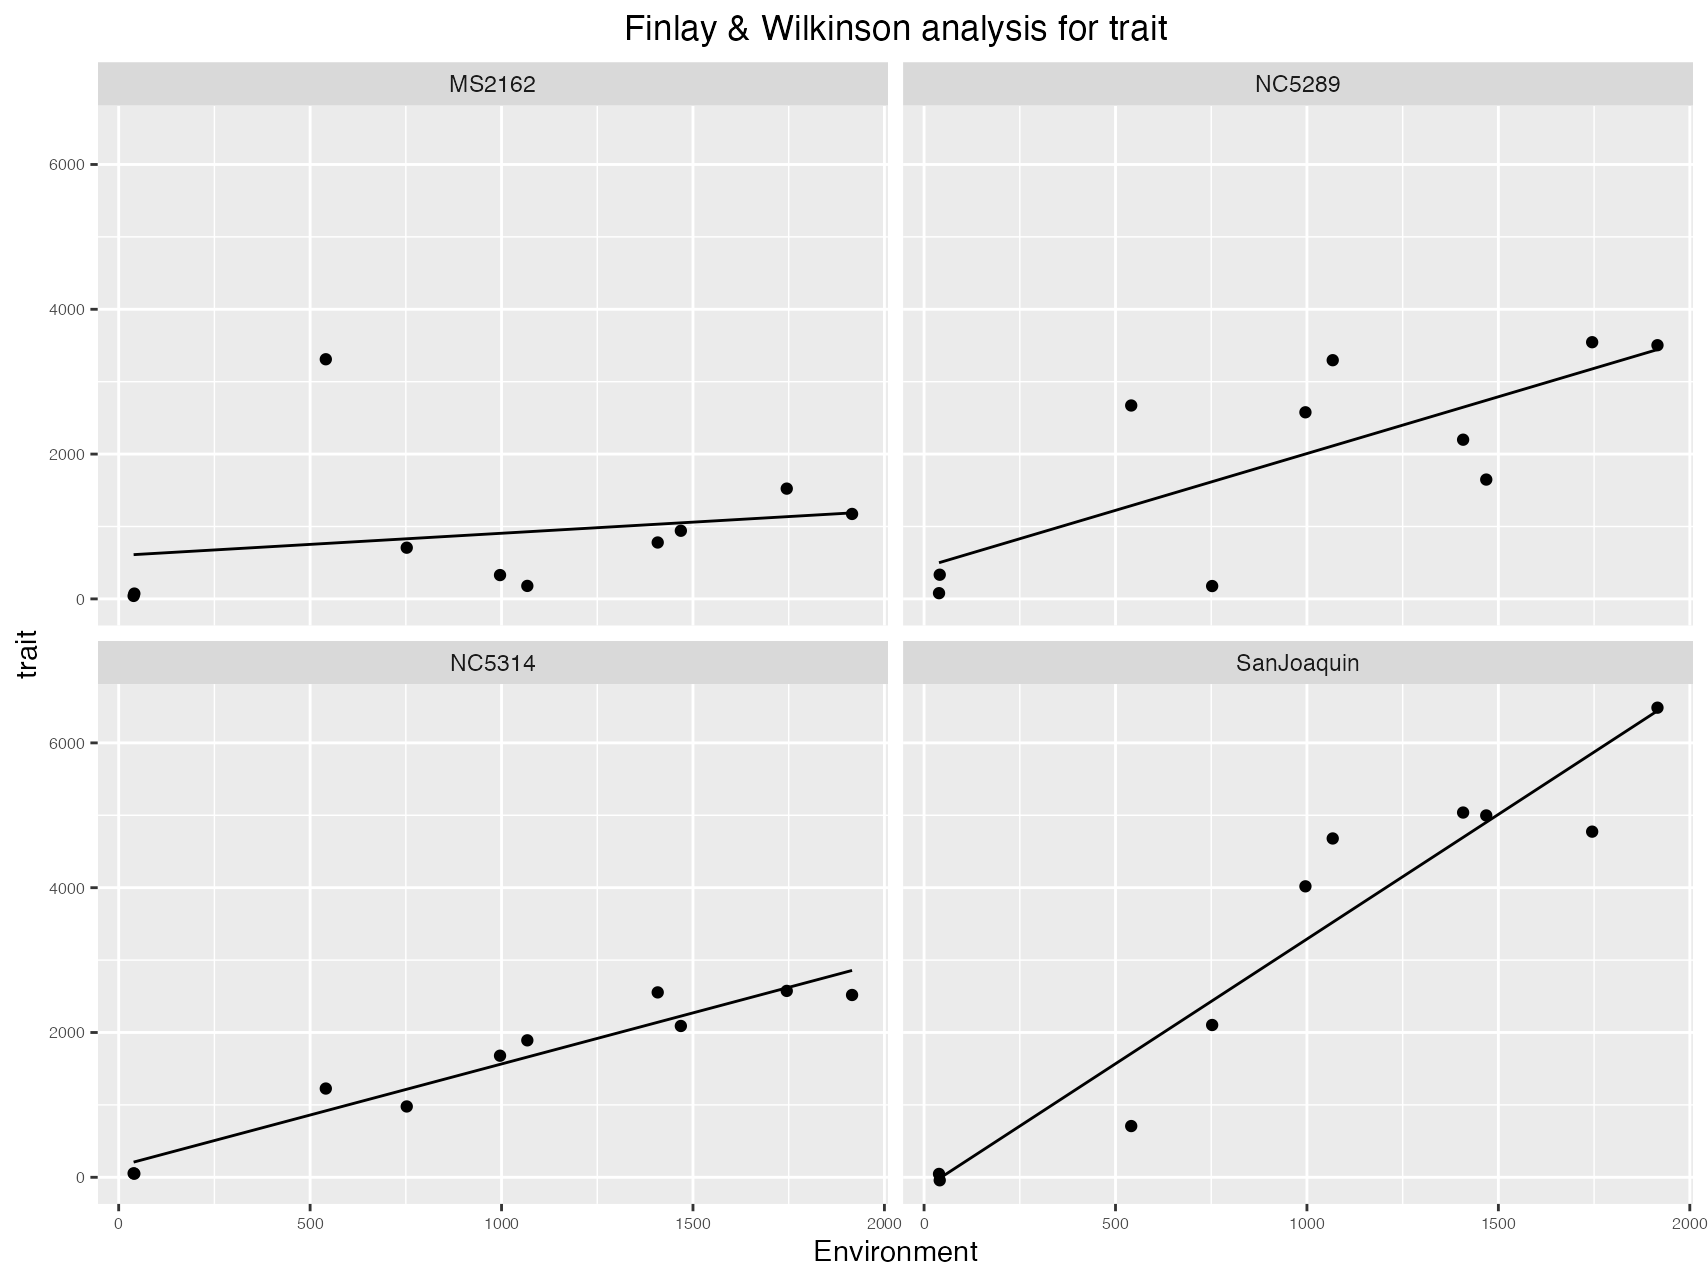

In [11]:
## Create trellis plot for Finlay Wilkinson analysis.
## Restrict to first 5 genotypes.
plot(fw$fit, plotType = "trellis", genotypes = c('NC5289', 'MS2162', 'SanJoaquin', 'NC5314'))

In [21]:
library(dplyr)
library(ggplot2)
library(ggrepel)

# Finlay-Wilkinson trellis, built directly from raw genotype-environment
# means rather than from gxeFw()'s internal fit object -- lets us color by
# environment and control styling without needing to know statgenGxE's
# exact internal field names.
#
# Environmental index = each environment's mean trait value across the
# FULL genotype panel (classic Finlay & Wilkinson 1963 definition) -- this
# must be computed from the whole panel, not just the genotypes you're
# plotting, since the point of the index is "how good was this environment
# in general," independent of which genotypes you're highlighting.
plot_fw_trellis <- function(dta, genotypes, trait_label = "Yield",
                             env_col = "Env", geno_col = "Genotype", y_col = "y") {

  # 1. environmental index from the FULL panel
  env_index <- dta %>%
    group_by(.data[[env_col]]) %>%
    summarise(index = mean(.data[[y_col]], na.rm = TRUE), .groups = "drop")

  # 2. subset to the genotypes of interest, join index
  plot_dta <- dta %>%
    filter(.data[[geno_col]] %in% genotypes) %>%
    group_by(.data[[geno_col]], .data[[env_col]]) %>%
    summarise(y = mean(.data[[y_col]], na.rm = TRUE), .groups = "drop") %>%
    left_join(env_index, by = env_col) %>%
    mutate(!!geno_col := factor(.data[[geno_col]], levels = genotypes))

  # 3. per-genotype FW slope/intercept, for an annotation (same numbers
  # gxeFw()'s own estimates table would give you, just fit locally)
  fw_coefs <- plot_dta %>%
    group_by(.data[[geno_col]]) %>%
    summarise(
      n = n(),
      slope = if (n() >= 2) coef(lm(y ~ index))[2] else NA_real_,
      .groups = "drop"
    ) %>%
    mutate(label = sprintf("b1 = %.2f", slope))

  ggplot(plot_dta, aes(x = index, y = y)) +
    geom_smooth(method = "lm", se = FALSE, colour = "grey30", linewidth = 0.6) +
    geom_point(aes(colour = .data[[env_col]]), size = 2.8) +
    geom_text(
      data = fw_coefs, aes(label = label),
      x = -Inf, y = Inf, hjust = -0.15, vjust = 1.5,
      inherit.aes = FALSE, size = 3.2, colour = "grey30"
    ) +
    facet_wrap(vars(.data[[geno_col]]), scales = "free_y") +
    scale_colour_viridis_d(name = "Environment", option = "D") +
    labs(
      title = "Finlay-Wilkinson regression",
      subtitle = paste0(trait_label, " vs. environmental index (panel mean per environment)"),
      x = "Environmental index (mean across all genotypes)",
      y = trait_label
    ) +
    theme_minimal(base_size = 12) +
    theme(
      strip.background = element_rect(fill = "grey85", colour = "grey50"),
      strip.text        = element_text(colour = "black", face = "bold"),
      panel.border      = element_rect(colour = "grey50", fill = NA),
      panel.grid.minor  = element_blank(),
      panel.grid.major  = element_line(colour = "grey90")
    )
}



In [16]:
names(bl)

[1] "Genotype" "Env"      "blup"     "se"       "mean_env" "sd_env"   "trait"   

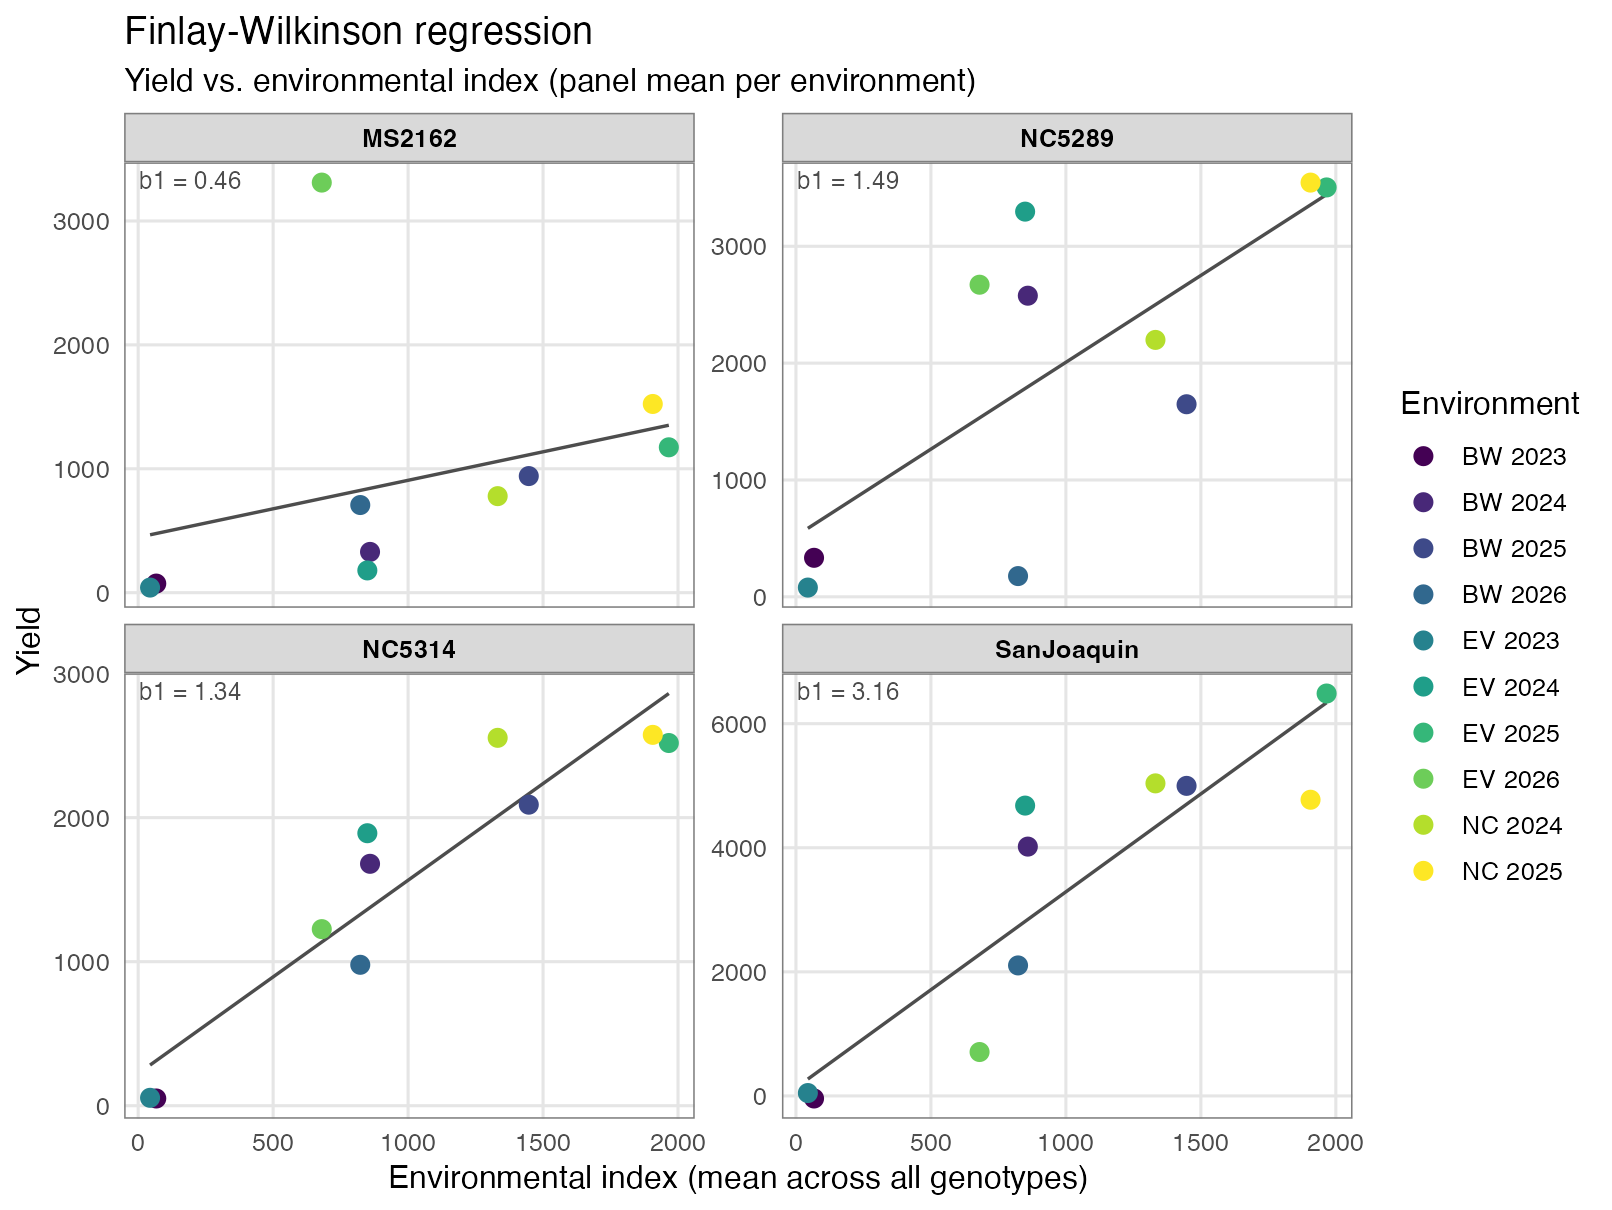

`geom_smooth()` using formula = 'y ~ x'

In [22]:
plot_fw_trellis(
  bl,
  genotypes = c("MS2162", "NC5289", "NC5314", "SanJoaquin"),
  trait_label = "Yield", y_col = 'trait'
)

In [30]:
plot_fw_trellis <- function(fw_fit, genotypes, trait_label = "Yield", color_by = "loc") {

  # one row per genotype x trial, with loc/year/trait kept for coloring
  td_long <- purrr::map_dfr(fw_fit$TD, as.data.frame, .id = "trial_name") %>%
    mutate(trial = as.character(trial))

  env_idx <- fw_fit$envEffs %>%
    transmute(trial = as.character(Trial), EnvMean)

  grand_index <- mean(env_idx$EnvMean)

  plot_dta <- td_long %>%
    left_join(env_idx, by = "trial") %>%
    filter(genotype %in% genotypes) %>%
    mutate(Genotype = factor(genotype, levels = genotypes))

  # fitted FW line per genotype: GenMean + Sens * (index - mean(index)) --
  # same line plot(fw_fit, plotType = "trellis") draws, read straight off
  # estimates rather than refit here
  line_dta <- fw_fit$estimates %>%
    filter(Genotype %in% genotypes) %>%
    mutate(Genotype = factor(Genotype, levels = genotypes)) %>%
    tidyr::crossing(index = range(env_idx$EnvMean)) %>%
    mutate(fitted = GenMean + Sens * (index - grand_index))

  ggplot(plot_dta, aes(x = EnvMean, y = trait)) +
    geom_line(data = line_dta, aes(x = index, y = fitted), colour = "black", linewidth = 0.5) +
    geom_point(aes(colour = .data[[color_by]]), size = 2.5) +
    facet_wrap(vars(Genotype)) +
    scale_colour_viridis_d(name = tools::toTitleCase(color_by)) +
    labs(x = "Environmental index", y = trait_label, title = paste0("Finlay-Wilkinson regression - ", trait_label)) +
    theme_minimal(base_size = 12) +
    theme(
      strip.background = element_rect(fill = "grey85", colour = "grey50"),
      strip.text        = element_text(colour = "black", face = "bold"),
      panel.border      = element_rect(colour = "grey50", fill = NA),
      panel.grid.minor  = element_blank(),
      panel.grid.major  = element_line(colour = "grey90")
    )
}



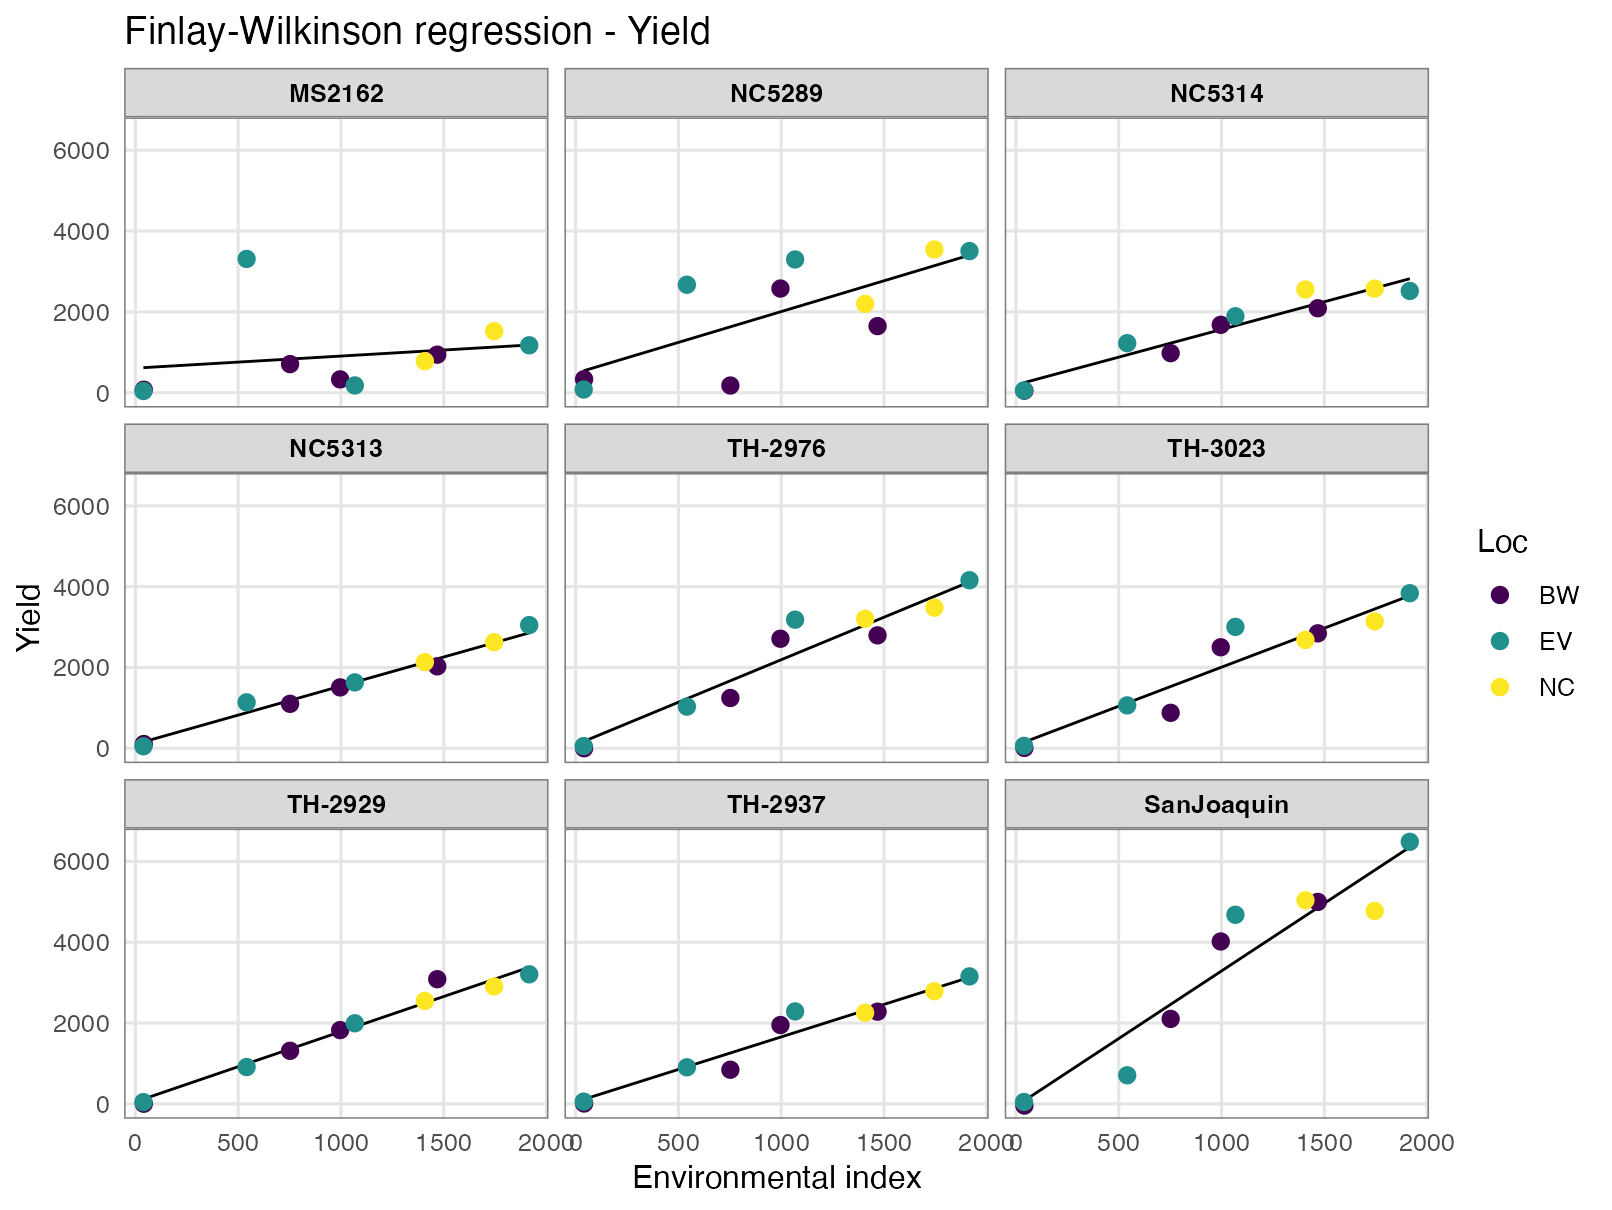

In [62]:
plot_fw_trellis(
  fw$fit,
  genotypes = c("MS2162", "NC5289", "NC5314", 'NC5313', "TH-2976", "TH-3023", "TH-2929", "TH-2937", "SanJoaquin"),
  trait_label = "Yield",
  color_by = "loc"
)

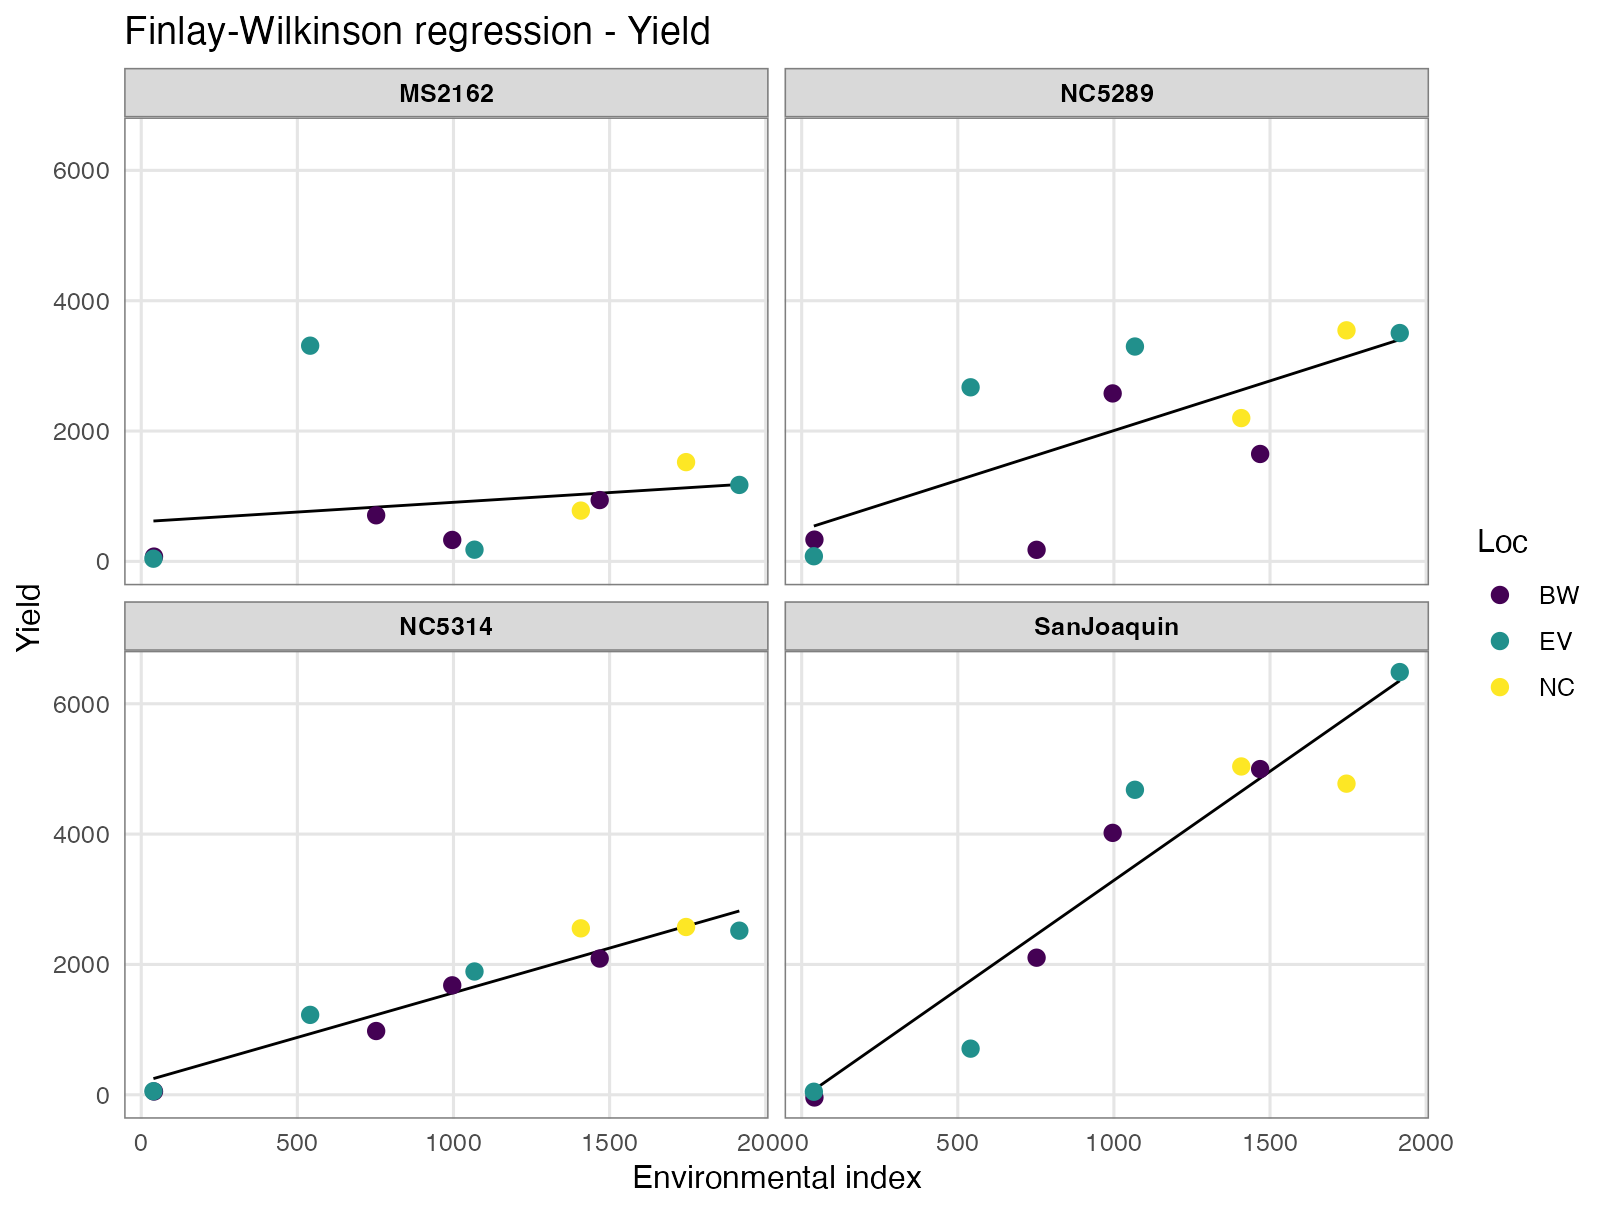

In [45]:
plot_fw_trellis(
  fw$fit,
  genotypes = c("MS2162", "NC5289", "NC5314", "SanJoaquin"),
  trait_label = "Yield",
  color_by = "loc"
)

In [48]:
tar_load(pc_scores_fa2_asr)

In [49]:
ammi <- run_ammi(td)
mega = run_mega(td)
stab = run_stability(td)


Cultivar-superiority measure (Top 2 % genotypes)
 Genotype     Mean Superiority
  FL11-52 155.4289     7880666

Static stability (Top 2 % genotypes)
   Genotype    Mean  Static
 SanJoaquin 3281.09 5616318

Wricke's ecovalence (Top 2 % genotypes)
   Genotype    Mean   Wricke
 SanJoaquin 3281.09 29156568


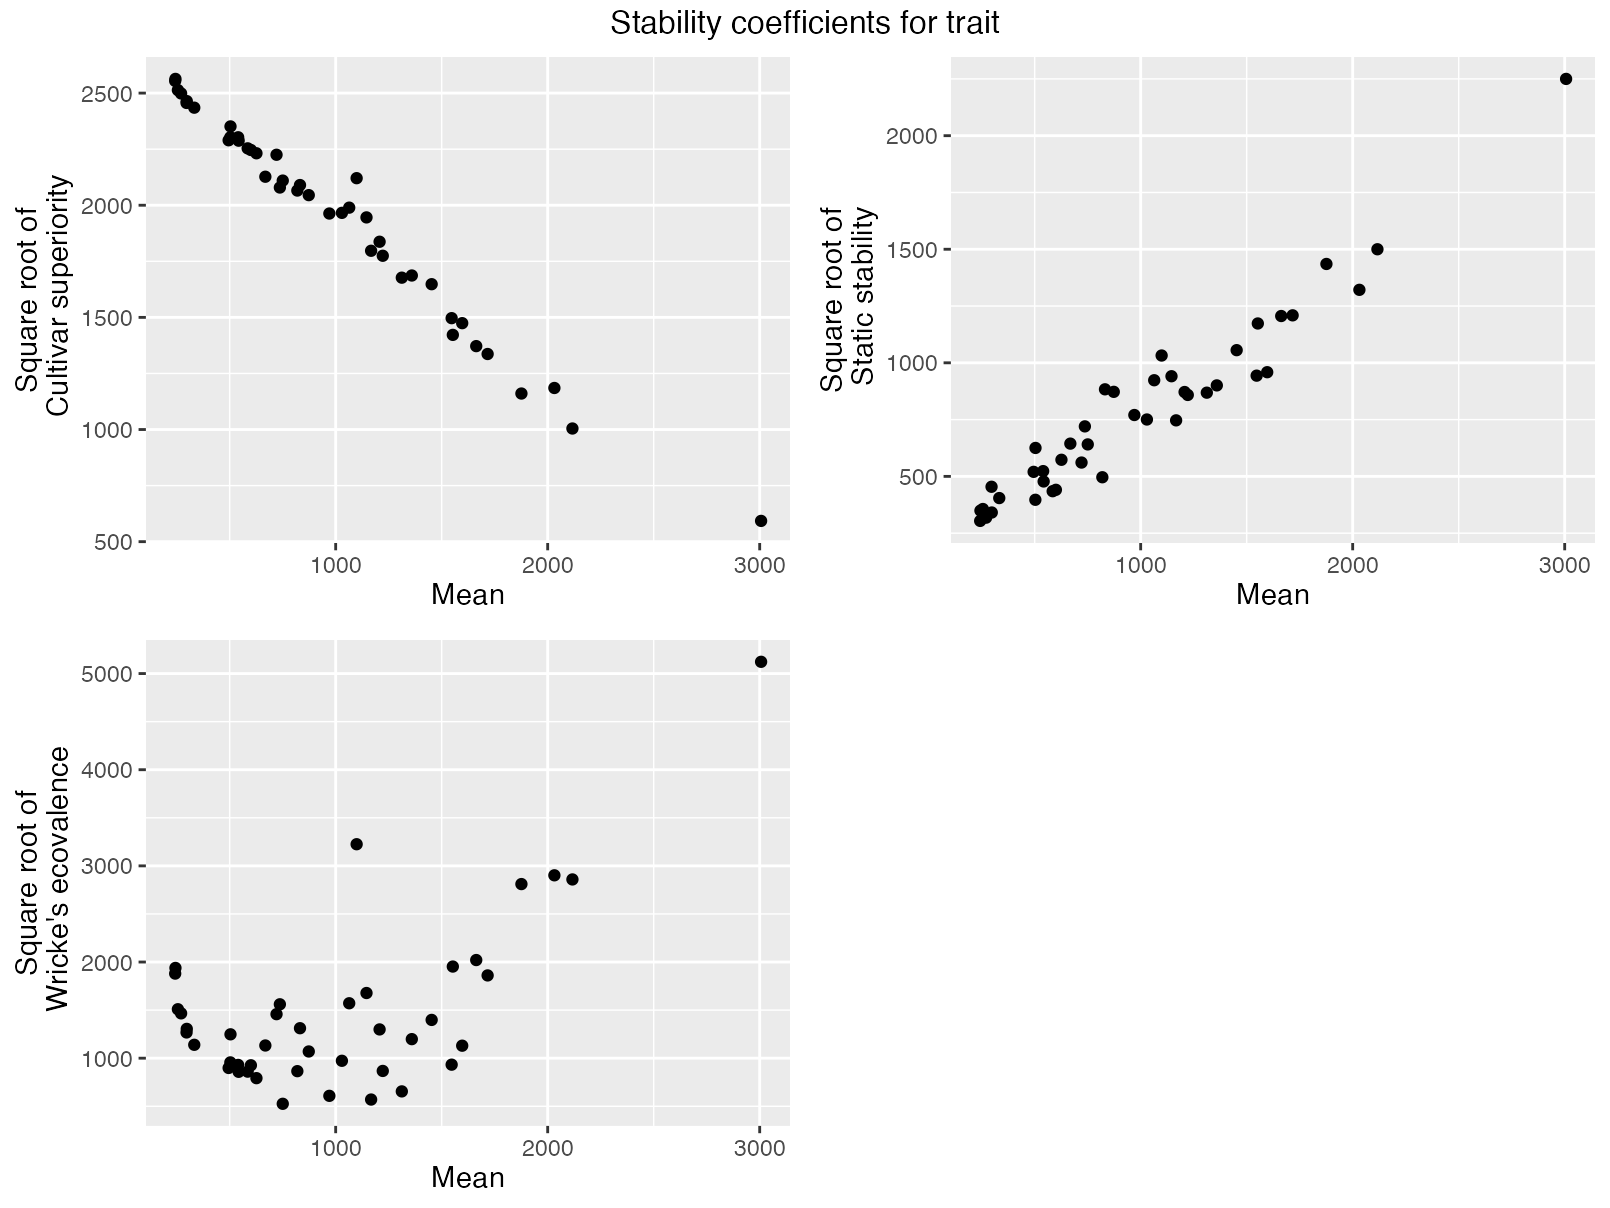

In [404]:
stab$plot_stab()

In [50]:
summary(mega$fit)

Mega environments based on trait

 Mega_factor   Trial Winning_genotype AMMI_estimates
   megaEnv_1 BW 2023           MS2162       862.4171
   megaEnv_1 EV 2023           MS2162       752.0676
   megaEnv_2 EV 2026           NC5289      2260.8886
   megaEnv_3 BW 2024       SanJoaquin      4010.8430
   megaEnv_3 BW 2025       SanJoaquin      5061.8231
   megaEnv_3 BW 2026       SanJoaquin      2081.1163
   megaEnv_3 EV 2024       SanJoaquin      4679.9822
   megaEnv_3 EV 2025       SanJoaquin      6235.6607
   megaEnv_3 NC 2024       SanJoaquin      5101.9602
   megaEnv_3 NC 2025       SanJoaquin      4966.4030


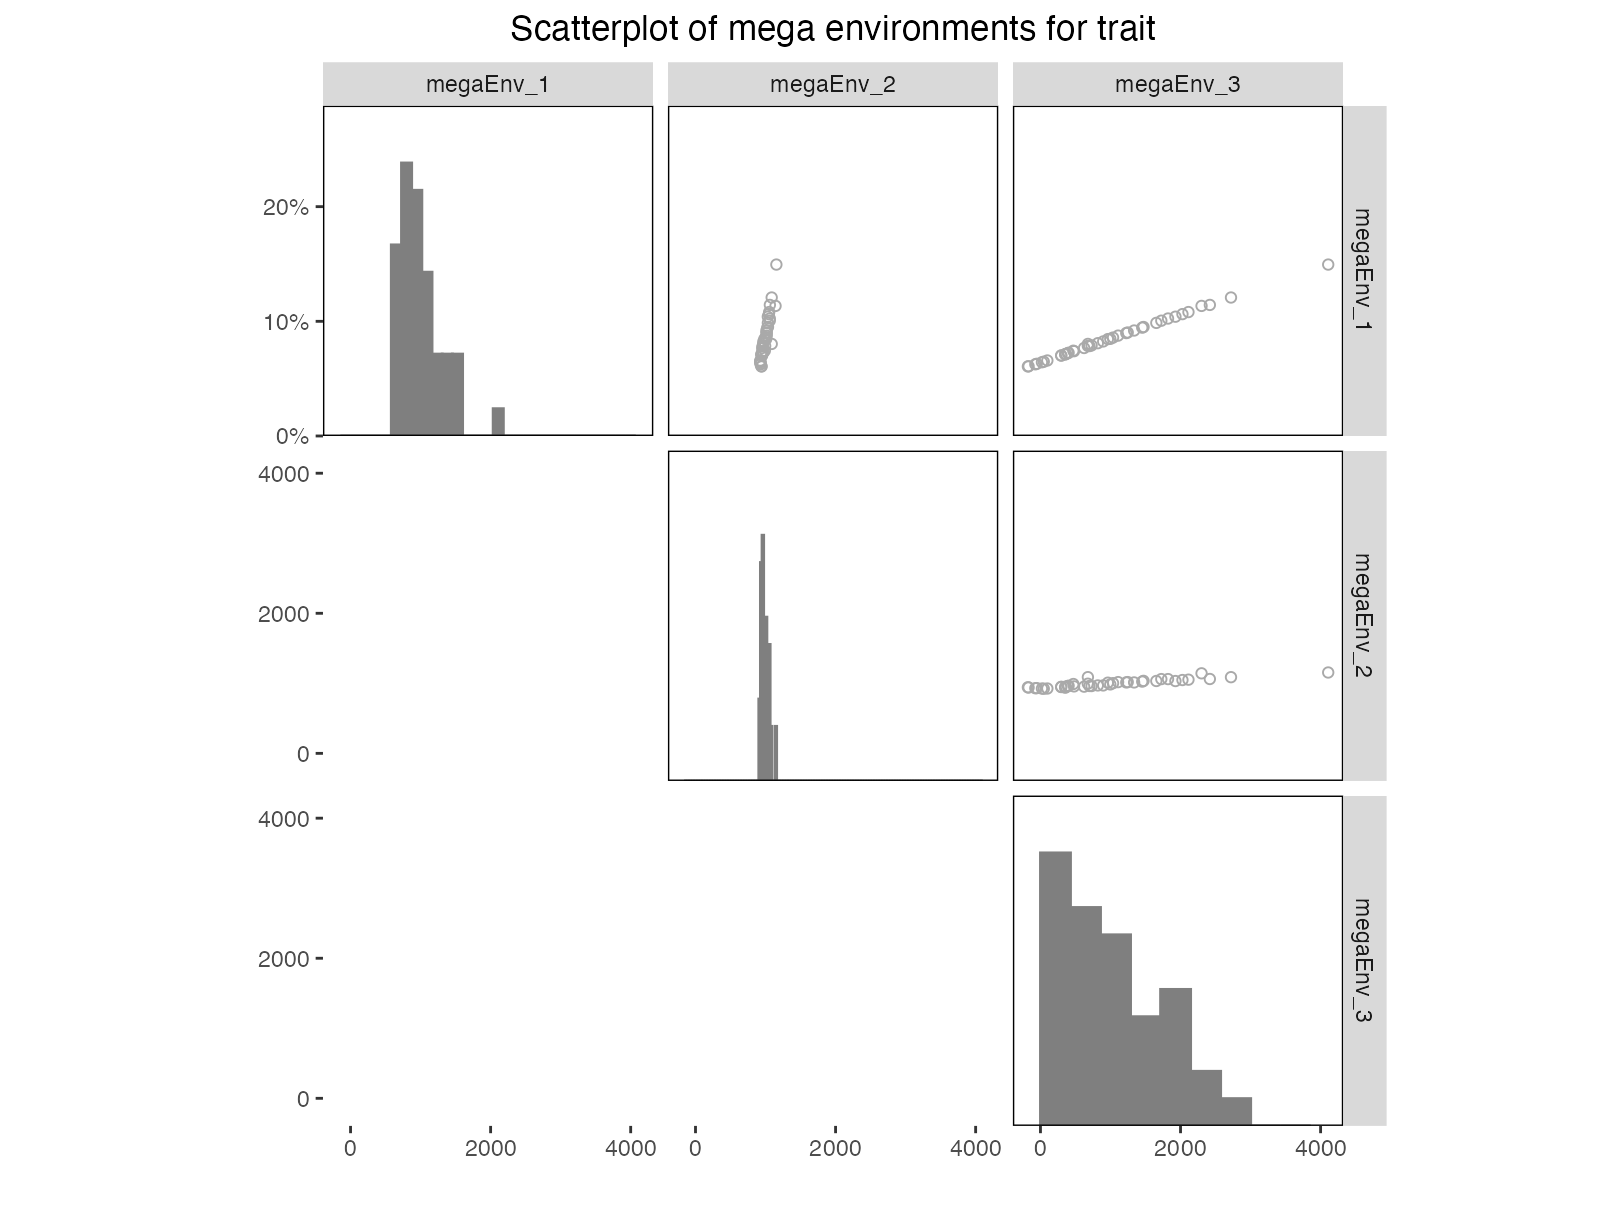

In [406]:
mega$plot_mega()

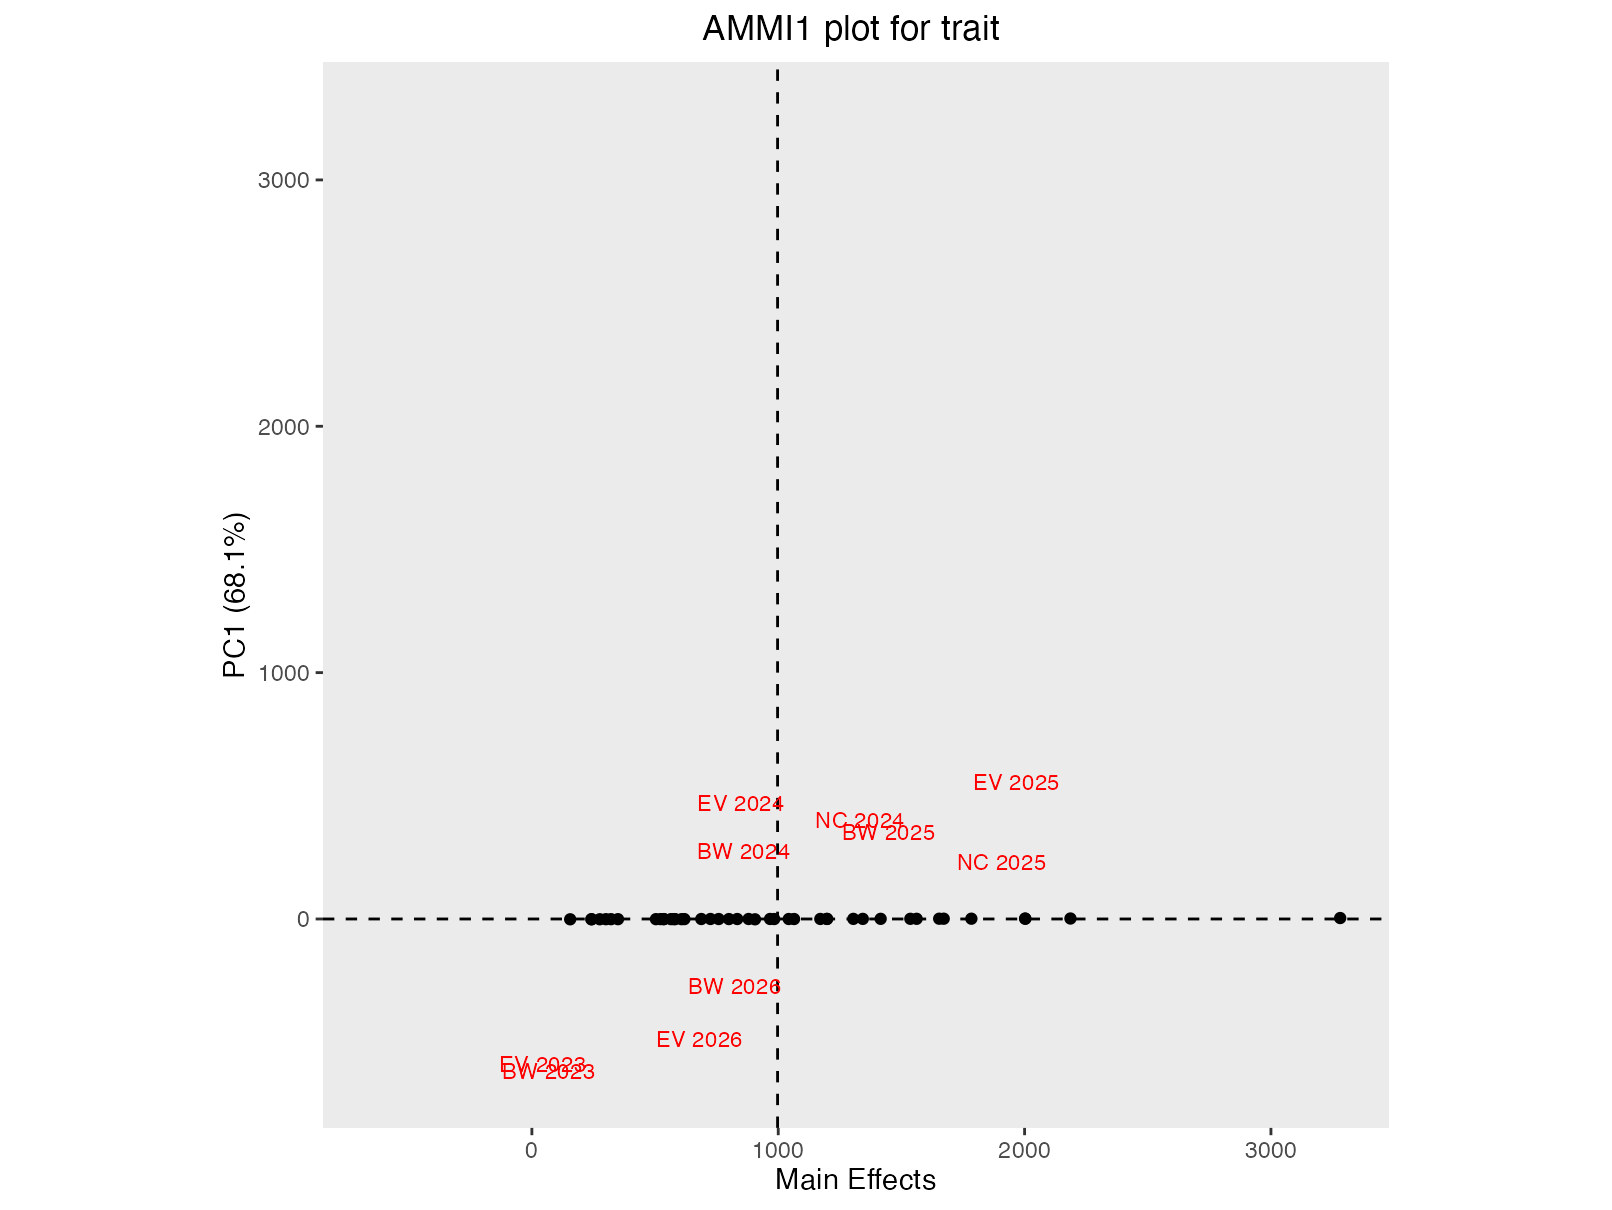

In [51]:
ammi$plot_ammi1()

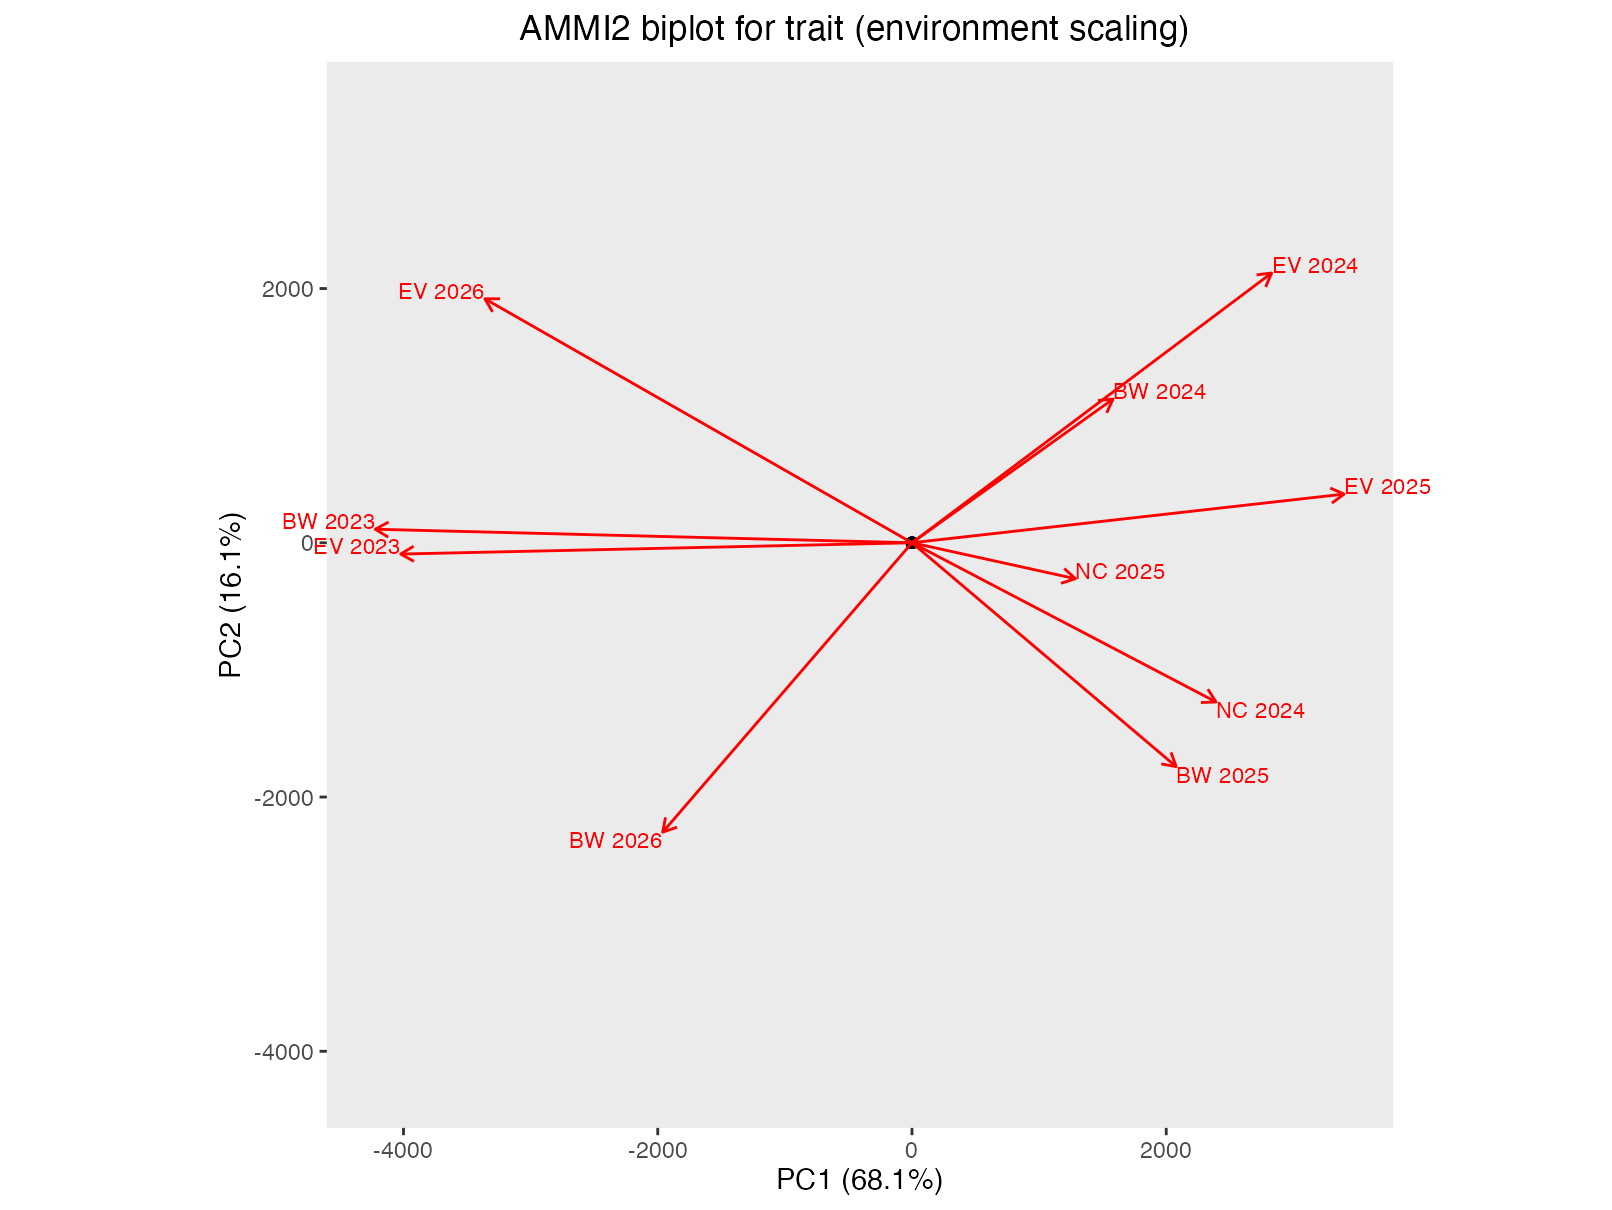

In [52]:
ammi$plot_ammi2()

In [54]:
gge  <- run_gge(td)

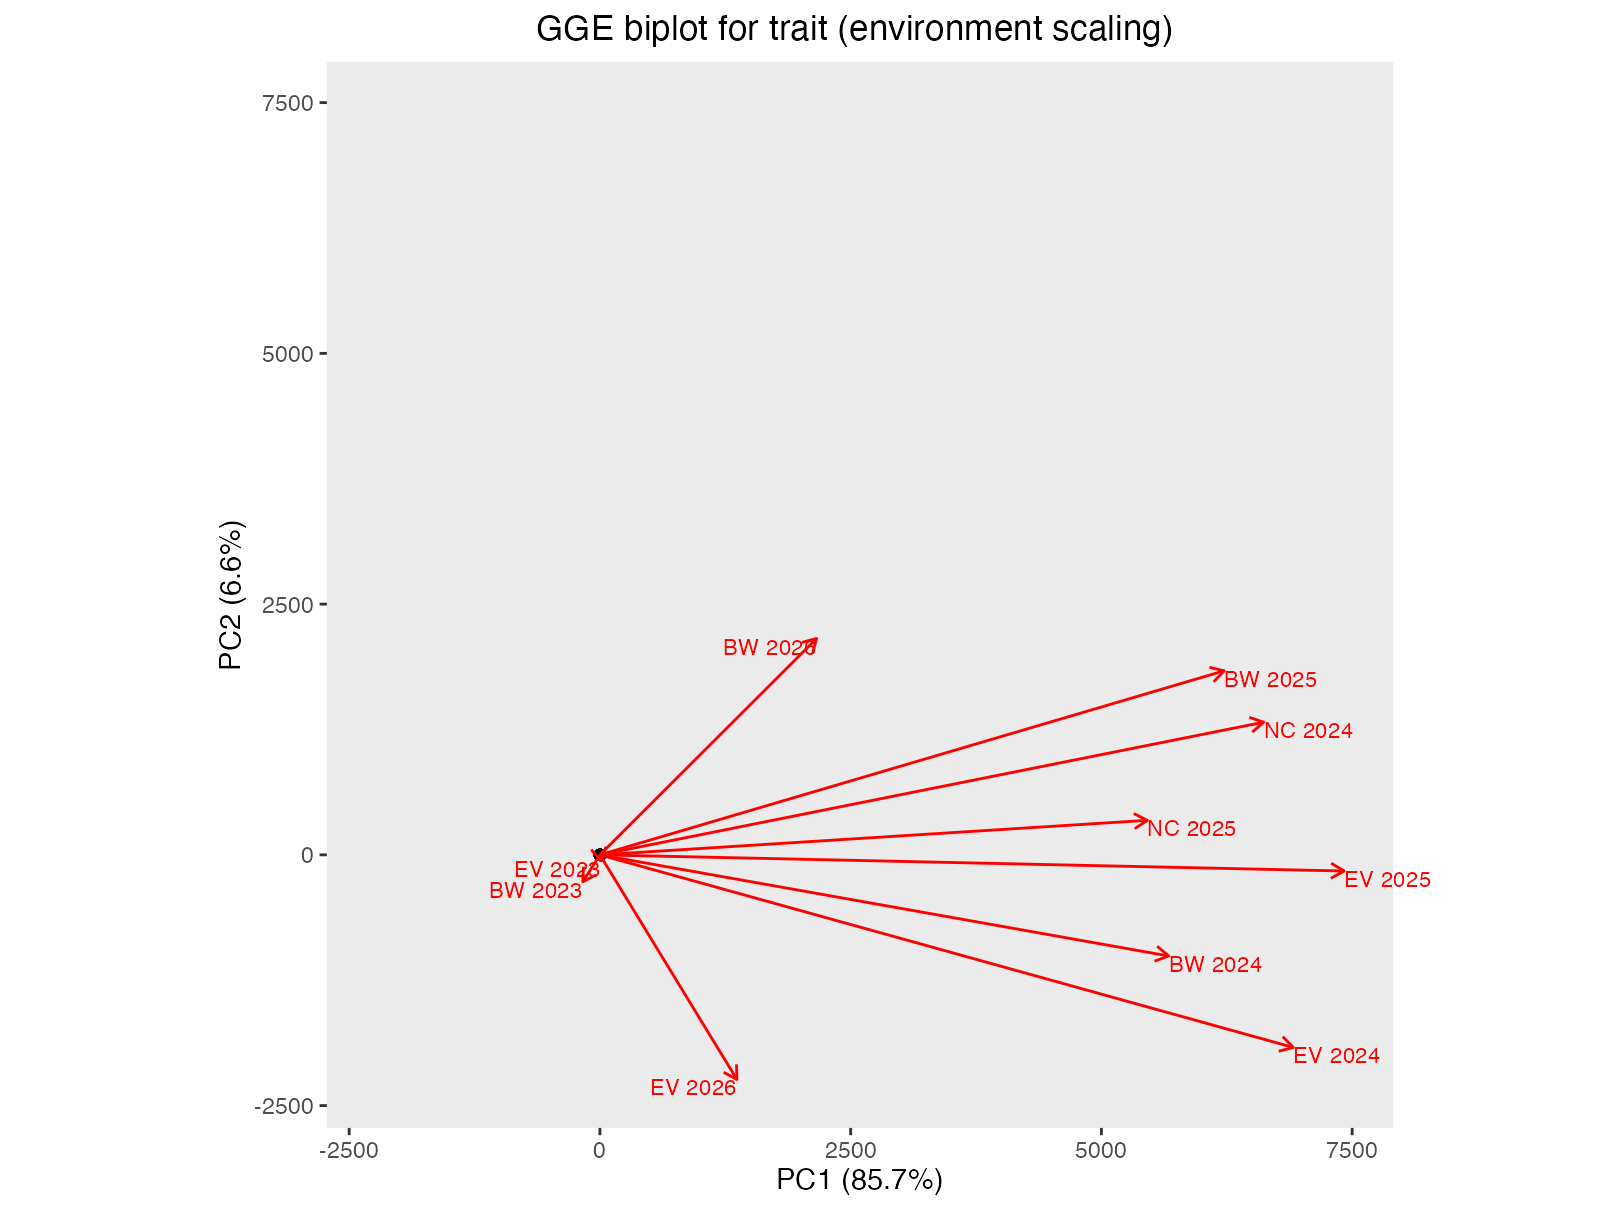

In [55]:
gge$plot_which_won()

In [410]:
tar_load(stab_fa3_asr)

In [411]:
check <- cross_check_vs_fa(ammi, stab_fa3_asr$table)

In [412]:
check$cor_f1_pc1

[1] 0.8923912

In [413]:
check$cor_rmsd_pc2

[1] 0.4998785

In [ ]:
#          # from your LOEO/baseline FA fit
# tested    <- prep_y %>% distinct(Genotype, Env)
#
# 
# fw   <- run_fw(td)
# ammi <- run_ammi(td)
# gge  <- run_gge(td)
#
# fw$plot_line()
# ammi$plot_ammi2()
# gge$plot_which_won()
#
# check <- cross_check_vs_fa(ammi, stab$table)   # stab from fa_stability()
# check$cor_f1_pc1; check$cor_rmsd_pc2

In [59]:
blup_sm3

# A tibble: 336 × 4
   Env     Genotype     blup    se
   <chr>   <chr>       <dbl> <dbl>
 1 BW 2023 Arcadia  -0.00809 0.114
 2 BW 2024 Arcadia  -0.362   0.177
 3 BW 2025 Arcadia  -0.370   0.275
 4 BW 2026 Arcadia  -0.133   0.317
 5 EV 2023 Arcadia  -0.00809 0.114
 6 EV 2024 Arcadia  -0.403   0.210
 7 EV 2025 Arcadia  -0.0943  0.260
 8 EV 2026 Arcadia  -0.364   0.311
 9 BW 2023 Colossus -0.00809 0.114
10 BW 2024 Colossus -0.908   0.179
# ℹ 326 more rows
# ℹ Use `print(n = ...)` to see more rows

In [1]:
# 10/09, extended 10/10 to also cover stage07c's AUC pipeline
#
# Review script for stage07b_fa_bloom_model.R's (bloom5/50/100/duration)
# AND stage07c_fa_auc_model.R's (auc_corrected_percent, AL-only) outputs --
# NOT a pipeline stage. It never fits anything itself; it only reads
# targets that `targets::tar_make()` has already built (hence "tar load
# the outputs"). Deliberately kept out of R/pipeline/ so _targets.R's
# `list.files('R/pipeline', pattern = 'stage.*\\.R$')` sourcing loop never
# picks it up and it is never treated as a stage that contributes targets.
#
# Run it from the repo root, AFTER `targets::tar_make()` has built (or
# re-built) stage07b/stage07c's targets -- e.g.:
#   source("R/reports/bloom_diagnostics_report.R")
# It assumes the working directory is the repo root, matching
# _targets.yaml (`store: _targets`, relative to cwd); tar_read_raw() below
# relies on that default and is never pointed at a different store.
#
# Both pipelines share the same target-name vocabulary (mods_comp_sm,
# pred_ability_asr, hc_fa2_sm, uniplot_fa3_asr, ...) -- stage07b suffixes
# every one with "_bloom_<trait>" via tar_map(), stage07c suffixes every
# one with a plain "_auc" (no tar_map, since AUC is a single trait, not
# four). export_fa_diagnostics() below is the shared worker: given a
# function that builds the right target name for a base name, it pulls
# the model-comparison (+ LRT) and predictive-ability LOEO tables for
# both engines, prints a heuristic "which k" line per engine, and saves
# every diagnostic plot already built as a target (hc dendrogram, numeric
# correlation matrix, OP-vs-RMSD, BLUP heatmap, reaction norms, biplot,
# uniplot, predictive-ability bars). Nothing here recomputes a model fit
# or a plot -- every object pulled is exactly what the pipeline already
# produced; this just collects and exports it so it doesn't have to be
# fished out of the targets store by hand one tar_read() at a time.
#
# group_envs-restricted predictive ability / plot_group_means() are not
# pulled for either pipeline because neither stage builds them (bloom: no
# established environment cluster per trait; AUC: open question, see
# stage07c_fa_auc_model.R's header -- hc_fa*_auc/corr_fa*_auc are exactly
# the diagnostic to check that with). If either stage adds those targets
# later, add them here too; this script only reports what exists.

library(targets)
library(dplyr)
library(ggplot2)

BLOOM_TRAITS <- c("bloom5", "bloom50", "bloom100", "bloom_duration")

BLOOM_TABLE_DIR <- "outputs/tables/bloom"
BLOOM_PLOT_DIR  <- "outputs/plots/bloom"
AUC_TABLE_DIR   <- "outputs/tables/auc"
AUC_PLOT_DIR    <- "outputs/plots/auc"

# Every plot target built by both stage07b and stage07c, sans suffix.
FA_PLOT_TARGETS <- c(
  "hc_fa2_sm", "hc_fa3_sm", "hc_fa2_asr", "hc_fa3_asr",
  "corr_fa2_sm", "corr_fa3_sm", "corr_fa2_asr", "corr_fa3_asr",
  "op_rmsd_fa2_sm", "op_rmsd_fa3_sm", "op_rmsd_fa2_asr", "op_rmsd_fa3_asr",
  "blup_heatmap_fa2_sm", "blup_heatmap_fa3_sm", "blup_heatmap_fa2_asr", "blup_heatmap_fa3_asr",
  "rxn_norm_fa2_sm", "rxn_norm_fa3_sm", "rxn_norm_fa2_asr", "rxn_norm_fa3_asr",
  "biplot_fa2_sm", "biplot_fa3_sm", "biplot_fa2_asr", "biplot_fa3_asr",
  "uniplot_fa2_sm", "uniplot_fa3_sm", "uniplot_fa2_asr", "uniplot_fa3_asr",
  "pred_ability_plot_sm", "pred_ability_plot_asr"
)

# Read one target by name, warning (not erroring) if the pipeline hasn't
# built it yet -- e.g. an engine failed to converge, or tar_make() was
# only run partially.
.safe_read <- function(name) {
  tryCatch(
    targets::tar_read_raw(name),
    error = function(e) {
      message("  [skipped] ", name, " -- ", conditionMessage(e))
      NULL
    }
  )
}

.safe_ggsave <- function(obj, path, width = 7, height = 5) {
  if (is.null(obj)) return(invisible(FALSE))
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  tryCatch({
    ggsave(path, plot = obj, width = width, height = height, dpi = 150)
    TRUE
  }, error = function(e) {
    message("  [plot save failed] ", path, " -- ", conditionMessage(e))
    FALSE
  })
}

.safe_write_csv <- function(tab, path) {
  if (is.null(tab)) return(invisible(FALSE))
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  readr::write_csv(as.data.frame(tab), path)
  TRUE
}

# Heuristic "which k" read for one label/engine: BIC preference (lower
# wins, treated as a tie within 2 points -- same rough threshold used by
# hand for yield's asreml BIC split) plus mean out-of-sample r_p for FA2
# vs FA3. Prints a verdict line; does not choose for the user when the
# two kinds of evidence disagree. Works whether mods_comp has 2 rows
# (bloom: FA2/FA3 only) or 3 (AUC: FA1/FA2/FA3) -- it only ever looks at
# the FA2/FA3 rows.
.which_k_verdict <- function(mods_comp, pred_ability, engine_label, label) {
  if (is.null(mods_comp) || is.null(pred_ability)) {
    cat(sprintf("  [%s] insufficient output to compare FA2 vs FA3\n", engine_label))
    return(invisible(NULL))
  }
  bic_fa2 <- mods_comp$BIC[mods_comp$Model == "FA2"]
  bic_fa3 <- mods_comp$BIC[mods_comp$Model == "FA3"]
  bic_pref <- if (length(bic_fa2) && length(bic_fa3)) {
    d <- bic_fa2 - bic_fa3
    if (abs(d) < 2) "BIC ~tied" else if (d > 0) "BIC favors FA3" else "BIC favors FA2"
  } else "BIC n/a"

  rp <- pred_ability %>%
    dplyr::filter(!is.na(r_p)) %>%
    dplyr::group_by(order) %>%
    dplyr::summarise(mean_r_p = mean(r_p), .groups = "drop")
  rp_fa2 <- rp$mean_r_p[rp$order == "FA2"]
  rp_fa3 <- rp$mean_r_p[rp$order == "FA3"]
  rp_txt <- if (length(rp_fa2) && length(rp_fa3)) {
    sprintf("mean r_p FA2=%.2f vs FA3=%.2f", rp_fa2, rp_fa3)
  } else "r_p n/a"

  cat(sprintf("  [%s | %s] %s; %s\n", engine_label, label, bic_pref, rp_txt))
}

# Shared worker for one pipeline's output (one bloom trait, or AUC).
#   nm        function(base_name) -> full target name, e.g.
#             function(b) paste0(b, "_bloom_bloom5") or function(b) paste0(b, "_auc")
#   table_dir, plot_dir   where this label's CSVs/PNGs land
#   label     used only in console messages (trait name, or "auc")
export_fa_diagnostics <- function(nm, table_dir, plot_dir, label) {
  mods_comp_sm      <- .safe_read(nm("mods_comp_sm"))
  mods_comp_asr     <- .safe_read(nm("mods_comp_asr"))
  mods_comp_sm_lrt  <- .safe_read(nm("mods_comp_sm_lrt"))
  mods_comp_asr_lrt <- .safe_read(nm("mods_comp_asr_lrt"))
  pred_ability_sm   <- .safe_read(nm("pred_ability_sm"))
  pred_ability_asr  <- .safe_read(nm("pred_ability_asr"))
  geno_shift_sm     <- .safe_read(nm("geno_shift_sm"))
  geno_shift_asr    <- .safe_read(nm("geno_shift_asr"))

  .safe_write_csv(mods_comp_sm,      file.path(table_dir, "mods_comp_sm.csv"))
  .safe_write_csv(mods_comp_asr,     file.path(table_dir, "mods_comp_asr.csv"))
  .safe_write_csv(mods_comp_sm_lrt,  file.path(table_dir, "mods_comp_sm_lrt.csv"))
  .safe_write_csv(mods_comp_asr_lrt, file.path(table_dir, "mods_comp_asr_lrt.csv"))
  .safe_write_csv(pred_ability_sm,   file.path(table_dir, "pred_ability_sm.csv"))
  .safe_write_csv(pred_ability_asr,  file.path(table_dir, "pred_ability_asr.csv"))
  .safe_write_csv(geno_shift_sm,     file.path(table_dir, "geno_shift_sm.csv"))
  .safe_write_csv(geno_shift_asr,    file.path(table_dir, "geno_shift_asr.csv"))

  # LRT significance is written to CSV above for the full picture but
  # kept out of this one-line verdict -- see this session's yield
  # FA2-vs-FA3 discussion for why AIC/LRT alone were treated with caution
  # relative to out-of-sample r_p.
  .which_k_verdict(mods_comp_sm,  pred_ability_sm,  "sommer", label)
  .which_k_verdict(mods_comp_asr, pred_ability_asr, "asreml", label)

  for (base in FA_PLOT_TARGETS) {
    obj <- .safe_read(nm(base))
    .safe_ggsave(obj, file.path(plot_dir, paste0(base, ".png")))
  }

  cat("  tables  ->", table_dir, "\n")
  cat("  plots   ->", plot_dir, "\n")
}

for (trait in BLOOM_TRAITS) {
  cat("\n==== bloom trait:", trait, "====\n")
  export_fa_diagnostics(
    nm = function(base) paste0(base, "_bloom_", trait),
    table_dir = file.path(BLOOM_TABLE_DIR, trait),
    plot_dir  = file.path(BLOOM_PLOT_DIR, trait),
    label = trait
  )
}

cat("\n==== AUC (auc_corrected_percent, AL only) ====\n")
export_fa_diagnostics(
  nm = function(base) paste0(base, "_auc"),
  table_dir = AUC_TABLE_DIR,
  plot_dir  = AUC_PLOT_DIR,
  label = "auc"
)

cat("\nDone. See outputs/tables/{bloom/<trait>,auc}/ and outputs/plots/{bloom/<trait>,auc}/.\n")


Attaching package: ‘dplyr’

The following objects are masked from ‘package:stats’:

    filter, lag

The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union

Want to understand how all the pieces fit together? Read R for Data Science: https://r4ds.hadley.nz/

==== bloom trait: bloom5 ====
  [sommer | bloom5] BIC favors FA3; mean r_p FA2=0.79 vs FA3=0.80
  [asreml | bloom5] BIC favors FA2; mean r_p FA2=0.80 vs FA3=0.80
  tables  -> outputs/tables/bloom/bloom5 
  plots   -> outputs/plots/bloom/bloom5 

==== bloom trait: bloom50 ====
  [sommer | bloom50] BIC favors FA3; mean r_p FA2=0.79 vs FA3=0.80
  [asreml | bloom50] BIC favors FA2; mean r_p FA2=0.79 vs FA3=0.79
  tables  -> outputs/tables/bloom/bloom50 
  plots   -> outputs/plots/bloom/bloom50 

==== bloom trait: bloom100 ====
  [sommer | bloom100] BIC favors FA3; mean r_p FA2=0.71 vs FA3=0.71
  [asreml | bloom100] BIC favors FA2; mean r_p FA2=0.71 vs FA3=0.71
  tables  -> outputs/tables/bloom/b

In [80]:
tar_load(blup_fa3_asr)
tar_load(stab_fa3_asr)

In [82]:
mb = blup_fa3_asr %>% group_by(Genotype) %>%
  summarize(mean_blup = mean(blup))

In [83]:
mb = mb %>% inner_join(stab_fa3_asr$table, by = 'Genotype')

In [84]:
mb = mb %>% mutate(OP_rank = rank(-OP, ties.method = 'average'),
MeanBlups_rank = rank(-mean_blup, ties.method = 'average'))

In [85]:
cor.test(mb$OP_rank, mb$MeanBlups_rank, method = 'spearman')


	Spearman's rank correlation rho

data:  mb$OP_rank and mb$MeanBlups_rank
S = 476, p-value < 2.2e-16
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
0.9614294 


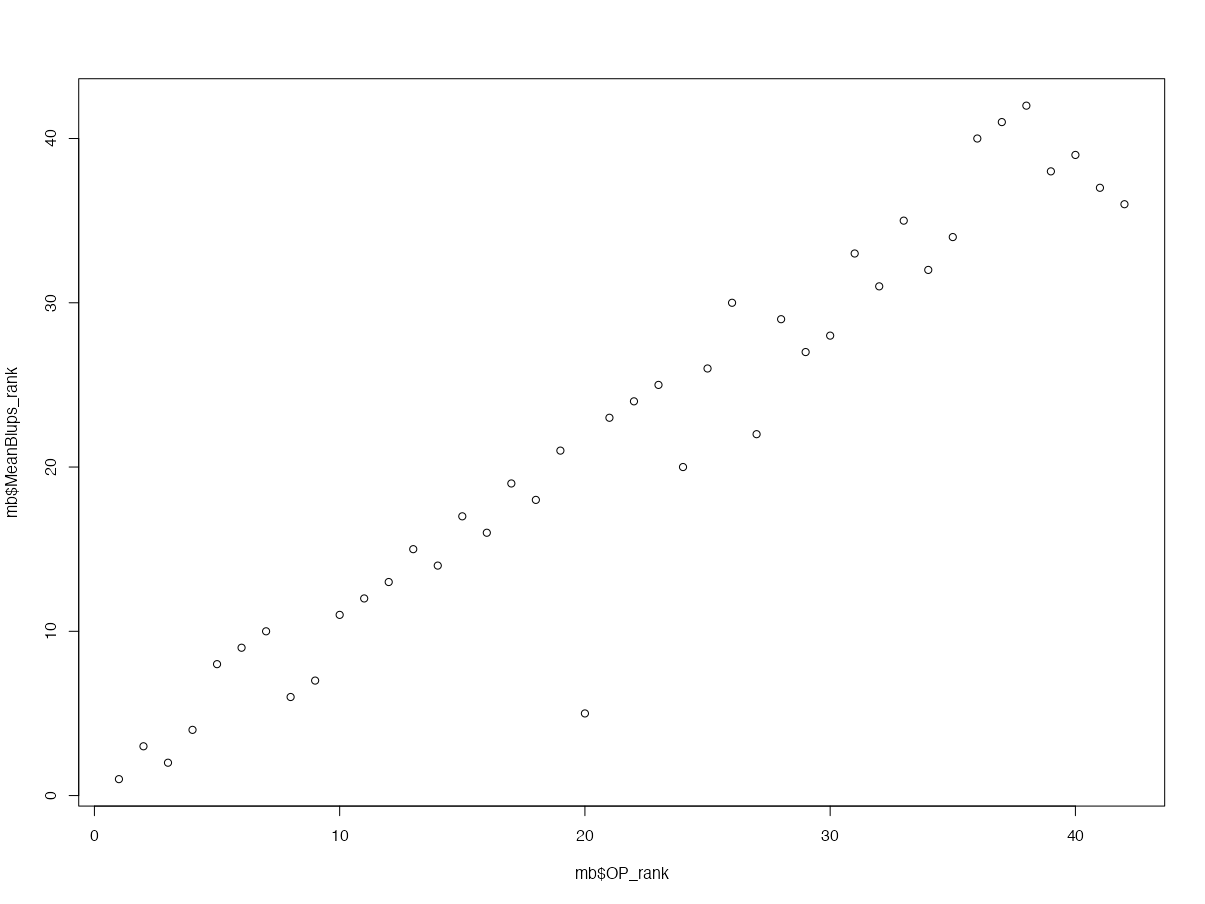

In [86]:
plot(mb$OP_rank, mb$MeanBlups_rank)

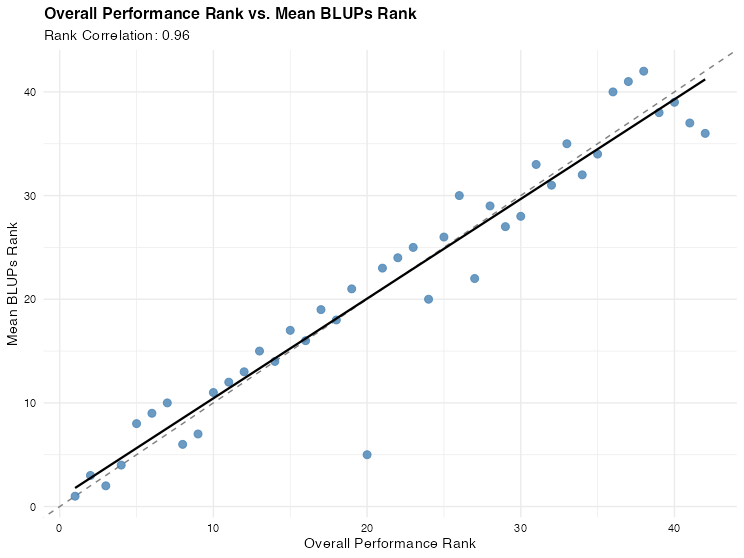

`geom_smooth()` using formula = 'y ~ x'

In [89]:
library(ggplot2)

ggplot(mb, aes(x = OP_rank, y = MeanBlups_rank)) +
  # 1:1 line representing perfect rank consistency
  geom_abline(intercept = 0, slope = 1, linetype = "dashed", color = "gray50") +
  # Scatter points
  geom_point(size = 2.5, alpha = 0.8, color = "steelblue") +
  # Optional: Linear trend line
  geom_smooth(method = "lm", se = FALSE, color = "black", linewidth = 0.8) +
  labs(
    title = "Overall Performance Rank vs. Mean BLUPs Rank",
    subtitle = 'Rank Correlation: 0.96',
    x = "Overall Performance Rank",
    y = "Mean BLUPs Rank"
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(face = "bold", size = 12),
    axis.title = element_text(size = 11, color = "black"),
    axis.text  = element_text(color = "black")
  )

In [1]:
names_path = 'data/raw/markers/SampleNames.csv'
marker_path = 'data/raw/markers/genomat.csv'

In [ ]:
library(dplyr)
library(readr)

names_path = 'data/raw/markers/SampleNames.csv'
marker_path = 'data/raw/markers/genomat.csv'


marker_raw <- read_csv(marker_path, show_col_types = FALSE)
code_map   <- read_csv(names_path, show_col_types = FALSE)

marker_id_col <- names(marker_raw)[1]      # adjust if your marker-ID column isn't first
sample_cols   <- names(marker_raw)[-1]

# flag mismatches explicitly rather than silently dropping/NA-ing anything
unmatched_in_marker <- setdiff(sample_cols, code_map$`Sample Code`)
unmatched_in_map    <- setdiff(code_map$`Sample Code`, sample_cols)
if (length(unmatched_in_marker) > 0) {
  message(length(unmatched_in_marker), " marker column(s) have no match in the code map:")
  print(unmatched_in_marker)
}
if (length(unmatched_in_map) > 0) {
  message(length(unmatched_in_map), " sample code(s) in the map have no marker column:")
  print(unmatched_in_map)
}

name_lookup <- setNames(code_map$`Genotype Name`, code_map$`Sample Code`)
new_names <- ifelse(sample_cols %in% names(name_lookup),
                     name_lookup[sample_cols],
                     sample_cols)   # left unmatched as-is -- don't want a silent NA column name

if (anyDuplicated(new_names)) {
  dup <- new_names[duplicated(new_names) | duplicated(new_names, fromLast = TRUE)]
  stop("Duplicate genotype names after renaming -- check the code map: ",
       paste(unique(dup), collapse = ", "))
}

names(marker_raw) <- c(marker_id_col, new_names)



Attaching package: ‘dplyr’

The following objects are masked from ‘package:stats’:

    filter, lag

The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union

New names:
• `` -> `...1`


In [35]:
names(marker_raw)

 [1] "...1"                                                                 
 [2] "HC_RAPiD-Genomics_F437_NCS_194502_P003_WD05_i5-287_i7-233_S11609_L002"
 [3] "HC_RAPiD-Genomics_F437_NCS_194502_P003_WE10_i5-287_i7-250_S11626_L002"
 [4] "HC_RAPiD-Genomics_F438_NCS_194503_P001_WF09_i5-141_i7-261_S11396_L005"
 [5] "HC_RAPiD-Genomics_F438_NCS_194503_P001_WG01_i5-141_i7-265_S11400_L005"
 [6] "HC_RAPiD-Genomics_F438_NCS_194503_P001_WG04_i5-141_i7-268_S11403_L005"
 [7] "HC_RAPiD-Genomics_F438_NCS_194503_P001_WG12_i5-141_i7-276_S11411_L005"
 [8] "HC_RAPiD-Genomics_F438_NCS_194503_P001_WH01_i5-141_i7-277_S11412_L005"
 [9] "HC_RAPiD-Genomics_F438_NCS_194503_P001_WH02_i5-141_i7-278_S11413_L005"
[10] "HC_RAPiD-Genomics_F438_NCS_194503_P001_WH03_i5-141_i7-279_S11414_L005"
[11] "HC_RAPiD-Genomics_F438_NCS_194503_P001_WH07_i5-141_i7-283_S11418_L005"
[12] "HC_RAPiD-Genomics_F438_NCS_194503_P001_WH09_i5-141_i7-285_S11420_L005"
[13] "HC_RAPiD-Genomics_F438_NCS_194503_P001_WH11_i5-141_i7-287_S11422_L005"

In [ ]:
write_csv(marker_raw, "marker_data_renamed.csv")

In [ ]:
markers = readr::read_csv(marker_path)
sample_names = readr::read_csv(names_path)

New names:
• `` -> `...1`
Rows: 51704 Columns: 42
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (1): ...1
dbl (41): HC_RAPiD-Genomics_F437_NCS_194502_P003_WD05_i5-287_i7-233_S11609_L...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 41 Columns: 2
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): Sample Code, Genotype Name

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [4]:
targets::tar_load(pc_scores_fa2_asr)

In [8]:
setdiff(pc_scores_fa2_asr$scores$Genotype, sample_names$`Genotype Name`)

[1] "TH-2937"

In [6]:
build_genomic_g_matrix = function(snp_matrix, ploidy = 4, method = 'VanRaden', missing_value = NA, maf = 0.05) {
  Gmatrix(SNPmatrix = snp_matrix, method = method, ploidy = ploidy, missingValue = missing_value, maf = maf)
}


In [3]:
marker_id_col <- names(marker_raw)[1]

marker_mat <- marker_raw %>%
  tibble::column_to_rownames(marker_id_col) %>%
  as.matrix()
geno_mat <- t(marker_mat) 

na_frac <- mean(is.na(geno_mat))
message(sprintf("Missing genotype calls: %.2f%% of cells", na_frac * 100))


Missing genotype calls: 3.49% of cells


In [8]:
library(AGHmatrix)

In [9]:
Gmat = build_genomic_g_matrix(geno_mat)


Missing data check: 
	Total SNPs: 51704 
	 0 SNPs dropped due to missing data threshold of 0.5 
	Total of: 51704  SNPs 

MAF check: 
	 30320 SNPs dropped with MAF below 0.05 
	Total: 21384  SNPs 

Heterozigosity data check: 
	No SNPs with heterozygosity, missing threshold of = 0 

Summary check: 
	Initial:  51704 SNPs 
	Final:  21384  SNPs ( 30320  SNPs removed) 

Completed! Time = 0.07  seconds 


In [10]:
# standard diagonal bending/ridge -- removes just the one structural
# null direction without disturbing the other (healthy) eigenvalues
bend_G <- function(G, w = 1e-3) {
  (1 - w) * G + w * diag(diag(G))
}

Gmat_b <- bend_G(Gmat, w = 1e-3)
kappa(Gmat_b)          # should now be small, e.g. low hundreds/thousands

[1] 29874.64

In [7]:
tar_load(prep_yield)

In [8]:
prep_yield = prep_yield %>% filter(Genotype != 'TH-2937')

In [89]:
# standard diagonal bending/ridge -- removes just the one structural
# null direction without disturbing the other (healthy) eigenvalues
bend_G <- function(G, w = 1e-3) {
  (1 - w) * G + w * diag(diag(G))
}

Gmat_b <- bend_G(Gmat, w = 1e-3)
kappa(Gmat_b)          # should now be small, e.g. low hundreds/thousands


[1] 29874.64

In [93]:
# Ginverse(Gmat_b) %*% Gmat_b should be ~ identity
I_check <- gin %*% Gmat_b
max(abs(I_check - diag(nrow(I_check))))   # should be small, e.g. < 1e-6 to 1e-3



[1] 3.699105e-14

In [92]:
# and confirm symmetry survived (ASReml/sommer expect a symmetric Ginverse)
max(abs(gin - t(gin)))

[1] 3.552714e-14

In [90]:
gin=solve(Gmat_b)          # sanity check -- no more blow-up

In [88]:
G_inv = solve(Gmat)

In [79]:
G_inv = build_A_inverse(Gmat, unique(prep_yield$Genotype))

In [81]:
# how many markers actually exist, and how many are even possible to use?
print(dim(geno_mat)   )   # genotype x marker -- how many columns (markers) do you actually have?

# how many markers are polymorphic in THIS 41-individual panel specifically?
# a marker fixed (no variation) across all 41 genotypes contributes zero
# information to G, no matter how it looked in a larger reference population
marker_var <- apply(geno_mat, 2, var, na.rm = TRUE)
print(sum(marker_var == 0, na.rm = TRUE)  )    # count of monomorphic markers in this panel
print(sum(marker_var > 0, na.rm = TRUE)  )     # count of actually informative markers

# how much missingness per marker, and per individual?
print(colMeans(is.na(geno_mat)) |> summary())
print(rowMeans(is.na(geno_mat)) |> summary())

[1]    41 51704
[1] 504
[1] 51200
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
0.00000 0.00000 0.02439 0.03486 0.04878 0.09756 
    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
0.002069 0.003191 0.004816 0.034858 0.036477 0.231491 


In [86]:
off_diag_G <- Gmat
diag(off_diag_G) <- NA

# relative to mean diagonal, since G's scale depends on allele freq coding
mean_diag <- mean(diag(Gmat), na.rm = TRUE)
high_pairs_G <- which(off_diag_G > 0.3 * mean_diag, arr.ind = TRUE)
high_pairs_G <- high_pairs_G[high_pairs_G[,1] < high_pairs_G[,2], , drop = FALSE]  # dedupe symmetric pairs

data.frame(
  geno1 = rownames(Gmat)[high_pairs_G[,1]],
  geno2 = colnames(Gmat)[high_pairs_G[,2]],
  rel   = Gmat[high_pairs_G]
)

     geno1    geno2       rel
1 FL17-141 FL17-142 0.3130727
2   NC5287   NC5298 0.3065719
3 FL14-288 Farthing 0.3647288

In [87]:
eigen(Gmat, symmetric = TRUE, only.values = TRUE)$values |> sort() |> head(10)

 [1] 3.131185e-14 4.253205e-01 4.926297e-01 5.030920e-01 5.304100e-01
 [6] 5.398110e-01 5.579205e-01 5.748793e-01 6.008093e-01 6.283629e-01

In [56]:
dim(Gmat)

[1] 41 41

In [57]:
a_mat42 = a_mat[unique(prep_y$Genotype), unique(prep_y$Genotype)]
a_mat41 = a_mat[rownames(Gmat), rownames(Gmat)]

In [94]:
build_h_matrix = function(a_mat, g_mat, markers = SNPmatrix,
   method = 'Munoz', ploidy = 4, missing_value = NA, maf = 0.05){
  Hmatrix(A = a_mat, G = g_mat, method = method, ploidy = ploidy, 
    markers = markers, missingValue = missing_value, maf = maf)
}
h_mat41 = build_h_matrix(a_mat41, Gmat_b, markers = geno_mat)

Comparing the matrices... 
Completed! Time = 0 minutes
Computing the H matrix... 

 Completed! Time = 4e-04  minutes 

 Returning H = A matrix corrected by G... 


In [ ]:
A42_inv <- solve(a_mat42)
A41_inv    <- solve(a_mat41)
H41_inv    <- solve(h_mat41)

H_inv_full <- A42_inv
correction <- H41_inv - A41_inv

In [62]:
Amat = a_mat42

In [68]:
round(diag(Hmat22)[1:5], 3)

NC5313 NC5314 NC5271  ONeal NC5286 
 1.038  1.039  0.991  0.882  1.000 

In [69]:
message("kappa(H_inv_full) = ", kappa(H_inv_full))

: [1m[33mError[39m:[22m
[33m![39m object 'H_inv_full' not found

In [67]:
a = solve(h_mat41)

: [1m[33mError[39m in `solve.default()`:[22m
[33m![39m system is computationally singular: reciprocal condition number = 1.71445e-17

In [ ]:
library(AGHmatrix)
library(dplyr)

# -- pedigree-based A matrix --
# Hmatrix() needs A itself, not A-inverse. If your existing build_A_inverse()
# already used AGHmatrix::Amatrix() internally, rebuild A the same way here
# (same ploidy, same w/double-reduction rate) so this A matches exactly what
# the rest of the pipeline has been using -- confirm the w value used
# originally before trusting this.
pedigree <- read.csv("path/to/pedigree.csv")   # whatever format build_A_inverse() expects
Amat <- Amatrix(pedigree, ploidy = 4, w = 0.1)  # w = double-reduction rate -- match project's existing value

# -- genomic G matrix (from the earlier script) --
Gmat <- Gmatrix(
  SNPmatrix    = geno_mat,     # genotype x marker, from before
  method       = "VanRaden",
  ploidy       = 4,
  missingValue = NA,
  maf          = 0.01
)
Gmat <- round(Gmat, 3)   # AGHmatrix's own example rounds G before Hmatrix() -- avoids
                          # floating-point near-singularity issues in the combination step

# -- H matrix, Munoz method (primary) --
Hmat_Munoz <- Hmatrix(
  A            = Amat,
  G            = Gmat,
  markers      = geno_mat,     # raw dosage matrix -- needed for relationship-class shrinkage
  ploidy       = 4,
  method       = "Munoz",
  missingValue = NA,
  maf          = 0.01
)

# -- H matrix, Martini method (sensitivity check) --
Hmat_Martini <- Hmatrix(
  A            = Amat,
  G            = Gmat,
  ploidy       = 4,
  method       = "Martini",
  missingValue = NA,
  maf          = 0.01
)

# sanity check: how much do the two methods disagree?
diff_summary <- summary(as.vector(Hmat_Munoz - Hmat_Martini))
print(diff_summary)

# proceed with Munoz as primary; keep Martini around for the comparison note
saveRDS(Hmat_Munoz, "H_matrix_tetraploid.rds")

H_inv <- solve(Hmat_Munoz)
saveRDS(H_inv, "H_inverse_tetraploid.rds")

In [95]:
saveRDS(gin, "data/processed/markers/G_inverse.rds")

In [96]:
saveRDS(Gmat_b, "data/processed/markers/G_mat.rds")

In [9]:
gin = readRDS("data/processed/markers/G_inverse.rds")

In [11]:

# 10/14 -- additive + non-additive split, per Smith et al 2015 eq 4-9.


fit_fa2_minimal_nonadd <- function(fa_dta, Ainv, maxiter = 300) {
  dta <- prep_and_scale_dta(fa_dta)
  fit <- asreml(
    fixed    = y_scaled ~ Env,
    random   = ~fa(Env, k = 2):vm(Genotype, Ainv) + ide(Genotype) + Env:Block,
    residual = ~dsum(~units | Env),
    data     = dta,
    maxit = 300, ai.loadings = 5, ai.penalty = 15
  )
  fit$call$maxit <- maxiter
  update.asreml(fit)
}



fit_fa3_minimal_nonadd <- function(fa_dta, Ainv, maxiter = 300) {
  dta <- prep_and_scale_dta(fa_dta)
  fit <- asreml(
    fixed    = y_scaled ~ Env,
    random   = ~fa(Env, k = 3):vm(Genotype, Ainv) + ide(Genotype) + Env:Block,
    residual = ~dsum(~units | Env),
    data     = dta,
    maxit = 300, ai.loadings = 5, ai.penalty = 15
  )
  fit$call$maxit <- maxiter
  update.asreml(fit)
}


fit_fa2_add_nonadd_asreml <- function(fa_dta, Ainv, maxiter = 300) {
  dta <- prep_and_scale_dta(fa_dta)

  fit <- asreml(
    fixed    = y_scaled ~ Env,
    random   = ~fa(Env, k = 2):vm(Genotype, Ainv) + fa(Env, k = 1):ide(Genotype) + Env:Block,
    residual = ~dsum(~units | Env),
    data     = dta,
    maxit    = maxiter,
    ai.loadings = 5,
    ai.penalty  = 15
  )
  fit$call$maxit <- maxiter
  update.asreml(fit)
}



fit_fa3_add_nonadd_asreml <- function(fa_dta, Ainv, maxiter = 300) {
  dta <- prep_and_scale_dta(fa_dta)

  fit <- asreml(
    fixed    = y_scaled ~ Env,
    random   = ~fa(Env, k = 3):vm(Genotype, Ainv) + fa(Env, k = 1):ide(Genotype) + Env:Block,
    residual = ~dsum(~units | Env),
    data     = dta,
    maxit    = maxiter,
    ai.loadings = 5,
    ai.penalty  = 15
  )
  fit$call$maxit <- maxiter
  update.asreml(fit)
}


split_varcomp_asreml <- function(varcomp) {
  is_add    <- grepl("vm\\(Genotype", rownames(varcomp))
  is_nonadd <- grepl("ide\\(Genotype", rownames(varcomp))
  stopifnot(any(is_add), any(is_nonadd))
  list(additive = varcomp[is_add, , drop = FALSE],
       nonadditive = varcomp[is_nonadd, , drop = FALSE])
}

extract_rg_matrix_asreml_split <- function(varcomp, env_levels, ka, ke) {
  parts <- split_varcomp_asreml(varcomp)
  list(
    additive    = extract_rg_matrix_asreml(parts$additive, env_levels, ka),
    nonadditive = extract_rg_matrix_asreml(parts$nonadditive, env_levels, ke)
  )
}


extract_blups_asreml_split <- function(fit, dta, ka, ke) {
  pv_a <- predict(fit, classify = "Env:Genotype", data = dta,
                   onlyuse = ~fa(Env, k = ka):vm(Genotype, Ainv))$pvals
  pv_e <- predict(fit, classify = "Env:Genotype", data = dta,
                   onlyuse = ~fa(Env, k = ke):ide(Genotype))$pvals

  tidy <- function(pv) {
    pv %>%
      mutate(Env = as.character(Env), Genotype = as.character(Genotype)) %>%
      transmute(Genotype, Env, blup = predicted.value, se = std.error)
  }
  list(additive = tidy(pv_a), nonadditive = tidy(pv_e))
}


extract_rg_matrix_asreml <- function(varcomp, env_levels, n_factors) {
  var_rows <- varcomp[grep("!var$", rownames(varcomp)), , drop = FALSE]
  if (nrow(var_rows) == 0) {
    stop(
      "extract_rg_matrix_asreml(): no rows matching '!var' "
    )
  }
  R <- var_rows[, 1]

  loadings <- lapply(seq_len(n_factors), function(k) {
    rows <- varcomp[grep(paste0("!fa", k, "$"), rownames(varcomp)), , drop = FALSE]
    if (nrow(rows) == 0) {
      stop(
        "extract_rg_matrix_asreml(): no rows matching '!fa", k, "'",   
      )
    }
    rows[, 1]
  })

  L <- do.call(cbind, loadings)
  # rownames(L) <- env_levels 
  # print('here3')
  cov <- L %*% t(L) + diag(R)
  dimnames(cov) <- list(env_levels, env_levels)

  list(cov = cov, corr = stats::cov2cor(cov), loadings = L)
}


prep_and_scale_dta = function(fa_dta){
  fa_dta = fa_dta %>% mutate(Genotype = factor(Genotype), Env = factor(Env), Block = factor(Block))

  env_stats = fa_dta %>% group_by(Env) %>%
    summarize(mean_env = mean(y, na.rm = TRUE), sd_env = sd(y, na.rm = TRUE))

  fa_dta_scaled = fa_dta %>% left_join(env_stats, by = 'Env') %>%
    mutate(y_scaled = (y - mean_env) / sd_env)
}

In [37]:
fit_fa2_dn_asr = fit_fa2_add_nonadd_asreml(prep_yield, gin)

ASReml Version 4.2 14/10/2026 14:00:24
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -289.0730           1.0    873   14:00:24  (  8 restrained)
  2     -270.2988           1.0    873   14:00:25  (  8 restrained)
  3     -224.7125           1.0    873   14:00:25  ( 12 restrained)
  4     -192.2086           1.0    873   14:00:25  ( 11 restrained)
  5     -178.1935           1.0    873   14:00:25  (  7 restrained)
  6     -175.1881           1.0    873   14:00:25  (  6 restrained)
  7     -173.2743           1.0    873   14:00:25  (  3 restrained)
  8     -171.2175           1.0    873   14:00:25  (  5 restrained)
  9     -170.0125           1.0    873   14:00:25  (  2 restrained)
 10     -168.4369           1.0    873   14:00:25  (  1 restrained)
 11     -167.0173           1.0    873   14:00:25  (  1 restrained)
 12     -165.7057           1.0    873   14:00:25  (  1 restrained)
 13     -164.6382           1.0    873   14:

Warning messages:
1: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 2):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration
2: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 2):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


In [12]:
fit_fa3_asr = fit_fa3_asreml(prep_yield, gin)

ASReml Version 4.2 14/10/2026 12:10:43
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -282.0643           1.0    873   12:10:43
  2     -223.6868           1.0    873   12:10:43  (  2 restrained)
  3     -195.4081           1.0    873   12:10:43  (  4 restrained)
  4     -185.4243           1.0    873   12:10:43  (  4 restrained)
  5     -182.1539           1.0    873   12:10:43  (  4 restrained)
  6     -180.8233           1.0    873   12:10:43  (  1 restrained)
  7     -179.7976           1.0    873   12:10:43
  8     -178.7193           1.0    873   12:10:43  (  1 restrained)
  9     -177.2540           1.0    873   12:10:43  (  1 restrained)
 10     -175.2399           1.0    873   12:10:43  (  1 restrained)
 11     -174.5311           1.0    873   12:10:43  (  1 restrained)
 12     -174.0376           1.0    873   12:10:43  (  1 restrained)
 13     -173.8771           1.0    873   12:10:43
 14     -173.6927           1.

Warning messages:
1: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration
2: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


In [13]:
fit_fa3_dn_asr = fit_fa3_add_nonadd_asreml(prep_yield, gin)

ASReml Version 4.2 14/10/2026 12:11:29
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -282.2011           1.0    873   12:11:29  (  9 restrained)
  2     -260.7935           1.0    873   12:11:29  (  9 restrained)
  3     -214.5836           1.0    873   12:11:29  ( 13 restrained)
  4     -187.3400           1.0    873   12:11:29  ( 12 restrained)
  5     -175.0919           1.0    873   12:11:29  (  7 restrained)
  6     -171.6455           1.0    873   12:11:29  (  5 restrained)
  7     -170.7243           1.0    873   12:11:29  (  6 restrained)
  8     -168.8823           1.0    873   12:11:29  (  4 restrained)
  9     -168.2224           1.0    873   12:11:29  (  2 restrained)
 10     -167.5490           1.0    873   12:11:29  (  2 restrained)
 11     -166.9842           1.0    873   12:11:29  (  2 restrained)
 12     -166.3942           1.0    873   12:11:29
 13     -165.3967           1.0    873   12:11:29  (  1 restra

Warning messages:
1: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration
2: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


In [15]:
fit_fa3_min_asr = fit_fa3_minimal_nonadd(prep_yield, gin)

ASReml Version 4.2 14/10/2026 12:13:46
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -275.5542           1.0    873   12:13:46  (  1 restrained)
  2     -214.7257           1.0    873   12:13:46  (  2 restrained)
  3     -188.5719           1.0    873   12:13:46  (  5 restrained)
  4     -178.5770           1.0    873   12:13:46  (  5 restrained)
  5     -175.9622           1.0    873   12:13:46  (  5 restrained)
  6     -174.3112           1.0    873   12:13:46  (  3 restrained)
  7     -172.2893           1.0    873   12:13:47  (  2 restrained)
  8     -171.1392           1.0    873   12:13:47  (  2 restrained)
  9     -170.1478           1.0    873   12:13:47  (  1 restrained)
 10     -169.3541           1.0    873   12:13:47  (  1 restrained)
 11     -168.7442           1.0    873   12:13:47  (  1 restrained)
 12     -168.1483           1.0    873   12:13:47  (  1 restrained)
 13     -167.8681           1.0    873   12:

Warning messages:
1: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration
2: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


In [43]:
fit_fa2_min_asr = fit_fa2_minimal_nonadd(prep_yield, gin)
fit_fa2_asr = fit_fa2_asreml(prep_yield, gin)
fit_fa2_dn_asr = fit_fa2_add_nonadd_asreml(prep_yield, gin)

ASReml Version 4.2 14/10/2026 14:03:56
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -287.6663           1.0    873   14:03:56  (  1 restrained)
  2     -229.0730           1.0    873   14:03:56  (  1 restrained)
  3     -202.3451           1.0    873   14:03:56  (  3 restrained)
  4     -187.3334           1.0    873   14:03:56  (  4 restrained)
  5     -181.8591           1.0    873   14:03:56  (  3 restrained)
  6     -179.5945           1.0    873   14:03:56  (  2 restrained)
  7     -177.7142           1.0    873   14:03:56  (  1 restrained)
  8     -175.8084           1.0    873   14:03:56  (  1 restrained)
  9     -174.8458           1.0    873   14:03:56  (  1 restrained)
 10     -174.2272           1.0    873   14:03:56
 11     -173.4180           1.0    873   14:03:56  (  1 restrained)
 12     -172.8942           1.0    873   14:03:56  (  1 restrained)
 13     -172.5666           1.0    873   14:03:56  (  1 restra

Warning messages:
1: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 2):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration
2: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 2):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


ASReml Version 4.2 14/10/2026 14:03:56
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -295.0618           1.0    873   14:03:56
  2     -237.5864           1.0    873   14:03:57  (  1 restrained)
  3     -209.4240           1.0    873   14:03:57  (  1 restrained)
  4     -196.5234           1.0    873   14:03:57  (  3 restrained)
  5     -191.9319           1.0    873   14:03:57  (  3 restrained)
  6     -190.1001           1.0    873   14:03:57  (  2 restrained)
  7     -189.2405           1.0    873   14:03:57  (  1 restrained)
  8     -189.0248           1.0    873   14:03:57
  9     -188.9146           1.0    873   14:03:57  (  1 restrained)
 10     -188.8965           1.0    873   14:03:57
 11     -188.8793           1.0    873   14:03:57
 12     -188.8568           1.0    873   14:03:57
 13     -188.8273           1.0    873   14:03:57
 14     -188.7795           1.0    873   14:03:57
 15     -188.7177           1.0   

Warning message:
In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 2):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


ASReml Version 4.2 14/10/2026 14:03:57
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -289.0730           1.0    873   14:03:57  (  8 restrained)
  2     -270.2988           1.0    873   14:03:57  (  8 restrained)
  3     -224.7125           1.0    873   14:03:57  ( 12 restrained)
  4     -192.2086           1.0    873   14:03:57  ( 11 restrained)
  5     -178.1935           1.0    873   14:03:57  (  7 restrained)
  6     -175.1881           1.0    873   14:03:57  (  6 restrained)
  7     -173.2743           1.0    873   14:03:57  (  3 restrained)
  8     -171.2175           1.0    873   14:03:57  (  5 restrained)
  9     -170.0125           1.0    873   14:03:57  (  2 restrained)
 10     -168.4369           1.0    873   14:03:57  (  1 restrained)
 11     -167.0173           1.0    873   14:03:57  (  1 restrained)
 12     -165.7057           1.0    873   14:03:57  (  1 restrained)
 13     -164.6382           1.0    873   14:

Warning messages:
1: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 2):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration
2: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 2):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


In [40]:
vc2 = summary(fit_fa2_asr)$varcomp
vc2_min = summary(fit_fa2_min_asr)$varcomp

In [77]:
summary(fit_fa2_min_asr)$varcom

                                                 component   std.error    z.ratio bound  %ch
ide(Genotype)                                  0.377766870 0.100932311  3.7427744     P  0.1
Env:Block                                      0.009230856 0.006608026  1.3969157     P  0.0
fa(Env, k = 2):vm(Genotype, Ainv)!BW 2023!var  0.000000000          NA         NA     F   NA
fa(Env, k = 2):vm(Genotype, Ainv)!BW 2024!var  0.000000000          NA         NA     F   NA
fa(Env, k = 2):vm(Genotype, Ainv)!BW 2025!var  0.071623928 0.062167721  1.1521080     P  0.3
fa(Env, k = 2):vm(Genotype, Ainv)!BW 2026!var  0.000000000          NA         NA     F   NA
fa(Env, k = 2):vm(Genotype, Ainv)!EV 2023!var  0.000000000          NA         NA     F   NA
fa(Env, k = 2):vm(Genotype, Ainv)!EV 2024!var  0.000000000          NA         NA     F   NA
fa(Env, k = 2):vm(Genotype, Ainv)!EV 2025!var  0.029663366 0.048479909  0.6118693     P  1.0
fa(Env, k = 2):vm(Genotype, Ainv)!EV 2026!var  0.000000000          NA

In [79]:
vc3_min

                                                 component   std.error    z.ratio bound %ch
ide(Genotype)                                  0.329186778 0.103378640  3.1842823     P 0.1
Env:Block                                      0.009122238 0.006528537  1.3972866     P 0.0
fa(Env, k = 3):vm(Genotype, Ainv)!BW 2023!var  0.000000000          NA         NA     F  NA
fa(Env, k = 3):vm(Genotype, Ainv)!BW 2024!var  0.000000000          NA         NA     F  NA
fa(Env, k = 3):vm(Genotype, Ainv)!BW 2025!var  0.068604201 0.060917694  1.1261786     P 0.1
fa(Env, k = 3):vm(Genotype, Ainv)!BW 2026!var  0.000000000          NA         NA     F  NA
fa(Env, k = 3):vm(Genotype, Ainv)!EV 2023!var  0.000000000          NA         NA     F  NA
fa(Env, k = 3):vm(Genotype, Ainv)!EV 2024!var  0.000000000          NA         NA     F  NA
fa(Env, k = 3):vm(Genotype, Ainv)!EV 2025!var  0.000000000          NA         NA     F  NA
fa(Env, k = 3):vm(Genotype, Ainv)!EV 2026!var  0.000000000          NA         N

In [78]:
vc3

                                                 component   std.error    z.ratio bound %ch
Env:Block                                      0.009339114 0.006614498  1.4119157     P 0.0
fa(Env, k = 3):vm(Genotype, Ainv)!BW 2023!var  0.000000000          NA         NA     F  NA
fa(Env, k = 3):vm(Genotype, Ainv)!BW 2024!var  0.000000000          NA         NA     F  NA
fa(Env, k = 3):vm(Genotype, Ainv)!BW 2025!var  0.094705343 0.064955786  1.4579970     P 0.0
fa(Env, k = 3):vm(Genotype, Ainv)!BW 2026!var  0.000000000          NA         NA     F  NA
fa(Env, k = 3):vm(Genotype, Ainv)!EV 2023!var  0.000000000          NA         NA     F  NA
fa(Env, k = 3):vm(Genotype, Ainv)!EV 2024!var  0.000000000          NA         NA     F  NA
fa(Env, k = 3):vm(Genotype, Ainv)!EV 2025!var  0.015204968 0.042750835  0.3556648     P 0.2
fa(Env, k = 3):vm(Genotype, Ainv)!EV 2026!var  0.000000000          NA         NA     F  NA
fa(Env, k = 3):vm(Genotype, Ainv)!NC 2024!var  0.034045078 0.064931334  0.524324

In [17]:
vc3 = summary(fit_fa3_asr)$varcomp
vc3_min = summary(fit_fa3_min_asr)$varcomp
vc3_ke1 = summary(fit_fa3_dn_asr)$varcomp

In [116]:
vc

                                                  component   std.error     z.ratio bound %ch
Env:Block                                      1.025469e-02 0.006871149  1.49242677     P 0.0
fa(Env, k = 1):vm(Genotype, Ainv)!BW 2023!var  0.000000e+00          NA          NA     F  NA
fa(Env, k = 1):vm(Genotype, Ainv)!BW 2024!var  0.000000e+00          NA          NA     F  NA
fa(Env, k = 1):vm(Genotype, Ainv)!BW 2025!var  0.000000e+00          NA          NA     F  NA
fa(Env, k = 1):vm(Genotype, Ainv)!BW 2026!var  0.000000e+00          NA          NA     F  NA
fa(Env, k = 1):vm(Genotype, Ainv)!EV 2023!var  6.197502e-02 0.131971190  0.46961020     P 0.6
fa(Env, k = 1):vm(Genotype, Ainv)!EV 2024!var  0.000000e+00          NA          NA     F  NA
fa(Env, k = 1):vm(Genotype, Ainv)!EV 2025!var  0.000000e+00          NA          NA     F  NA
fa(Env, k = 1):vm(Genotype, Ainv)!EV 2026!var  0.000000e+00          NA          NA     F  NA
fa(Env, k = 1):vm(Genotype, Ainv)!NC 2024!var  1.291477e-01 

In [23]:
extract_rg_matrix_asreml <- function(varcomp, env_levels, n_factors) {
  var_rows <- varcomp[grep("!var$", rownames(varcomp)), , drop = FALSE]
  if (nrow(var_rows) == 0) {
    stop(
      "extract_rg_matrix_asreml(): no rows matching '!var' "
    )
  }
  R <- var_rows[, 1]

  loadings <- lapply(seq_len(n_factors), function(k) {
    rows <- varcomp[grep(paste0("!fa", k, "$"), rownames(varcomp)), , drop = FALSE]
    if (nrow(rows) == 0) {
      stop(
        "extract_rg_matrix_asreml(): no rows matching '!fa", k, "'",   
      )
    }
    rows[, 1]
  })

  L <- do.call(cbind, loadings)
  # rownames(L) <- env_levels 
  # print('here3')
  cov <- L %*% t(L) + diag(R)
  dimnames(cov) <- list(env_levels, env_levels)

  list(cov = cov, corr = stats::cov2cor(cov), loadings = L)
}

In [20]:
split_varcomp_asreml <- function(varcomp) {
  is_add    <- grepl("vm\\(Genotype", rownames(varcomp))
  is_nonadd <- grepl("ide\\(Genotype", rownames(varcomp))
  stopifnot(any(is_add), any(is_nonadd))
  list(additive = varcomp[is_add, , drop = FALSE],
       nonadditive = varcomp[is_nonadd, , drop = FALSE])
}

extract_rg_matrix_asreml_split <- function(varcomp, env_levels, ka, ke) {
  parts <- split_varcomp_asreml(varcomp)
  list(
    additive    = extract_rg_matrix_asreml(parts$additive, env_levels, ka),
    nonadditive = extract_rg_matrix_asreml(parts$nonadditive, env_levels, ke)
  )
}

In [29]:
rg3_min = extract_rg_matrix_asreml(vc3_min, env_levels, 3)

In [41]:
rg3 = extract_rg_matrix_asreml(vc3, env_levels, 3)
rg2 = extract_rg_matrix_asreml(vc2, env_levels, 2)

In [21]:
a = split_varcomp_asreml(vc3_min)

In [19]:
is_add    <- grepl("vm\\(Genotype", rownames(vc3_min))

In [47]:
rg2_min = extract_rg_matrix_asreml(vc2_min, env_levels, 2)

In [59]:
round(rg3$corr, 2)

        BW 2023 BW 2024 BW 2025 BW 2026 EV 2023 EV 2024 EV 2025 EV 2026 NC 2024 NC 2025
BW 2023    1.00    0.02   -0.12   -0.07    0.99    0.03   -0.18    0.90    0.20    0.21
BW 2024    0.02    1.00    0.88    0.58    0.18    1.00    0.97    0.38    0.79    0.69
BW 2025   -0.12    0.88    1.00    0.79    0.03    0.85    0.90    0.29    0.85    0.70
BW 2026   -0.07    0.58    0.79    1.00    0.05    0.51    0.62    0.34    0.90    0.67
EV 2023    0.99    0.18    0.03    0.05    1.00    0.19   -0.02    0.95    0.33    0.33
EV 2024    0.03    1.00    0.85    0.51    0.19    1.00    0.96    0.37    0.74    0.66
EV 2025   -0.18    0.97    0.90    0.62   -0.02    0.96    1.00    0.20    0.75    0.65
EV 2026    0.90    0.38    0.29    0.34    0.95    0.37    0.20    1.00    0.60    0.52
NC 2024    0.20    0.79    0.85    0.90    0.33    0.74    0.75    0.60    1.00    0.78
NC 2025    0.21    0.69    0.70    0.67    0.33    0.66    0.65    0.52    0.78    1.00

In [58]:
round(rg3_min$corr, 2)

        BW 2023 BW 2024 BW 2025 BW 2026 EV 2023 EV 2024 EV 2025 EV 2026 NC 2024 NC 2025
BW 2023    1.00   -0.42   -0.76   -0.70    0.99   -0.35   -0.66    0.92   -0.21    0.30
BW 2024   -0.42    1.00    0.74   -0.01   -0.51    0.99    0.94   -0.22    0.39   -0.20
BW 2025   -0.76    0.74    1.00    0.49   -0.78    0.69    0.81   -0.54    0.49   -0.21
BW 2026   -0.70   -0.01    0.49    1.00   -0.58   -0.11    0.11   -0.46    0.62    0.01
EV 2023    0.99   -0.51   -0.78   -0.58    1.00   -0.45   -0.75    0.93   -0.13    0.34
EV 2024   -0.35    0.99    0.69   -0.11   -0.45    1.00    0.93   -0.18    0.31   -0.20
EV 2025   -0.66    0.94    0.81    0.11   -0.75    0.93    1.00   -0.54    0.22   -0.31
EV 2026    0.92   -0.22   -0.54   -0.46    0.93   -0.18   -0.54    1.00    0.20    0.37
NC 2024   -0.21    0.39    0.49    0.62   -0.13    0.31    0.22    0.20    1.00    0.19
NC 2025    0.30   -0.20   -0.21    0.01    0.34   -0.20   -0.31    0.37    0.19    1.00

In [62]:

extract_rg_matrix_sommer <- function(fa_fit) {
  info  <- loadings_mmes(fa_fit)
  Sigma <- info$sigma2 * (info$loadings %*% t(info$loadings) + diag(info$specific))
  envs  <- rownames(info$loadings)
  dimnames(Sigma) <- list(envs, envs)
  list(cov = Sigma, corr = cov2cor(Sigma),
       loadings = info$loadings, specific = info$specific, sigma2 = info$sigma2)
}


fit_fa3_min_sommer <- function(fa_dta, Ainv, ka = 3, nIters = 150) {
  dta <- prep_and_scale_dta(fa_dta)
  mmes(
    y_scaled ~ Env,
    henderson = TRUE,
    random = ~ vsm(fam(Env, k = ka), ism(Genotype), Gu = Ainv) +
               vsm(ism(Genotype)) +
               vsm(ism(Env:Block)),
    rcov   = ~ vsm(dsm(Env), ism(units)),
    nIters = nIters, data = dta, verbose = FALSE,
    getPEV = TRUE, computeCi = 2
  )
}

prep_ainv_sommer <- function(Ainv) {
  # stopifnot(!is.null(rownames(Ainv)), all(genotypes %in% rownames(Ainv)))
  Ainv <- as(as(as(Ainv, "dMatrix"), "generalMatrix"), "CsparseMatrix")
  attr(Ainv, "inverse") <- TRUE
  Ainv
}

In [63]:
ginv_sm = prep_ainv_sommer(gin)

In [66]:
fit3_sm = fit_fa_sommer(prep_yield, ginv_sm, 3)

Solver selected: cholmod


In [67]:
fit3_sm_min = fit_fa3_min_sommer(prep_yield, ginv_sm, 3)

Solver selected: cholmod


In [80]:
summary(fit3_sm)$varcomp

                                                     term factor                  parameter      estimate     StdError       Zratio
1  vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv)     fa        loading[BW 2023,F1]  9.684649e-01 1.067090e-01  9.075757135
2  vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv)     fa        loading[BW 2024,F1]  2.958207e-02 1.205571e-01  0.245378059
3  vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv)     fa        loading[BW 2025,F1] -2.170702e-01 1.189040e-01 -1.825592236
4  vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv)     fa        loading[BW 2026,F1] -1.369737e-01 1.261927e-01 -1.085432870
5  vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv)     fa        loading[EV 2023,F1]  5.441169e-01 1.315936e-01  4.134827581
6  vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv)     fa        loading[EV 2024,F1]  4.496349e-02 1.316659e-01  0.341496969
7  vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv)     fa        load

In [82]:
summary(fit3_sm)$varcomp

                                                     term factor                  parameter      estimate     StdError       Zratio
1  vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv)     fa        loading[BW 2023,F1]  9.684649e-01 1.067090e-01  9.075757135
2  vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv)     fa        loading[BW 2024,F1]  2.958207e-02 1.205571e-01  0.245378059
3  vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv)     fa        loading[BW 2025,F1] -2.170702e-01 1.189040e-01 -1.825592236
4  vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv)     fa        loading[BW 2026,F1] -1.369737e-01 1.261927e-01 -1.085432870
5  vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv)     fa        loading[EV 2023,F1]  5.441169e-01 1.315936e-01  4.134827581
6  vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv)     fa        loading[EV 2024,F1]  4.496349e-02 1.316659e-01  0.341496969
7  vsm(fam(Env, k = n_factors), ism(Genotype), Gu = Ainv)     fa        load

In [70]:
rg3_sm = extract_rg_matrix_sommer(fit3_sm)
rg3_sm_min = extract_rg_matrix_sommer(fit3_sm_min)

In [71]:
round(rg3_sm$corr, 2)

        BW 2023 BW 2024 BW 2025 BW 2026 EV 2023 EV 2024 EV 2025 EV 2026 NC 2024 NC 2025
BW 2023    1.00    0.03   -0.25   -0.18    0.98    0.04   -0.19    0.92    0.22    0.23
BW 2024    0.03    1.00    0.74    0.28    0.06    0.99    0.91    0.24    0.53    0.54
BW 2025   -0.25    0.74    1.00    0.74   -0.24    0.68    0.77    0.05    0.73    0.52
BW 2026   -0.18    0.28    0.74    1.00   -0.18    0.18    0.35    0.14    0.84    0.45
EV 2023    0.98    0.06   -0.24   -0.18    1.00    0.08   -0.17    0.95    0.24    0.25
EV 2024    0.04    0.99    0.68    0.18    0.08    1.00    0.90    0.22    0.45    0.50
EV 2025   -0.19    0.91    0.77    0.35   -0.17    0.90    1.00    0.03    0.48    0.46
EV 2026    0.92    0.24    0.05    0.14    0.95    0.22    0.03    1.00    0.53    0.43
NC 2024    0.22    0.53    0.73    0.84    0.24    0.45    0.48    0.53    1.00    0.61
NC 2025    0.23    0.54    0.52    0.45    0.25    0.50    0.46    0.43    0.61    1.00

In [72]:
round(rg3_sm_min$corr, 2)

        BW 2023 BW 2024 BW 2025 BW 2026 EV 2023 EV 2024 EV 2025 EV 2026 NC 2024 NC 2025
BW 2023    1.00    0.03   -0.25   -0.18    0.98    0.04   -0.19    0.92    0.22    0.23
BW 2024    0.03    1.00    0.74    0.28    0.06    0.99    0.91    0.24    0.53    0.54
BW 2025   -0.25    0.74    1.00    0.74   -0.24    0.68    0.77    0.05    0.73    0.52
BW 2026   -0.18    0.28    0.74    1.00   -0.18    0.18    0.35    0.14    0.84    0.45
EV 2023    0.98    0.06   -0.24   -0.18    1.00    0.08   -0.17    0.95    0.24    0.25
EV 2024    0.04    0.99    0.68    0.18    0.08    1.00    0.90    0.22    0.45    0.50
EV 2025   -0.19    0.91    0.77    0.35   -0.17    0.90    1.00    0.03    0.48    0.46
EV 2026    0.92    0.24    0.05    0.14    0.95    0.22    0.03    1.00    0.53    0.43
NC 2024    0.22    0.53    0.73    0.84    0.24    0.45    0.48    0.53    1.00    0.61
NC 2025    0.23    0.54    0.52    0.45    0.25    0.50    0.46    0.43    0.61    1.00

In [ ]:
rg3 = extract_rg_matrix_asreml(vc3, env_levels, 1, 1)
rg3_min = extract_rg_matrix_asreml_split(vc3_min, env_levels, 2, 2)
rg_ke1 = extract_rg_matrix_asreml_split(vc3_ke1, env_levels, 3, 1)

In [192]:
vc_min = summary(fit_minimal)$varcomp

In [28]:
env_levels = levels(factor(prep_yield$Env))

In [111]:
a$nonadditive$corr

           BW 2023    BW 2024    BW 2025    BW 2026    EV 2023   EV 2024    EV 2025    EV 2026   NC 2024    NC 2025
BW 2023 1.00000000 0.03690889 0.03549973 0.03238348 0.03653311 0.0369116 0.03422784 0.01100574 0.0369116 0.02723574
BW 2024 0.03690889 1.00000000 0.96167938 0.87726082 0.98967335 0.9999267 0.92722417 0.29814289 0.9999267 0.73780978
BW 2025 0.03549973 0.96167938 1.00000000 0.84376741 0.95188809 0.9617499 0.89182318 0.28675993 0.9617499 0.70964054
BW 2026 0.03238348 0.87726082 0.84376741 1.00000000 0.86832903 0.8773252 0.81353677 0.26158745 0.8773252 0.64734656
EV 2023 0.03653311 0.98967335 0.95188809 0.86832903 1.00000000 0.9897459 0.91778367 0.29510736 0.9897459 0.73029780
EV 2024 0.03691160 0.99992666 0.96174992 0.87732517 0.98974595 1.0000000 0.92729218 0.29816476 1.0000000 0.73786389
EV 2025 0.03422784 0.92722417 0.89182318 0.81353677 0.91778367 0.9272922 1.00000000 0.27648585 0.9272922 0.68421542
EV 2026 0.01100574 0.29814289 0.28675993 0.26158745 0.29510736 0.2981648

In [119]:
a2$nonadditive$corr

            BW 2023    BW 2024     BW 2025   BW 2026    EV 2023    EV 2024    EV 2025   EV 2026   NC 2024   NC 2025
BW 2023  1.00000000 -0.1083930  0.09628169 0.7316343  0.9784939 -0.1793263 -0.1923974 0.9163479 0.5619880 0.5624062
BW 2024 -0.10839300  1.0000000  0.97905336 0.5983768 -0.3111221  0.9974310  0.9367027 0.2986982 0.7613564 0.7610284
BW 2025  0.09628169  0.9790534  1.00000000 0.7489732 -0.1111061  0.9619533  0.8984717 0.4867503 0.8774117 0.8771690
BW 2026  0.73163429  0.5983768  0.74897325 1.0000000  0.5752822  0.5394456  0.4872670 0.9433715 0.9750325 0.9751447
EV 2023  0.97849395 -0.3111221 -0.11110615 0.5752822  1.0000000 -0.3784014 -0.3782964 0.8140517 0.3792820 0.3797498
EV 2024 -0.17932626  0.9974310  0.96195326 0.5394456 -0.3784014  1.0000000  0.9408439 0.2295674 0.7129578 0.7126032
EV 2025 -0.19239741  0.9367027  0.89847173 0.4872670 -0.3782964  0.9408439  1.0000000 0.1925603 0.6539043 0.6535620
EV 2026  0.91634791  0.2986982  0.48675034 0.9433715  0.8140517  0.22956

In [121]:
a2$additive$corr

           BW 2023     BW 2024      BW 2025     BW 2026    EV 2023     EV 2024    EV 2025    EV 2026     NC 2024    NC 2025
BW 2023  1.0000000 0.415015212 -0.678968791 -0.90520611  0.9207100  0.67933098 -0.1075280  0.9243394 -0.51879392  0.1316854
BW 2024  0.4150152 1.000000000  0.003877901  0.01097212  0.7371615  0.94958367  0.8599137  0.0364559  0.29716485  0.9565429
BW 2025 -0.6789688 0.003877901  1.000000000  0.74803814 -0.5026048 -0.23083860  0.3851641 -0.7474020  0.52909872  0.2218319
BW 2026 -0.9052061 0.010972119  0.748038136  1.00000000 -0.6675877 -0.30307590  0.5198438 -0.9988751  0.70899035  0.3020695
EV 2023  0.9207100 0.737161493 -0.502604828 -0.66758771  1.0000000  0.91184294  0.2889828  0.7021413 -0.25784358  0.5080931
EV 2024  0.6793310 0.949583672 -0.230838601 -0.30307590  0.9118429  1.00000000  0.6565302  0.3479232  0.06091359  0.8168995
EV 2025 -0.1075280 0.859913683  0.385164119  0.51984382  0.2889828  0.65653022  1.0000000 -0.4787512  0.61579017  0.9713842
EV 2026 

In [122]:
a3$additive$corr

            BW 2023     BW 2024     BW 2025     BW 2026     EV 2023     EV 2024     EV 2025     EV 2026    NC 2024     NC 2025
BW 2023  1.00000000  0.05653516 -0.82500466 -0.96730426  0.96450323  0.22281584 -0.20249225  0.84948255 -0.7933700 -0.19396219
BW 2024  0.05653516  1.00000000  0.01661266  0.03367281  0.31454812  0.97747051  0.90317400 -0.12424203  0.4784718  0.90029080
BW 2025 -0.82500466  0.01661266  1.00000000  0.93710787 -0.80373895 -0.19448238  0.41945034 -0.99175762  0.5139148  0.41979583
BW 2026 -0.96730426  0.03367281  0.93710787  1.00000000 -0.92029681 -0.16042686  0.35920472 -0.95548525  0.7402482  0.35387034
EV 2023  0.96450323  0.31454812 -0.80373895 -0.92029681  1.00000000  0.47218661  0.02816647  0.79616258 -0.6151812  0.03492521
EV 2024  0.22281584  0.97747051 -0.19448238 -0.16042686  0.47218661  1.00000000  0.79590173  0.08635595  0.3694112  0.79281308
EV 2025 -0.20249225  0.90317400  0.41945034  0.35920472  0.02816647  0.79590173  1.00000000 -0.50264339  0.5336

In [123]:
a3$nonadditive$corr

            BW 2023   BW 2024   BW 2025   BW 2026     EV 2023    EV 2024    EV 2025   EV 2026   NC 2024   NC 2025
BW 2023  1.00000000 0.1154549 0.1982199 0.8057532  0.85553660 0.02872572 -0.0249120 0.9554621 0.7202267 0.8014435
BW 2024  0.11545487 1.0000000 0.9799430 0.6579991  0.18833165 0.99184732  0.9003022 0.3495393 0.7534066 0.6857744
BW 2025  0.19821989 0.9799430 1.0000000 0.7374372  0.16471772 0.98141608  0.9458922 0.4521267 0.8218937 0.7286238
BW 2026  0.80575319 0.6579991 0.7374372 1.0000000  0.65645909 0.60465206  0.5656861 0.9350072 0.9907177 0.9802500
EV 2023  0.85553660 0.1883316 0.1647177 0.6564591  1.00000000 0.06652874 -0.1511630 0.7521911 0.5948633 0.7555966
EV 2024  0.02872572 0.9918473 0.9814161 0.6046521  0.06652874 1.00000000  0.9430974 0.2831053 0.7073047 0.6144281
EV 2025 -0.02491200 0.9003022 0.9458922 0.5656861 -0.15116302 0.94309735  1.0000000 0.2660445 0.6625442 0.5099687
EV 2026  0.95546215 0.3495393 0.4521267 0.9350072  0.75219113 0.28310532  0.2660445 1.00

In [31]:
plot_corr = function(corr_mat, specs){
  ggcorrplot(corr_mat, 
           hc.order = TRUE, 
           type = "lower", 
           lab = TRUE, 
           lab_size = 3, 
           method = 'square', 
           colors = c('#D95F02', 'white', '#2B5C8F'), 
           title = glue('Genetic Correlation Matrix ({specs})'), 
           ggtheme = theme_minimal())
}


plot_hc = function(corr_mat, specs){
  dist_mat = as.dist(1 - corr_mat)
  hc = hclust(dist_mat, method = 'average')
  min_y = -0.25 * max(hc$height)
  
  fviz_dend(
    hc, 
    main = glue::glue('Envt clustering ({specs})'),
    ggtheme = theme_minimal()
  ) +
    scale_y_continuous(limits = c(min_y, NA)) +
    coord_cartesian(clip = 'off') +
    theme(plot.margin = margin(t = 10, r = 10, b = 40, l = 10, unit = 'pt'))

}

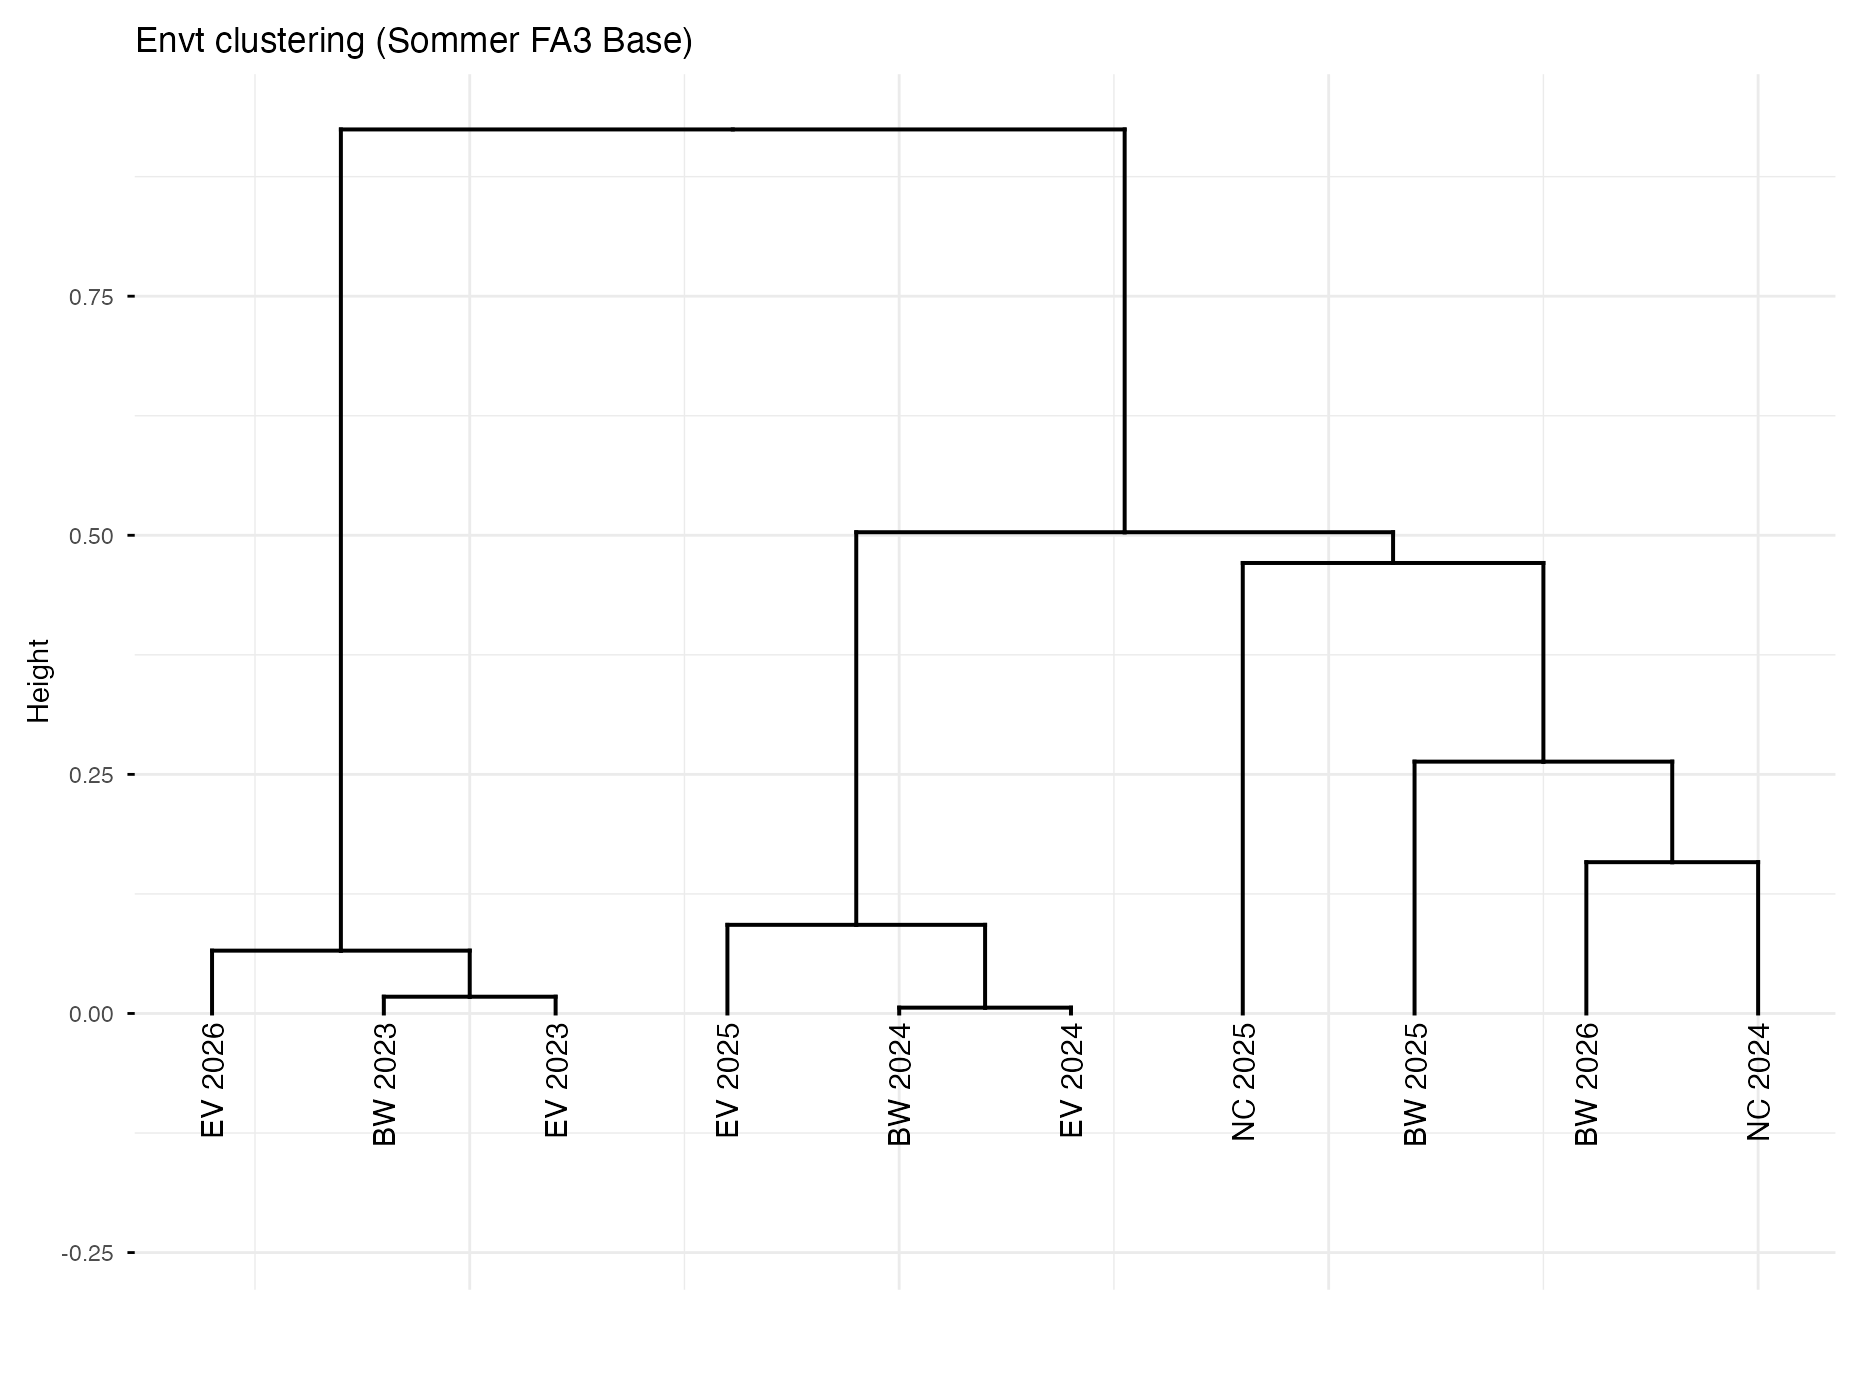

In [73]:
plot_hc(rg3_sm_min$corr, 'Sommer FA3 Base')

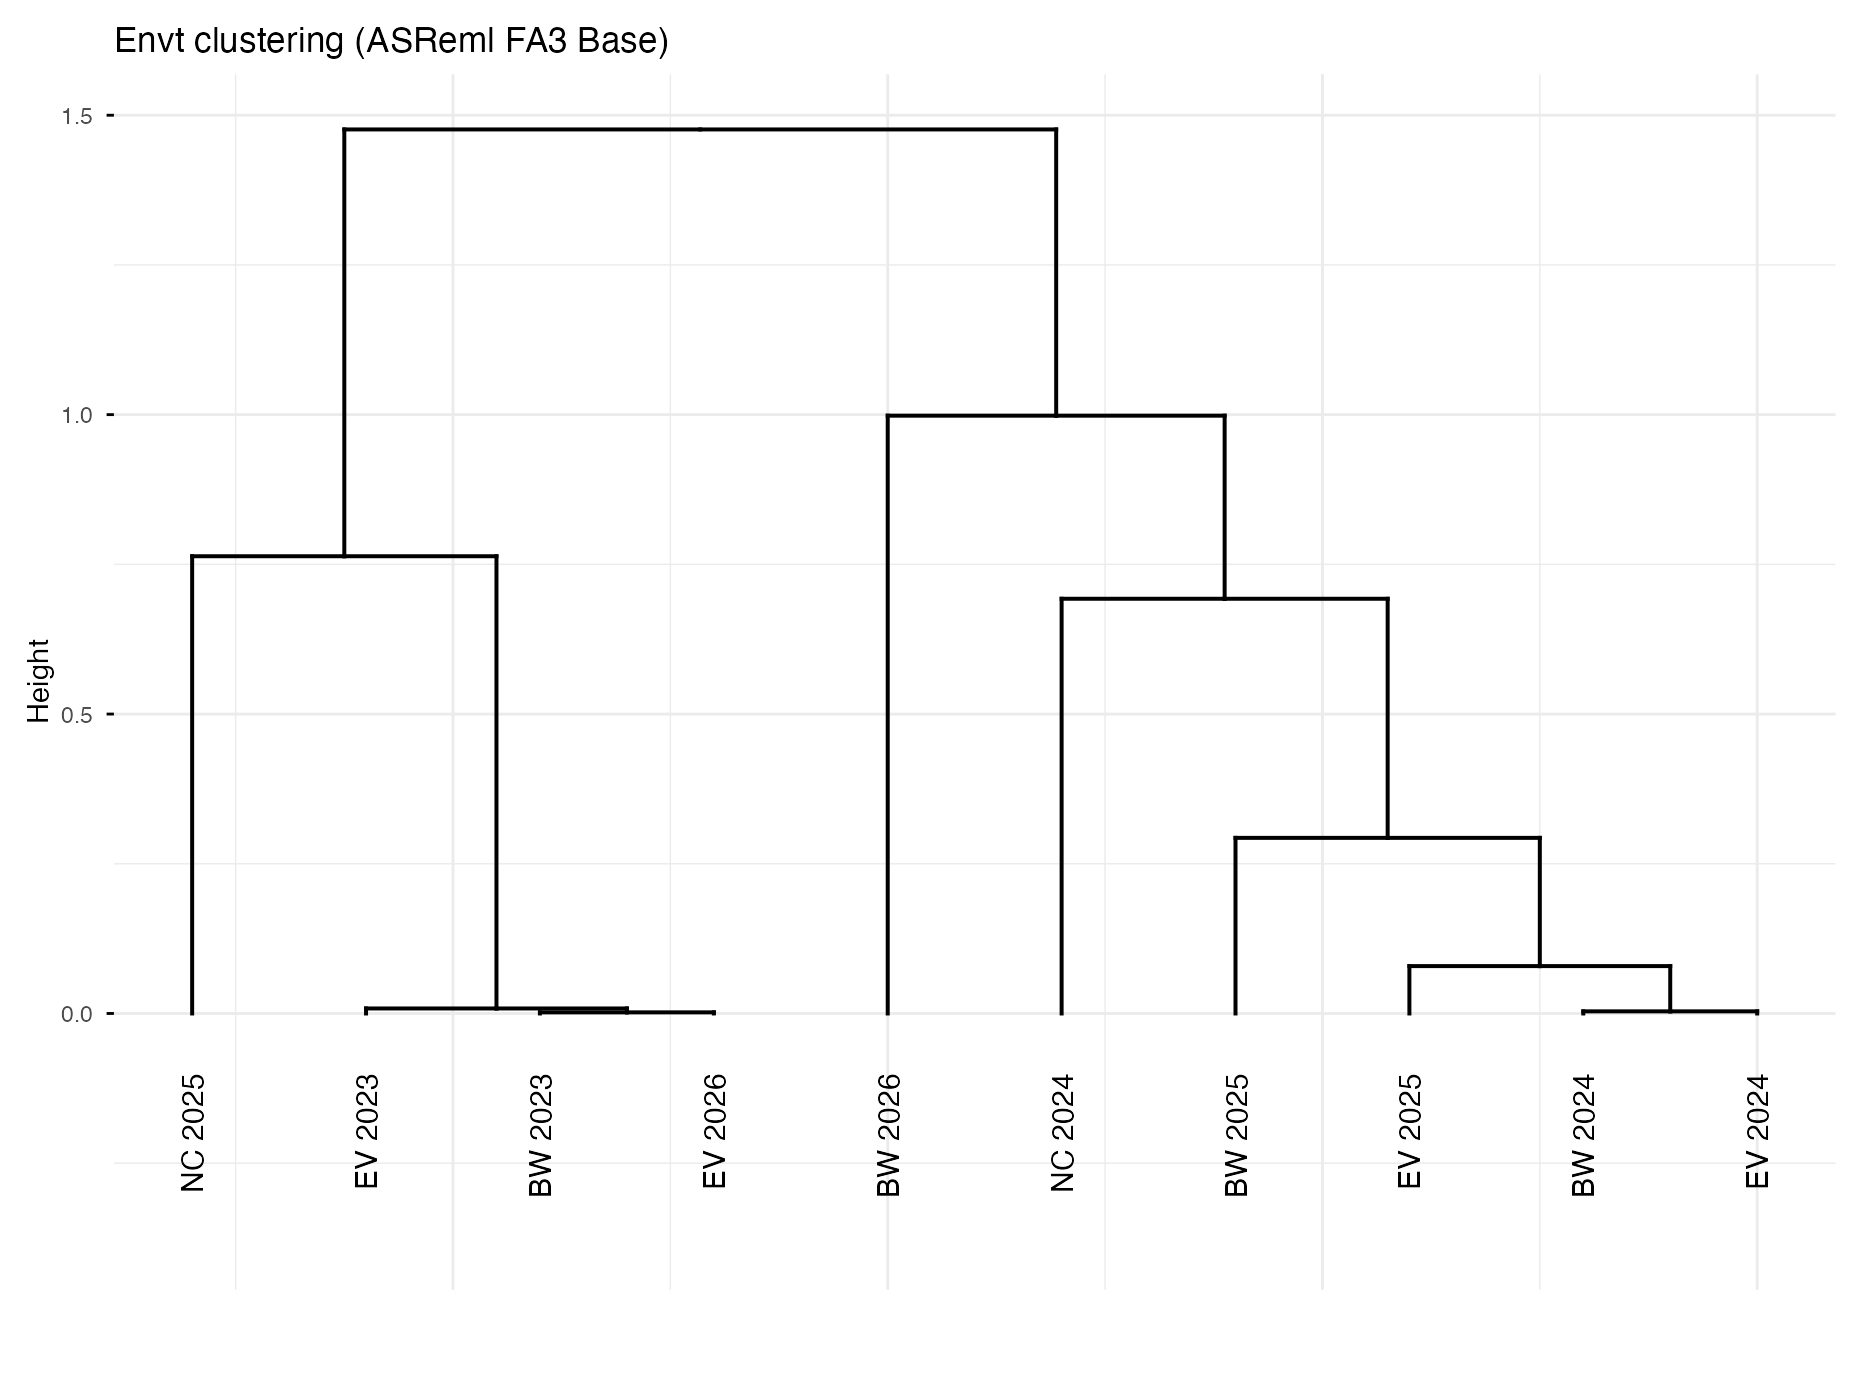

In [76]:
plot_hc(rg2_min$corr, 'ASReml FA3 Base')

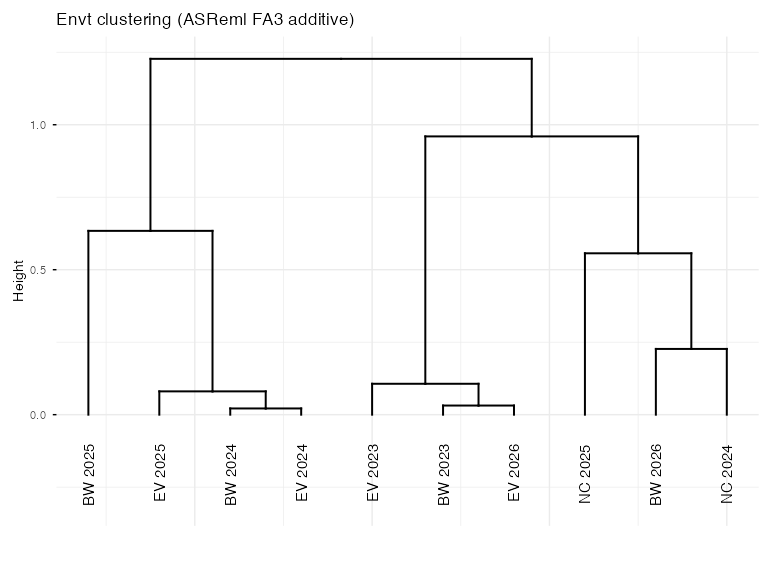

In [172]:
plot_hc(a3$additive$corr, 'ASReml FA3 additive')

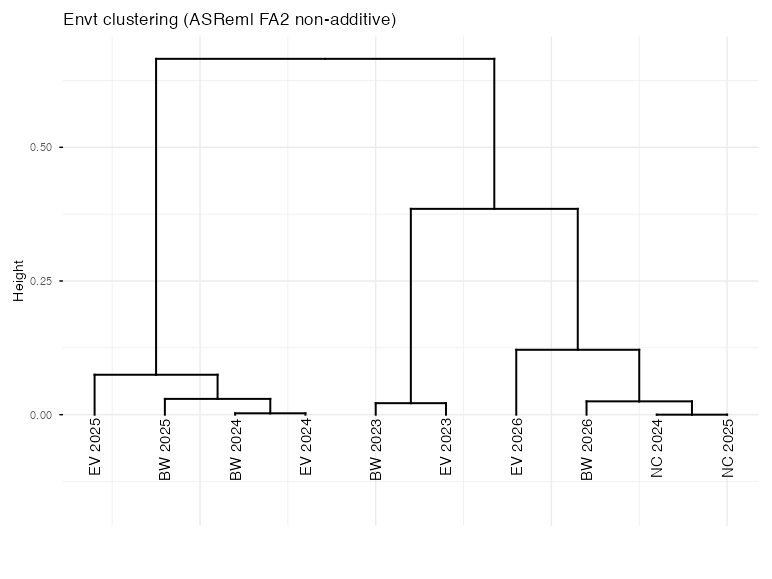

In [173]:
plot_hc(a2$nonadditive$corr, 'ASReml FA2 non-additive')

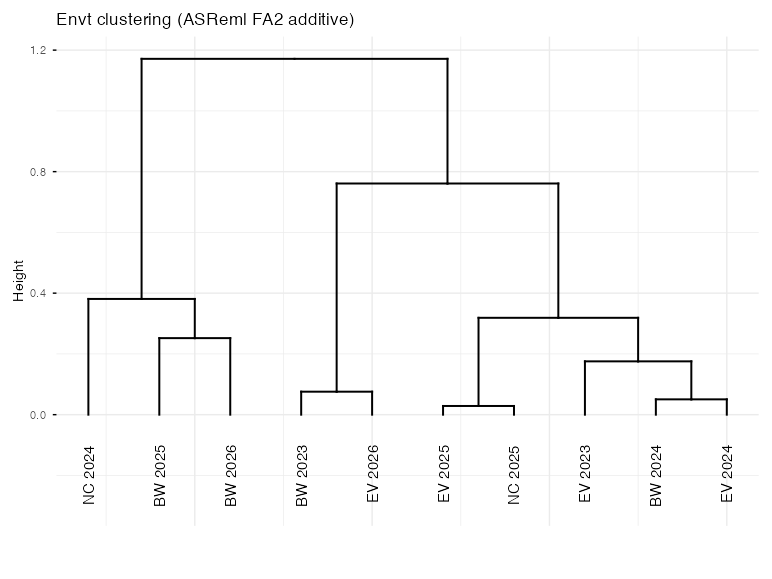

In [174]:
plot_hc(a2$additive$corr, 'ASReml FA2 additive')

In [134]:
run_lrt = function(df) {
  df %>%
    mutate(
      LRT_stat = 2 * (LogL - lag(LogL)),
      df_diff = N_params - lag(N_params),
      p_value = pchisq(LRT_stat, df = df_diff, lower.tail = FALSE),
      Signif = case_when(
        p_value < 0.001 ~ '***',
        p_value < 0.01  ~ '**',
        p_value < 0.05  ~ '*',
        TRUE            ~ 'ns'
      )
    )
}

In [204]:
mods_asr2 = list(FA2 = fit_fa2_asr, FA2_min = fit_minimal2, FA2_ke_1 = fit_fa2_dn_asr)
mods_comp_asr2 = 
    data.frame(
      Model    = names(mods_asr2),
      LogL     = sapply(mods_asr2, function(m) m$loglik),
      N_params = sapply(mods_asr2, function(m) (m$nwv)),
      AIC      = sapply(mods_asr2, function(m) summary(m)$aic),
      BIC      = sapply(mods_asr2, function(m) summary(m)$bic)
    )

In [190]:

mods_asr = list(FA3 = fit_fa3_asr, FA3_min = fit_minimal, FA3_ke_1 = fit_fa3_dn_asr)
mods_comp_asr = 
    data.frame(
      Model    = names(mods_asr),
      LogL     = sapply(mods_asr, function(m) m$loglik),
      N_params = sapply(mods_asr, function(m) (m$nwv)),
      AIC      = sapply(mods_asr, function(m) summary(m)$aic),
      BIC      = sapply(mods_asr, function(m) summary(m)$bic)
    )

In [205]:
run_lrt(mods_comp_asr2)

            Model      LogL N_params      AIC      BIC LRT_stat df_diff      p_value Signif
FA2           FA2 -188.5136       41 451.0272 627.5888       NA      NA           NA     ns
FA2_min   FA2_min -170.6370       42 411.2740 578.2918 35.75312       1 2.239726e-09    ***
FA2_ke_1 FA2_ke_1 -163.0946       61 416.1892 630.9263 15.08483      19 7.171905e-01     ns

In [191]:
run_lrt(mods_comp_asr)

            Model      LogL N_params      AIC      BIC LRT_stat df_diff      p_value Signif
FA3           FA3 -173.0293       51 430.0586 630.4799       NA      NA           NA     ns
FA3_min   FA3_min -167.3642       52 416.7284 612.3778 11.33023       1 0.0007625553    ***
FA3_ke_1 FA3_ke_1 -160.2897       71 426.5793 679.4919 14.14908      19 0.7749326094     ns

In [196]:
# asreml: ka* = whatever your existing mods_comp_asr already picked as best
# for the single-term model. This adds exactly ONE parameter (homogeneous
# non-additive genotype variance) to test whether there's any repeatable
# clone-level signal left over at all, before spending parameters on FA
# structure for it.
fit_minimal2 = fit_minimal_nonadd(prep_yield, gin)

ASReml Version 4.2 14/10/2026 08:18:45
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -287.6663           1.0    873   08:18:45  (  1 restrained)
  2     -229.0730           1.0    873   08:18:45  (  1 restrained)
  3     -202.3451           1.0    873   08:18:45  (  3 restrained)
  4     -187.3334           1.0    873   08:18:45  (  4 restrained)
  5     -181.8591           1.0    873   08:18:45  (  3 restrained)
  6     -179.5945           1.0    873   08:18:45  (  2 restrained)
  7     -177.7142           1.0    873   08:18:45  (  1 restrained)
  8     -175.8084           1.0    873   08:18:45  (  1 restrained)
  9     -174.8458           1.0    873   08:18:45  (  1 restrained)
 10     -174.2272           1.0    873   08:18:45
 11     -173.4180           1.0    873   08:18:45  (  1 restrained)
 12     -172.8942           1.0    873   08:18:45  (  1 restrained)
 13     -172.5666           1.0    873   08:18:45  (  1 restra

Warning messages:
1: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 2):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration
2: In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 2):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


In [197]:
fit_fa2_asr = fit_fa2_asreml(prep_yield, gin)

ASReml Version 4.2 14/10/2026 08:18:48
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -295.0618           1.0    873   08:18:48
  2     -237.5864           1.0    873   08:18:48  (  1 restrained)
  3     -209.4240           1.0    873   08:18:48  (  1 restrained)
  4     -196.5234           1.0    873   08:18:48  (  3 restrained)
  5     -191.9319           1.0    873   08:18:48  (  3 restrained)
  6     -190.1001           1.0    873   08:18:48  (  2 restrained)
  7     -189.2405           1.0    873   08:18:48  (  1 restrained)
  8     -189.0248           1.0    873   08:18:48
  9     -188.9146           1.0    873   08:18:48  (  1 restrained)
 10     -188.8965           1.0    873   08:18:48
 11     -188.8793           1.0    873   08:18:48
 12     -188.8568           1.0    873   08:18:48
 13     -188.8273           1.0    873   08:18:48
 14     -188.7795           1.0    873   08:18:48
 15     -188.7177           1.0   

Warning message:
In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 2):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


In [214]:
extract_nonadd_scalar_asreml <- function(fit, dta, Ainv) {
  predict(fit, classify = "Genotype", data = dta, onlyuse = ~ide(Genotype))$pvals %>%
    mutate(Genotype = as.character(Genotype)) %>%
    transmute(Genotype, g_e = predicted.value, se_e = std.error)
}

In [14]:
dta = prep_and_scale_dta(prep_yield)
Ainv = gin

In [215]:
extract_nonadd_scalar_asreml(fit_minimal, dta, Ainv)

ASReml Version 4.2 14/10/2026 09:05:51
Multi-section model using the sigma parameterization.
          LogLik        Sigma2     DF     wall
  1     -167.3634           1.0    873   09:05:51
  2     -167.3632           1.0    873   09:05:51
 3     -167.3629           1.0    873   09:05:51


Warning message:
In asreml(fixed = y_scaled ~ Env, random = ~fa(Env, k = 3):vm(Genotype,  :
  Some components changed by more than 1% on the last iteration


     Genotype        g_e      se_e
1      NC5313  0.5875069 0.0979836
2      NC5314  0.5576329 0.0971629
3      NC5271 -0.1355792 0.1009779
4       ONeal -0.5449060 0.1238391
5      NC5286  0.1597408 0.0980889
6  NewHanover  0.5035488 0.1008926
7      Legacy  0.2325061 0.1193825
8      NC5287  0.1534027 0.0988362
9      NC5283  0.0864987 0.0988117
10     NC5303  0.3234095 0.1341305
11     NC3104  0.0389218 0.1263108
12     NC5289  1.3627890 0.0981001
13    TH-1484 -0.4332138 0.3548107
14    TH-2929  0.4593209 0.1828435
15    TH-2976  0.7862000 0.1842114
16    TH-3023  0.5397657 0.1720926
17   FL12-179 -0.4943671 0.2938274
18   FL14-288 -0.7007049 0.3233615
19   FL17-141 -0.6024031 0.1733130
20   FL17-142 -0.7898104 0.1878729
21      Gumbo  0.2667557 0.1559658
22     MS1509  0.2427381 0.1506920
23     MS1691 -0.6991571 0.1977176
24     MS1987 -0.4047314 0.1553831
25     MS2162  0.9643938 0.1501848
26      MS771  0.1192602 0.1502714
27     NC5298 -0.3608133 0.1005632
28     NC5326 -0.449